## Perceptrón Multicapa (MLP) entrenado para dataset de detección visual de personajes de los Simpsons

> **Dataset nuevo: 64 personajes, una carpeta por personaje. Variante CPU (Keras 3 sobre PyTorch, sin GPU).** Sigue la misma
> estructura que el notebook del dataset anterior ([`../oldDataset/LosSimpsonsPMC.ipynb`](../oldDataset/LosSimpsonsPMC.ipynb)),
> con cinco cambios de enfoque:
>
> 1. **Partición propia.** El dataset ya no trae `train` y `test`: el notebook reparte cada personaje en
>    entrenamiento (70 %), validación (20 %) y prueba (10 %).
> 2. **Todas las imágenes, sin tope por personaje.** El desbalance (33:1) se compensa con pesos por clase
>    suavizados en lugar de descartar imágenes de los personajes frecuentes.
> 3. **Imágenes alteradas y parecidas.** Un cuarto de las imágenes de cada personaje tiene una variante con
>    un giro de 10 a 20°, un cambio de color y un filtro de textura. Además, las imágenes casi idénticas a
>    otra del mismo personaje entran con una versión filtrada de la misma forma. Las dos entran por igual en
>    entrenamiento, validación y prueba, así que el modelo se mide en las mismas condiciones en que aprende.
>    Todo lo genera una sola vez `scripts/newDataset/generar_imagenes_alteradas.py` dentro del propio dataset.
> 4. **Descriptores de color y textura** (HSV, Lab, LBP, Gabor y HOG) como entrada del MLP, comparados
>    con los píxeles crudos.
> 5. **Escenas con varios personajes.** Los fotogramas de episodio, y las imágenes casi idénticas guardadas
>    en la carpeta de otro personaje, indican quién más sale en la imagen: se usan como etiqueta secundaria
>    al entrenar, y en la prueba nombrar a cualquiera de los personajes presentes cuenta como acierto.
>
> El proceso es el mismo del notebook de GPU ([`LosSimpsons_GPU_4060M.ipynb`](LosSimpsons_GPU_4060M.ipynb)),
> con el mismo framework y el mismo bucle de entrenamiento: solo cambia el dispositivo, que aquí es
> la CPU. No usa TensorFlow.
>
> Antes de ejecutarlo hay que correr una vez el script de alteraciones; los pasos están en
> [`README.md`](README.md).

#### Integrantes:

    - VINCENT FARENDEN CERÓN
    - RODRIGO IGNACIO MARTÍNEZ BECKER
    - IVÁN MANUEL PAVÓN BARRÍA
    - DIEGO IGNACIO PEÑA Y LILLO LUHRS

#### Asignatura:

    - TÉCNICAS AVANZADAS DE MACHINE LEARNING_001D

#### Profesor:

    - FRANCISCO JAVIER JEREZ SALAZAR

#### Fecha:

    - 14-09-2026

## 0. Configuración del entorno CPU

Esta corrida usa el mismo framework que la de GPU, **Keras 3 sobre PyTorch**, y no necesita
TensorFlow: el modelo se define con Keras y se entrena con el mismo bucle sobre PyTorch que el notebook de
GPU ([`LosSimpsons_GPU_4060M.ipynb`](LosSimpsons_GPU_4060M.ipynb)). Lo único que cambia es el
dispositivo: aquí todo se calcula en la CPU, aunque el equipo tenga una GPU. Así, al comparar los tiempos de
las dos corridas, la diferencia se debe al hardware y no al framework.

Para eso, antes de importar PyTorch o Keras, la celda siguiente fija tres variables de entorno:

| Variable | Valor | Para qué |
|---|---|---|
| `KERAS_BACKEND` | `torch` | Keras usa PyTorch, como en el notebook de GPU. Sin ella, Keras intenta cargar TensorFlow |
| `KERAS_TORCH_DEVICE` | `cpu` | Keras crea los pesos y los tensores del modelo en la CPU |
| `CUDA_VISIBLE_DEVICES` | `-1` | PyTorch no ve ninguna GPU. Es una garantía más: el notebook de GPU comprobó que, con una GPU visible, Keras deja en ella los tensores internos de `BatchNormalization` aunque el modelo se cree en la CPU. El valor vacío no sirve en Windows, donde una variable vacía equivale a no definirla |

Las tres solo tienen efecto si se fijan antes del primer `import torch` o `import keras` del kernel. Si el
kernel ya los importó con otra configuración, la celda lo detecta y pide reiniciarlo. El entorno es el
mismo `.venv-gpu` del notebook de GPU.

In [73]:
import os
import platform
import sys

# Antes del primer import de torch o keras: Keras sobre PyTorch (no TensorFlow) y todo el calculo
# en la CPU. CUDA_VISIBLE_DEVICES=-1 oculta las GPU a PyTorch; un valor vacio no sirve en Windows.
ya_importados = [modulo for modulo in ("torch", "keras") if modulo in sys.modules]
os.environ["KERAS_BACKEND"] = "torch"
os.environ["KERAS_TORCH_DEVICE"] = "cpu"
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

import keras
import torch

DISPOSITIVO = "cpu"

print(f"Python : {sys.version.split()[0]}")
print(f"Keras  : {keras.__version__}   (backend: {keras.backend.backend()})")
print(f"PyTorch: {torch.__version__}")

dispositivo_keras = keras.ops.zeros((1,)).device
if keras.backend.backend() != "torch" or torch.cuda.is_available() or dispositivo_keras.type != DISPOSITIVO:
    raise RuntimeError(
        f"El kernel ya habia importado {', '.join(ya_importados) or 'torch o keras'} con otra configuracion"
        f" (backend {keras.backend.backend()}, GPU visible: {torch.cuda.is_available()}, tensores de Keras"
        f" en {dispositivo_keras}). Reinicia el kernel y ejecuta el notebook desde esta celda."
    )

print(f"\nProcesador       : {platform.processor() or platform.machine()}")
print(f"Nucleos logicos  : {os.cpu_count()}")
print(f"Hilos de PyTorch : {torch.get_num_threads()}")

# Prueba real: una multiplicacion de matrices que debe ejecutarse en la CPU
prueba = torch.randn(2048, 2048)
resultado = prueba @ prueba
assert resultado.device.type == DISPOSITIVO, "La operacion de prueba no se ejecuto en la CPU"
print(f"\nOperacion de prueba ejecutada en: {resultado.device}   |   tensores de Keras en: {dispositivo_keras}")
del prueba, resultado

print("\nEntorno CPU verificado correctamente: Keras sobre PyTorch, sin GPU visible.")

Python : 3.13.15
Keras  : 3.15.1   (backend: torch)
PyTorch: 2.14.0+cu130

Procesador       : Intel64 Family 6 Model 186 Stepping 2, GenuineIntel
Nucleos logicos  : 16
Hilos de PyTorch : 10

Operacion de prueba ejecutada en: cpu   |   tensores de Keras en: cpu

Entorno CPU verificado correctamente: Keras sobre PyTorch, sin GPU visible.


## Definición del Dataset

Nuestro conjunto de datos es una carpeta por personaje, sin una partición previa en entrenamiento y prueba: cada carpeta reúne imágenes de ese personaje desde varios puntos de vista. Se construyó a partir del dataset público de Kaggle y el equipo lo amplió con más personajes y con fotogramas propios. En algunas carpetas hay imágenes cuyo nombre de archivo corresponde a otro personaje: son fotogramas elegidos porque en ellos el protagonista es el personaje de la carpeta. Por eso **la etiqueta de cada imagen la da siempre su carpeta, nunca el nombre del archivo.**

Nosotros escogimos este dataset debido a la gran popularidad de los personajes y porque tienen una identidad gráfica extremadamente reconocible: piel amarilla, siluetas simples, colores fuertes y personajes fáciles de distinguir incluso con pocos detalles. Su diseño es consistente y memorable, lo que hace que la serie destaque inmediatamente frente a otras animaciones.

| Dato | Valor |
|---|---|
| Personajes | 64 |
| Imágenes originales | 40.123 al 16-10-2026 (unos 2,1 GB), casi todas `.jpg`, con 30 `.png` y 2 `.webp` |
| Imágenes por personaje | De 3.118 (`homer_simpson`) a 94 (`louie`) |
| Tamaño de las imágenes | De 38 × 42 a 2.700 × 3.600 píxeles; mediana 640 × 480 |

Además de las originales, el script `scripts/newDataset/generar_imagenes_alteradas.py` guarda en cada carpeta una variante alterada de un cuarto de sus imágenes, con el nombre `<original>__alterada.<ext>`, y, para cada imagen casi idéntica a otra del mismo personaje, una versión filtrada `<original>__parecida.<ext>` que el notebook usa en su lugar. El dataset no se versiona en el repositorio.

![Homero](../../images/homero.png) ![Lisa](../../images/lisa.png)

## Problema de negocio, objetivos y KPIs

### Contexto y problema de negocio

Un archivo audiovisual crece mucho mas rapido de lo que un equipo humano puede
catalogarlo. Miles de fotogramas sin etiquetar son material practicamente inservible:
no se pueden buscar, no se pueden reutilizar y no permiten medir nada. Hoy esa
catalogacion se hace a mano, imagen por imagen, y su costo crece de forma lineal con
el tamano del archivo.

**Problema de negocio.** *El archivo de imagenes crece mas rapido de lo que el equipo
puede catalogarlo manualmente, lo que impide buscar material por personaje, encarece
cada proyecto de reutilizacion de contenido y deja sin explotar el catalogo
acumulado.*

Este proyecto aborda ese problema sobre un archivo de **40.123 imagenes (unos 2,1 GB)**
de 64 personajes de Los Simpson: asignar automaticamente el personaje que aparece en
cada imagen, para que el archivo pase de ser un conjunto de ficheros sueltos a un
catalogo consultable.

| Caso de uso | Que habilita el modelo |
|---|---|
| Busqueda en el archivo | Recuperar todos los planos de un personaje para un montaje, un trailer o un recopilatorio tematico. |
| Pre-clasificacion asistida | El modelo propone y una persona valida: convierte trabajo de *etiquetar* en trabajo de *revisar*, que es mucho mas rapido. |
| Metricas de contenido | Cuantificar la presencia en pantalla de cada personaje, dato relevante para licenciamiento y merchandising. |
| Control de uso de marca | Detectar personajes con derechos dentro de material aportado por terceros. |

### Objetivos del proyecto

**Objetivo general.** Implementar y evaluar un Perceptron Multicapa capaz de asignar
a cada imagen RGB uno de los 64 personajes del catalogo, mediante un flujo
reproducible cuyo desempeno se mida frente a referencias triviales y de forma
sensible al desbalance de clases.

**Objetivos especificos.**

1. Indexar las imagenes disponibles y asociar cada ruta con el personaje de su carpeta.
2. Repartir todas las imagenes de cada personaje en entrenamiento (70 %), validacion
   (20 %) y prueba (10 %) de forma estratificada y con semilla fija; cada variante
   alterada acompana a su imagen original, de modo que los tres conjuntos tienen las
   mismas condiciones.
3. Preparar los datos para el MLP: conversion a RGB, redimensionado, descriptores de
   color y textura, normalizacion y codificacion one-hot de las etiquetas.
4. Entrenar un modelo base y compararlo con variantes controladas de representacion de
   entrada, arquitectura e hiperparametros, cambiando un factor a la vez.
5. Seleccionar la configuracion final por F1 macro de validacion y medirla una sola
   vez sobre el conjunto de prueba.
6. Auditar el resultado: metricas por clase, matriz de confusion, aciertos, errores y
   limitaciones del MLP aplicado a imagenes.

### KPIs del proyecto

Los umbrales se fijan **antes** de evaluar el modelo y traducen el escenario de uso a
cantidades medibles sobre los datos. El cumplimiento se verifica al final de la
seccion de evaluacion, con las cifras obtenidas en la prueba final.

**Criterio de acierto.** Una prediccion es correcta si nombra al personaje de la
carpeta o a otro personaje que tambien aparece en la imagen, segun la escena del
episodio o una imagen casi identica guardada en su carpeta (ver "Escenas con varios
personajes"). Con ese criterio se miden todas las metricas de prueba y los KPIs; la
accuracy estricta, que solo acepta el personaje de la carpeta, se informa como
referencia. La validacion, que decide la parada temprana y el modelo final, usa
siempre la etiqueta de la carpeta.

| KPI | Que mide en el negocio | Metrica tecnica | Umbral |
|---|---|---|---|
| Cobertura de asistencia | Con que frecuencia el catalogador encuentra la respuesta correcta entre las tres sugerencias del sistema. | Top-3 accuracy en test | >= 0,70 |
| Equidad entre personajes | Que el catalogo sirva para todos los personajes y no solo para los mas frecuentes. | F1 macro en test | >= 0,45 |
| Automatizacion sin revision | Proporcion de imagenes que el sistema resuelve sin intervencion humana. | Accuracy en test | >= 0,50 |
| Ventaja sobre el criterio trivial | Que el sistema aporte informacion real frente a etiquetar todo como el personaje mas comun. | Accuracy / baseline mayoritaria | >= 4x |
| Costo de catalogacion | Capacidad de procesar el archivo completo en un tiempo razonable. | Imagenes por segundo (descriptores + inferencia) | >= 1.000 img/s |

La eleccion de **top-3 accuracy** y **F1 macro** como KPIs principales no es casual:
el sistema esta pensado como asistente de un catalogador, no como reemplazo, y un
catalogo que solo reconoce a los personajes mayoritarios no resuelve el problema de
busqueda. Por eso la seleccion de modelo se hace por F1 macro y no por accuracy.

> Las imagenes se trabajan a 128x128. El modelo base no recibe los 49.152
> pixeles de cada imagen, sino unos 2.460 descriptores de color y textura calculados a
> esa resolucion.

## Definición del problema de clasificación

El problema que abordamos es de **clasificación de imágenes multiclase de etiqueta única**: dada una imagen RGB que contiene a un personaje de Los Simpsons, el modelo debe asignarle **exactamente una** de las 64 clases posibles (una por personaje). No es detección de objetos ni clasificación multi-etiqueta: no se predicen cajas delimitadoras ni varios personajes por imagen.

**Alcance verificable del trabajo.** El escenario descrito en la sección anterior es el marco de uso declarado del proyecto, no un encargo de un cliente real: no hay contrato, operación comercial ni cifras económicas que permitan calcular un retorno monetario. Por eso los KPIs se expresan en cantidades medibles sobre los datos disponibles y no en unidades de dinero.

**Variante definida: 64 personajes, una carpeta por personaje.** El dataset ya no trae una partición en `train` y `test`: el notebook recorre cada carpeta y reparte todas sus imágenes originales en entrenamiento (70 %), validación (20 %) y prueba (10 %), de forma estratificada y con semilla fija. Los tres conjuntos conservan la distribución real del dataset y tienen las mismas condiciones: las originales que les tocan, la versión filtrada de las que eran casi idénticas a otra del mismo personaje (ver «Imágenes parecidas») y la variante alterada de un cuarto de ellas, que siempre va al mismo conjunto que su original. No hay tope por personaje: el entrenamiento usa todas las originales que le corresponden.

**Criterios de éxito observables.** El desempeño se interpreta frente a tres referencias que calcula el notebook: accuracy aleatoria (1/64 ≈ 1,6 %), accuracy de predecir siempre la clase mayoritaria (en torno al 7,8 %, la proporción de `homer_simpson` en el dataset) y F1 macro, que da el mismo peso a los 64 personajes. También se reportan precision, recall, F1 por clase, matriz de confusión y top-3 accuracy. No se fijan umbrales nuevos a posteriori: los de los KPIs se declaran antes de entrenar, en la sección «Problema de negocio, objetivos y KPIs», y su cumplimiento se verifica al cerrar la sección de evaluación. Lo mismo vale para el criterio de acierto: en la prueba, una predicción es correcta si nombra al personaje de la carpeta o a otro que aparece en la misma imagen.

**Entrada y salida**

- **Entrada (X):** imagen RGB de tamaño variable (entre 38 × 42 y 2.700 × 3.600 px; mediana 640 × 480). Se redimensiona a 128 × 128 y se describe de dos formas: como vector de píxeles normalizados (49.152 valores) o como vector de descriptores de color y textura (unos 2.460 valores). El modelo base usa los descriptores; los píxeles se mantienen como experimento de comparación.
- **Salida (y):** vector de 64 probabilidades (activación *softmax*); la clase predicha es la de mayor probabilidad.
- **Función de pérdida:** entropía cruzada categórica (*categorical crossentropy*).

**Conjuntos de datos**

| Conjunto | Contenido | Distribución |
|---|---|---|
| Entrenamiento | 70 % de las originales de cada personaje, más sus variantes alteradas | Real |
| Validación | 20 % de las originales de cada personaje, más sus variantes alteradas | Real |
| Prueba | 10 % de las originales de cada personaje, más sus variantes alteradas | Real |

Las cifras exactas de cada conjunto las imprime la sección de pre-procesamiento.

**Desbalance de clases**

En el dataset completo las clases están muy desbalanceadas: desde 3.118 imágenes de `homer_simpson` hasta 94 de `louie` (razón aproximada de 33:1). Esa razón se mantiene en entrenamiento, porque se usan todas las imágenes, y se compensa con pesos por clase **suavizados** (la raíz cuadrada de los balanceados): los personajes pequeños pesan más, sin que el modelo deje de reconocer a los frecuentes. Validación y prueba se miden sobre la distribución real, donde la *accuracy* favorece a los personajes frecuentes y el F1 macro a los escasos.

**Baselines de referencia**

- Clasificador aleatorio: 1/64 ≈ **1,6 %** de accuracy.
- Clasificador de clase mayoritaria (predecir siempre `homer_simpson`): en torno al **7,8 %** en prueba, la proporción de ese personaje en el dataset.

Cualquier modelo útil debe superar claramente estos valores.

**Métricas de evaluación**

Además de la *accuracy* global se reportarán **precision, recall y F1-score por clase**, el **F1 macro** (que pondera igual a todas las clases, mostrando el efecto del desbalance) y la **matriz de confusión**, útil para detectar confusiones sistemáticas entre personajes visualmente parecidos (por ejemplo, Bart y Milhouse, o Lisa y Maggie).

**Dificultades esperadas**

Los personajes aparecen en múltiples poses, con distintos encuadres, escalas y fondos, y con variaciones de color debidas a las diferentes temporadas. A esto se suman personajes parcialmente ocluidos o acompañados por otros en la misma escena. Con 64 personajes aparecen además secundarios muy parecidos entre sí —Patty y Selma, o los distintos miembros de la familia Flanders— y varios con menos de 150 imágenes en total.

**Supuestos**

Se asume que cada imagen tiene un único personaje **principal**: el que da nombre a su carpeta. Puede haber otros en el encuadre; la sección «Escenas con varios personajes» los estima a partir de los fotogramas de episodio y de las imágenes casi idénticas guardadas en la carpeta de otro personaje, los usa como etiqueta secundaria y, en la prueba, acepta como acierto nombrar a cualquiera de ellos. Se comprobó que el dataset no contiene archivos duplicados byte a byte, de modo que una misma imagen no puede caer a la vez en entrenamiento y prueba. Sí contiene imágenes casi idénticas —fotogramas seguidos de una escena, recortes repetidos—: el script las detecta y, de cada grupo, todas menos una entran con una versión filtrada, para que el modelo no acierte en prueba solo porque vio casi la misma imagen al entrenar. Cada variante alterada entra al mismo conjunto que su original: nunca hay una imagen en un conjunto y su variante en otro.

## Pre-Procesamiento de los datos

En esta sección se prepara el dataset para que pueda ser consumido por una red densa: se indexan las carpetas de los personajes, se reparte cada uno en entrenamiento, validación y prueba, se cargan y redimensionan las imágenes elegidas, se normalizan y aplanan los píxeles, se calculan los descriptores de color y textura y se codifican las etiquetas.

### Definición del conjunto de datos a utilizar

In [74]:
import os
from datetime import datetime
from pathlib import Path

# Marca de inicio de la corrida. La seccion de rendimiento del final del notebook
# la usa para calcular la hora de termino y la duracion total.
INICIO_CORRIDA = datetime.now()
print(f"Inicio de la corrida: {INICIO_CORRIDA:%Y-%m-%d %H:%M:%S}\n")

# Una carpeta por personaje, sin particion previa. La ruta se puede fijar con la
# variable SIMPSONS_DATASET (la que usa Docker); si no existe, se busca en el escritorio.
DATASET_BASE = Path(
    os.environ.get("SIMPSONS_DATASET", Path.home() / "Desktop" / "simpsons_dataset" / "simpsons_dataset")
)

SEMILLA = 42
CONJUNTOS = ("train", "val", "test")
# Proporciones sobre TODAS las imagenes originales de cada personaje, sin tope:
# los tres conjuntos conservan la distribucion real del dataset.
PROPORCIONES = {"train": 0.70, "val": 0.20, "test": 0.10}
# Por debajo de este numero de originales un personaje no se puede repartir en tres
# conjuntos estratificados con un minimo de ejemplos en cada uno.
MINIMO_POR_PERSONAJE = 30

if not DATASET_BASE.is_dir():
    raise FileNotFoundError(f"No existe el dataset: {DATASET_BASE}")
if (DATASET_BASE / "train").is_dir() or (DATASET_BASE / "test").is_dir():
    raise ValueError(
        f"{DATASET_BASE} tiene la estructura antigua (train/ y test/). Este notebook trabaja "
        "con una carpeta por personaje; el del dataset anterior esta en notebooks/oldDataset/."
    )

print(f"Dataset       : {DATASET_BASE}")
print(f"Particion     : {', '.join(f'{nombre} {proporcion:.0%}' for nombre, proporcion in PROPORCIONES.items())}")
print("Tope de train : ninguno, se usan todas las originales")
print(
    "\nEl conjunto de test se reserva intacto: no se usa para ajustar pesos"
    " ni para elegir hiperparámetros, solo para la comprobación final."
)

Inicio de la corrida: 2026-10-16 18:28:09

Dataset       : C:\Users\LaptopWin\Desktop\simpsons_dataset\simpsons_dataset
Particion     : train 70%, val 20%, test 10%
Tope de train : ninguno, se usan todas las originales

El conjunto de test se reserva intacto: no se usa para ajustar pesos ni para elegir hiperparámetros, solo para la comprobación final.


### Carga de imágenes y etiquetas

In [75]:
import pandas as pd

EXTENSIONES_VALIDAS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
# Sufijos con los que el script de alteraciones marca las imagenes que genera: una
# alterada es una variante extra que va al mismo conjunto que su original; una parecida
# reemplaza a su original
MARCA_ALTERADA = "__alterada"
MARCA_PARECIDA = "__parecida"


def construir_indice(directorio):
    """Recorre un directorio con una subcarpeta por personaje y devuelve un DataFrame con
    la ruta de cada imagen, su personaje y, para las alteradas, la original de la que
    provienen. Si el script reemplazó una original casi idéntica a otra por su versión
    __parecida, la fila de esa original apunta a la versión parecida. La etiqueta sale
    siempre de la carpeta, nunca del nombre del archivo."""
    registros = []

    for carpeta_clase in sorted(directorio.iterdir()):
        if not carpeta_clase.is_dir() or carpeta_clase.name.startswith("."):
            continue

        archivos = sorted(carpeta_clase.iterdir())
        nombres = {ruta.name for ruta in archivos}
        for ruta in archivos:
            # Las parecidas no son imágenes nuevas: entran abajo, en el lugar de su original
            if ruta.suffix.lower() not in EXTENSIONES_VALIDAS or ruta.stem.endswith(MARCA_PARECIDA):
                continue
            alterada = ruta.stem.endswith(MARCA_ALTERADA)
            # Para una original, su origen es ella misma
            origen = ruta.stem.removesuffix(MARCA_ALTERADA) + ruta.suffix if alterada else ruta.name
            reemplazo = f"{ruta.stem}{MARCA_PARECIDA}{ruta.suffix}"
            parecida = not alterada and reemplazo in nombres
            registros.append(
                {
                    "ruta": ruta.with_name(reemplazo) if parecida else ruta,
                    "personaje": carpeta_clase.name,
                    "alterada": alterada,
                    "parecida": parecida,
                    "origen": origen,
                }
            )

    if not registros:
        raise FileNotFoundError(f"No se encontraron imagenes en: {directorio}")

    return pd.DataFrame(registros)


# Índice de todo el dataset: originales y alteradas
indice_completo = construir_indice(DATASET_BASE)

resumen = (
    indice_completo.groupby("personaje")
    .agg(
        originales=("alterada", lambda serie: int((~serie).sum())),
        alteradas=("alterada", "sum"),
        parecidas=("parecida", "sum"),
    )
    .astype(int)
    .sort_values("originales", ascending=False)
    .reset_index()
)
resumen["porcentaje"] = (resumen["originales"] / resumen["originales"].sum() * 100).round(2)

n_originales = int(resumen["originales"].sum())
n_alteradas = int(resumen["alteradas"].sum())
n_parecidas = int(resumen["parecidas"].sum())
print(f"Dataset: {n_originales} imagenes originales y {n_alteradas} alteradas en {len(resumen)} personajes")
print(f"De las originales, {n_parecidas} eran casi identicas a otra y entran con su version filtrada (__parecida)")
if n_alteradas == 0:
    print(
        "AVISO: no hay imagenes alteradas. Ejecuta antes "
        "scripts/newDataset/generar_imagenes_alteradas.py; el notebook funciona sin ellas, "
        "pero el entrenamiento no tendra variantes de color y textura."
    )

display(resumen)

Dataset: 40123 imagenes originales y 10043 alteradas en 64 personajes
De las originales, 9041 eran casi identicas a otra y entran con su version filtrada (__parecida)


,personaje,originales,alteradas,parecidas,porcentaje
0,homer_simpson,3118,780,466,7.77
1,bart_simpson,1941,485,316,4.84
2,ned_flanders,1784,446,460,4.45
3,lisa_simpson,1771,443,318,4.41
4,marge_simpson,1766,442,351,4.40
...,...,...,...,...,...
59,judge_snyder,118,30,17,0.29
60,rod_flanders,112,28,26,0.28
61,jasper_beardly,111,28,16,0.28
62,disco_stu,107,27,13,0.27


### Partición y selección por personaje

Con el dataset ya indexado, cada personaje se reparte **antes de cargar ninguna imagen**. Así solo se cargan las imágenes que realmente se van a usar, y la partición no puede depender de nada calculado sobre los píxeles.

1. **Solo se reparten las originales.** Las de cada personaje se dividen en entrenamiento (70 %), validación (20 %) y test (10 %) con `train_test_split` estratificado y semilla fija. Los tres conjuntos conservan así la distribución real del dataset.
2. **Sin tope por personaje.** Se usan todas las originales: ninguna queda fuera del reparto. El desbalance (33:1) no se corrige descartando imágenes de los personajes grandes, sino con pesos por clase (ver «Tratamiento del desbalance de clases»).
3. **Las alteradas siguen a su original.** Cada variante alterada entra al mismo conjunto que su imagen original: entrenamiento, validación o test. Así los tres conjuntos tienen las mismas condiciones —originales, parecidas y alteradas en la misma proporción— y el modelo se mide sobre el mismo tipo de imágenes con que aprende. Nunca hay una imagen en un conjunto y su variante en otro: el modelo no puede acertar en test porque vio casi la misma imagen al entrenar.
4. **Personajes demasiado pequeños.** Un personaje con menos de `MINIMO_POR_PERSONAJE` originales no se puede repartir en tres conjuntos con un mínimo de ejemplos en cada uno; se lista y se excluye.
5. **Las parecidas ocupan el lugar de su original.** Si el script reemplazó una original casi idéntica a otra por su versión filtrada (`__parecida`), esa versión se reparte como cualquier original y puede caer en cualquier conjunto; la original no se usa.

In [76]:
import numpy as np
from sklearn.model_selection import train_test_split

originales = indice_completo[~indice_completo["alterada"]].reset_index(drop=True)
alteradas = indice_completo[indice_completo["alterada"]].reset_index(drop=True)

# Punto 4, que se aplica antes que los demás: personajes con muy pocas originales
# para repartirlos en tres conjuntos
conteo_originales = originales["personaje"].value_counts()
excluidos = sorted(conteo_originales[conteo_originales < MINIMO_POR_PERSONAJE].index)
if excluidos:
    print(f"Personajes excluidos (menos de {MINIMO_POR_PERSONAJE} originales): {', '.join(excluidos)}")
    originales = originales[~originales["personaje"].isin(excluidos)].reset_index(drop=True)
    alteradas = alteradas[~alteradas["personaje"].isin(excluidos)].reset_index(drop=True)

# 1. Reparto estratificado de las originales: primero se separa el 70 % de train, y el
#    30 % restante se divide entre validacion (20 %) y test (10 %).
fraccion_resto = 1 - PROPORCIONES["train"]
indices_train, indices_resto = train_test_split(
    originales.index,
    test_size=fraccion_resto,
    stratify=originales["personaje"],
    random_state=SEMILLA,
)
indices_val, indices_test = train_test_split(
    indices_resto,
    test_size=PROPORCIONES["test"] / fraccion_resto,
    stratify=originales.loc[indices_resto, "personaje"],
    random_state=SEMILLA,
)
originales["conjunto"] = ""
originales.loc[indices_train, "conjunto"] = "train"
originales.loc[indices_val, "conjunto"] = "val"
originales.loc[indices_test, "conjunto"] = "test"

# 2. Sin tope por personaje: todas las originales de train se usan para entrenar.
# 3. Cada alterada va al mismo conjunto que su original, así train, validación y test tienen las
#    mismas condiciones. Solo se descarta una alterada cuya original ya no está en el dataset.
conjunto_de_original = dict(zip(zip(originales["personaje"], originales["origen"]), originales["conjunto"]))
alteradas["conjunto"] = [
    conjunto_de_original.get((personaje, origen), "descartada")
    for personaje, origen in zip(alteradas["personaje"], alteradas["origen"])
]

datos = (
    pd.concat([originales, alteradas], ignore_index=True)
    .query("conjunto != 'descartada'")
    .sort_values(["personaje", "origen", "alterada"])
    .reset_index(drop=True)
)

# Lista ordenada de clases y su mapeo a índices enteros
clases = sorted(datos["personaje"].unique())
clase_a_indice = {clase: indice for indice, clase in enumerate(clases)}
indice_a_clase = {indice: clase for clase, indice in clase_a_indice.items()}

# Etiqueta numérica de cada imagen: la de su carpeta
datos["etiqueta"] = datos["personaje"].map(clase_a_indice)


def contar(filtro):
    return datos[filtro].groupby("personaje").size()


reparto = (
    pd.DataFrame(
        {
            "disponibles": originales.groupby("personaje").size(),
            "train_originales": contar((datos["conjunto"] == "train") & ~datos["alterada"]),
            "train_alteradas": contar((datos["conjunto"] == "train") & datos["alterada"]),
            "val": contar(datos["conjunto"] == "val"),
            "val_alteradas": contar((datos["conjunto"] == "val") & datos["alterada"]),
            "test": contar(datos["conjunto"] == "test"),
            "test_alteradas": contar((datos["conjunto"] == "test") & datos["alterada"]),
        }
    )
    .fillna(0)
    .astype(int)
)
reparto["train_total"] = reparto["train_originales"] + reparto["train_alteradas"]
reparto = reparto.sort_values("disponibles", ascending=False)
display(reparto)

totales = datos["conjunto"].value_counts()
alteradas_por_conjunto = datos[datos["alterada"]].groupby("conjunto").size()
print(
    "   |   ".join(
        f"{nombre}: {totales[nombre]} imagenes ({int(alteradas_por_conjunto.get(nombre, 0))} alteradas)"
        for nombre in CONJUNTOS
    )
    + f"   |   personajes: {len(clases)}"
)
print(
    f"Desbalance en train: {reparto['train_total'].max() / reparto['train_total'].min():.1f}:1"
    f"   (en el dataset completo: {conteo_originales.max() / conteo_originales.min():.1f}:1)"
)
parecidas_por_conjunto = datos[datos["parecida"]].groupby("conjunto").size()
print(
    "Imagenes parecidas (version filtrada en lugar de la original): "
    + "   |   ".join(f"{nombre} {int(parecidas_por_conjunto.get(nombre, 0))}" for nombre in CONJUNTOS)
)
n_por_conjunto = originales["conjunto"].value_counts()
print(
    "Reparto de las originales: "
    + "   |   ".join(f"{nombre} {n_por_conjunto[nombre] / len(originales):.1%}" for nombre in CONJUNTOS)
)

,disponibles,train_originales,train_alteradas,val,val_alteradas,test,test_alteradas,train_total
personaje,,,,,,,,
homer_simpson,3118,2182,536,783,159,397,85,2718
bart_simpson,1941,1359,332,488,100,247,53,1691
ned_flanders,1784,1249,305,449,92,227,49,1554
lisa_simpson,1771,1240,306,439,85,229,52,1546
marge_simpson,1766,1236,307,441,88,224,47,1543
...,...,...,...,...,...,...,...,...
judge_snyder,118,83,21,30,7,14,2,104
rod_flanders,112,78,18,30,7,14,3,96
jasper_beardly,111,78,21,27,5,13,2,99


train: 35023 imagenes (6937 alteradas)   |   val: 10080 imagenes (2056 alteradas)   |   test: 5063 imagenes (1050 alteradas)   |   personajes: 64
Desbalance en train: 32.0:1   (en el dataset completo: 33.2:1)
Imagenes parecidas (version filtrada en lugar de la original): train 6325   |   val 1804   |   test 912
Reparto de las originales: train 70.0%   |   val 20.0%   |   test 10.0%


### Redimensionado a un tamaño fijo



In [77]:
from PIL import Image
import numpy as np

# Dimensiones originales de cada imagen del conjunto (sin cargar los píxeles)
dimensiones = []
for ruta in datos["ruta"]:
    with Image.open(ruta) as img:
        dimensiones.append(img.size)  # (ancho, alto)

datos["ancho"] = [ancho for ancho, _ in dimensiones]
datos["alto"] = [alto for _, alto in dimensiones]

resumen_dimensiones = datos[["ancho", "alto"]].describe().T
resumen_dimensiones["mediana"] = datos[["ancho", "alto"]].median()
resumen_dimensiones = resumen_dimensiones[
    ["count", "min", "25%", "mediana", "75%", "max", "mean", "std"]
].round(1)

display(resumen_dimensiones)

,count,min,25%,mediana,75%,max,mean,std
ancho,50166.0,28.0,320.0,640.0,960.0,2700.0,680.4,344.8
alto,50166.0,42.0,416.0,480.0,720.0,3600.0,547.0,169.7


**Elección y justificación del tamaño objetivo**

Las imágenes del conjunto tienen dimensiones variables, mientras que una red densa exige un vector de
entrada de longitud fija. Por lo tanto, el primer paso del pre-procesamiento consiste en llevar todas
las imágenes a una misma resolución.

Cuando la red recibe los píxeles, esa resolución condiciona directamente el tamaño del modelo. Al
aplanar la imagen, la capa de entrada queda formada por `alto x ancho x 3` valores (tres canales RGB por
píxel) y cada uno de ellos se conecta con todas las neuronas de la primera capa oculta. En consecuencia,
el número de parámetros de esa capa crece de forma cuadrática respecto del lado de la imagen:

| Resolución | Dimensión del vector de píxeles | Parámetros de la primera capa densa (512 neuronas) |
|---|---|---|
| 32 x 32 | 3.072 | ≈ 1,6 millones |
| 64 x 64 | 12.288 | ≈ 6,3 millones |
| **128 x 128 (esta corrida)** | **49.152** | **≈ 25,2 millones** |

Este notebook fija **128 x 128 píxeles** en la celda siguiente. Esa resolución determina el
tamaño de la entrada solo cuando el MLP recibe los píxeles, que aquí es el experimento R1. El modelo base
recibe en cambio descriptores de color y textura, cuyo número no depende de la resolución —unos 2.460
valores tanto a 64 x 64 como a 128 x 128—: ahí la resolución solo fija el detalle con que se calculan los
histogramas y los filtros.

In [ ]:
import time

from joblib import Parallel, delayed

ALTO_OBJETIVO, ANCHO_OBJETIVO = 128, 128
TAMANO_OBJETIVO = (ANCHO_OBJETIVO, ALTO_OBJETIVO)  # PIL usa (ancho, alto)


def cargar_y_redimensionar(ruta, tamano=TAMANO_OBJETIVO):
    """Abre una imagen, la convierte a RGB y la redimensiona al tamaño fijo."""
    with Image.open(ruta) as img:
        img = img.convert("RGB").resize(tamano, Image.Resampling.BILINEAR)
        return np.asarray(img, dtype=np.uint8)


# Matriz de imágenes redimensionadas: (n_imagenes, alto, ancho, 3). Decodificar y
# redimensionar libera el GIL, así que varios hilos cargan en paralelo.
inicio_carga = time.perf_counter()
imagenes = np.stack(
    Parallel(n_jobs=-1, prefer="threads")(
        delayed(cargar_y_redimensionar)(ruta) for ruta in datos["ruta"]
    )
)
segundos_carga = time.perf_counter() - inicio_carga
etiquetas = datos["etiqueta"].to_numpy()

print(f"imagenes: {imagenes.shape}  dtype={imagenes.dtype}  ({imagenes.nbytes / 1024 ** 3:.2f} GB)")
print(f"etiquetas: {etiquetas.shape}")
print(f"Carga y redimensionado: {segundos_carga:.1f} s ({len(imagenes) / segundos_carga:,.0f} imagenes/s)")

imagenes: (50166, 32, 32, 3)  dtype=uint8  (0.14 GB)
etiquetas: (50166,)
Carga y redimensionado: 122.6 s (409 imagenes/s)


**Comprobación del redimensionado**

In [79]:
comprobaciones = pd.DataFrame(
    [
        ("Número de imágenes", imagenes.shape[0], len(datos), imagenes.shape[0] == len(datos)),
        ("Alto", imagenes.shape[1], ALTO_OBJETIVO, imagenes.shape[1] == ALTO_OBJETIVO),
        ("Ancho", imagenes.shape[2], ANCHO_OBJETIVO, imagenes.shape[2] == ANCHO_OBJETIVO),
        ("Canales", imagenes.shape[3], 3, imagenes.shape[3] == 3),
        ("Tipo de dato", str(imagenes.dtype), "uint8", imagenes.dtype == np.uint8),
        ("Valor mínimo", int(imagenes.min()), ">= 0", imagenes.min() >= 0),
        ("Valor máximo", int(imagenes.max()), "<= 255", imagenes.max() <= 255),
        ("Etiquetas alineadas", len(etiquetas), imagenes.shape[0], len(etiquetas) == imagenes.shape[0]),
    ],
    columns=["comprobacion", "obtenido", "esperado", "ok"],
)

memoria_mb = imagenes.nbytes / 1024**2
print(f"Memoria ocupada por la matriz de imagenes: {memoria_mb:.1f} MB")
print(f"Neuronas en la capa de entrada tras aplanar: {ALTO_OBJETIVO * ANCHO_OBJETIVO * 3}")

display(comprobaciones)


Memoria ocupada por la matriz de imagenes: 147.0 MB
Neuronas en la capa de entrada tras aplanar: 3072


,comprobacion,obtenido,esperado,ok
0,Número de imágenes,50166,50166,True
1,Alto,32,32,True
2,Ancho,32,32,True
3,Canales,3,3,True
4,Tipo de dato,uint8,uint8,True
5,Valor mínimo,0,>= 0,True
6,Valor máximo,255,<= 255,True
7,Etiquetas alineadas,50166,50166,True


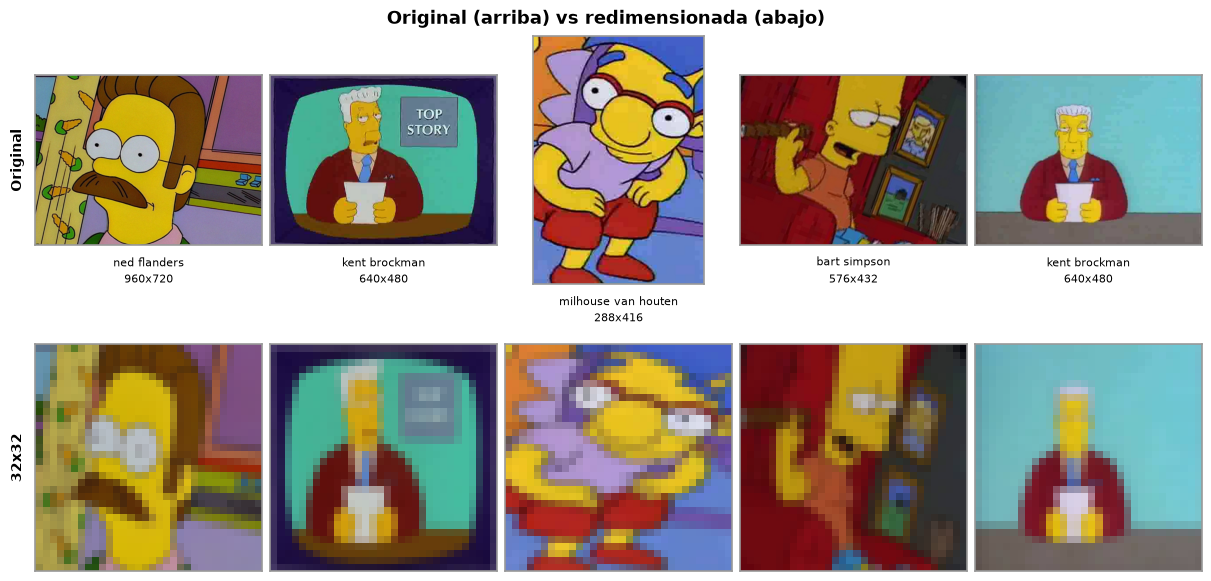

In [80]:
import matplotlib.pyplot as plt

# Comparación visual original vs redimensionada para una muestra aleatoria
generador = np.random.default_rng(42)
muestra = generador.choice(len(datos), size=5, replace=False)

figura, ejes = plt.subplots(
    2,
    len(muestra),
    figsize=(2.4 * len(muestra), 5.8),
    layout="constrained",
)
for columna, indice in enumerate(muestra):
    fila = datos.iloc[indice]
    with Image.open(fila["ruta"]) as img:
        original = img.convert("RGB")

    personaje = fila["personaje"].replace("_", " ")
    ejes[0, columna].imshow(original)
    ejes[1, columna].imshow(imagenes[indice])

    # El texto va debajo de la imagen para que no invada la fila de arriba
    ejes[0, columna].set_xlabel(
        f"{personaje}\n{original.size[0]}x{original.size[1]}",
        fontsize=8,
        labelpad=6,
        linespacing=1.5,
    )

    for eje in (ejes[0, columna], ejes[1, columna]):
        eje.set_xticks([])
        eje.set_yticks([])
        for lado in eje.spines.values():
            lado.set_edgecolor("#999999")
            lado.set_linewidth(1.2)

# Etiqueta de fila a la izquierda, en vez de repetir el mismo título en cada columna
ejes[0, 0].set_ylabel("Original", fontsize=10, fontweight="bold", labelpad=8)
ejes[1, 0].set_ylabel(
    f"{ANCHO_OBJETIVO}x{ALTO_OBJETIVO}", fontsize=10, fontweight="bold", labelpad=8
)

figura.suptitle("Original (arriba) vs redimensionada (abajo)", fontsize=13, fontweight="bold")
plt.show()


### Normalización de los píxeles



**Por qué normalizar**
Al dividir por 255 todas las características de entrada quedan en la misma escala acotada
[0, 1]. Esto evita que unos píxeles pesen más que otros por su magnitud, mejora el
condicionamiento del descenso del gradiente y permite que la inicialización estándar de
los pesos funcione como se espera.

**Dónde se aplica**
El escalado **no se materializa aquí**, sino dentro del modelo, en la capa `Rescaling`
(sección del modelo base), y solo cuando la entrada son los píxeles: en este notebook, el
experimento R1. El motivo es de memoria: convertir todas las imágenes a `float32` multiplica
por cuatro el espacio ocupado —la celda siguiente imprime las cifras de esta corrida—, y la
matriz de píxeles se copia además al separar train, validación y test.

Manteniendo los píxeles en `uint8`, cada copia ocupa la cuarta parte y el modelo escala cada
lote al recibirlo, a coste despreciable. Es el mismo esquema del notebook de GPU, así que los
modelos guardados por los dos reciben exactamente la misma entrada.

Los descriptores de color y textura tienen escalas propias (frecuencias de un histograma,
respuestas de un filtro) y se **estandarizan** de otra forma: se les resta la media y se
dividen por la desviación de cada descriptor en entrenamiento. Se explica en su sección.

Esta celda comprueba sobre una muestra que el escalado de los píxeles es exactamente el esperado.

In [81]:
# Escalado de [0, 255] a [0, 1]: el rango con el que opera la red.
VALOR_MAXIMO_PIXEL = 255.0

# El escalado real lo aplica la capa Rescaling del modelo, sobre cada lote.
# Aqui solo se verifica sobre una muestra que la operacion es la esperada.
TAMANO_MUESTRA_NORMALIZACION = 512
tamano_muestra = min(TAMANO_MUESTRA_NORMALIZACION, len(imagenes))
imagenes_norm = imagenes[:tamano_muestra].astype(np.float32) / VALOR_MAXIMO_PIXEL

print(f"imagenes      : {imagenes.shape}  dtype={imagenes.dtype}"
      f"  ->  {imagenes.nbytes / 1024 ** 3:.2f} GB")
print(f"imagenes_norm : {imagenes_norm.shape}  dtype={imagenes_norm.dtype}"
      f"  (muestra de comprobacion)")
print(f"rango: [{imagenes_norm.min():.3f}, {imagenes_norm.max():.3f}]")
print(f"media: {imagenes_norm.mean():.4f}  desviacion: {imagenes_norm.std():.4f}")
print(
    f"\nEl conjunto completo en float32 ocuparia {imagenes.nbytes * 4 / 1024 ** 3:.2f} GB;"
    f" en uint8 ocupa {imagenes.nbytes / 1024 ** 3:.2f} GB."
)

imagenes      : (50166, 32, 32, 3)  dtype=uint8  ->  0.14 GB
imagenes_norm : (512, 32, 32, 3)  dtype=float32  (muestra de comprobacion)
rango: [0.000, 1.000]
media: 0.4392  desviacion: 0.2248

El conjunto completo en float32 ocuparia 0.57 GB; en uint8 ocupa 0.14 GB.


**Comprobación de la normalización**

In [82]:
indice_prueba = 0

comprobaciones_norm = pd.DataFrame(
    [
        (
            "Forma conservada (sobre la muestra)",
            str(imagenes_norm.shape),
            str(imagenes[:tamano_muestra].shape),
            imagenes_norm.shape == imagenes[:tamano_muestra].shape,
        ),
        (
            "Tipo de dato",
            str(imagenes_norm.dtype),
            "float32",
            imagenes_norm.dtype == np.float32,
        ),
        (
            "Valor mínimo",
            round(float(imagenes_norm.min()), 4),
            ">= 0.0",
            imagenes_norm.min() >= 0.0,
        ),
        (
            "Valor máximo",
            round(float(imagenes_norm.max()), 4),
            "<= 1.0",
            imagenes_norm.max() <= 1.0,
        ),
        (
            "Sin NaN ni infinitos",
            bool(np.isfinite(imagenes_norm).all()),
            True,
            bool(np.isfinite(imagenes_norm).all()),
        ),
        (
            "Escalado exacto (x255 == original)",
            "imagenes_norm * 255",
            "imagenes",
            np.allclose(
                imagenes_norm[indice_prueba] * VALOR_MAXIMO_PIXEL,
                imagenes[indice_prueba].astype(np.float32),
            ),
        ),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)

display(comprobaciones_norm)

if not comprobaciones_norm["Correcto"].all():
    raise ValueError("La normalización no cumple alguna de las comprobaciones.")

print("Normalización verificada correctamente.")

,Comprobacion,Obtenido,Esperado,Correcto
0,Forma conservada (sobre la muestra),"(512, 32, 32, 3)","(512, 32, 32, 3)",True
1,Tipo de dato,float32,float32,True
2,Valor mínimo,0.0,>= 0.0,True
3,Valor máximo,1.0,<= 1.0,True
4,Sin NaN ni infinitos,True,True,True
5,Escalado exacto (x255 == original),imagenes_norm * 255,imagenes,True


Normalización verificada correctamente.


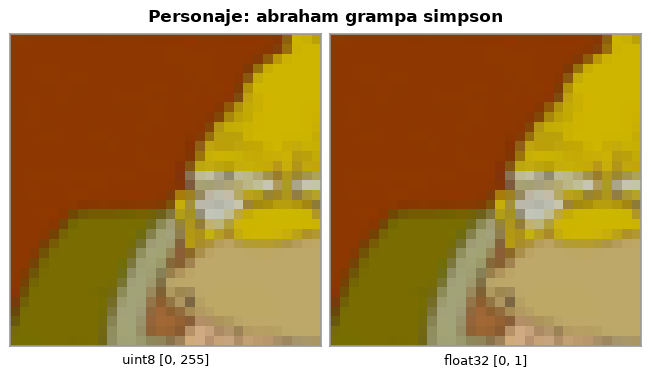

In [83]:
# La imagen normalizada debe verse idéntica a la original: solo cambia la escala numérica
figura, ejes = plt.subplots(1, 2, figsize=(6.4, 3.6), layout="constrained")

paneles = (
    (imagenes[indice_prueba], "uint8 [0, 255]"),
    (imagenes_norm[indice_prueba], "float32 [0, 1]"),
)
for eje, (imagen, etiqueta) in zip(ejes, paneles):
    eje.imshow(imagen)
    eje.set_xticks([])
    eje.set_yticks([])
    for lado in eje.spines.values():
        lado.set_edgecolor("#999999")
        lado.set_linewidth(1.2)
    eje.set_xlabel(etiqueta, fontsize=9, labelpad=6)

personaje = datos.iloc[indice_prueba]["personaje"].replace("_", " ")
figura.suptitle(f"Personaje: {personaje}", fontsize=12, fontweight="bold")
plt.show()


### Vectorización (aplanado) de las imágenes

**Por qué aplanar y qué implica**

Una capa densa (`Dense`) recibe un vector: cada neurona se conecta con **todas** las entradas mediante
un peso. No tiene forma de aprovechar que dos píxeles estén uno al lado del otro, porque en su interior
todas las entradas son intercambiables. Por eso la imagen de `alto x ancho x 3` debe convertirse en un
único vector de longitud fija `alto * ancho * 3`.

Con la configuración ejecutada en "Redimensionado a un tamaño fijo" esto da **128 x 128 x 3 = 49 152** valores por imagen, que es la
dimensión de la capa de entrada del MLP cuando recibe píxeles (experimento R1); el modelo base
recibe en cambio los descriptores de la sección siguiente.

El aplanado es el paso donde se **pierde la estructura espacial**: el modelo ya no sabe que el píxel
`(0, 0)` y el `(0, 1)` eran vecinos. Esta es precisamente la limitación que se discute en "Limitaciones del MLP en imágenes y propuestas de mejora"
y el motivo por el que una CNN, que sí preserva esa vecindad, resulta más adecuada para imágenes.



**Por qué `X` tiene dos dimensiones e `y` solo una**

`X` es una **matriz**: una fila por imagen y una columna por característica de entrada. Su forma
`(N, 49152)` se lee como "N ejemplos, cada uno descrito por 49 152 números", donde N es el
número de imágenes elegidas en la partición. La primera
dimensión siempre cuenta ejemplos y la segunda las características de cada uno; es el formato que Keras
espera para alimentar una capa densa, que procesa las filas por lotes (batches).

`y` es un **vector**: su forma `(N,)` significa "N etiquetas", una por fila de `X`. Para
describir a qué personaje corresponde una imagen basta con un único número (el índice de la clase), así
que no hace falta una segunda dimensión. Lo único imprescindible es que `X.shape[0] == y.shape[0]` y que
el orden coincida: la etiqueta `y[i]` corresponde a la imagen `X[i]`.

Esa asimetría es solo del estado actual de los datos, no una regla: en "Codificación de las etiquetas"
se aplicará one-hot encoding y `y` pasará a ser también una matriz `(N, 64)`, con una columna por
personaje, que es lo que exige la pérdida `categorical_crossentropy`.

El orden del aplanado es `C` (por filas: fila a fila, y dentro de cada fila los tres canales RGB de cada
píxel). Lo importante no es el orden concreto, sino que sea **el mismo para todas las imágenes** y para
los conjuntos de train y test, cosa que `reshape` garantiza al aplicarse sobre el arreglo completo.


In [84]:
# Cada imagen (alto, ancho, 3) pasa a ser un vector de alto * ancho * 3 valores
DIMENSION_PIXELES = ALTO_OBJETIVO * ANCHO_OBJETIVO * 3

# Los vectores quedan en uint8: el escalado a [0, 1] lo hace la capa Rescaling
# del modelo sobre cada lote, y la matriz ocupa la cuarta parte que en float32.
X = imagenes.reshape(imagenes.shape[0], -1)
y = etiquetas

print(f"X: {X.shape}  dtype={X.dtype}")
print(f"y: {y.shape}")
print(f"Dimension del vector de pixeles: {DIMENSION_PIXELES}")
print(f"rango de X: [{int(X.min())}, {int(X.max())}]  (uint8; se escala dentro del modelo)")

X: (50166, 3072)  dtype=uint8
y: (50166,)
Dimension del vector de pixeles: 3072
rango de X: [0, 255]  (uint8; se escala dentro del modelo)


**Comprobación del aplanado**

In [85]:
# El aplanado debe ser reversible: recuperar la imagen original desde su vector
imagen_reconstruida = X[indice_prueba].reshape(ALTO_OBJETIVO, ANCHO_OBJETIVO, 3)

comprobaciones_aplanado = pd.DataFrame(
    [
        (
            "Número de imágenes",
            X.shape[0],
            imagenes.shape[0],
            X.shape[0] == imagenes.shape[0],
        ),
        (
            "Longitud del vector",
            X.shape[1],
            DIMENSION_PIXELES,
            X.shape[1] == DIMENSION_PIXELES,
        ),
        ("Número de dimensiones", X.ndim, 2, X.ndim == 2),
        ("Tipo de dato", str(X.dtype), "uint8", X.dtype == np.uint8),
        (
            "Rango conservado [0, 255]",
            f"[{int(X.min())}, {int(X.max())}]",
            "[0, 255]",
            bool(X.min() >= 0 and X.max() <= 255),
        ),
        (
            "Aplanado reversible",
            "X[i].reshape(alto, ancho, 3)",
            "imagenes[i]",
            np.array_equal(imagen_reconstruida, imagenes[indice_prueba]),
        ),
        ("Etiquetas alineadas", len(y), X.shape[0], len(y) == X.shape[0]),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)

display(comprobaciones_aplanado)

if not comprobaciones_aplanado["Correcto"].all():
    raise ValueError("El aplanado no cumple alguna de las comprobaciones.")

print("Aplanado verificado correctamente.")

,Comprobacion,Obtenido,Esperado,Correcto
0,Número de imágenes,50166,50166,True
1,Longitud del vector,3072,3072,True
2,Número de dimensiones,2,2,True
3,Tipo de dato,uint8,uint8,True
4,"Rango conservado [0, 255]","[0, 255]","[0, 255]",True
5,Aplanado reversible,"X[i].reshape(alto, ancho, 3)",imagenes[i],True
6,Etiquetas alineadas,50166,50166,True


Aplanado verificado correctamente.


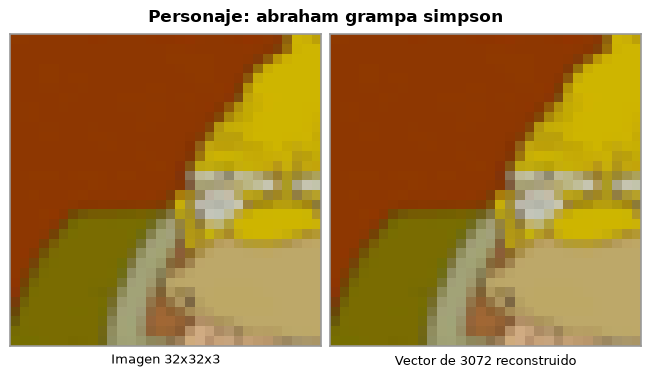

In [86]:
# Al reconstruir el vector se recupera exactamente la misma imagen
figura, ejes = plt.subplots(1, 2, figsize=(6.4, 3.6), layout="constrained")

paneles = (
    (imagenes[indice_prueba], f"Imagen {ALTO_OBJETIVO}x{ANCHO_OBJETIVO}x3"),
    (imagen_reconstruida, f"Vector de {DIMENSION_PIXELES} reconstruido"),
)
for eje, (imagen, etiqueta) in zip(ejes, paneles):
    eje.imshow(imagen)
    eje.set_xticks([])
    eje.set_yticks([])
    for lado in eje.spines.values():
        lado.set_edgecolor("#999999")
        lado.set_linewidth(1.2)
    eje.set_xlabel(etiqueta, fontsize=9, labelpad=6)

personaje = datos.iloc[indice_prueba]["personaje"].replace("_", " ")
figura.suptitle(f"Personaje: {personaje}", fontsize=12, fontweight="bold")
plt.show()

### Descriptores de color y textura

Un MLP sobre píxeles aplanados no sabe qué píxel estaba junto a cuál, y cada peso de su primera capa
queda atado a una posición fija del encuadre. Los descriptores atacan ese problema desde la entrada: en
lugar de 49.152 valores de color en posiciones fijas, cada imagen se resume en unos 2.460 números
que describen **qué colores y qué texturas aparecen**, y en qué zona aproximada de la imagen.

| Bloque | Qué mide | Cómo se calcula | Valores |
|---|---|---|---|
| **Color HSV** | Tono, saturación y brillo dominantes: la piel amarilla, el pelo azul de Marge | Histogramas de H (18 intervalos), S (8) y V (8) sobre la imagen completa y sobre una rejilla 2 × 2 | 170 |
| **Color Lab** | El color en un espacio perceptual, donde las distancias se parecen a las que percibe el ojo | Histogramas de L (8), a* (16) y b* (16) en las mismas cinco zonas | 200 |
| **Textura LBP** | Microtexturas: bordes finos, zonas lisas, rayas (pelo, barba, ropa) | *Local Binary Patterns* uniformes con P=8, R=1 en una rejilla 4 × 4 y con P=16, R=2 en una rejilla 2 × 2 | 232 |
| **Textura Gabor** | Patrones periódicos con una orientación y una escala concretas | Banco de 12 filtros (4 orientaciones × 3 frecuencias); media y desviación de cada respuesta en la rejilla 2 × 2 | 96 |
| **Bordes HOG** | Forma y silueta: hacia dónde apuntan los bordes en cada zona | *Histogram of Oriented Gradients* con 9 orientaciones en una rejilla de 8 × 8 celdas | 1.764 |

Con ellos se construyen cuatro **representaciones** que la experimentación compara entre sí: `pixeles`
(el vector de la sección anterior), `color` (HSV + Lab), `textura` (LBP + Gabor + HOG) y `color_textura`
(todo junto), que es la que usa el modelo base.

**Por qué pueden ayudar a un MLP.** Un histograma no cambia si el personaje se desplaza dentro de su
zona, así que buena parte de la sensibilidad al encuadre desaparece. Además, con la misma primera capa de
512 neuronas, la entrada es unas 20 veces más pequeña que con píxeles, y la capa también. El precio es que
los filtros se eligen a mano: la red ya no aprende sus propias características, solo combina las que se
le dan.

**Estandarización.** Cada bloque tiene su propia escala: frecuencias entre 0 y 1, respuestas de filtro,
magnitudes de gradiente. Antes de entrar a la red, cada descriptor se centra y se escala con la media y
la desviación **del conjunto de entrenamiento**. Esa operación vive dentro del modelo, en una capa
`Normalization`, como el escalado de los píxeles.

In [87]:
from scipy.signal import fftconvolve
from skimage.color import rgb2gray, rgb2hsv, rgb2lab
from skimage.feature import hog, local_binary_pattern
from skimage.filters import gabor_kernel

# Color: intervalos de cada histograma y rejillas (1 = imagen completa, 2 = rejilla 2 x 2)
INTERVALOS_HSV = (18, 8, 8)
INTERVALOS_LAB = (8, 16, 16)
RANGOS_HSV = ((0, 1), (0, 1), (0, 1))
RANGOS_LAB = ((0, 100), (-128, 127), (-128, 127))
REJILLAS_COLOR = (1, 2)
# Textura: (puntos vecinos P, radio R, lado de la rejilla) de cada LBP
CONFIGURACION_LBP = ((8, 1, 4), (16, 2, 2))
# Banco de Gabor: 4 orientaciones x 3 frecuencias (ciclos por píxel)
ORIENTACIONES_GABOR = np.arange(4) * np.pi / 4
FRECUENCIAS_GABOR = (0.1, 0.2, 0.3)
NUCLEOS_GABOR = [
    np.real(gabor_kernel(frecuencia, theta=orientacion))
    for frecuencia in FRECUENCIAS_GABOR
    for orientacion in ORIENTACIONES_GABOR
]
# HOG: celdas de lado/8 píxeles, así la rejilla es de 8 x 8 celdas a cualquier resolución
ORIENTACIONES_HOG = 9
CELDAS_HOG = 8


def regiones(alto, ancho, lado):
    """Divide la imagen en una rejilla lado x lado y devuelve cada zona como un par de slices."""
    filas = np.linspace(0, alto, lado + 1, dtype=int)
    columnas = np.linspace(0, ancho, lado + 1, dtype=int)
    return [
        (slice(filas[i], filas[i + 1]), slice(columnas[j], columnas[j + 1]))
        for i in range(lado)
        for j in range(lado)
    ]


def frecuencias(codigos, intervalos):
    """Histograma normalizado de una zona cuyos valores ya son enteros entre 0 e intervalos - 1.
    np.bincount es mucho más rápido que np.histogram y aquí se llama decenas de veces por imagen."""
    return np.bincount(codigos.ravel(), minlength=intervalos) / codigos.size


def cuantizar(canal, intervalos, rango):
    """Intervalo (0 .. intervalos - 1) al que pertenece cada valor del canal dentro del rango."""
    minimo, maximo = rango
    indices = ((canal - minimo) * (intervalos / (maximo - minimo))).astype(np.int64)
    return np.clip(indices, 0, intervalos - 1)


def histogramas_color(canales, intervalos, rangos):
    """Histograma normalizado de cada canal en cada zona de cada rejilla."""
    alto, ancho = canales.shape[:2]
    cuantizados = [
        cuantizar(canales[..., indice], n, rango)
        for indice, (n, rango) in enumerate(zip(intervalos, rangos))
    ]
    partes = []
    for lado in REJILLAS_COLOR:
        for zona in regiones(alto, ancho, lado):
            for codigos, n in zip(cuantizados, intervalos):
                partes.append(frecuencias(codigos[zona], n))
    return np.concatenate(partes)


def descriptor_lbp(gris_uint8):
    """Histograma de códigos LBP uniformes en cada zona: el método "uniform" da P + 2 códigos."""
    partes = []
    for puntos, radio, lado in CONFIGURACION_LBP:
        codigos = local_binary_pattern(gris_uint8, puntos, radio, method="uniform").astype(np.int64)
        for zona in regiones(*gris_uint8.shape, lado):
            partes.append(frecuencias(codigos[zona], puntos + 2))
    return np.concatenate(partes)


def descriptor_gabor(gris):
    """Media y desviación de la respuesta de cada filtro de Gabor en cada zona de la rejilla 2 x 2."""
    zonas = regiones(*gris.shape, 2)
    partes = []
    for nucleo in NUCLEOS_GABOR:
        respuesta = np.abs(fftconvolve(gris, nucleo, mode="same"))
        for zona in zonas:
            partes.extend((respuesta[zona].mean(), respuesta[zona].std()))
    return np.asarray(partes)


def descriptor_hog(gris):
    alto, ancho = gris.shape
    return hog(
        gris,
        orientations=ORIENTACIONES_HOG,
        pixels_per_cell=(alto // CELDAS_HOG, ancho // CELDAS_HOG),
        cells_per_block=(2, 2),
        feature_vector=True,
    )


def extraer_caracteristicas(imagen):
    """Descriptores de color y textura de una imagen RGB uint8 de forma (alto, ancho, 3)."""
    gris = rgb2gray(imagen)
    gris_uint8 = np.round(gris * 255).astype(np.uint8)
    return np.concatenate(
        (
            histogramas_color(rgb2hsv(imagen), INTERVALOS_HSV, RANGOS_HSV),
            histogramas_color(rgb2lab(imagen), INTERVALOS_LAB, RANGOS_LAB),
            descriptor_lbp(gris_uint8),
            descriptor_gabor(gris),
            descriptor_hog(gris),
        )
    ).astype(np.float32)


# Posición de cada bloque dentro del vector: sirve para armar las representaciones y
# para medir después cuánto aporta cada bloque al modelo
zonas_color = sum(lado ** 2 for lado in REJILLAS_COLOR)
TAMANOS_BLOQUES = {
    "color_hsv": sum(INTERVALOS_HSV) * zonas_color,
    "color_lab": sum(INTERVALOS_LAB) * zonas_color,
    "textura_lbp": sum((puntos + 2) * lado ** 2 for puntos, _, lado in CONFIGURACION_LBP),
    "textura_gabor": len(NUCLEOS_GABOR) * 2 * 4,
    "bordes_hog": (CELDAS_HOG - 1) ** 2 * 2 * 2 * ORIENTACIONES_HOG,
}
BLOQUES = {}
inicio_bloque = 0
for nombre_bloque, tamano_bloque in TAMANOS_BLOQUES.items():
    BLOQUES[nombre_bloque] = slice(inicio_bloque, inicio_bloque + tamano_bloque)
    inicio_bloque += tamano_bloque

# Qué bloques forma cada representación de descriptores, en el orden de sus columnas
BLOQUES_POR_REPRESENTACION = {
    "color": ["color_hsv", "color_lab"],
    "textura": ["textura_lbp", "textura_gabor", "bordes_hog"],
    "color_textura": list(BLOQUES),
}
COLUMNAS_COLOR = np.r_[BLOQUES["color_hsv"], BLOQUES["color_lab"]]
COLUMNAS_TEXTURA = np.r_[BLOQUES["textura_lbp"], BLOQUES["textura_gabor"], BLOQUES["bordes_hog"]]


def columnas_de(representacion):
    """Columnas del vector completo de descriptores que usa cada representación."""
    return {"color": COLUMNAS_COLOR, "textura": COLUMNAS_TEXTURA}.get(representacion, slice(None))


def extraer_representacion(imagen, representacion="color_textura"):
    """Solo los bloques que usa una representación, en el mismo orden de columnas que
    F[:, columnas_de(representacion)]. Con "color_textura" equivale a extraer_caracteristicas;
    con "color" se ahorra la textura y los bordes, que son la parte más cara del cálculo."""
    bloques = BLOQUES_POR_REPRESENTACION[representacion]
    partes = []
    if "color_hsv" in bloques:
        partes.append(histogramas_color(rgb2hsv(imagen), INTERVALOS_HSV, RANGOS_HSV))
    if "color_lab" in bloques:
        partes.append(histogramas_color(rgb2lab(imagen), INTERVALOS_LAB, RANGOS_LAB))
    if any(bloque in bloques for bloque in ("textura_lbp", "textura_gabor", "bordes_hog")):
        gris = rgb2gray(imagen)
        if "textura_lbp" in bloques:
            partes.append(descriptor_lbp(np.round(gris * 255).astype(np.uint8)))
        if "textura_gabor" in bloques:
            partes.append(descriptor_gabor(gris))
        if "bordes_hog" in bloques:
            partes.append(descriptor_hog(gris))
    return np.concatenate(partes).astype(np.float32)


display(pd.DataFrame({"bloque": list(TAMANOS_BLOQUES), "valores": list(TAMANOS_BLOQUES.values())}))
print(f"Descriptores por imagen: {sum(TAMANOS_BLOQUES.values())}")

,bloque,valores
0,color_hsv,170
1,color_lab,200
2,textura_lbp,232
3,textura_gabor,96
4,bordes_hog,1764


Descriptores por imagen: 2462


In [88]:
def extraer_lote(lote, representacion="color_textura"):
    return np.stack([extraer_representacion(imagen, representacion) for imagen in lote])


# Cálculo en paralelo por lotes: cada proceso recibe un bloque de imágenes y no una a
# una, para que el costo de enviar los datos entre procesos no supere al del cálculo.
TAMANO_LOTE_DESCRIPTORES = 256
inicio_descriptores = time.perf_counter()
F = np.concatenate(
    Parallel(n_jobs=-1)(
        delayed(extraer_lote)(imagenes[inicio:inicio + TAMANO_LOTE_DESCRIPTORES])
        for inicio in range(0, len(imagenes), TAMANO_LOTE_DESCRIPTORES)
    )
)
segundos_descriptores = time.perf_counter() - inicio_descriptores

REPRESENTACIONES = {
    "pixeles": X,
    **{nombre: F[:, columnas_de(nombre)] for nombre in ("color", "textura", "color_textura")},
}
DIMENSIONES = {nombre: matriz.shape[1] for nombre, matriz in REPRESENTACIONES.items()}
REPRESENTACION_BASE = "color_textura"
DIMENSION_ENTRADA = DIMENSIONES[REPRESENTACION_BASE]

print(f"F: {F.shape}  dtype={F.dtype}  ({F.nbytes / 1024 ** 2:.0f} MB)")
print(
    f"Descriptores calculados en {segundos_descriptores:.1f} s"
    f" ({len(imagenes) / segundos_descriptores:,.0f} imagenes/s)"
)
display(
    pd.DataFrame(
        {"representacion": list(DIMENSIONES), "valores_por_imagen": list(DIMENSIONES.values())}
    )
)
print(f"Representacion del modelo base: {REPRESENTACION_BASE} ({DIMENSION_ENTRADA} valores)")

F: (50166, 2462)  dtype=float32  (471 MB)
Descriptores calculados en 30.7 s (1,635 imagenes/s)


,representacion,valores_por_imagen
0,pixeles,3072
1,color,370
2,textura,2092
3,color_textura,2462


Representacion del modelo base: color_textura (2462 valores)


**Comprobación de los descriptores**

In [89]:
# Los descriptores calculados en paralelo deben coincidir con los de una llamada directa
repeticion = extraer_caracteristicas(imagenes[indice_prueba])
suma_hsv = F[:, BLOQUES["color_hsv"]].sum(axis=1)
zonas_por_canal = len(INTERVALOS_HSV) * zonas_color

comprobaciones_descriptores = pd.DataFrame(
    [
        ("Una fila por imagen", F.shape[0], len(imagenes), F.shape[0] == len(imagenes)),
        (
            "Bloques completos",
            F.shape[1],
            sum(TAMANOS_BLOQUES.values()),
            F.shape[1] == sum(TAMANOS_BLOQUES.values()),
        ),
        ("Tipo de dato", str(F.dtype), "float32", F.dtype == np.float32),
        ("Sin NaN ni infinitos", bool(np.isfinite(F).all()), True, bool(np.isfinite(F).all())),
        (
            "Histogramas HSV normalizados",
            round(float(suma_hsv.mean()), 4),
            f"{zonas_por_canal} (cada histograma suma 1)",
            bool(np.allclose(suma_hsv, zonas_por_canal, atol=1e-3)),
        ),
        (
            "Determinista (misma imagen, mismo vector)",
            "extraer de nuevo",
            "F[i]",
            bool(np.array_equal(repeticion, F[indice_prueba])),
        ),
        (
            "Representaciones alineadas con las etiquetas",
            len(REPRESENTACIONES[REPRESENTACION_BASE]),
            len(y),
            len(REPRESENTACIONES[REPRESENTACION_BASE]) == len(y),
        ),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)

display(comprobaciones_descriptores)

if not comprobaciones_descriptores["Correcto"].all():
    raise ValueError("Los descriptores no cumplen alguna de las comprobaciones.")

print("Descriptores verificados correctamente.")

,Comprobacion,Obtenido,Esperado,Correcto
0,Una fila por imagen,50166,50166,True
1,Bloques completos,2462,2462,True
2,Tipo de dato,float32,float32,True
3,Sin NaN ni infinitos,True,True,True
4,Histogramas HSV normalizados,15.0,15 (cada histograma suma 1),True
5,"Determinista (misma imagen, mismo vector)",extraer de nuevo,F[i],True
6,Representaciones alineadas con las etiquetas,50166,50166,True


Descriptores verificados correctamente.


**Qué mide cada descriptor**

La figura siguiente descompone una imagen de entrenamiento en lo que miden los bloques. Los canales H y
S y los canales a* y b* de Lab son la materia prima de los histogramas de color. El mapa LBP asigna a cada
píxel un código según cómo se compara con sus vecinos: las zonas lisas y los bordes producen códigos
distintos. Las respuestas de Gabor se encienden donde hay patrones con la orientación y la escala del
filtro, y el dibujo de HOG muestra hacia dónde apuntan los bordes dominantes en cada celda.

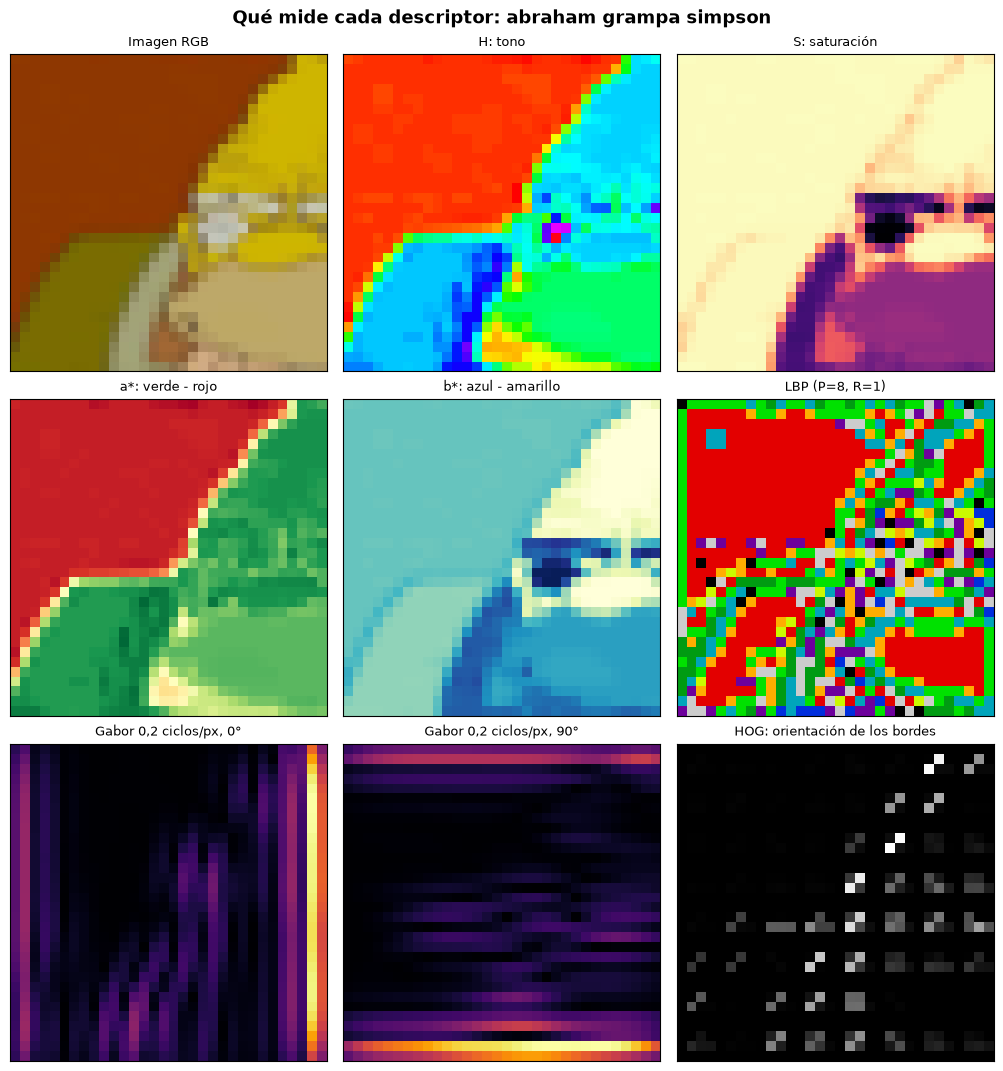

In [90]:
# Una imagen de entrenamiento descompuesta en lo que miden los descriptores
indice_demo_descriptores = int(np.flatnonzero(datos["conjunto"].to_numpy() == "train")[0])
imagen_demo = imagenes[indice_demo_descriptores]
gris_demo = rgb2gray(imagen_demo)
hsv_demo = rgb2hsv(imagen_demo)
lab_demo = rgb2lab(imagen_demo)
lbp_demo = local_binary_pattern(np.round(gris_demo * 255).astype(np.uint8), 8, 1, method="uniform")
_, hog_demo = hog(
    gris_demo,
    orientations=ORIENTACIONES_HOG,
    pixels_per_cell=(ALTO_OBJETIVO // CELDAS_HOG, ANCHO_OBJETIVO // CELDAS_HOG),
    cells_per_block=(2, 2),
    visualize=True,
)
# Núcleos 4 y 6 del banco: frecuencia 0,2 ciclos/píxel, orientaciones de 0 y 90 grados
gabor_demo = [np.abs(fftconvolve(gris_demo, NUCLEOS_GABOR[i], mode="same")) for i in (4, 6)]

paneles = [
    (imagen_demo, None, "Imagen RGB"),
    (hsv_demo[..., 0], "hsv", "H: tono"),
    (hsv_demo[..., 1], "magma", "S: saturación"),
    (lab_demo[..., 1], "RdYlGn_r", "a*: verde - rojo"),
    (lab_demo[..., 2], "YlGnBu_r", "b*: azul - amarillo"),
    (lbp_demo, "nipy_spectral", "LBP (P=8, R=1)"),
    (gabor_demo[0], "inferno", "Gabor 0,2 ciclos/px, 0°"),
    (gabor_demo[1], "inferno", "Gabor 0,2 ciclos/px, 90°"),
    (hog_demo, "gray", "HOG: orientación de los bordes"),
]

figura, ejes = plt.subplots(3, 3, figsize=(10, 10.6), layout="constrained")
for eje, (panel, mapa, titulo) in zip(np.ravel(ejes), paneles):
    eje.imshow(panel, cmap=mapa)
    eje.set_title(titulo, fontsize=9)
    eje.set_xticks([])
    eje.set_yticks([])

personaje = datos.iloc[indice_demo_descriptores]["personaje"].replace("_", " ")
figura.suptitle(f"Qué mide cada descriptor: {personaje}", fontsize=13, fontweight="bold")
plt.show()

**Imágenes alteradas por el script**

El script `scripts/newDataset/generar_imagenes_alteradas.py` aplica a cada imagen elegida un giro de 10 a
20 grados (recortando las esquinas que quedan vacías), un cambio de color (brillo, contraste, saturación
o tono) y un filtro de textura (desenfoque, nitidez, ruido o realce de bordes), con rangos moderados para
que el personaje siga siendo reconocible. La galería muestra
algunas parejas de entrenamiento, original arriba y alterada abajo, con la transformación que registró el
script en `_alteraciones.csv`.

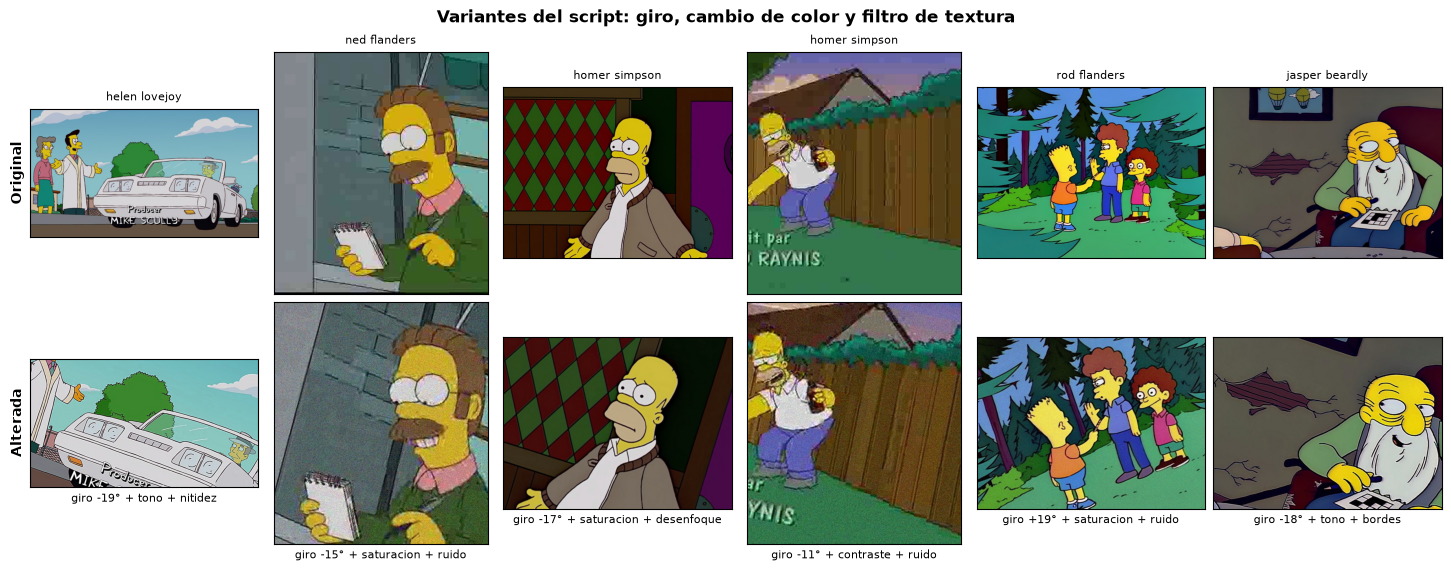

Imagenes alteradas en entrenamiento: 6937 (19.8% del conjunto)


In [91]:
# Parejas original / alterada del conjunto de entrenamiento, con la transformación aplicada
alteradas_train = datos[datos["alterada"] & (datos["conjunto"] == "train")]

if alteradas_train.empty:
    print("No hay imagenes alteradas en entrenamiento: ejecuta antes el script de alteraciones.")
else:
    transformaciones = {}
    registro_alteraciones = DATASET_BASE / "_alteraciones.csv"
    if registro_alteraciones.exists():
        registro_script = pd.read_csv(registro_alteraciones)
        con_giro = "rotacion" in registro_script.columns
        transformaciones = {
            (fila.personaje, fila.alterada): (f"giro {fila.rotacion:+.0f}° + " if con_giro else "")
            + f"{fila.color} + {fila.textura}"
            for fila in registro_script.itertuples()
        }

    muestra_alteradas = alteradas_train.sample(n=min(6, len(alteradas_train)), random_state=SEMILLA)
    figura, ejes = plt.subplots(
        2,
        len(muestra_alteradas),
        figsize=(2.4 * len(muestra_alteradas), 5.6),
        layout="constrained",
        squeeze=False,
    )
    for columna, fila in enumerate(muestra_alteradas.itertuples()):
        ruta_original = fila.ruta.with_name(fila.origen)
        for eje, ruta in ((ejes[0, columna], ruta_original), (ejes[1, columna], fila.ruta)):
            with Image.open(ruta) as img:
                eje.imshow(img.convert("RGB"))
            eje.set_xticks([])
            eje.set_yticks([])
        ejes[0, columna].set_title(fila.personaje.replace("_", " "), fontsize=8)
        ejes[1, columna].set_xlabel(
            transformaciones.get((fila.personaje, fila.ruta.name), "alterada"), fontsize=8
        )

    ejes[0, 0].set_ylabel("Original", fontsize=10, fontweight="bold")
    ejes[1, 0].set_ylabel("Alterada", fontsize=10, fontweight="bold")
    figura.suptitle(
        "Variantes del script: giro, cambio de color y filtro de textura", fontsize=12, fontweight="bold"
    )
    plt.show()

    proporcion = len(alteradas_train) / int((datos["conjunto"] == "train").sum())
    print(f"Imagenes alteradas en entrenamiento: {len(alteradas_train)} ({proporcion:.1%} del conjunto)")

**Imágenes parecidas**

Muchas imágenes del dataset son casi idénticas a otra del mismo personaje: fotogramas seguidos de una
misma escena o recortes repetidos. Si una cae en entrenamiento y su gemela en prueba, el modelo puede
acertar solo porque ya vio casi la misma imagen. El script compara las imágenes de cada personaje con
miniaturas a color de 16 x 16 (similitud coseno, umbral 0,90 por defecto) y agrupa las casi idénticas. En
cada grupo una queda intacta y cada una de las demás se reemplaza por una versión con giro, cambio de
color y filtro de textura (`<original>__parecida.<ext>`), que se vuelve a sortear hasta que deja de
parecerse a las del grupo. El notebook usa esa versión **en lugar** de la original, en cualquier
conjunto. La galería muestra algunos grupos: la imagen que quedó intacta, su casi idéntica y la versión
con la que esta entra al notebook.

Imagenes parecidas reemplazadas: 9041 en 6292 grupos   |   similitud mediana con su gemela: 0.98 antes y 0.55 despues del filtro


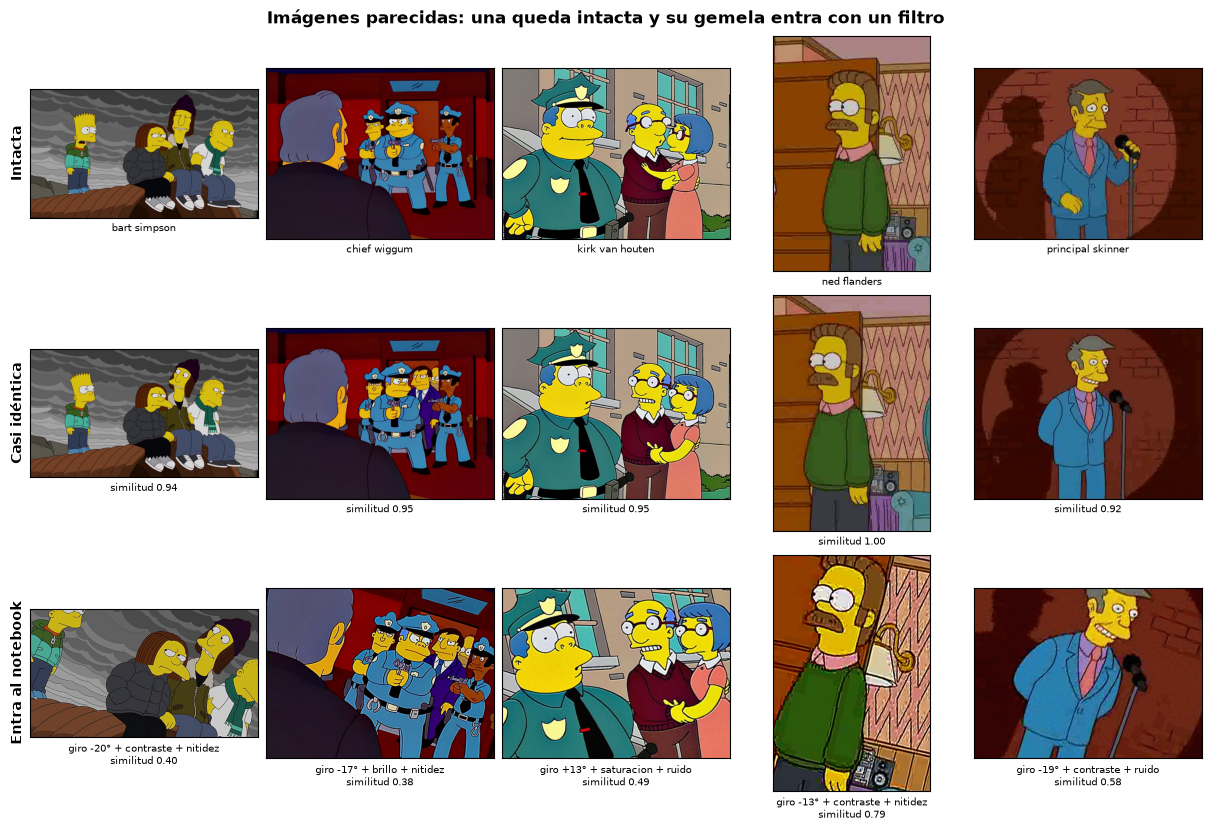

In [92]:
# Grupos de imágenes parecidas: la representante queda intacta y cada casi idéntica entra
# al notebook con su versión filtrada
registro_parecidas = DATASET_BASE / "_parecidas.csv"
if not registro_parecidas.exists():
    print("No hay registro de imagenes parecidas: ejecuta antes el script de alteraciones.")
else:
    parecidas_script = pd.read_csv(registro_parecidas)
    print(
        f"Imagenes parecidas reemplazadas: {len(parecidas_script)} en {parecidas_script['grupo'].nunique()} grupos"
        f"   |   similitud mediana con su gemela: {parecidas_script['similitud_original'].median():.2f} antes"
        f" y {parecidas_script['similitud_final'].median():.2f} despues del filtro"
    )
    muestra_parecidas = parecidas_script.sample(n=min(5, len(parecidas_script)), random_state=SEMILLA)
    figura, ejes = plt.subplots(
        3,
        len(muestra_parecidas),
        figsize=(2.4 * len(muestra_parecidas), 8.2),
        layout="constrained",
        squeeze=False,
    )
    for columna, fila in enumerate(muestra_parecidas.itertuples()):
        carpeta = DATASET_BASE / fila.personaje
        paneles = (
            (fila.representante, fila.personaje.replace("_", " ")),
            (fila.original, f"similitud {fila.similitud_original:.2f}"),
            (
                fila.parecida,
                f"giro {fila.rotacion:+.0f}° + {fila.color} + {fila.textura}\nsimilitud {fila.similitud_final:.2f}",
            ),
        )
        for numero_fila, (nombre_archivo, texto) in enumerate(paneles):
            eje = ejes[numero_fila, columna]
            with Image.open(carpeta / nombre_archivo) as img:
                eje.imshow(img.convert("RGB"))
            eje.set_xticks([])
            eje.set_yticks([])
            eje.set_xlabel(texto, fontsize=7)

    ejes[0, 0].set_ylabel("Intacta", fontsize=10, fontweight="bold")
    ejes[1, 0].set_ylabel("Casi idéntica", fontsize=10, fontweight="bold")
    ejes[2, 0].set_ylabel("Entra al notebook", fontsize=10, fontweight="bold")
    figura.suptitle(
        "Imágenes parecidas: una queda intacta y su gemela entra con un filtro", fontsize=12, fontweight="bold"
    )
    plt.show()

### Codificación de las etiquetas

**De nombre de carpeta a vector one-hot**

Las etiquetas nacen como texto (el nombre de la carpeta, por ejemplo `homer_simpson`) y una red no opera
con texto, así que hay que convertirlas a números. La conversión se hace en dos pasos:

1. **Índice entero.** Ya se construyó en "Carga de imágenes y etiquetas": `clases` es la lista de
   personajes ordenada alfabéticamente y `clase_a_indice` asigna a cada uno un entero de 0 a 63. Ese
   mapeo se reutiliza aquí en lugar de recalcularlo, porque debe ser **idéntico en train y en test**: si
   el índice 3 significara un personaje distinto en cada conjunto, la evaluación no tendría sentido.

2. **One-hot encoding.** El índice entero por sí solo es engañoso para el modelo: sugiere un **orden** y
   una **distancia** que no existen (que la clase 5 este "entre" la 4 y la 6, o que la 63 sea "mayor" que
   la 1). Los personajes son categorías nominales, sin orden. El one-hot elimina ese artefacto
   representando cada etiqueta como un vector de 64 posiciones con un 1 en la clase correcta y 0 en el
   resto, de modo que todas las clases quedan a la misma distancia entre sí.

Además, esta forma es la que corresponde a la salida de la red: la capa final tiene 64 neuronas con
`softmax`, que produce un vector de 64 probabilidades. La pérdida `categorical_crossentropy` compara ese
vector con el one-hot real, penalizando la probabilidad asignada a la clase verdadera.

> Existe la alternativa de dejar `y` como enteros y usar `sparse_categorical_crossentropy`, que es
> equivalente y ahorra memoria. Aquí se usa one-hot explícito porque hace visible la correspondencia con
> las 64 neuronas de salida, que es justamente lo que interesa mostrar en este trabajo.


In [93]:
NUMERO_CLASES = len(clases)

# One-hot: la fila i de la matriz identidad es el vector con un 1 en la posición i
# Equivale a keras.utils.to_categorical(y, NUMERO_CLASES), sin cargar TensorFlow todavía
y_onehot = np.eye(NUMERO_CLASES, dtype=np.float32)[y]

print(f"Numero de clases: {NUMERO_CLASES}")
print(f"y (indices):  {y.shape}  dtype={y.dtype}")
print(f"y_onehot:     {y_onehot.shape}  dtype={y_onehot.dtype}")

# Correspondencia para una imagen concreta
posicion_activa = int(y_onehot[indice_prueba].argmax())
print(
    f"\nEjemplo (imagen {indice_prueba}): '{datos.iloc[indice_prueba]['personaje']}'"
    f" -> indice {y[indice_prueba]} -> posicion activa {posicion_activa}"
)
print(f"vector one-hot: {y_onehot[indice_prueba].astype(int)}")


Numero de clases: 64
y (indices):  (50166,)  dtype=int64
y_onehot:     (50166, 64)  dtype=float32

Ejemplo (imagen 0): 'abraham_grampa_simpson' -> indice 0 -> posicion activa 0
vector one-hot: [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


**Comprobación de la codificación**

In [94]:
comprobaciones_etiquetas = pd.DataFrame(
    [
        (
            "Número de ejemplos",
            y_onehot.shape[0],
            X.shape[0],
            y_onehot.shape[0] == X.shape[0],
        ),
        (
            "Columnas = número de clases",
            y_onehot.shape[1],
            NUMERO_CLASES,
            y_onehot.shape[1] == NUMERO_CLASES,
        ),
        ("Tipo de dato", str(y_onehot.dtype), "float32", y_onehot.dtype == np.float32),
        (
            "Un único 1 por fila",
            float(y_onehot.sum(axis=1).min()),
            1.0,
            bool(np.all(y_onehot.sum(axis=1) == 1.0)),
        ),
        (
            "Solo valores 0 o 1",
            sorted(np.unique(y_onehot).tolist()),
            [0.0, 1.0],
            bool(np.isin(np.unique(y_onehot), [0.0, 1.0]).all()),
        ),
        (
            "Coincide con el índice entero",
            "y_onehot.argmax(axis=1)",
            "y",
            bool(np.array_equal(y_onehot.argmax(axis=1), y)),
        ),
        (
            "Todas las clases presentes",
            int((y_onehot.sum(axis=0) > 0).sum()),
            NUMERO_CLASES,
            int((y_onehot.sum(axis=0) > 0).sum()) == NUMERO_CLASES,
        ),
        (
            "Mapeo estable (índice -> nombre)",
            indice_a_clase[0],
            clases[0],
            indice_a_clase[0] == clases[0],
        ),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)

display(comprobaciones_etiquetas)

if not comprobaciones_etiquetas["Correcto"].all():
    raise ValueError("La codificación de etiquetas no cumple alguna de las comprobaciones.")

print("Codificación verificada correctamente.")


,Comprobacion,Obtenido,Esperado,Correcto
0,Número de ejemplos,50166,50166,True
1,Columnas = número de clases,64,64,True
2,Tipo de dato,float32,float32,True
3,Un único 1 por fila,1.0,1.0,True
4,Solo valores 0 o 1,"[0.0, 1.0]","[0.0, 1.0]",True
5,Coincide con el índice entero,y_onehot.argmax(axis=1),y,True
6,Todas las clases presentes,64,64,True
7,Mapeo estable (índice -> nombre),abraham_grampa_simpson,abraham_grampa_simpson,True


Codificación verificada correctamente.


In [95]:
# Diccionario de clases: índice, nombre y ejemplos disponibles
tabla_clases = pd.DataFrame(
    {
        "indice": range(NUMERO_CLASES),
        "personaje": clases,
        "imagenes": [int((y == indice).sum()) for indice in range(NUMERO_CLASES)],
    }
)
tabla_clases["porcentaje"] = (tabla_clases["imagenes"] / len(y) * 100).round(2)

display(tabla_clases)


,indice,personaje,imagenes,porcentaje
0,0,abraham_grampa_simpson,1301,2.59
1,1,agnes_skinner,440,0.88
2,2,apu_nahasapeemapetilon,1008,2.01
3,3,barney_gumble,704,1.40
4,4,bart_simpson,2426,4.84
...,...,...,...,...
59,59,sideshow_mel,483,0.96
60,60,snake_jailbird,430,0.86
61,61,todd_flanders,158,0.31
62,62,troy_mcclure,413,0.82


### Escenas con varios personajes

La etiqueta de cada imagen es su carpeta, pero un fotograma puede mostrar a más de un personaje: Lou junto
a Wiggum, Smithers junto a Burns, Barney en el bar de Moe. Cuando el modelo responde con el otro personaje
de la escena, la métrica estricta lo cuenta como error aunque la respuesta sea razonable, y el
entrenamiento lo castiga igual que una confusión sin sentido.

Los **fotogramas de episodio** del dataset traen en su nombre el episodio y el instante
(`personaje__S02E15__t0675633.jpg`, con `t` en milisegundos). Eso permite estimar quién más aparece en la
escena sin anotar nada a mano:

- **Otro personaje en la misma escena.** Si la carpeta de otro personaje tiene un fotograma del mismo
  episodio a menos de `VENTANA_ESCENA_MS` (3 s), se asume que ese personaje también está en la escena. Es
  una heurística: tres segundos suelen ser el mismo plano, pero un corte de cámara puede caer en medio.
- **Nombre de archivo de otro personaje.** Los fotogramas que el equipo movió a la carpeta de su
  protagonista conservan el nombre del personaje con el que se extrajeron, que también está en el
  encuadre.
- **Gemela en la carpeta de otro personaje.** El script de alteraciones compara las imágenes de carpetas
  distintas y registra en `_gemelas.csv` las casi idénticas (similitud ≥ 0,90): es la misma escena
  guardada dos veces, así que los dos personajes están en ella. Esta fuente también alcanza a las
  imágenes de Kaggle. El script copia además esas imágenes a `gemelas_por_revisar/`, fuera del dataset,
  para que el equipo decida a mano si las suma también a la carpeta del otro personaje.

Las imágenes que vienen del dataset de Kaggle (`homer_simpson_0001.jpg`) no traen episodio ni instante:
solo tienen acompañantes si tienen una gemela; si no, conservan su etiqueta única.

**Cómo se usa.**

1. **Al entrenar.** La etiqueta de una imagen con escena compartida deja de ser un one-hot puro: el
   personaje de la carpeta conserva el `1 - PESO_ESCENA` (85 %) y el resto se reparte entre los
   acompañantes. El modelo sigue aprendiendo que el principal es el de la carpeta, pero nombrar al
   acompañante deja de castigarse como un error grave. El experimento S2 mide su efecto.
2. **Al evaluar.** Una predicción que nombra a un personaje presente cuenta como **acierto** en todas las
   métricas de prueba y en los KPIs. La accuracy estricta, que solo acepta el personaje de la carpeta, se
   informa como referencia. Los errores cometidos con confianza mayor que 0,80 pasan además por una
   verificación por imagen (sección «Verificación de los errores con confianza alta»).

**Sin fuga de información.** La escena que se usa al entrenar se calcula **solo con los fotogramas de
entrenamiento**. Si se usaran todos, un fotograma de test casi idéntico a uno de entrenamiento le pasaría
su etiqueta al modelo a través del objetivo de entrenamiento. Por lo mismo, al entrenar solo cuentan las gemelas que
también están en entrenamiento. La escena de la evaluación sí usa todos los fotogramas y todas las
gemelas, porque solo se lee después de predecir y no influye en el modelo. La validación, que decide la
parada temprana y el modelo final, se mide siempre con la etiqueta de la carpeta.


In [96]:
import re

# Fotogramas de episodio: <personaje>__<episodio>__t<milisegundos>
PATRON_FOTOGRAMA = re.compile(r"^(?P<nombre>.+?)__(?P<episodio>S\d+E\d+)__t(?P<ms>\d+)$", re.IGNORECASE)
VENTANA_ESCENA_MS = 3000
PESO_ESCENA = 0.15


def leer_fotograma(nombre_archivo):
    """(personaje del nombre, episodio, ms) de un fotograma de episodio, o None si no lo es."""
    coincidencia = PATRON_FOTOGRAMA.match(Path(nombre_archivo).stem)
    if coincidencia is None:
        return None
    return coincidencia["nombre"], coincidencia["episodio"].upper(), int(coincidencia["ms"])


def construir_lineas_tiempo(tabla):
    """Fotogramas de cada episodio ordenados por instante: {episodio: (instantes, personajes)}."""
    por_episodio = {}
    for personaje, origen in zip(tabla["personaje"], tabla["origen"]):
        fotograma = leer_fotograma(origen)
        if fotograma is not None:
            por_episodio.setdefault(fotograma[1], []).append((fotograma[2], personaje))
    lineas = {}
    for episodio, fotogramas in por_episodio.items():
        fotogramas.sort()
        lineas[episodio] = (np.array([ms for ms, _ in fotogramas]), [p for _, p in fotogramas])
    return lineas


def personajes_en_escena(personaje, origen, lineas_tiempo):
    """Personajes que probablemente acompañan al de la carpeta en esa imagen (sin incluirlo)."""
    fotograma = leer_fotograma(origen)
    if fotograma is None:
        return frozenset()
    nombre, episodio, ms = fotograma
    acompanantes = {nombre} if nombre != personaje and nombre in clase_a_indice else set()
    if episodio in lineas_tiempo:
        instantes, personajes = lineas_tiempo[episodio]
        desde = np.searchsorted(instantes, ms - VENTANA_ESCENA_MS, side="left")
        hasta = np.searchsorted(instantes, ms + VENTANA_ESCENA_MS, side="right")
        acompanantes.update(otro for otro in personajes[desde:hasta] if otro != personaje)
    return frozenset(acompanantes)


# Gemelas entre personajes: la misma escena guardada en la carpeta de otro personaje. Las detecta el
# script de alteraciones comparando las originales de carpetas distintas
registro_gemelas = DATASET_BASE / "_gemelas.csv"
GEMELAS = {}
n_pares_gemelas = 0
if registro_gemelas.exists():
    pares_gemelas = pd.read_csv(registro_gemelas)
    pares_gemelas = pares_gemelas[
        pares_gemelas["personaje"].isin(clase_a_indice) & pares_gemelas["otro_personaje"].isin(clase_a_indice)
    ]
    n_pares_gemelas = len(pares_gemelas)
    for fila in pares_gemelas.itertuples():
        GEMELAS.setdefault((fila.personaje, fila.original), set()).add((fila.otro_personaje, fila.otro_original))
        GEMELAS.setdefault((fila.otro_personaje, fila.otro_original), set()).add((fila.personaje, fila.original))
else:
    print("No hay registro de gemelas entre personajes: ejecuta antes el script de alteraciones.")


def personajes_gemelos(personaje, origen, permitidas=None):
    """Personajes en cuya carpeta hay una imagen casi idéntica a esta. Con `permitidas`, solo cuentan
    las gemelas que están en ese conjunto de (personaje, original)."""
    return frozenset(
        otro
        for otro, otro_origen in GEMELAS.get((personaje, origen), ())
        if permitidas is None or (otro, otro_origen) in permitidas
    )


# Línea de tiempo para EVALUAR: todos los fotogramas originales del dataset
originales_indexados = indice_completo[
    ~indice_completo["alterada"] & indice_completo["personaje"].isin(clase_a_indice)
]
LINEAS_TIEMPO_COMPLETAS = construir_lineas_tiempo(originales_indexados)
# Línea de tiempo para ENTRENAR: solo los fotogramas originales de entrenamiento
LINEAS_TIEMPO_TRAIN = construir_lineas_tiempo(datos[(datos["conjunto"] == "train") & ~datos["alterada"]])

es_train = (datos["conjunto"] == "train").to_numpy()
# Para ENTRENAR solo cuentan las gemelas que son originales de entrenamiento
originales_train = set(
    zip(datos.loc[es_train & ~datos["alterada"].to_numpy(), "personaje"],
        datos.loc[es_train & ~datos["alterada"].to_numpy(), "origen"])
)
escena_evaluacion = [
    personajes_en_escena(p, o, LINEAS_TIEMPO_COMPLETAS) | personajes_gemelos(p, o)
    for p, o in zip(datos["personaje"], datos["origen"])
]
escena_entrenamiento = [
    personajes_en_escena(p, o, LINEAS_TIEMPO_TRAIN) | personajes_gemelos(p, o, originales_train)
    if en_train
    else frozenset()
    for p, o, en_train in zip(datos["personaje"], datos["origen"], es_train)
]
datos["escena"] = [", ".join(sorted(acompanantes)) for acompanantes in escena_evaluacion]

# Objetivo de entrenamiento con escena: el personaje de la carpeta conserva 1 - PESO_ESCENA
# y el resto se reparte entre sus acompañantes. Las filas de validación y test no cambian.
y_escena = y_onehot.copy()
for fila, acompanantes in enumerate(escena_entrenamiento):
    if acompanantes:
        y_escena[fila] *= 1 - PESO_ESCENA
        for otro in acompanantes:
            y_escena[fila, clase_a_indice[otro]] += PESO_ESCENA / len(acompanantes)

es_fotograma = np.array([leer_fotograma(origen) is not None for origen in datos["origen"]])
con_gemela = np.array([bool(personajes_gemelos(p, o)) for p, o in zip(datos["personaje"], datos["origen"])])
con_escena_evaluacion = np.array([bool(acompanantes) for acompanantes in escena_evaluacion])
con_escena_entrenamiento = np.array([bool(acompanantes) for acompanantes in escena_entrenamiento])

resumen_escena = pd.DataFrame(
    [
        (
            nombre,
            int(mascara.sum()),
            int(es_fotograma[mascara].sum()),
            int(con_gemela[mascara].sum()),
            int(con_escena_evaluacion[mascara].sum()),
            int(con_escena_entrenamiento[mascara].sum()) if nombre == "train" else "-",
        )
        for nombre in CONJUNTOS
        for mascara in [(datos["conjunto"] == nombre).to_numpy()]
    ],
    columns=["conjunto", "imagenes", "fotogramas", "con_gemela", "escena_compartida", "etiqueta_suave_al_entrenar"],
)
display(resumen_escena)

# Parejas de personajes que más comparten escena (solo originales)
pares_escena = (
    pd.DataFrame(
        [
            (personaje, otro)
            for personaje, acompanantes, alterada in zip(datos["personaje"], escena_evaluacion, datos["alterada"])
            if not alterada
            for otro in acompanantes
        ],
        columns=["personaje", "acompanante"],
    )
    .value_counts()
    .head(10)
    .reset_index(name="imagenes")
)
display(pares_escena)

comprobaciones_escena = pd.DataFrame(
    [
        (
            "Cada objetivo suma 1",
            round(float(y_escena.sum(axis=1).min()), 4),
            1.0,
            bool(np.allclose(y_escena.sum(axis=1), 1.0)),
        ),
        (
            "La carpeta sigue siendo la clase principal",
            "y_escena.argmax(axis=1)",
            "y",
            bool(np.array_equal(y_escena.argmax(axis=1), y)),
        ),
        (
            "Validación y test sin etiqueta suave",
            int((y_escena[~es_train] != y_onehot[~es_train]).any(axis=1).sum()),
            0,
            bool(np.array_equal(y_escena[~es_train], y_onehot[~es_train])),
        ),
        (
            "Ninguna imagen se acompaña a sí misma",
            "personaje fuera de su escena",
            True,
            all(p not in a for p, a in zip(datos["personaje"], escena_evaluacion)),
        ),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)
display(comprobaciones_escena)

if not comprobaciones_escena["Correcto"].all():
    raise ValueError("Las etiquetas de escena no cumplen alguna de las comprobaciones.")

print(
    f"Fotogramas de episodio: {int(es_fotograma.sum())} de {len(datos)} imagenes"
    f"   |   con gemela en otra carpeta: {int(con_gemela.sum())} ({n_pares_gemelas} pares)"
    f"   |   con escena compartida: {int(con_escena_evaluacion.sum())}"
    f"   |   con etiqueta suave al entrenar: {int(con_escena_entrenamiento.sum())}"
)


,conjunto,imagenes,fotogramas,con_gemela,escena_compartida,etiqueta_suave_al_entrenar
0,train,35023,15603,2049,5191,4270
1,val,10080,4542,618,1600,-
2,test,5063,2282,294,742,-


,personaje,acompanante,imagenes
0,chief_wiggum,lou,164
1,lou,chief_wiggum,150
2,patty_bouvier,selma_bouvier,122
3,selma_bouvier,patty_bouvier,120
4,gary_chalmers,principal_skinner,117
5,principal_skinner,gary_chalmers,115
6,lenny_leonard,carl_carlson,91
7,carl_carlson,lenny_leonard,90
8,charles_montgomery_burns,waylon_smithers,85
9,waylon_smithers,charles_montgomery_burns,83


,Comprobacion,Obtenido,Esperado,Correcto
0,Cada objetivo suma 1,1.0,1.0,True
1,La carpeta sigue siendo la clase principal,y_escena.argmax(axis=1),y,True
2,Validación y test sin etiqueta suave,0,0,True
3,Ninguna imagen se acompaña a sí misma,personaje fuera de su escena,True,True


Fotogramas de episodio: 22427 de 50166 imagenes   |   con gemela en otra carpeta: 2961 (3326 pares)   |   con escena compartida: 7533   |   con etiqueta suave al entrenar: 4270


### Partición train / validación / test

**Por qué hacen falta tres conjuntos y no dos**

Entrenar mirando el conjunto de prueba es hacer trampa: en cuanto se usa para decidir cuántas capas
poner, cuándo detener el entrenamiento o qué representación elegir, deja de ser una estimación honesta
del desempeño con datos nuevos, porque esas decisiones ya lo incorporaron. Ese fenómeno se conoce como
fuga de información.

Por eso cada personaje se repartió, en «Partición y selección por personaje», en tres conjuntos:

- **Entrenamiento (70 % de las originales):** las imágenes con las que se ajustan los pesos.
- **Validación (20 % de las originales):** imágenes que nunca actualizan pesos, pero que se miden en
  cada época. Sirven para trazar las curvas de aprendizaje, detectar sobreajuste, activar la parada
  temprana y comparar las configuraciones de la experimentación.
- **Test (10 % de las originales):** se reserva intacto y se abre **una sola vez**, en la evaluación
  final del modelo elegido.

Cada conjunto lleva además las variantes alteradas de sus propias originales y la versión filtrada de las
casi idénticas, así que los tres tienen las mismas condiciones.

**Partición estratificada.** Validación y test conservan, para cada personaje, la misma proporción que
tiene en el dataset completo. Con 64 clases muy desbalanceadas, un reparto aleatorio simple podría dejar
a un personaje minoritario con muy pocos ejemplos de validación —o con ninguno—, y entonces su métrica
sería pura casualidad.

**Semilla fija.** `random_state=SEMILLA` garantiza que la partición sea siempre la misma. Es un
requisito de la metodología de experimentación: al cambiar un solo factor por vez, la diferencia
observada debe deberse a ese factor y no a que le tocó un reparto de datos distinto.

La celda siguiente solo materializa esa partición: separa las filas de cada matriz según el conjunto
que se asignó a cada imagen.

In [97]:
# La partición ya está decidida en la columna "conjunto" de datos: aquí solo se
# separan las filas de cada matriz
MASCARAS = {nombre: (datos["conjunto"] == nombre).to_numpy() for nombre in CONJUNTOS}

_particiones = {}


def particion(representacion):
    """Filas de train, validación y test de una representación. Se calculan la primera vez
    que se piden: la de píxeles ocupa bastante memoria y solo la usa el experimento R1."""
    if representacion not in _particiones:
        matriz = REPRESENTACIONES[representacion]
        _particiones[representacion] = {
            nombre: matriz[mascara] for nombre, mascara in MASCARAS.items()
        }
    return _particiones[representacion]


# Etiquetas e imágenes de cada conjunto (las de test se usan en el análisis de errores).
# Entrenamiento usa el objetivo con escena; validación y test, el one-hot estricto.
y_train, y_val, y_test = (y_onehot[MASCARAS[nombre]] for nombre in CONJUNTOS)
y_train_duro = y_train
y_train = y_escena[MASCARAS["train"]]
y_train_idx, y_val_idx, y_test_idx = (y[MASCARAS[nombre]] for nombre in CONJUNTOS)
imagenes_test = imagenes[MASCARAS["test"]]
datos_test = datos[MASCARAS["test"]].reset_index(drop=True)

# Matrices de la representación del modelo base
X_train, X_val, X_test = (particion(REPRESENTACION_BASE)[nombre] for nombre in CONJUNTOS)

print(f"X_train: {X_train.shape}   y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape}   y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape}   y_test:  {y_test.shape}")
# Las proporciones se miden sobre las originales: las alteradas son variantes extra que van
# al mismo conjunto que su original
es_alterada = datos["alterada"].to_numpy()
n_originales = {nombre: int((MASCARAS[nombre] & ~es_alterada).sum()) for nombre in CONJUNTOS}
n_alteradas = {nombre: int((MASCARAS[nombre] & es_alterada).sum()) for nombre in CONJUNTOS}
total = sum(n_originales.values())
print(
    "\nReparto de las originales: "
    + " / ".join(f"{n_originales[nombre]} {nombre} ({n_originales[nombre] / total * 100:.1f} %)" for nombre in CONJUNTOS)
)
for nombre in CONJUNTOS:
    print(
        f"{nombre:<5}: {n_originales[nombre]} originales + {n_alteradas[nombre]} alteradas"
        f" = {n_originales[nombre] + n_alteradas[nombre]} imagenes"
    )
print(f"Representacion del modelo base: {REPRESENTACION_BASE} ({X_train.shape[1]} valores por imagen)")

X_train: (35023, 2462)   y_train: (35023, 64)
X_val:   (10080, 2462)   y_val:   (10080, 64)
X_test:  (5063, 2462)   y_test:  (5063, 64)

Reparto de las originales: 28086 train (70.0 %) / 8024 val (20.0 %) / 4013 test (10.0 %)
train: 28086 originales + 6937 alteradas = 35023 imagenes
val  : 8024 originales + 2056 alteradas = 10080 imagenes
test : 4013 originales + 1050 alteradas = 5063 imagenes
Representacion del modelo base: color_textura (2462 valores por imagen)


**Comprobación de la partición**

In [98]:
# Proporción de cada personaje en el dataset completo frente a validación y test
proporcion_dataset = originales["personaje"].value_counts(normalize=True)
proporciones = pd.DataFrame(
    {
        "personaje": clases,
        "dataset_%": [round(float(proporcion_dataset[clase]) * 100, 2) for clase in clases],
        "val_%": [round((y_val_idx == i).mean() * 100, 2) for i in range(NUMERO_CLASES)],
        "test_%": [round((y_test_idx == i).mean() * 100, 2) for i in range(NUMERO_CLASES)],
        "n_train": [int((y_train_idx == i).sum()) for i in range(NUMERO_CLASES)],
        "n_val": [int((y_val_idx == i).sum()) for i in range(NUMERO_CLASES)],
        "n_test": [int((y_test_idx == i).sum()) for i in range(NUMERO_CLASES)],
    }
)
proporciones["desviacion_%"] = (
    proporciones[["val_%", "test_%"]].sub(proporciones["dataset_%"], axis=0).abs().max(axis=1).round(2)
)

display(proporciones)

# Una imagen y sus variantes se identifican por (personaje, original de la que salen)
origenes = {
    nombre: set(zip(datos.loc[MASCARAS[nombre], "personaje"], datos.loc[MASCARAS[nombre], "origen"]))
    for nombre in CONJUNTOS
}
compartidas = (
    len(origenes["train"] & origenes["val"])
    + len(origenes["train"] & origenes["test"])
    + len(origenes["val"] & origenes["test"])
)
# Mismas condiciones en los tres conjuntos: cuántas alteradas y parecidas hay por cada original
TOLERANCIA_CONDICIONES = 0.03


def por_original(columna):
    return {
        nombre: float(datos.loc[MASCARAS[nombre], columna].sum())
        / max(int((MASCARAS[nombre] & ~datos["alterada"].to_numpy()).sum()), 1)
        for nombre in CONJUNTOS
    }


alteradas_por_original = por_original("alterada")
parecidas_por_original = por_original("parecida")
proporciones_obtenidas = {
    nombre: (MASCARAS[nombre] & ~datos["alterada"].to_numpy()).sum() / (~datos["alterada"]).sum()
    for nombre in CONJUNTOS
}
clases_por_conjunto = [len(np.unique(indices)) for indices in (y_train_idx, y_val_idx, y_test_idx)]

comprobaciones_particion = pd.DataFrame(
    [
        (
            "Cada imagen en un solo conjunto",
            int(sum(mascara.sum() for mascara in MASCARAS.values())),
            len(datos),
            int(sum(mascara.sum() for mascara in MASCARAS.values())) == len(datos),
        ),
        ("Sin imágenes compartidas entre conjuntos", compartidas, 0, compartidas == 0),
        *[
            (
                f"{nombre} por original en train / val / test",
                " / ".join(f"{proporciones_tipo[conjunto]:.1%}" for conjunto in CONJUNTOS),
                f"iguales (± {TOLERANCIA_CONDICIONES:.0%})",
                all(
                    abs(proporciones_tipo[conjunto] - proporciones_tipo["train"]) <= TOLERANCIA_CONDICIONES
                    for conjunto in CONJUNTOS
                ),
            )
            for nombre, proporciones_tipo in (
                ("Alteradas", alteradas_por_original),
                ("Parecidas", parecidas_por_original),
            )
        ],
        (
            "Todas las originales repartidas (sin tope)",
            int((~datos["alterada"]).sum()),
            len(originales),
            int((~datos["alterada"]).sum()) == len(originales),
        ),
        (
            "Proporciones train / val / test de las originales",
            " / ".join(f"{proporciones_obtenidas[nombre]:.1%}" for nombre in CONJUNTOS),
            " / ".join(f"{PROPORCIONES[nombre]:.0%}" for nombre in CONJUNTOS),
            all(abs(proporciones_obtenidas[nombre] - PROPORCIONES[nombre]) < 0.005 for nombre in CONJUNTOS),
        ),
        (
            "Dimensión de entrada intacta",
            X_train.shape[1],
            DIMENSION_ENTRADA,
            X_train.shape[1] == DIMENSION_ENTRADA,
        ),
        ("X e y alineados en train", len(y_train), len(X_train), len(y_train) == len(X_train)),
        ("X e y alineados en validación", len(y_val), len(X_val), len(y_val) == len(X_val)),
        ("X e y alineados en test", len(y_test), len(X_test), len(y_test) == len(X_test)),
        (
            "One-hot coherente con índices",
            "y_val.argmax(axis=1)",
            "y_val_idx",
            bool(np.array_equal(np.argmax(y_val, axis=1), y_val_idx)),
        ),
        (
            "Todas las clases en train / val / test",
            " / ".join(str(n) for n in clases_por_conjunto),
            NUMERO_CLASES,
            all(n == NUMERO_CLASES for n in clases_por_conjunto),
        ),
        (
            "Estratificación de val y test (desviación máxima)",
            f"{proporciones['desviacion_%'].max():.2f} %",
            "< 1 %",
            bool(proporciones["desviacion_%"].max() < 1.0),
        ),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)

display(comprobaciones_particion)

if not comprobaciones_particion["Correcto"].all():
    raise ValueError("La partición no cumple alguna de las comprobaciones.")

print("Partición verificada correctamente.")

,personaje,dataset_%,val_%,test_%,n_train,n_val,n_test,desviacion_%
0,abraham_grampa_simpson,2.59,2.58,2.45,917,260,124,0.14
1,agnes_skinner,0.88,0.86,0.83,311,87,42,0.05
2,apu_nahasapeemapetilon,2.01,2.07,1.94,701,209,98,0.07
3,barney_gumble,1.40,1.43,1.36,491,144,69,0.04
4,bart_simpson,4.84,4.84,4.88,1691,488,247,0.04
...,...,...,...,...,...,...,...,...
59,sideshow_mel,0.96,0.96,0.97,337,97,49,0.01
60,snake_jailbird,0.86,0.86,0.91,297,87,46,0.05
61,todd_flanders,0.31,0.31,0.34,110,31,17,0.03
62,troy_mcclure,0.82,0.85,0.83,285,86,42,0.03


,Comprobacion,Obtenido,Esperado,Correcto
0,Cada imagen en un solo conjunto,50166,50166,True
1,Sin imágenes compartidas entre conjuntos,0,0,True
2,Alteradas por original en train / val / test,24.7% / 25.6% / 26.2%,iguales (± 3%),True
3,Parecidas por original en train / val / test,22.5% / 22.5% / 22.7%,iguales (± 3%),True
4,Todas las originales repartidas (sin tope),40123,40123,True
5,Proporciones train / val / test de las originales,70.0% / 20.0% / 10.0%,70% / 20% / 10%,True
6,Dimensión de entrada intacta,2462,2462,True
7,X e y alineados en train,35023,35023,True
8,X e y alineados en validación,10080,10080,True
9,X e y alineados en test,5063,5063,True


Partición verificada correctamente.


### Tratamiento del desbalance de clases

**El problema**

Como se describió en "Definición del problema de clasificación", el dataset está muy desbalanceado
(razón aproximada 33:1 entre `homer_simpson` y `louie`). Esto sesga el entrenamiento: la pérdida es un
promedio sobre los ejemplos del batch, así que los personajes abundantes dominan el gradiente y el
modelo aprende que, ante la duda, conviene predecir una clase mayoritaria. El resultado típico es un
accuracy global aceptable acompañado de un recall muy bajo en las clases pequeñas, que es precisamente
lo que el **F1 macro** —promedio no ponderado entre clases— deja al descubierto.

**Opciones consideradas**

| Estrategia | Qué hace | Por qué se descarta o se elige |
|---|---|---|
| Submuestreo de mayoritarias | Limita cada personaje a un tope de originales en entrenamiento | Se descarta: una corrida anterior con un tope de 300 dejaba sin usar unas 12.700 imágenes, y los personajes frecuentes, recortados en entrenamiento pero completos en validación y test, caían por debajo de un 20 % de recall (Homero 0,16, Bart 0,15) |
| Sobremuestreo por duplicado | Repite imágenes de las clases pequeñas | Se descarta: los duplicados exactos favorecen el sobreajuste a esas imágenes |
| **Aumento de datos** | Añade variantes alteradas con un giro de 10 a 20°, un cambio de color y un filtro de textura | **Se elige:** las genera una sola vez el script `generar_imagenes_alteradas.py` para un cuarto de las imágenes de cada personaje. Cada una va al mismo conjunto que su original: en entrenamiento aumenta los datos, y en validación y prueba hace que el modelo se mida en las mismas condiciones |
| **Pesos por clase suavizados** | Pondera la pérdida según la frecuencia de cada clase | **Se elige:** compensa el desbalance sin descartar datos. Se usa la raíz cuadrada del peso balanceado: con 32:1 en entrenamiento, el balanceado completo daría a `louie` unas 32 veces el peso de Homero y empujaría al modelo a no predecir a los frecuentes. Los experimentos P1 y P2 comparan sin pesos y con los balanceados completos |

**Cómo funciona `class_weight`.** Keras multiplica la pérdida de cada ejemplo por el peso de su clase, de
modo que equivocarse en un personaje raro cuesta más que equivocarse en uno frecuente. Se usa la fórmula
`n_muestras / (n_clases * n_ejemplos_de_la_clase)`, que da peso 1 a una clase de tamaño medio, mayor que 1
a las minoritarias y menor que 1 a las mayoritarias. El modelo base usa su **raíz cuadrada**, reescalada
para que el peso medio por imagen siga siendo 1: la pérdida conserva su escala y la razón entre el peso
mayor y el menor baja de unas 32 a unas 6 veces.

**Advertencia importante.** Los pesos se calculan **solo con `y_train`**, nunca con el conjunto completo
ni con validación: usar información de validación para ajustar el entrenamiento sería otra forma de fuga.
Y se aplican **solo durante el entrenamiento**: las métricas de validación y test se miden sin pesos,
porque deben reflejar el desempeño sobre la distribución real de los datos.

El efecto conjunto de estas tres decisiones se lee en la evaluación, comparando la accuracy con el F1
macro en test.

In [99]:
from sklearn.utils.class_weight import compute_class_weight

# Los pesos se calculan SOLO con las etiquetas de entrenamiento
pesos_balanceados = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUMERO_CLASES),
    y=y_train_idx,
)
conteos_train = np.bincount(y_train_idx, minlength=NUMERO_CLASES)

# Pesos suavizados: raíz cuadrada del balanceado, reescalada para que el peso medio por
# imagen de entrenamiento sea 1 y la pérdida conserve su escala
pesos_raiz = np.sqrt(pesos_balanceados)
pesos_raiz = pesos_raiz * len(y_train_idx) / (pesos_raiz * conteos_train).sum()

# Esquemas que compara la experimentación (P1 y P2); el modelo base usa ESQUEMA_PESOS.
# Keras espera un diccionario {indice_de_clase: peso}
ESQUEMA_PESOS = "raiz"
PESOS_POR_ESQUEMA = {
    "ninguno": None,
    "raiz": {indice: float(peso) for indice, peso in enumerate(pesos_raiz)},
    "balanceado": {indice: float(peso) for indice, peso in enumerate(pesos_balanceados)},
}
pesos = pesos_raiz
pesos_por_clase = PESOS_POR_ESQUEMA[ESQUEMA_PESOS]

tabla_pesos = pd.DataFrame(
    {
        "indice": range(NUMERO_CLASES),
        "personaje": clases,
        "n_train": conteos_train,
        "porcentaje": (conteos_train / conteos_train.sum() * 100).round(2),
        "peso_balanceado": np.round(pesos_balanceados, 3),
        "peso": np.round(pesos, 3),
    }
).sort_values("n_train", ascending=False, ignore_index=True)

display(tabla_pesos)

razon_desbalance = conteos_train.max() / conteos_train.min()
print(f"Clase mayoritaria: {clases[int(conteos_train.argmax())]} ({conteos_train.max()} imagenes)")
print(f"Clase minoritaria: {clases[int(conteos_train.argmin())]} ({conteos_train.min()} imagenes)")
print(f"Razon de desbalance: {razon_desbalance:.1f}:1")
print(f"Rango de pesos (raiz, los del modelo base): [{pesos.min():.3f}, {pesos.max():.3f}]")
print(f"Rango de pesos balanceados completos      : [{pesos_balanceados.min():.3f}, {pesos_balanceados.max():.3f}]")


,indice,personaje,n_train,porcentaje,peso_balanceado,peso
0,22,homer_simpson,2718,7.76,0.201,0.492
1,4,bart_simpson,1691,4.83,0.324,0.624
2,46,ned_flanders,1554,4.44,0.352,0.651
3,33,lisa_simpson,1546,4.41,0.354,0.653
4,38,marge_simpson,1543,4.41,0.355,0.654
...,...,...,...,...,...,...
59,25,judge_snyder,104,0.30,5.262,2.517
60,23,jasper_beardly,99,0.28,5.528,2.580
61,56,rod_flanders,96,0.27,5.700,2.620
62,11,disco_stu,92,0.26,5.948,2.676


Clase mayoritaria: homer_simpson (2718 imagenes)
Clase minoritaria: louie (85 imagenes)
Razon de desbalance: 32.0:1
Rango de pesos (raiz, los del modelo base): [0.492, 2.784]
Rango de pesos balanceados completos      : [0.201, 6.438]


**Comprobación de los pesos y baselines de referencia**

In [100]:
comprobaciones_pesos = pd.DataFrame(
    [
        (
            "Un peso por clase",
            len(pesos_por_clase),
            NUMERO_CLASES,
            len(pesos_por_clase) == NUMERO_CLASES,
        ),
        (
            "Todos los pesos positivos",
            round(float(pesos.min()), 3),
            "> 0",
            bool((pesos > 0).all()),
        ),
        (
            "Mayor peso a la clase minoritaria",
            clases[int(pesos.argmax())],
            clases[int(conteos_train.argmin())],
            int(pesos.argmax()) == int(conteos_train.argmin()),
        ),
        (
            "Menor peso a la clase mayoritaria",
            clases[int(pesos.argmin())],
            clases[int(conteos_train.argmax())],
            int(pesos.argmin()) == int(conteos_train.argmax()),
        ),
        (
            "Peso inverso a la frecuencia",
            "corr(peso, n_train)",
            "negativa",
            bool(float(np.corrcoef(pesos, conteos_train)[0, 1]) < 0),
        ),
        (
            "Calculados solo con train",
            len(y_train_idx),
            len(X_train),
            len(y_train_idx) == len(X_train),
        ),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)

display(comprobaciones_pesos)

if not comprobaciones_pesos["Correcto"].all():
    raise ValueError("Los pesos por clase no cumplen alguna de las comprobaciones.")

# Baselines contra los que se comparará el modelo final. La clase mayoritaria se mide
# sobre validación, que conserva la distribución real del dataset (sus alteradas son un
# cuarto de las originales de cada personaje, igual que en train).
conteos_val = np.bincount(y_val_idx, minlength=NUMERO_CLASES)
baseline_azar = 100 / NUMERO_CLASES
baseline_mayoritaria = conteos_val.max() / conteos_val.sum() * 100

print(f"\nBaseline por azar (1/{NUMERO_CLASES}): {baseline_azar:.1f} % de accuracy")
print(f"Baseline de clase mayoritaria:  {baseline_mayoritaria:.1f} % de accuracy")
print("El modelo solo aporta valor si supera claramente ambos.")


,Comprobacion,Obtenido,Esperado,Correcto
0,Un peso por clase,64,64,True
1,Todos los pesos positivos,0.492,> 0,True
2,Mayor peso a la clase minoritaria,louie,louie,True
3,Menor peso a la clase mayoritaria,homer_simpson,homer_simpson,True
4,Peso inverso a la frecuencia,"corr(peso, n_train)",negativa,True
5,Calculados solo con train,35023,35023,True



Baseline por azar (1/64): 1.6 % de accuracy
Baseline de clase mayoritaria:  7.8 % de accuracy
El modelo solo aporta valor si supera claramente ambos.


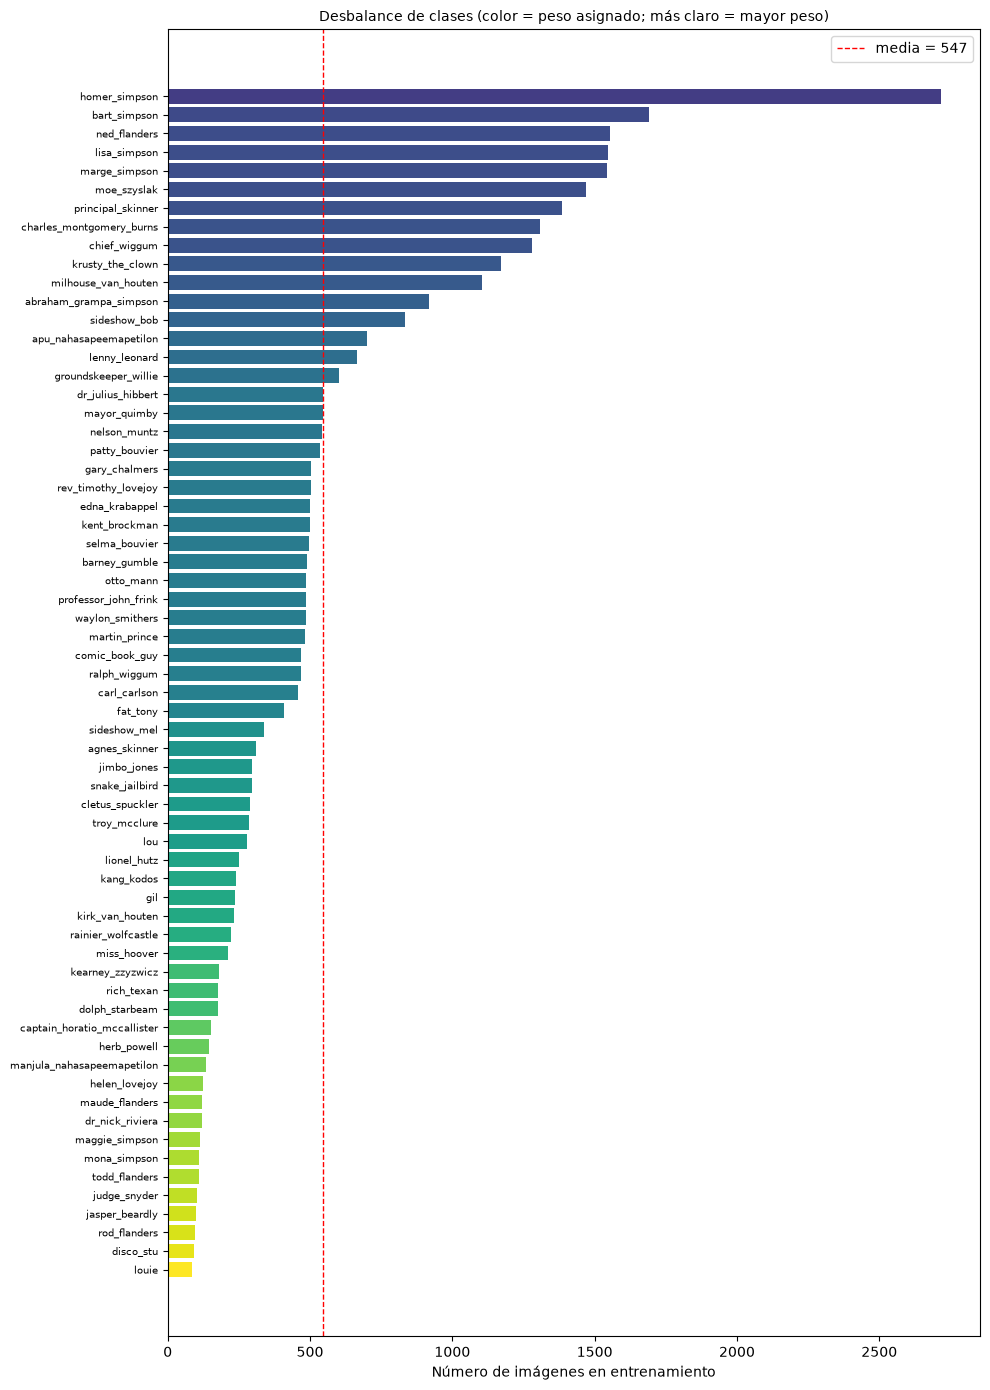

In [101]:
import matplotlib

# Distribución de imágenes por personaje en el conjunto de entrenamiento
figura, eje = plt.subplots(figsize=(10, 14))

orden = np.argsort(conteos_train)
eje.barh(
    [clases[i] for i in orden],
    conteos_train[orden],
    color=matplotlib.colormaps["viridis"](pesos[orden] / pesos.max()),
)
eje.set_xlabel("Número de imágenes en entrenamiento")
eje.set_title("Desbalance de clases (color = peso asignado; más claro = mayor peso)", fontsize=10)
eje.tick_params(axis="y", labelsize=7)
eje.axvline(
    conteos_train.mean(),
    color="red",
    linestyle="--",
    linewidth=1,
    label=f"media = {conteos_train.mean():.0f}",
)
eje.legend()

plt.tight_layout()
plt.show()


## Fundamentos: estructura de una red neuronal profunda

### Capas y neuronas

**Qué es una neurona**

La unidad básica de la red es la neurona artificial, inspirada de forma muy simplificada en la neurona
biológica: recibe varias señales de entrada, las combina dando más importancia a unas que a otras y
produce una única señal de salida. Toda su "inteligencia" está en esos pesos, que son números que se
ajustan durante el entrenamiento.

**Cómo se organizan en capas**

Las neuronas no trabajan sueltas, sino agrupadas en capas, y cada capa recibe como entrada la salida de
la anterior. Una red **densa** o *fully connected* es aquella en la que cada neurona de una capa se
conecta con **todas** las neuronas de la capa siguiente. Un Perceptrón Multicapa es exactamente eso:
una pila de capas densas.

| Capa | Papel en la red | En este proyecto |
|---|---|---|
| **Entrada** | No calcula nada; solo define la forma del dato que entra | Unos 2.460 descriptores de color y textura en el modelo base; 49 152 píxeles en el experimento R1 |
| **Ocultas** | Transforman progresivamente la entrada en representaciones más útiles para separar las clases | Una o varias capas densas con activación ReLU |
| **Salida** | Produce la predicción en el formato del problema | 64 neuronas con softmax, una por personaje |

**Por qué "profunda" y qué aprenden las capas ocultas**

Se llama profunda a una red con más de una capa oculta. La idea es que la composición de capas construye
una **jerarquía de representaciones**: la primera capa detecta patrones muy simples a partir de los
píxeles (zonas de color, contrastes), y cada capa posterior combina los patrones de la anterior en
conceptos más abstractos que, idealmente, terminan siendo características discriminantes entre
personajes. Ninguna de esas características se programa: emergen del ajuste de los pesos.

Se las llama "ocultas" simplemente porque no se observan desde fuera; solo vemos lo que entra y lo que
sale de la red.

**Ancho, profundidad y su costo**

Dos decisiones de diseño definen la arquitectura:

- **Profundidad** (cuántas capas ocultas): más capas permiten representar funciones más complejas, pero
  dificultan el entrenamiento y aumentan el riesgo de sobreajuste.
- **Ancho** (cuántas neuronas por capa): más neuronas dan más capacidad a cada nivel, a costa de muchos
  más parámetros.

Ese costo depende sobre todo de la entrada. Como la conexión es total, la primera capa oculta concentra
la mayoría de los parámetros, y su tamaño es proporcional a la dimensión de la entrada: 49 152
valores con píxeles, unos 2.460 con descriptores. La siguiente celda lo cuantifica para las dos.


In [102]:
# Cuántos parámetros implica cada elección de ancho en la primera capa oculta,
# con la entrada de píxeles y con la de descriptores
anchos_posibles = [64, 128, 256, 512, 1024]
entradas = {"pixeles": DIMENSION_PIXELES, REPRESENTACION_BASE: DIMENSION_ENTRADA}

tabla_costo = pd.DataFrame({"neuronas_capa_1": anchos_posibles})
for nombre, dimension in entradas.items():
    # pesos (entrada x neuronas) + un sesgo por neurona
    tabla_costo[f"capa_1 ({nombre})"] = [dimension * n + n for n in anchos_posibles]
tabla_costo["parametros_salida"] = [n * NUMERO_CLASES + NUMERO_CLASES for n in anchos_posibles]
tabla_costo["reduccion_capa_1"] = (
    tabla_costo["capa_1 (pixeles)"] / tabla_costo[f"capa_1 ({REPRESENTACION_BASE})"]
).round(1)

display(tabla_costo)

print(f"Entrada con pixeles      : {DIMENSION_PIXELES} valores")
print(f"Entrada con descriptores : {DIMENSION_ENTRADA} valores")
print(f"Neuronas de salida       : {NUMERO_CLASES} (una por personaje)")
print(
    "\nCon pixeles, la primera capa oculta concentra casi todos los parametros: es la unica"
    f"\nconectada al vector de entrada. Con descriptores la entrada es {DIMENSION_PIXELES / DIMENSION_ENTRADA:.0f}"
    " veces mas corta y esa capa se reduce en la misma proporcion."
)

,neuronas_capa_1,capa_1 (pixeles),capa_1 (color_textura),parametros_salida,reduccion_capa_1
0,64,196672,157632,4160,1.2
1,128,393344,315264,8256,1.2
2,256,786688,630528,16448,1.2
3,512,1573376,1261056,32832,1.2
4,1024,3146752,2522112,65600,1.2


Entrada con pixeles      : 3072 valores
Entrada con descriptores : 2462 valores
Neuronas de salida       : 64 (una por personaje)

Con pixeles, la primera capa oculta concentra casi todos los parametros: es la unica
conectada al vector de entrada. Con descriptores la entrada es 1 veces mas corta y esa capa se reduce en la misma proporcion.


### Pesos, sesgos y propagación hacia adelante

**El cálculo de una neurona**

Cada neurona hace siempre lo mismo, en dos pasos:

1. **Combinación lineal (preactivación).** Multiplica cada entrada por su peso, suma todo y añade el
   sesgo:

   $$z = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b = \mathbf{w} \cdot \mathbf{x} + b$$

2. **Activación.** Pasa ese número por una función no lineal: $a = f(z)$.

**Qué significan los pesos y el sesgo**

- El **peso** $w_i$ mide cuánto influye la entrada $x_i$ en esta neurona. Un peso grande y positivo
  indica que esa entrada empuja a la neurona a activarse; uno negativo, que la inhibe; uno cercano a cero,
  que esa entrada le resulta irrelevante. Con píxeles, cada peso de la primera capa está asociado a un
  canal de color de un píxel concreto; con descriptores, a un intervalo de un histograma o a la
  respuesta de un filtro en una zona de la imagen.
- El **sesgo** $b$ desplaza el umbral de activación. Sin él, toda neurona estaría obligada a dar 0 cuando
  la entrada es 0, y todas las fronteras de decisión tendrían que pasar por el origen. El sesgo le da
  libertad para activarse aun con entradas débiles, o para exigir una evidencia mayor.

**Pesos y sesgos son lo que el modelo aprende.** Todo lo demas -- número de capas, neuronas, activaciones,
learning rate -- lo fijamos nosotros antes de entrenar y por eso se llaman hiperparámetros. Los parámetros
propiamente dichos son estos números, que empiezan con valores aleatorios pequeños y se van corrigiendo.

**De una neurona a una capa: forma matricial**

Escribir el cálculo neurona por neurona sería impracticable. Como todas las neuronas de una capa hacen la
misma operación sobre la misma entrada, se agrupan sus pesos en una matriz $W$ y sus sesgos en un vector
$\mathbf{b}$, y la capa entera se calcula de un golpe:

$$\mathbf{a}^{(l)} = f\left(\mathbf{a}^{(l-1)} W^{(l)} + \mathbf{b}^{(l)}\right)$$

Esto no es solo notación elegante: es lo que permite procesar un **batch** completo de imágenes en una
sola multiplicación de matrices, que es justo la operación que GPU y CPU ejecutan de forma optimizada.

**Propagación hacia adelante (forward pass)**

Se llama así al recorrido completo: la imagen entra como vector, cada capa aplica su transformación y
pasa el resultado a la siguiente, hasta que la capa de salida produce las 64 probabilidades. Es lo que
ocurre cada vez que el modelo predice, y también el primer paso de cada iteración de entrenamiento: sin
saber qué predijo la red no se puede medir cuánto se equivocó.

La celda siguiente reproduce ese recorrido a mano con NumPy, sobre una imagen real del dataset, para ver
las formas de cada matriz y comprobar que la salida es una distribución de probabilidad.


In [103]:
# Forward pass "a mano" con una arquitectura mínima: DIMENSION_PIXELES -> 64 -> NUMERO_CLASES
generador_pesos = np.random.default_rng(SEMILLA)
NEURONAS_DEMO = 64


def inicializar_capa(entradas, neuronas):
    """Pesos pequeños aleatorios (escala de He, la que usa Keras con ReLU) y sesgos a cero."""
    W = generador_pesos.normal(0, np.sqrt(2 / entradas), size=(entradas, neuronas)).astype(np.float32)
    b = np.zeros(neuronas, dtype=np.float32)
    return W, b


W1, b1 = inicializar_capa(DIMENSION_PIXELES, NEURONAS_DEMO)
W2, b2 = inicializar_capa(NEURONAS_DEMO, NUMERO_CLASES)

# Una imagen real del conjunto de entrenamiento como vector de píxeles, escalada a
# [0, 1] igual que hace la capa Rescaling dentro del modelo. La demostración usa
# píxeles porque se pueden volver a dibujar como imagen; con descriptores el
# recorrido es idéntico, solo cambia la longitud del vector de entrada.
entrada = np.asarray(X[np.flatnonzero(MASCARAS["train"])[0]], dtype=np.float32) / VALOR_MAXIMO_PIXEL

# Capa oculta: combinación lineal + ReLU
z1 = entrada @ W1 + b1
a1 = np.maximum(0, z1)

# Capa de salida: combinación lineal + softmax (se resta el máximo por estabilidad numérica)
z2 = a1 @ W2 + b2
exponenciales = np.exp(z2 - z2.max())
salida = exponenciales / exponenciales.sum()

recorrido = pd.DataFrame(
    [
        ("entrada (imagen aplanada)", str(entrada.shape), entrada.size),
        ("W1 (pesos capa oculta)", str(W1.shape), W1.size),
        ("b1 (sesgos capa oculta)", str(b1.shape), b1.size),
        ("z1 = entrada @ W1 + b1", str(z1.shape), z1.size),
        ("a1 = ReLU(z1)", str(a1.shape), a1.size),
        ("W2 (pesos capa salida)", str(W2.shape), W2.size),
        ("b2 (sesgos capa salida)", str(b2.shape), b2.size),
        ("z2 = a1 @ W2 + b2", str(z2.shape), z2.size),
        ("salida = softmax(z2)", str(salida.shape), salida.size),
    ],
    columns=["Paso", "Forma", "Número de valores"],
)

display(recorrido)

print(f"Parametros entrenables de esta red minima: {W1.size + b1.size + W2.size + b2.size:,}")

,Paso,Forma,Número de valores
0,entrada (imagen aplanada),"(3072,)",3072
1,W1 (pesos capa oculta),"(3072, 64)",196608
2,b1 (sesgos capa oculta),"(64,)",64
3,z1 = entrada @ W1 + b1,"(64,)",64
4,a1 = ReLU(z1),"(64,)",64
5,W2 (pesos capa salida),"(64, 64)",4096
6,b2 (sesgos capa salida),"(64,)",64
7,z2 = a1 @ W2 + b2,"(64,)",64
8,salida = softmax(z2),"(64,)",64


Parametros entrenables de esta red minima: 200,832


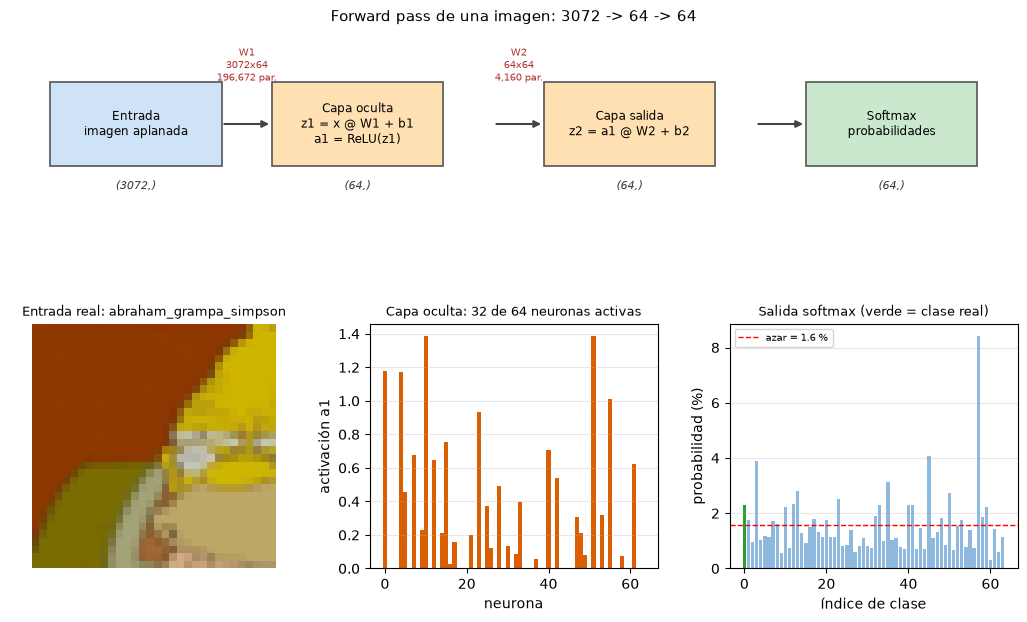


Sin entrenar, la red predice 'selma_bouvier' con 8.4 % de confianza,
cuando la clase real es 'abraham_grampa_simpson', a la que asigna solo 2.3 %.

El reparto responde unicamente a los pesos aleatorios, no a la imagen: la referencia de azar es 1.6 %.

Entrenar consiste en ajustar W1, b1, W2 y b2 para que la barra verde crezca y las demas bajen.



In [104]:
# Recorrido de la señal a través de la red, paso a paso
figura = plt.figure(figsize=(13, 7))
malla = figura.add_gridspec(2, 3, height_ratios=[1, 1.25], hspace=0.45, wspace=0.25)

# --- Fila superior: esquema del flujo de datos con las formas de cada tensor ---
esquema = figura.add_subplot(malla[0, :])
esquema.set_xlim(0, 10)
esquema.set_ylim(0, 3)
esquema.axis("off")

bloques = [
    (0.4, "Entrada\nimagen aplanada", f"({DIMENSION_PIXELES},)", "#cfe3f7"),
    (2.6, "Capa oculta\nz1 = x @ W1 + b1\na1 = ReLU(z1)", f"({NEURONAS_DEMO},)", "#ffe0b3"),
    (5.3, "Capa salida\nz2 = a1 @ W2 + b2", f"({NUMERO_CLASES},)", "#ffe0b3"),
    (7.9, "Softmax\nprobabilidades", f"({NUMERO_CLASES},)", "#c9e8cd"),
]

for x, texto, forma, color in bloques:
    esquema.add_patch(
        plt.Rectangle((x, 0.9), 1.7, 1.3, facecolor=color, edgecolor="#555", linewidth=1.2)
    )
    esquema.text(x + 0.85, 1.55, texto, ha="center", va="center", fontsize=8.5)
    esquema.text(x + 0.85, 0.6, forma, ha="center", va="center", fontsize=8, style="italic", color="#333")

pesos_entre = [
    (2.1, f"W1\n{W1.shape[0]}x{W1.shape[1]}\n{W1.size + b1.size:,} par."),
    (4.8, f"W2\n{W2.shape[0]}x{W2.shape[1]}\n{W2.size + b2.size:,} par."),
    (7.4, ""),
]
for x, etiqueta in pesos_entre:
    esquema.annotate(
        "",
        xy=(x + 0.5, 1.55),
        xytext=(x, 1.55),
        arrowprops=dict(arrowstyle="-|>", linewidth=1.5, color="#444"),
    )
    if etiqueta:
        esquema.text(x + 0.25, 2.45, etiqueta, ha="center", va="center", fontsize=7.5, color="#b03030")

esquema.set_title(
    f"Forward pass de una imagen: {DIMENSION_PIXELES} -> {NEURONAS_DEMO} -> {NUMERO_CLASES}",
    fontsize=11,
)

# --- Abajo izquierda: la imagen que entra a la red ---
eje_imagen = figura.add_subplot(malla[1, 0])
eje_imagen.imshow(entrada.reshape(ALTO_OBJETIVO, ANCHO_OBJETIVO, 3))
eje_imagen.set_title(f"Entrada real: {clases[int(y_train_idx[0])]}", fontsize=9)
eje_imagen.axis("off")

# --- Abajo centro: activaciones de la capa oculta ---
eje_ocultas = figura.add_subplot(malla[1, 1])
colores_ocultas = ["#d95f02" if valor > 0 else "#bbbbbb" for valor in a1]
eje_ocultas.bar(range(NEURONAS_DEMO), a1, color=colores_ocultas, width=1.0)
eje_ocultas.set_title(
    f"Capa oculta: {(a1 > 0).sum()} de {NEURONAS_DEMO} neuronas activas", fontsize=9
)
eje_ocultas.set_xlabel("neurona")
eje_ocultas.set_ylabel("activación a1")
eje_ocultas.grid(alpha=0.3, axis="y")

# --- Abajo derecha: distribución de probabilidad de salida ---
eje_salida = figura.add_subplot(malla[1, 2])
clase_real = int(y_train_idx[0])
colores_salida = ["#2ca02c" if i == clase_real else "#8fb8de" for i in range(NUMERO_CLASES)]
eje_salida.bar(range(NUMERO_CLASES), salida * 100, color=colores_salida)
eje_salida.axhline(
    100 / NUMERO_CLASES,
    color="red",
    linestyle="--",
    linewidth=1,
    label=f"azar = {100 / NUMERO_CLASES:.1f} %",
)
eje_salida.set_title("Salida softmax (verde = clase real)", fontsize=9)
eje_salida.set_xlabel("índice de clase")
eje_salida.set_ylabel("probabilidad (%)")
eje_salida.legend(fontsize=7)
eje_salida.grid(alpha=0.3, axis="y")

plt.show()

print(f"""
Sin entrenar, la red predice '{clases[int(salida.argmax())]}' con {salida.max() * 100:.1f} % de confianza,
cuando la clase real es '{clases[clase_real]}', a la que asigna solo {salida[clase_real] * 100:.1f} %.
    
El reparto responde unicamente a los pesos aleatorios, no a la imagen: la referencia de azar es {100 / NUMERO_CLASES:.1f} %.
    
Entrenar consiste en ajustar W1, b1, W2 y b2 para que la barra verde crezca y las demas bajen.
""")


### Funciones de activación

**Por qué hace falta la no linealidad**

Si se quitaran las funciones de activación, cada capa sería solo una multiplicación de matrices y la red
entera colapsaría en una sola: la composición de funciones lineales es otra función lineal. Una red de
diez capas sin activaciones tendría exactamente el mismo poder expresivo que una regresión lineal, y sería
incapaz de separar clases que no se puedan dividir con un hiperplano. La activación no lineal es lo que
permite que apilar capas sirva de algo.

**Comparación de las activaciones para las capas ocultas**

| Función | Fórmula | Rango | Ventaja | Problema |
|---|---|---|---|---|
| **Sigmoide** | $1/(1+e^{-z})$ | (0, 1) | Interpretable como probabilidad | Se satura: para $\|z\|$ grande el gradiente tiende a 0 y el aprendizaje se detiene |
| **Tanh** | $(e^z-e^{-z})/(e^z+e^{-z})$ | (-1, 1) | Centrada en cero, converge mejor que la sigmoide | También se satura en los extremos |
| **ReLU** | $\max(0, z)$ | [0, inf) | Gradiente constante 1 para $z>0$: no se satura; muy barata de calcular; produce activaciones dispersas | "Neuronas muertas": si una unidad queda siempre en $z<0$, su gradiente es 0 y no vuelve a aprender |

**Elección: ReLU en las capas ocultas.** El problema de la saturación es decisivo. En una red profunda,
los gradientes se multiplican capa a capa al retropropagarse; si cada factor es menor que 1 -- como pasa
con sigmoide, cuya derivada máxima es 0,25 -- el gradiente se desvanece antes de llegar a las primeras
capas, que son justamente las que deben aprender de los píxeles. ReLU mantiene el gradiente en 1 en toda
su zona activa, y además su cálculo es una simple comparación, lo que acelera el entrenamiento. Es el
valor por defecto razonable para capas ocultas, y de ahí partimos.

**Elección: softmax en la salida.** La capa final no busca una no linealidad cualquiera, sino convertir 64
números sin escala definida en una distribución de probabilidad:

$$\text{softmax}(z_i) = \frac{e^{z_i}}{\sum_{j=1}^{64} e^{z_j}}$$

Sus dos propiedades son las que necesita un problema multiclase de etiqueta única: todas las salidas son
positivas y **suman exactamente 1**. Eso introduce competencia entre clases -- si sube la probabilidad de
un personaje, baja la de los demas -- que es correcto aquí, porque cada imagen tiene un único personaje.
Si el problema fuera multietiqueta habría que usar sigmoides independientes en la salida.


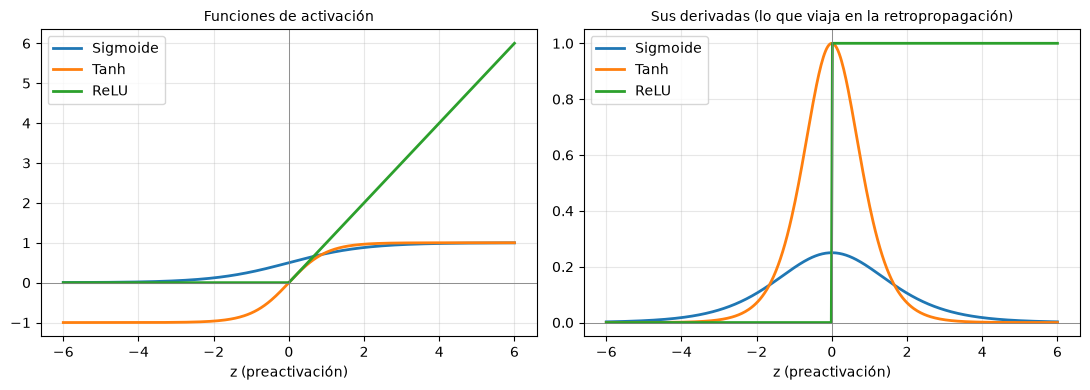

En el gráfico de la derecha se ve el problema de la saturación: las derivadas de sigmoide y tanh
caen a cero en los extremos (el gradiente se desvanece), mientras que la de ReLU vale 1 para
todo z > 0. Nótese además que la derivada de la sigmoide no supera 0.25.


In [105]:
z = np.linspace(-6, 6, 400)

activaciones = {
    "Sigmoide": (1 / (1 + np.exp(-z)), lambda s: s * (1 - s)),
    "Tanh": (np.tanh(z), lambda s: 1 - s ** 2),
    "ReLU": (np.maximum(0, z), lambda s: (z > 0).astype(float)),
}

figura, ejes = plt.subplots(1, 2, figsize=(11, 4))

for nombre, (valores, derivada) in activaciones.items():
    ejes[0].plot(z, valores, label=nombre, linewidth=2)
    ejes[1].plot(z, derivada(valores), label=nombre, linewidth=2)

ejes[0].set_title("Funciones de activación", fontsize=10)
ejes[1].set_title("Sus derivadas (lo que viaja en la retropropagación)", fontsize=10)

for eje in ejes:
    eje.axhline(0, color="gray", linewidth=0.6)
    eje.axvline(0, color="gray", linewidth=0.6)
    eje.set_xlabel("z (preactivación)")
    eje.grid(alpha=0.3)
    eje.legend()

plt.tight_layout()
plt.show()

print(
    "En el gráfico de la derecha se ve el problema de la saturación: las derivadas de sigmoide y tanh"
    "\ncaen a cero en los extremos (el gradiente se desvanece), mientras que la de ReLU vale 1 para"
    "\ntodo z > 0. Nótese además que la derivada de la sigmoide no supera 0.25."
)


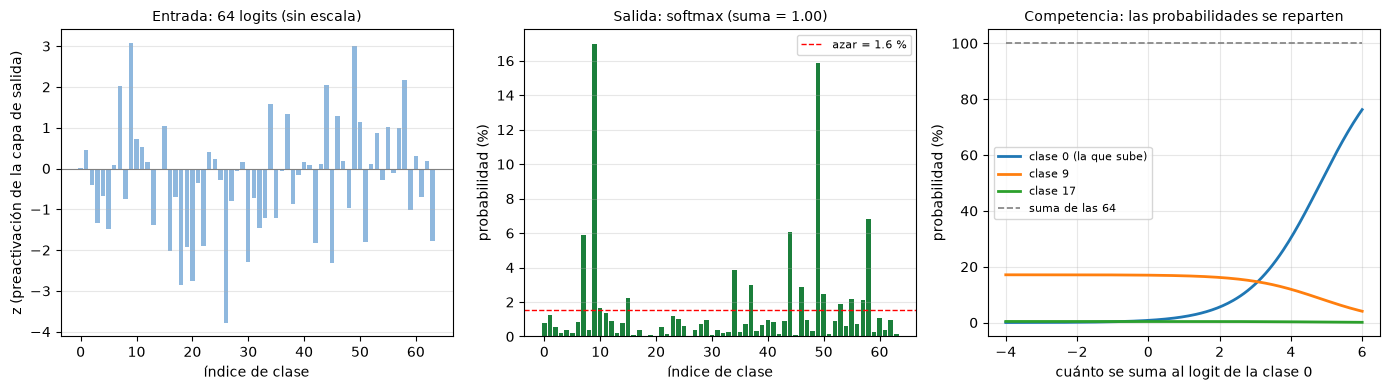

Softmax no se puede dibujar junto a ReLU o tanh porque no transforma un número en otro:
toma el vector completo de logits y devuelve una distribución. El denominador -- la suma
de todas las exponenciales -- es lo que acopla las salidas entre si.

Clase predicha: 9 con 17.0 % de probabilidad   |   suma de las 64 salidas = 1.000000
En el gráfico de la derecha se ve la propiedad clave para etiqueta única: al crecer el logit
de una clase, su probabilidad sube y la de las demas baja, mientras la suma se mantiene en 100 %.


In [106]:
# Softmax se gráfica aparte: no es una activación elemento a elemento como las anteriores,
# sino una función vectorial que mira todas las salidas a la vez y las convierte en una distribución.
generador = np.random.default_rng(7)
logits_demo = generador.normal(0, 1.5, NUMERO_CLASES)
logits_demo[min(9, NUMERO_CLASES - 1)] += 4.0  # una clase claramente favorecida por la red


def softmax(z, temperatura=1.0):
    """Softmax numéricamente estable: se resta el máximo antes de exponenciar."""
    escalado = np.asarray(z, dtype=float) / temperatura
    exponenciales = np.exp(escalado - escalado.max())
    return exponenciales / exponenciales.sum()


probabilidades_demo = softmax(logits_demo)

figura, ejes = plt.subplots(1, 3, figsize=(14, 4))

# 1. Los logits: números sin escala definida, positivos y negativos
ejes[0].bar(range(NUMERO_CLASES), logits_demo, color="#8fb8de")
ejes[0].axhline(0, color="gray", linewidth=0.8)
ejes[0].set_title(f"Entrada: {NUMERO_CLASES} logits (sin escala)", fontsize=10)
ejes[0].set_ylabel("z (preactivación de la capa de salida)")

# 2. La misma información después de softmax: probabilidades que suman 1
ejes[1].bar(range(NUMERO_CLASES), probabilidades_demo * 100, color="#1b7f3b")
ejes[1].axhline(
    100 / NUMERO_CLASES,
    color="red",
    linestyle="--",
    linewidth=1,
    label=f"azar = {100 / NUMERO_CLASES:.1f} %",
)
ejes[1].set_title(
    f"Salida: softmax (suma = {probabilidades_demo.sum():.2f})", fontsize=10
)
ejes[1].set_ylabel("probabilidad (%)")
ejes[1].legend(fontsize=8)

for eje in ejes[:2]:
    eje.set_xlabel("índice de clase")
    eje.grid(alpha=0.3, axis="y")

# 3. La competencia entre clases: subir el logit de una hunde a todas las demas
desplazamientos = np.linspace(-4, 6, 200)
seguidas = sorted({0, min(9, NUMERO_CLASES - 1), min(17, NUMERO_CLASES - 1)})  # clases a seguir
curvas = np.array(
    [softmax(np.concatenate(([logits_demo[0] + d], logits_demo[1:]))) for d in desplazamientos]
)

for indice in seguidas:
    ejes[2].plot(
        desplazamientos,
        curvas[:, indice] * 100,
        linewidth=2,
        label=f"clase {indice}" + (" (la que sube)" if indice == 0 else ""),
    )

ejes[2].plot(
    desplazamientos,
    curvas.sum(axis=1) * 100,
    color="gray",
    linestyle="--",
    linewidth=1.2,
    label=f"suma de las {NUMERO_CLASES}",
)
ejes[2].set_title("Competencia: las probabilidades se reparten", fontsize=10)
ejes[2].set_xlabel("cuánto se suma al logit de la clase 0")
ejes[2].set_ylabel("probabilidad (%)")
ejes[2].grid(alpha=0.3)
ejes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

print(
    "Softmax no se puede dibujar junto a ReLU o tanh porque no transforma un número en otro:"
    "\ntoma el vector completo de logits y devuelve una distribución. El denominador -- la suma"
    "\nde todas las exponenciales -- es lo que acopla las salidas entre si."
)
print(
    f"\nClase predicha: {int(probabilidades_demo.argmax())} con {probabilidades_demo.max() * 100:.1f} %"
    f" de probabilidad   |   suma de las {NUMERO_CLASES} salidas = {probabilidades_demo.sum():.6f}"
)
print(
    "En el gráfico de la derecha se ve la propiedad clave para etiqueta única: al crecer el logit"
    "\nde una clase, su probabilidad sube y la de las demas baja, mientras la suma se mantiene en 100 %."
)


### Función de pérdida, backpropagation y optimizador

El forward pass produce una predicción, pero por sí solo no enseña nada. El aprendizaje necesita tres
piezas más: una forma de **medir** el error, una forma de **repartir la culpa** de ese error entre los
parámetros, y una **regla** para corregirlos.

**1. Función de pérdida: entropía cruzada categórica**

Mide la distancia entre la distribución predicha por softmax y el vector one-hot real. Como el one-hot
tiene un 1 en la clase correcta y 0 en el resto, la suma se reduce a un único término:

$$L = -\sum_{i=1}^{64} y_i \log(\hat{y}_i) = -\log(\hat{y}_{\text{clase correcta}})$$

Es decir: la pérdida de un ejemplo depende **solo de la probabilidad que la red asignó a la clase
verdadera**. Si le dio 0,99, la pérdida es casi 0; si le dio 0,01, la pérdida se dispara. Ese crecimiento
logarítmico penaliza con dureza los errores cometidos con mucha confianza, que es el comportamiento
deseable. La pérdida del batch es el promedio de las pérdidas individuales -- y es ahí donde `class_weight`
interviene, ponderando cada término según la frecuencia de su clase.

Por qué no usar accuracy como función a minimizar: el accuracy es escalonado, su gradiente es cero en casi
todas partes y no distingue entre acertar con 0,51 o con 0,99. Sirve para interpretar resultados, no para
optimizar. Por eso se monitorean ambos: se **optimiza** la pérdida y se **lee** el accuracy.

**2. Backpropagation: de dónde viene el error**

Conocida la pérdida, hace falta saber cuánto contribuyó cada uno de los parámetros. Eso es la derivada
parcial $\partial L / \partial w$, y calcularla directamente para cientos de miles de pesos sería
inviable. La retropropagación lo resuelve aplicando la **regla de la cadena** en sentido inverso: parte
del error en la salida y lo propaga hacia atras capa por capa, reutilizando en cada paso lo ya calculado
en la capa posterior. Esto es lo que hace posible entrenar redes grandes, y también la razón de que la
derivada de la activación importe tanto: aparece como factor multiplicativo en cada capa que se atraviesa
(de ahí el desvanecimiento del gradiente con sigmoide y la ventaja de ReLU).

El resultado es el **gradiente**: un vector que indica, para cada parámetro, en qué dirección habría que
moverlo para que la pérdida aumente. Se avanza en la dirección contraria.

**3. Optimizador: cómo se corrigen los pesos**

La regla básica es el **descenso del gradiente**:

$$w \leftarrow w - \eta \frac{\partial L}{\partial w}$$

donde $\eta$ es la **tasa de aprendizaje** (learning rate), el tamaño del paso. Demasiado grande y el
entrenamiento oscila o diverge; demasiado pequeño y avanza con una lentitud inútil. En la práctica no se
calcula el gradiente sobre todo el dataset (caro) ni sobre un solo ejemplo (ruidoso), sino sobre **batches**
de unas decenas o centenas de imágenes: es el descenso del gradiente por mini-lotes. Una **época** es una
pasada completa por el conjunto de entrenamiento, es decir, muchas actualizaciones de pesos.

**Elección: Adam.** Mejora el descenso del gradiente clásico en dos aspectos: acumula un **momento** de los
gradientes anteriores, lo que suaviza las oscilaciones, y adapta el tamaño del paso **para cada parámetro**
según la magnitud típica de su gradiente. En la práctica converge más rápido y es mucho menos sensible a
la elección inicial del learning rate, razón por la que se usa como punto de partida en la mayoría de los
trabajos. Se parte de su valor por defecto, 0,001, y su efecto se contrasta en la experimentación.

**El ciclo completo de entrenamiento**

Para cada batch, y repitiendolo época tras época:

`forward pass` -> `calcular la perdida` -> `backpropagation` -> `el optimizador actualiza los pesos`


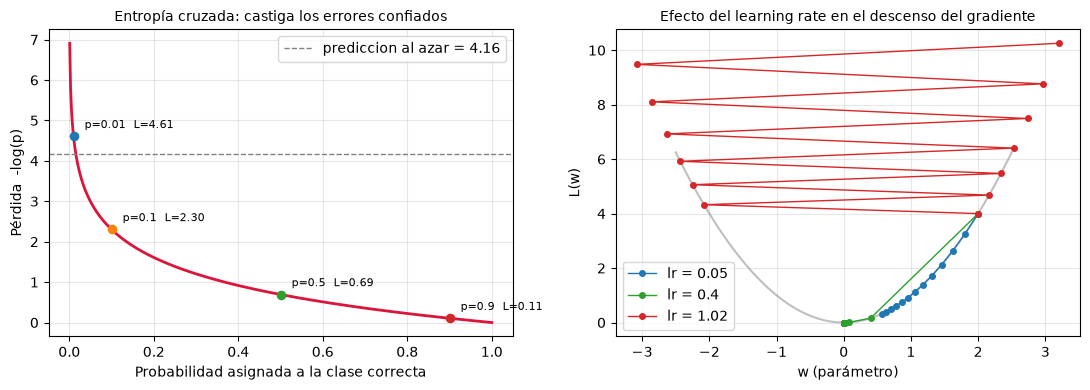

Perdida esperada de un modelo sin entrenar (1/64 a cada clase): 4.159
Es el valor de referencia con el que debería arrancar el entrenamiento en la primera época.

En el gráfico de la derecha: un lr pequeño (azul) converge pero lento, uno adecuado (verde)
llega rápido al mínimo, y uno demasiado grande (rojo) se aleja y diverge.


In [107]:
# Pérdida de un ejemplo según la probabilidad asignada a la clase correcta
probabilidades = np.linspace(0.001, 1.0, 500)
perdidas = -np.log(probabilidades)

figura, ejes = plt.subplots(1, 2, figsize=(11, 4))

ejes[0].plot(probabilidades, perdidas, color="crimson", linewidth=2)
ejes[0].set_xlabel("Probabilidad asignada a la clase correcta")
ejes[0].set_ylabel("Pérdida  -log(p)")
ejes[0].set_title("Entropía cruzada: castiga los errores confiados", fontsize=10)
ejes[0].grid(alpha=0.3)

for probabilidad in (0.01, 0.1, 0.5, 0.9):
    ejes[0].scatter([probabilidad], [-np.log(probabilidad)], zorder=3, s=35)
    ejes[0].annotate(
        f"p={probabilidad}  L={-np.log(probabilidad):.2f}",
        (probabilidad, -np.log(probabilidad)),
        textcoords="offset points",
        xytext=(8, 6),
        fontsize=8,
    )

# Referencias del problema: pérdida esperada al predecir al azar entre todas las clases
perdida_azar = -np.log(1 / NUMERO_CLASES)
ejes[0].axhline(
    perdida_azar,
    color="gray",
    linestyle="--",
    linewidth=1,
    label=f"prediccion al azar = {perdida_azar:.2f}",
)
ejes[0].legend()

# Efecto del learning rate sobre el descenso del gradiente en una parabola L(w) = w^2
ejes[1].plot(np.linspace(-2.5, 2.5, 200), np.linspace(-2.5, 2.5, 200) ** 2, color="gray", alpha=0.5)

for tasa, color in ((0.05, "tab:blue"), (0.4, "tab:green"), (1.02, "tab:red")):
    w = 2.0
    trayectoria = [w]
    for _ in range(12):
        w = w - tasa * 2 * w  # derivada de w^2
        trayectoria.append(w)
    trayectoria = np.array(trayectoria)
    ejes[1].plot(
        trayectoria,
        trayectoria ** 2,
        "o-",
        color=color,
        markersize=4,
        linewidth=1,
        label=f"lr = {tasa}",
    )

ejes[1].set_xlabel("w (parámetro)")
ejes[1].set_ylabel("L(w)")
ejes[1].set_title("Efecto del learning rate en el descenso del gradiente", fontsize=10)
ejes[1].grid(alpha=0.3)
ejes[1].legend()

plt.tight_layout()
plt.show()

print(f"Perdida esperada de un modelo sin entrenar (1/{NUMERO_CLASES} a cada clase): {perdida_azar:.3f}")
print("Es el valor de referencia con el que debería arrancar el entrenamiento en la primera época.")
print(
    "\nEn el gráfico de la derecha: un lr pequeño (azul) converge pero lento, uno adecuado (verde)"
    "\nllega rápido al mínimo, y uno demasiado grande (rojo) se aleja y diverge."
)


## Modelo base: Perceptrón Multicapa (MLP)

### Configuración y alcance de la implementación

El modelo base recibe el vector de **descriptores de color y textura** (unos 2.460 valores por imagen, calculados a 128 × 128) y tiene dos capas ocultas de **512 → 256** neuronas, ReLU, Batch Normalization y Dropout de 0,3. La salida tiene 64 neuronas con `softmax`; el entrenamiento usa `categorical_crossentropy` con suavizado de etiquetas de 0,1 y etiquetas de escena, Adam con tasa `1e-3`, batch de 128, hasta 60 épocas y pesos por clase suavizados (raíz cuadrada de los balanceados). Todos esos valores se declaran en las celdas de arquitectura, compilación y entrenamiento que siguen.

El modelo base no se presenta como una elección arbitraria. Se compara con tres variantes que cambian la representación de entrada (píxeles, solo color y solo textura), con seis que cambian una sola decisión de arquitectura u optimización (número de capas, activación, tasa de aprendizaje, batch o dropout) y con cinco que cambian el tratamiento de los datos (pesos por clase, suavizado, etiquetas de escena e imágenes alteradas). Al final, una configuración combina los cambios que mejoraron al modelo base. La regla de selección es el F1 macro de validación.

### Definición de la arquitectura

La arquitectura del modelo base traduce a código lo descrito en los fundamentos: una capa de entrada con
el vector de la representación elegida, dos capas ocultas densas con ReLU y una capa de salida softmax
con una neurona por personaje. Antes de las capas ocultas, la entrada se lleva a una escala común:

- **Píxeles:** `Rescaling(1/255)` lleva los valores de [0, 255] a [0, 1]. Los píxeles se guardan
  en `uint8` y el modelo los escala sobre cada lote.
- **Descriptores:** una capa `Normalization` resta a cada descriptor su media y lo divide por su
  desviación, ambas calculadas **solo con el conjunto de entrenamiento**. Al vivir dentro del modelo, el
  archivo `.keras` guardado recibe los descriptores tal como salen de `extraer_caracteristicas`.

Entre las capas ocultas se intercalan dos mecanismos de regularización:

- **Normalización por lotes (`BatchNormalization`).** Reescala las activaciones de cada capa para que
  mantengan una media y una varianza estables a lo largo del entrenamiento. Evita que la distribución que
  ve cada capa se desplace batch a batch, lo que permite usar una tasa de aprendizaje mayor y acelera la
  convergencia.
- **`Dropout`.** Durante el entrenamiento apaga al azar una fracción de las neuronas de la capa. Así
  ninguna neurona puede depender de la presencia de otra en particular y la red se ve obligada a
  distribuir la representación. Es la defensa principal contra el sobreajuste en una red densa con más
  de un millón de parámetros y unas 34.000 imágenes de entrenamiento.

La función `construir_mlp` deja como parámetros los factores que se modificarán en la experimentación
(representación de entrada, número y ancho de las capas ocultas, activación y tasa de dropout), de modo
que todas las configuraciones comparadas se generen exactamente con el mismo código.

In [108]:
import keras
from keras import layers

# Fija las semillas de Python, NumPy y PyTorch para que el entrenamiento sea reproducible
keras.utils.set_random_seed(SEMILLA)

NEURONAS_OCULTAS = (512, 256)
ACTIVACION = "relu"
TASA_DROPOUT = 0.3
# Suelo de la varianza al estandarizar: un intervalo de histograma casi siempre vacío
# tiene varianza casi nula y, sin este suelo, cualquier valor distinto de cero en
# validación o en test se amplificaría hasta valores enormes.
VARIANZA_MINIMA = 1e-4

_estadisticas = {}


def estadisticas_entrada(representacion):
    """Media y varianza de cada descriptor, calculadas SOLO con el conjunto de entrenamiento."""
    if representacion not in _estadisticas:
        entrenamiento = particion(representacion)["train"]
        _estadisticas[representacion] = (
            entrenamiento.mean(axis=0),
            np.maximum(entrenamiento.var(axis=0), VARIANZA_MINIMA),
        )
    return _estadisticas[representacion]


def construir_mlp(
    neuronas_ocultas=NEURONAS_OCULTAS,
    activacion=ACTIVACION,
    tasa_dropout=TASA_DROPOUT,
    representacion=REPRESENTACION_BASE,
    numero_clases=NUMERO_CLASES,
    nombre="mlp_base",
):
    """Construye un Perceptrón Multicapa: entrada (píxeles o descriptores) -> escala común ->
    capas ocultas densas (activación + BatchNorm + Dropout) -> salida softmax con una neurona por clase."""
    modelo = keras.Sequential(name=nombre)
    modelo.add(layers.Input(shape=(DIMENSIONES[representacion],), name="entrada"))
    if representacion == "pixeles":
        # El escalado a [0, 1] vive dentro del modelo: los píxeles se guardan en
        # uint8 (cuatro veces menos memoria) y se escalan sobre cada lote.
        modelo.add(layers.Rescaling(1.0 / 255, name="escalado"))
    else:
        media, varianza = estadisticas_entrada(representacion)
        modelo.add(layers.Normalization(mean=media, variance=varianza, name="estandarizacion"))

    for posicion, neuronas in enumerate(neuronas_ocultas, start=1):
        modelo.add(layers.Dense(neuronas, activation=activacion, name=f"oculta_{posicion}"))
        modelo.add(layers.BatchNormalization(name=f"norm_{posicion}"))
        modelo.add(layers.Dropout(tasa_dropout, name=f"dropout_{posicion}"))

    modelo.add(layers.Dense(numero_clases, activation="softmax", name="salida"))
    return modelo


modelo_base = construir_mlp()

modelo_base = modelo_base.to(DISPOSITIVO)

capas_texto = " -> ".join(str(n) for n in NEURONAS_OCULTAS)
print(f"Keras {keras.__version__} sobre backend {keras.backend.backend()}")
print(f"Entrada: {REPRESENTACION_BASE}, estandarizada con la media y la desviacion de train")
print(f"Arquitectura: {DIMENSION_ENTRADA} -> {capas_texto} -> {NUMERO_CLASES}")
print(f"Activacion oculta: {ACTIVACION}   |   Dropout: {TASA_DROPOUT}   |   Salida: softmax")

Keras 3.15.1 sobre backend torch
Entrada: color_textura, estandarizada con la media y la desviacion de train
Arquitectura: 2462 -> 512 -> 256 -> 64
Activacion oculta: relu   |   Dropout: 0.3   |   Salida: softmax


### Justificación técnica de la arquitectura y de los hiperparámetros iniciales

Cada decisión del modelo base responde al problema concreto ya descrito: unos 2.460 descriptores de
entrada, 64 clases desbalanceadas y unas 34.000 imágenes de entrenamiento (el 70 % de las originales de
cada personaje, más sus variantes alteradas).

| Hiperparámetro | Valor elegido | Justificación |
|---|---|---|
| **Entrada** | Descriptores de color y textura (`color_textura`) | Resumen la imagen en histogramas de color y de textura, menos sensibles al encuadre que los píxeles, y reducen la primera capa unas 20 veces. Los píxeles, el color solo y la textura sola se comparan en los experimentos R1–R3 |
| **Capas ocultas** | 2 | Con una sola capa la red es prácticamente un clasificador lineal sobre los descriptores; con muchas más, en un dataset de este tamaño el sobreajuste y el costo crecen más rápido que la ganancia. Dos capas permiten componer dos niveles de abstracción |
| **Neuronas por capa** | 512 y 256 | Un embudo decreciente: con unos 2.460 descriptores, la primera capa tiene ≈ 1,3 millones de parámetros, y la segunda refina esa representación antes de la salida. Reducir progresivamente obliga a la red a resumir en lugar de copiar la entrada |
| **Activación oculta** | ReLU | No se satura, su derivada vale 1 para z > 0 y es la más barata de calcular (ver "Funciones de activación"). Con sigmoide o tanh, dos capas ya bastan para que el gradiente empiece a atenuarse |
| **Activación de salida** | Softmax (64 neuronas) | Convierte las puntuaciones en una distribución de probabilidad que suma 1, que es la forma correcta para una clasificación multiclase de etiqueta única |
| **Dropout** | 0,3 | Valor intermedio: con más de un millón de parámetros para unas 34.000 imágenes el riesgo de memorización es alto, pero una tasa de 0,5 retrasa demasiado la convergencia |
| **BatchNormalization** | Tras cada capa oculta | Estabiliza la escala de las activaciones y permite un learning rate mayor sin que el entrenamiento se vuelva inestable |
| **Optimizador** | Adam | Adapta el paso por parámetro combinando momento y escalado según la magnitud histórica del gradiente. Con entradas de naturaleza muy distinta —histogramas, respuestas de filtro, gradientes— converge bastante más rápido que el SGD puro |
| **Tasa de aprendizaje** | 0,001 | Valor por defecto de Adam y punto de partida estándar; se contrasta explícitamente en la experimentación |
| **Función de pérdida** | Categorical crossentropy con suavizado 0,1 | Corresponde a etiquetas one-hot (o con escena) y salida softmax. El suavizado reparte el 10 % del objetivo entre todas las clases: el modelo deja de empujar sus probabilidades a 0 y 1, razonable cuando parte de las etiquetas es ambigua (escenas con varios personajes, Patty y Selma). El experimento S1 lo compara con el one-hot puro |
| **Tamaño de batch** | 128 | Compromiso entre el ruido del gradiente (batches pequeños) y la estabilidad y el aprovechamiento de memoria (batches grandes) |
| **`class_weight`** | Raíz cuadrada de los pesos balanceados | Compensa el desbalance de 33:1 sin anular a los personajes frecuentes; P1 y P2 comparan sin pesos y con los balanceados completos |

### Compilación del modelo

In [109]:
TASA_APRENDIZAJE = 1e-3
# Suavizado de etiquetas: fracción del objetivo de entrenamiento que se reparte entre todas las clases
SUAVIZADO_ETIQUETAS = 0.1


def compilar(modelo, tasa_aprendizaje=TASA_APRENDIZAJE):
    """Asocia al modelo la función de pérdida y las métricas.

    El entrenamiento NO usa `fit()`, sino el bucle propio de la sección siguiente.
    Se compila igualmente porque `predict()` y `evaluate()` sí se aprovechan: son
    llamadas puntuales sobre unos pocos miles de imágenes, donde el sobrecoste del
    bucle de Keras es irrelevante, y evitan reescribir código ya verificado."""
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=tasa_aprendizaje),
        loss="categorical_crossentropy",
        metrics=[
            keras.metrics.CategoricalAccuracy(name="accuracy"),
            keras.metrics.TopKCategoricalAccuracy(k=3, name="top_3"),
        ],
    )
    return modelo


compilar(modelo_base)

configuracion_base = pd.DataFrame(
    [
        ("Optimizador", "Adam"),
        ("Tasa de aprendizaje", TASA_APRENDIZAJE),
        ("Función de pérdida", "categorical_crossentropy"),
        ("Suavizado de etiquetas (solo entrenamiento)", SUAVIZADO_ETIQUETAS),
        ("Etiquetas de escena (solo entrenamiento)", f"{PESO_ESCENA:.0%} para los acompañantes"),
        ("Pesos por clase", ESQUEMA_PESOS),
        ("Metricas", "accuracy, top_3"),
        ("Neuronas ocultas", str(NEURONAS_OCULTAS)),
        ("Activación oculta", ACTIVACION),
        ("Dropout", TASA_DROPOUT),
        ("Neuronas de salida", NUMERO_CLASES),
    ],
    columns=["Elemento", "Valor"],
)

display(configuracion_base)

,Elemento,Valor
0,Optimizador,Adam
1,Tasa de aprendizaje,0.001
2,Función de pérdida,categorical_crossentropy
3,Suavizado de etiquetas (solo entrenamiento),0.1
4,Etiquetas de escena (solo entrenamiento),15% para los acompañantes
5,Pesos por clase,raiz
6,Metricas,"accuracy, top_3"
7,Neuronas ocultas,"(512, 256)"
8,Activación oculta,relu
9,Dropout,0.3


### Resumen del modelo

In [110]:
modelo_base.summary()

# Reparto de los parámetros entre las capas
detalle_capas = pd.DataFrame(
    [
        (
            capa.name,
            capa.__class__.__name__,
            str(capa.output.shape),
            int(sum(np.prod(peso.shape) for peso in capa.trainable_weights)),
        )
        for capa in modelo_base.layers
    ],
    columns=["capa", "tipo", "forma_salida", "parametros"],
)
detalle_capas["% del total"] = (
    detalle_capas["parametros"] / max(detalle_capas["parametros"].sum(), 1) * 100
).round(1)

display(detalle_capas)

total_parametros = int(detalle_capas["parametros"].sum())
print(f"Parametros entrenables: {total_parametros:,}")
print(f"Imagenes de entrenamiento: {len(X_train):,}")
print(f"Razon parametros / ejemplos: {total_parametros / len(X_train):.0f} a 1")
print(
    "\nLa primera capa oculta concentra la mayor parte de los parámetros porque es la única"
    f"\nconectada a los {DIMENSION_ENTRADA} valores del vector de entrada. Esa razon de"
    "\nparámetros por ejemplo es la que justifica el Dropout y la parada temprana."
)

Model: "mlp_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ estandarizacion (Normalization) │ (None, 2462)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_1 (Dense)                │ (None, 512)            │     1,261,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ norm_1 (BatchNormalization)     │ (None, 512)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ norm_2 (BatchNormalization)     │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 64)             │        16,448 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,411,904 (5.39 MB)

 Trainable params: 1,410,368 (5.38 MB)

 Non-trainable params: 1,536 (6.00 KB)

,capa,tipo,forma_salida,parametros,% del total
0,estandarizacion,Normalization,"(None, 2462)",0,0.0
1,oculta_1,Dense,"(None, 512)",1261056,89.4
2,norm_1,BatchNormalization,"(None, 512)",1024,0.1
3,dropout_1,Dropout,"(None, 512)",0,0.0
4,oculta_2,Dense,"(None, 256)",131328,9.3
5,norm_2,BatchNormalization,"(None, 256)",512,0.0
6,dropout_2,Dropout,"(None, 256)",0,0.0
7,salida,Dense,"(None, 64)",16448,1.2


Parametros entrenables: 1,410,368
Imagenes de entrenamiento: 35,023
Razon parametros / ejemplos: 40 a 1

La primera capa oculta concentra la mayor parte de los parámetros porque es la única
conectada a los 2462 valores del vector de entrada. Esa razon de
parámetros por ejemplo es la que justifica el Dropout y la parada temprana.


## Entrenamiento del modelo

### Configuración del entrenamiento

### Control del entrenamiento

El entrenamiento se controla con cuatro decisiones y tres mecanismos de parada y ajuste.

| Decisión | Valor | Por qué |
| --- | --- | --- |
| Épocas máximas | 60 | Techo generoso: quien decide cuándo parar es la parada temprana, no este número |
| Tamaño de lote | 128 | El mismo que usa la corrida de GPU, para que los tiempos sigan siendo comparables |
| Pesos por clase | Raíz cuadrada del `class_weight` balanceado | Compensa el desbalance de 33:1 sin anular a los personajes frecuentes |
| Suavizado de etiquetas | 0,1 | Solo en la pérdida de entrenamiento: la de validación usa la etiqueta estricta, así que la parada temprana se decide con la misma vara en todas las configuraciones |

**Dónde viven los datos.** Las matrices se convierten una sola vez en tensores de PyTorch: los
descriptores en `float32` y los píxeles del experimento R1 en `uint8`. En la CPU, `torch.as_tensor`
comparte la memoria del array de NumPy, así que la conversión no duplica las matrices, y cada paso toma su
lote directamente de ellas.

**El mismo bucle que en GPU.** El entrenamiento no usa `fit()`, sino la función `entrenar()` del notebook
de GPU: un `keras.Sequential` sobre el backend de PyTorch *es* un `torch.nn.Module`, así que el mismo
bucle corre en la CPU o en la GPU según dónde estén el modelo y los datos. En GPU se escribió para que la
tarjeta no esperara al intérprete de Python entre paso y paso; aquí se mantiene para que las dos corridas
hagan exactamente el mismo cálculo —el mismo suavizado de etiquetas, los mismos pesos por clase, los mismos
criterios de parada— y la comparación de tiempos mida solo el hardware.

La función `entrenar()` reproduce el comportamiento de los tres *callbacks* de Keras:

| Mecanismo | Qué hace | Por qué |
| --- | --- | --- |
| `EarlyStopping` | Detiene el entrenamiento si `val_loss` no mejora en 12 épocas y restaura los pesos de la mejor época | Evita seguir entrenando cuando el modelo ya solo memoriza |
| `ReduceLROnPlateau` | Divide el learning rate a la mitad si `val_loss` se estanca 4 épocas | Pasos grandes al principio y ajustes finos al final, cerca del mínimo |
| `ModelCheckpoint` | Guarda en `models/newDataset/` los pesos de la mejor época | Deja el modelo persistido en disco, reutilizable sin reentrenar |

**Por qué la paciencia es 12 y no 8.** La paciencia se fijó con el dataset anterior, cuya `val_loss` era
ruidosa: una época afortunada podía marcar un mínimo que tardaba mucho en repetirse, y la paciencia se
consumía esperándolo. Medido entonces sobre tres barajados distintos, la mejor `val_loss` alcanzada
mejora al pasar de 8 a 12 épocas de paciencia (1,9612 → 1,8735 en uno de ellos; 1,8892 → 1,8684 en otro)
y no mejora más al subir a 16.

El cambio es seguro por construcción: como los pesos devueltos son siempre los de la mejor época
(`restore_best_weights`), **esperar más nunca puede devolver un modelo peor**, solo gastar más épocas. En
CPU cada época cuesta más que en GPU, pero la paciencia es la misma para que las dos corridas sigan el mismo
proceso y sus resultados se puedan comparar.

In [111]:
import copy
import time
from pathlib import Path

import torch

EPOCAS_MAXIMAS = 60
TAMANO_BATCH = 128
DIRECTORIO_MODELOS = Path("../../models/newDataset")
DIRECTORIO_MODELOS.mkdir(parents=True, exist_ok=True)


class Historial:
    """Misma interfaz que el objeto que devuelve keras.Model.fit(): un atributo
    .history con un diccionario {metrica: [valor por epoca]}."""

    def __init__(self):
        self.history = {}

    def anotar(self, **metricas):
        for nombre, valor in metricas.items():
            self.history.setdefault(nombre, []).append(float(valor))


def _pasada(modelo, X, y, batch, entrenando, optimizador=None, pesos=None, generador=None, suavizado=0.0):
    """Recorre el conjunto una vez y devuelve (perdida, accuracy, top_3).

    Los acumuladores son tensores y se convierten a float una sola vez, al final de la
    pasada, igual que en el notebook de GPU.
    """
    modelo.train(entrenando)
    n = len(X)
    if entrenando:
        orden = torch.randperm(n, device=X.device, generator=generador)
    else:
        orden = torch.arange(n, device=X.device)

    suma_perdida = torch.zeros((), device=X.device)
    suma_top1 = torch.zeros((), device=X.device)
    suma_top3 = torch.zeros((), device=X.device)

    for i in range(0, n, batch):
        indices = orden[i:i + batch]
        lote_x, lote_y = X[indices], y[indices]
        objetivo = lote_y.argmax(1)
        if entrenando and suavizado:
            # Suavizado de etiquetas: solo al entrenar; validación mide con la etiqueta estricta
            lote_y = lote_y * (1 - suavizado) + suavizado / lote_y.shape[1]

        with torch.set_grad_enabled(entrenando):
            probabilidades = modelo(lote_x, training=entrenando)
            # Entropia cruzada categorica, muestra a muestra
            perdida_muestra = -(lote_y * torch.log(probabilidades.clamp_min(1e-7))).sum(1)
            if pesos is not None:
                # class_weight: cada ejemplo pesa segun su clase real
                perdida_muestra = perdida_muestra * pesos[objetivo]
            perdida = perdida_muestra.mean()

        if entrenando:
            optimizador.zero_grad(set_to_none=True)
            perdida.backward()
            optimizador.step()

        with torch.no_grad():
            suma_perdida += perdida_muestra.sum()
            suma_top1 += (probabilidades.argmax(1) == objetivo).sum()
            suma_top3 += (probabilidades.topk(3, dim=1).indices
                          == objetivo.unsqueeze(1)).any(1).sum()

    return (float(suma_perdida) / n, float(suma_top1) / n, float(suma_top3) / n)


def entrenar(
    modelo,
    X_entrena,
    y_entrena,
    X_valida,
    y_valida,
    epocas=EPOCAS_MAXIMAS,
    batch=TAMANO_BATCH,
    tasa_aprendizaje=TASA_APRENDIZAJE,
    pesos_por_clase=None,
    suavizado=SUAVIZADO_ETIQUETAS,
    paciencia=12,
    factor_lr=0.5,
    paciencia_lr=4,
    lr_minimo=1e-5,
    ruta_modelo=None,
    semilla=SEMILLA,
    verbose=2,
):
    """Entrena el modelo y devuelve un Historial equivalente al de model.fit().

    Reproduce los tres callbacks del notebook original: EarlyStopping con
    restore_best_weights, ReduceLROnPlateau y el guardado de la mejor epoca.
    """
    optimizador = torch.optim.Adam(modelo.parameters(), lr=tasa_aprendizaje, fused=True)

    generador = torch.Generator(device=X_entrena.device)
    generador.manual_seed(semilla)

    pesos = None
    if pesos_por_clase is not None:
        pesos = torch.tensor(
            [pesos_por_clase[i] for i in range(len(pesos_por_clase))],
            dtype=torch.float32, device=X_entrena.device,
        )

    historial = Historial()
    mejor_perdida = float("inf")
    mejor_epoca = 0
    sin_mejora_parada = 0
    sin_mejora_lr = 0
    mejores_pesos = None

    for epoca in range(1, epocas + 1):
        inicio = time.perf_counter()
        perdida, acierto, top3 = _pasada(
            modelo, X_entrena, y_entrena, batch, True, optimizador, pesos, generador, suavizado
        )
        val_perdida, val_acierto, val_top3 = _pasada(
            modelo, X_valida, y_valida, batch, False
        )
        duracion = time.perf_counter() - inicio

        historial.anotar(
            loss=perdida, accuracy=acierto, top_3=top3,
            val_loss=val_perdida, val_accuracy=val_acierto, val_top_3=val_top3,
            learning_rate=optimizador.param_groups[0]["lr"],
        )

        if val_perdida < mejor_perdida - 1e-6:
            mejor_perdida, mejor_epoca = val_perdida, epoca
            sin_mejora_parada = sin_mejora_lr = 0
            # Copia aparte de los mejores pesos: en la CPU .cpu() no copia nada, asi que
            # clone() es el que los separa de los parametros que siguen entrenando.
            mejores_pesos = {
                nombre: tensor.detach().cpu().clone()
                for nombre, tensor in modelo.state_dict().items()
            }
        else:
            sin_mejora_parada += 1
            sin_mejora_lr += 1

        if verbose >= 2:
            print(f"Epoca {epoca:3d}/{epocas}  {duracion:5.2f}s"
                  f"  loss={perdida:.4f}  acc={acierto:.4f}"
                  f"  val_loss={val_perdida:.4f}  val_acc={val_acierto:.4f}")

        # ReduceLROnPlateau
        if sin_mejora_lr >= paciencia_lr:
            lr_actual = optimizador.param_groups[0]["lr"]
            lr_nuevo = max(lr_actual * factor_lr, lr_minimo)
            if lr_nuevo < lr_actual:
                for grupo in optimizador.param_groups:
                    grupo["lr"] = lr_nuevo
                if verbose:
                    print(f"  ReduceLROnPlateau: learning rate {lr_actual:.2e} -> {lr_nuevo:.2e}")
            sin_mejora_lr = 0

        # EarlyStopping
        if sin_mejora_parada >= paciencia:
            if verbose:
                print(f"  EarlyStopping en la epoca {epoca}: val_loss no mejora "
                      f"desde la epoca {mejor_epoca}")
            break

    # restore_best_weights: se vuelve a la mejor epoca antes de devolver el modelo
    if mejores_pesos is not None:
        modelo.load_state_dict({
            nombre: tensor.to(X_entrena.device) for nombre, tensor in mejores_pesos.items()
        })

    # Equivalente a ModelCheckpoint(save_best_only=True): el archivo que queda en
    # disco es el de la mejor epoca. Se escribe una sola vez, al final, en lugar de
    # en cada mejora: el contenido es identico y no se paga la escritura de 100 MB
    # en mitad de la medicion de tiempos.
    if ruta_modelo is not None:
        modelo.save(ruta_modelo)

    return historial


# Los datos se convierten UNA vez en tensores de PyTorch: los descriptores en float32 y
# los pixeles del experimento R1 en uint8. En la CPU, torch.as_tensor comparte la memoria
# del array de NumPy, asi que la conversion no duplica las matrices.
def a_tensor(arreglo):
    return torch.as_tensor(np.ascontiguousarray(arreglo)).to(DISPOSITIVO)


_matrices_torch = {}


def matrices_torch(representacion):
    """Train, validación y test de una representación como tensores de PyTorch (con caché)."""
    if representacion not in _matrices_torch:
        _matrices_torch[representacion] = {
            nombre: a_tensor(matriz) for nombre, matriz in particion(representacion).items()
        }
    return _matrices_torch[representacion]


X_train = matrices_torch(REPRESENTACION_BASE)["train"]
X_val = matrices_torch(REPRESENTACION_BASE)["val"]
y_train = a_tensor(y_train)
y_val = a_tensor(y_val)
y_train_duro = a_tensor(y_train_duro)
# Filas de train que son originales: el experimento A1 entrena sin las alteradas
filas_originales_train = a_tensor(~datos.loc[MASCARAS["train"], "alterada"].to_numpy())

print(f"X_train: {tuple(X_train.shape)}  {X_train.dtype}  en {X_train.device}")
print(f"X_val  : {tuple(X_val.shape)}  {X_val.dtype}  en {X_val.device}\n")

# El tiempo se cronometra aquí para el resumen de rendimiento del final del notebook
inicio_entrenamiento_base = time.perf_counter()
historial_base = entrenar(
    modelo_base,
    X_train,
    y_train,
    X_val,
    y_val,
    epocas=EPOCAS_MAXIMAS,
    batch=TAMANO_BATCH,
    pesos_por_clase=pesos_por_clase,
    ruta_modelo=DIRECTORIO_MODELOS / "mlp_base.keras",
)
segundos_entrenamiento_base = time.perf_counter() - inicio_entrenamiento_base

epocas_ejecutadas = len(historial_base.history["loss"])
mejor_epoca = int(np.argmin(historial_base.history["val_loss"])) + 1
print(f"\nEpocas ejecutadas: {epocas_ejecutadas} de {EPOCAS_MAXIMAS} (parada temprana)")
print(f"Mejor epoca segun val_loss: {mejor_epoca}")
print(
    f"Tiempo de entrenamiento: {segundos_entrenamiento_base:.1f} s"
    f"  ({segundos_entrenamiento_base / epocas_ejecutadas:.2f} s por epoca)"
)

X_train: (35023, 2462)  torch.float32  en cpu
X_val  : (10080, 2462)  torch.float32  en cpu

Epoca   1/60   2.87s  loss=3.9237  acc=0.1637  val_loss=2.8885  val_acc=0.3032
Epoca   2/60   2.93s  loss=2.9552  acc=0.3547  val_loss=2.6452  val_acc=0.3601
Epoca   3/60   2.84s  loss=2.5884  acc=0.4432  val_loss=2.5447  val_acc=0.3738
Epoca   4/60   2.93s  loss=2.3415  acc=0.5081  val_loss=2.4767  val_acc=0.3863
Epoca   5/60   2.88s  loss=2.1572  acc=0.5532  val_loss=2.4622  val_acc=0.3889
Epoca   6/60   2.89s  loss=2.0294  acc=0.5923  val_loss=2.4234  val_acc=0.4006
Epoca   7/60   2.88s  loss=1.9221  acc=0.6247  val_loss=2.4217  val_acc=0.3994
Epoca   8/60   2.92s  loss=1.8302  acc=0.6542  val_loss=2.4134  val_acc=0.4074
Epoca   9/60   2.93s  loss=1.7590  acc=0.6793  val_loss=2.3943  val_acc=0.4126
Epoca  10/60   2.81s  loss=1.6911  acc=0.7061  val_loss=2.3985  val_acc=0.4098
Epoca  11/60   2.94s  loss=1.6548  acc=0.7180  val_loss=2.4023  val_acc=0.4125
Epoca  12/60   2.90s  loss=1.6015  acc

### Curvas de aprendizaje del modelo base

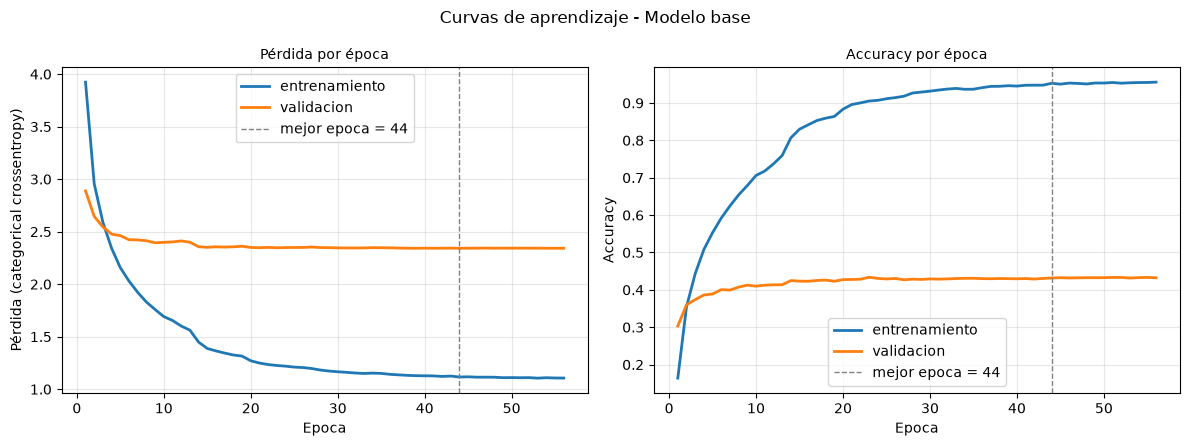

In [112]:
def graficar_curvas(historial, titulo="Modelo base"):
    """Dibuja pérdida y accuracy de entrenamiento y validación por época."""
    registro = historial.history if hasattr(historial, "history") else historial
    epocas = range(1, len(registro["loss"]) + 1)
    epoca_optima = int(np.argmin(registro["val_loss"])) + 1

    figura, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

    ejes[0].plot(epocas, registro["loss"], label="entrenamiento", linewidth=2)
    ejes[0].plot(epocas, registro["val_loss"], label="validacion", linewidth=2)
    ejes[0].set_ylabel("Pérdida (categorical crossentropy)")
    ejes[0].set_title("Pérdida por época", fontsize=10)

    ejes[1].plot(epocas, registro["accuracy"], label="entrenamiento", linewidth=2)
    ejes[1].plot(epocas, registro["val_accuracy"], label="validacion", linewidth=2)
    ejes[1].set_ylabel("Accuracy")
    ejes[1].set_title("Accuracy por época", fontsize=10)

    for eje in ejes:
        eje.axvline(
            epoca_optima,
            color="gray",
            linestyle="--",
            linewidth=1,
            label=f"mejor epoca = {epoca_optima}",
        )
        eje.set_xlabel("Epoca")
        eje.grid(alpha=0.3)
        eje.legend()

    figura.suptitle(f"Curvas de aprendizaje - {titulo}")
    plt.tight_layout()
    plt.show()


graficar_curvas(historial_base)

### Interpretación de las curvas

In [113]:
from sklearn.metrics import f1_score

registro = historial_base.history
indice_optimo = int(np.argmin(registro["val_loss"]))

# F1 macro en validación con los pesos restaurados de la mejor época
probabilidades_val = modelo_base.predict(X_val, batch_size=256, verbose=0)
predicciones_val = probabilidades_val.argmax(axis=1)
f1_macro_val = f1_score(y_val_idx, predicciones_val, average="macro")

diagnostico = pd.DataFrame(
    [
        ("Épocas ejecutadas", len(registro["loss"])),
        ("Mejor época (val_loss)", indice_optimo + 1),
        ("Pérdida entrenamiento", round(registro["loss"][indice_optimo], 4)),
        ("Pérdida validación", round(registro["val_loss"][indice_optimo], 4)),
        ("Accuracy entrenamiento", round(registro["accuracy"][indice_optimo], 4)),
        ("Accuracy validación", round(registro["val_accuracy"][indice_optimo], 4)),
        ("Top-3 accuracy validación", round(registro["val_top_3"][indice_optimo], 4)),
        ("F1 macro validación", round(float(f1_macro_val), 4)),
        (
            "Brecha train - val (accuracy)",
            round(registro["accuracy"][indice_optimo] - registro["val_accuracy"][indice_optimo], 4),
        ),
    ],
    columns=["Indicador", "Valor"],
)

display(diagnostico)

brecha = registro["accuracy"][indice_optimo] - registro["val_accuracy"][indice_optimo]
if brecha > 0.15:
    lectura = "sobreajuste claro: la red memoriza el entrenamiento y generaliza bastante peor"
elif brecha > 0.05:
    lectura = "sobreajuste moderado, contenido por el Dropout y la parada temprana"
else:
    lectura = "sin sobreajuste apreciable; las dos curvas evolucionan juntas"

print(f"Brecha train - val en accuracy: {brecha:.3f} -> {lectura}.")
print(
    f"Accuracy de validacion ({registro['val_accuracy'][indice_optimo]:.3f}) frente a los baselines:"
    f" azar {baseline_azar / 100:.3f} y clase mayoritaria {baseline_mayoritaria / 100:.3f}."
)

,Indicador,Valor
0,Épocas ejecutadas,56.0000
1,Mejor época (val_loss),44.0000
2,Pérdida entrenamiento,1.1162
3,Pérdida validación,2.3417
4,Accuracy entrenamiento,0.9528
5,Accuracy validación,0.4317
6,Top-3 accuracy validación,0.6265
7,F1 macro validación,0.3430
8,Brecha train - val (accuracy),0.5211


Brecha train - val en accuracy: 0.521 -> sobreajuste claro: la red memoriza el entrenamiento y generaliza bastante peor.
Accuracy de validacion (0.432) frente a los baselines: azar 0.016 y clase mayoritaria 0.078.


**Cómo se leen estas curvas**

Hay tres cosas que mirar en los gráficos anteriores:

1. **La separación entre las dos curvas de pérdida.** Mientras ambas bajan juntas, la red está
   aprendiendo estructura real del problema. En cuanto la pérdida de validación se aplana o sube
   mientras la de entrenamiento sigue bajando, lo que la red gana ya es memorización de las imágenes
   concretas del conjunto de entrenamiento: ese punto de cruce es el sobreajuste y es justo lo que
   detecta `EarlyStopping`.
2. **La época en que la validación deja de mejorar** (línea vertical punteada). Es la que se conserva,
   porque `restore_best_weights=True` devuelve los pesos de ese momento, y no los del final.
3. **El efecto de la regularización.** El Dropout hace que la curva de entrenamiento vaya *por debajo* de
   su potencial —parte de la red está apagada en cada paso— y por eso la brecha entre train y validación
   es menor de la que tendría el mismo MLP sin regularizar. El escalón que a veces se ve en las curvas
   corresponde a `ReduceLROnPlateau` bajando el learning rate.

La tabla de arriba resume el diagnóstico: la brecha entre entrenamiento y validación cuantifica el
sobreajuste, y la distancia frente a los baselines (azar y clase mayoritaria, impresos por la celda
anterior) confirma que el modelo efectivamente aprendió algo del problema.

**En las corridas del 16-10-2026** el diagnóstico es de sobreajuste claro: el modelo base llega a una
accuracy de entrenamiento cercana a 0,95 y se queda entre 0,43 y 0,48 en validación, aunque la parada
temprana conserve la mejor época. Con 1,4 millones de parámetros para unas 35.000 imágenes, la red
memoriza. Por eso la experimentación prueba más regularización (E6) y, sobre todo, entradas más pequeñas:
la que termina ganando, solo color (R2), usa una cuarta parte de los parámetros.

## Experimentación: comparación de configuraciones



### Diseño de los experimentos

La comparación sigue el principio de **un factor a la vez**: cada experimento cambia exactamente un
factor respecto del modelo base y deja el resto idéntico —misma semilla, misma partición, mismos pesos
por clase, mismos criterios de parada—. Así, cualquier diferencia en la métrica de validación es
atribuible al factor modificado y no a la interacción de varios cambios simultáneos.

| Exp. | Factor que cambia | Configuración | Qué pone a prueba |
|---|---|---|---|
| **Base** | — | Descriptores de color y textura, 2 capas (512, 256), ReLU, lr 0,001, batch 128, dropout 0,3, pesos raíz, suavizado 0,1, etiquetas de escena, con alteradas | Referencia |
| **R1** | Representación | Píxeles crudos (49.152 valores) | Si los descriptores aportan algo frente a la imagen aplanada |
| **R2** | Representación | Solo color (HSV + Lab) | Cuánto se puede reconocer solo por la paleta de color |
| **R3** | Representación | Solo textura (LBP + Gabor + HOG) | Cuánto aportan la textura y los bordes sin información de color |
| **E1** | Profundidad | 1 capa oculta (512) | Si una sola capa basta, o si la segunda aporta |
| **E2** | Profundidad y ancho | 3 capas (1024, 512, 256) | Si más capacidad mejora o solo sobreajusta |
| **E3** | Activación | 2 capas (512, 256) con tanh | El costo de una activación que se satura |
| **E4** | Tasa de aprendizaje | lr 0,0001 | Convergencia lenta pero estable frente al valor por defecto |
| **E5** | Tamaño de batch | batch 512 | Menos ruido por actualización y menos actualizaciones por época |
| **E6** | Regularización | Dropout 0,5 | Si más regularización reduce la brecha entre entrenamiento y validación |
| **P1** | Pesos por clase | Sin pesos | Cuánto aporta compensar el desbalance |
| **P2** | Pesos por clase | Balanceados completos | Si compensar del todo ayuda a los minoritarios o castiga demasiado a los frecuentes |
| **S1** | Suavizado | One-hot puro, sin suavizado | Si repartir el 10 % del objetivo ayuda con las etiquetas ambiguas |
| **S2** | Etiquetas de escena | Solo la etiqueta de la carpeta | Si informar al modelo de los otros personajes de la escena mejora la generalización |
| **A1** | Aumento de datos | Sin imágenes alteradas | Si las variantes de color y textura aportan |
| **C1** | Combinación | Los cambios que superaron a la base, juntos | Si las mejoras individuales se suman |

Las métricas registradas para cada configuración son la **accuracy** de validación —comparable con los
baselines— y el **F1 macro** de validación, que promedia sin ponderar los 64 personajes y es la métrica
que realmente refleja si el modelo atiende a los minoritarios. La selección final se hace por F1 macro,
por el desbalance ya documentado.

**Combinación final (C1).** Cambiar un factor a la vez dice qué ayuda por separado, pero no si las
mejoras se suman. Por eso, tras los experimentos individuales, C1 toma para cada factor el valor del
experimento que más superó a la base en F1 macro de validación y los aplica todos juntos. Si menos de dos
factores mejoraron, C1 no se entrena: coincidiría con un experimento ya medido.

Para acotar el costo, los experimentos usan un máximo de 35 épocas y una paciencia de 9 (el modelo
base se entrenó con 60 y paciencia 12); todos comparten exactamente ese presupuesto entre sí.

In [114]:
import time

EPOCAS_EXPERIMENTO = 35
PACIENCIA_EXPERIMENTO = 9

# Cada entrada cambia UN solo factor respecto del modelo base
experimentos = [
    {"nombre": "R1 - pixeles", "representacion": "pixeles"},
    {"nombre": "R2 - solo color", "representacion": "color"},
    {"nombre": "R3 - solo textura", "representacion": "textura"},
    {"nombre": "E1 - 1 capa (512)", "neuronas": (512,)},
    {"nombre": "E2 - 3 capas (1024,512,256)", "neuronas": (1024, 512, 256)},
    {"nombre": "E3 - activación tanh", "activacion": "tanh"},
    {"nombre": "E4 - learning rate 1e-4", "tasa_aprendizaje": 1e-4},
    {"nombre": "E5 - batch 512", "batch": 512},
    {"nombre": "E6 - dropout 0,5", "tasa_dropout": 0.5},
    {"nombre": "P1 - sin pesos por clase", "esquema_pesos": "ninguno"},
    {"nombre": "P2 - pesos balanceados", "esquema_pesos": "balanceado"},
    {"nombre": "S1 - sin suavizado", "suavizado": 0.0},
    {"nombre": "S2 - sin etiquetas de escena", "etiquetas_escena": False},
    {"nombre": "A1 - sin alteradas", "usar_alteradas": False},
]


def entrenar_configuracion(
    nombre,
    representacion=REPRESENTACION_BASE,
    neuronas=NEURONAS_OCULTAS,
    activacion=ACTIVACION,
    tasa_dropout=TASA_DROPOUT,
    tasa_aprendizaje=TASA_APRENDIZAJE,
    batch=TAMANO_BATCH,
    epocas=EPOCAS_EXPERIMENTO,
    paciencia=PACIENCIA_EXPERIMENTO,
    esquema_pesos=ESQUEMA_PESOS,
    suavizado=SUAVIZADO_ETIQUETAS,
    etiquetas_escena=True,
    usar_alteradas=True,
):
    """Entrena una configuración y devuelve el modelo, su historial y sus métricas de validación."""
    keras.utils.set_random_seed(SEMILLA)  # misma inicialización para todas las configuraciones

    identificador = nombre.split(" - ")[0].strip().lower().replace(" ", "_")
    modelo = construir_mlp(
        neuronas_ocultas=neuronas,
        activacion=activacion,
        tasa_dropout=tasa_dropout,
        representacion=representacion,
        nombre=f"mlp_{identificador}",
    )
    modelo = modelo.to(DISPOSITIVO)
    compilar(modelo, tasa_aprendizaje=tasa_aprendizaje)  # solo para predict()

    matrices = matrices_torch(representacion)
    X_entrena = matrices["train"]
    y_entrena = y_train if etiquetas_escena else y_train_duro
    if not usar_alteradas:
        X_entrena, y_entrena = X_entrena[filas_originales_train], y_entrena[filas_originales_train]

    inicio = time.perf_counter()
    historial = entrenar(
        modelo,
        X_entrena,
        y_entrena,
        matrices["val"],
        y_val,
        epocas=epocas,
        batch=batch,
        tasa_aprendizaje=tasa_aprendizaje,
        pesos_por_clase=PESOS_POR_ESQUEMA[esquema_pesos],
        suavizado=suavizado,
        paciencia=paciencia,
        ruta_modelo=DIRECTORIO_MODELOS / f"mlp_{identificador}.keras",
        verbose=0,
    )
    duracion = time.perf_counter() - inicio

    indice = int(np.argmin(historial.history["val_loss"]))
    predicciones = modelo.predict(matrices["val"], batch_size=256, verbose=0).argmax(axis=1)

    resultado = {
        "experimento": nombre,
        "representacion": representacion,
        "dimension_entrada": DIMENSIONES[representacion],
        "capas_ocultas": len(neuronas),
        "neuronas": " - ".join(str(n) for n in neuronas),
        "activacion": activacion,
        "dropout": tasa_dropout,
        "learning_rate": tasa_aprendizaje,
        "batch": batch,
        "pesos": esquema_pesos,
        "suavizado": suavizado,
        "etiquetas_escena": etiquetas_escena,
        "alteradas": usar_alteradas,
        "epocas": len(historial.history["loss"]),
        "mejor_epoca": indice + 1,
        "parametros": int(modelo.count_params()),
        "val_loss": round(historial.history["val_loss"][indice], 4),
        "val_accuracy": round(historial.history["val_accuracy"][indice], 4),
        "val_f1_macro": round(float(f1_score(y_val_idx, predicciones, average="macro")), 4),
        "segundos": round(duracion, 1),
    }
    return modelo, historial, resultado


modelos = {}
historiales = {}
resultados = []

# El modelo base ya está entrenado: se incorpora a la comparación sin volver a entrenarlo
NOMBRE_BASE = "Base - color_textura (512,256)"
resultados.append(
    {
        "experimento": NOMBRE_BASE,
        "representacion": REPRESENTACION_BASE,
        "dimension_entrada": DIMENSION_ENTRADA,
        "capas_ocultas": len(NEURONAS_OCULTAS),
        "neuronas": " - ".join(str(n) for n in NEURONAS_OCULTAS),
        "activacion": ACTIVACION,
        "dropout": TASA_DROPOUT,
        "learning_rate": TASA_APRENDIZAJE,
        "batch": TAMANO_BATCH,
        "pesos": ESQUEMA_PESOS,
        "suavizado": SUAVIZADO_ETIQUETAS,
        "etiquetas_escena": True,
        "alteradas": True,
        "epocas": len(historial_base.history["loss"]),
        "mejor_epoca": indice_optimo + 1,
        "parametros": int(modelo_base.count_params()),
        "val_loss": round(registro["val_loss"][indice_optimo], 4),
        "val_accuracy": round(registro["val_accuracy"][indice_optimo], 4),
        "val_f1_macro": round(float(f1_macro_val), 4),
        "segundos": np.nan,
    }
)
modelos[NOMBRE_BASE] = modelo_base
historiales[NOMBRE_BASE] = historial_base.history


def registrar(nombre, factores):
    """Entrena una configuración y la añade a la comparación."""
    print(f"Entrenando {nombre} ...")
    modelo, historial, resultado = entrenar_configuracion(nombre, **factores)
    modelos[nombre] = modelo
    historiales[nombre] = historial.history
    resultados.append(resultado)
    print(
        f"   val_accuracy={resultado['val_accuracy']:.4f}"
        f"   val_f1_macro={resultado['val_f1_macro']:.4f}"
        f"   epocas={resultado['epocas']}   {resultado['segundos']:.0f} s"
    )


for configuracion in experimentos:
    registrar(
        configuracion["nombre"],
        {factor: valor for factor, valor in configuracion.items() if factor != "nombre"},
    )

# C1: para cada factor, el valor del experimento que más superó a la base en F1 macro
f1_macro_base = resultados[0]["val_f1_macro"]
mejor_por_factor = {}
for configuracion, resultado in zip(experimentos, resultados[1:]):
    if resultado["val_f1_macro"] <= f1_macro_base:
        continue
    for factor, valor in configuracion.items():
        if factor == "nombre":
            continue
        if factor not in mejor_por_factor or resultado["val_f1_macro"] > mejor_por_factor[factor][1]:
            mejor_por_factor[factor] = (valor, resultado["val_f1_macro"], configuracion["nombre"])

componentes_combinacion = sorted({origen for _, _, origen in mejor_por_factor.values()})
if len(mejor_por_factor) >= 2:
    print(f"\nC1 combina: {' + '.join(componentes_combinacion)}")
    registrar(
        "C1 - combinación de mejoras",
        {factor: valor for factor, (valor, _, _) in mejor_por_factor.items()},
    )
else:
    print(
        f"\nC1 no se entrena: solo {len(mejor_por_factor)} factor(es) superaron a la base"
        f" ({', '.join(componentes_combinacion) or 'ninguno'}), así que no hay nada que combinar."
    )

tabla_experimentos = pd.DataFrame(resultados)
display(tabla_experimentos)

Entrenando R1 - pixeles ...
   val_accuracy=0.2976   val_f1_macro=0.2147   epocas=35   215 s
Entrenando R2 - solo color ...
   val_accuracy=0.4949   val_f1_macro=0.4549   epocas=35   72 s
Entrenando R3 - solo textura ...
   val_accuracy=0.2412   val_f1_macro=0.1768   epocas=21   58 s
Entrenando E1 - 1 capa (512) ...
   val_accuracy=0.4091   val_f1_macro=0.3354   epocas=19   43 s
Entrenando E2 - 3 capas (1024,512,256) ...
   val_accuracy=0.4556   val_f1_macro=0.3757   epocas=35   193 s
Entrenando E3 - activación tanh ...
   val_accuracy=0.3682   val_f1_macro=0.2963   epocas=16   47 s
Entrenando E4 - learning rate 1e-4 ...
   val_accuracy=0.3886   val_f1_macro=0.3012   epocas=35   102 s
Entrenando E5 - batch 512 ...
   val_accuracy=0.4153   val_f1_macro=0.3298   epocas=33   63 s
Entrenando E6 - dropout 0,5 ...
   val_accuracy=0.4311   val_f1_macro=0.3444   epocas=35   103 s
Entrenando P1 - sin pesos por clase ...
   val_accuracy=0.4297   val_f1_macro=0.3389   epocas=35   102 s
Entrenando

,experimento,representacion,dimension_entrada,capas_ocultas,neuronas,activacion,dropout,learning_rate,batch,pesos,suavizado,etiquetas_escena,alteradas,epocas,mejor_epoca,parametros,val_loss,val_accuracy,val_f1_macro,segundos
0,"Base - color_textura (512,256)",color_textura,2462,2,512 - 256,relu,0.3,0.0010,128,raiz,0.1,True,True,56,44,1411904,2.3417,0.4317,0.3430,NaN
1,R1 - pixeles,pixeles,3072,2,512 - 256,relu,0.3,0.0010,128,raiz,0.1,True,True,35,30,1724224,2.8789,0.2976,0.2147,215.0
2,R2 - solo color,color,370,2,512 - 256,relu,0.3,0.0010,128,raiz,0.1,True,True,35,35,340800,1.9923,0.4949,0.4549,72.1
3,R3 - solo textura,textura,2092,2,512 - 256,relu,0.3,0.0010,128,raiz,0.1,True,True,21,12,1222464,3.1522,0.2412,0.1768,58.5
4,E1 - 1 capa (512),color_textura,2462,1,512,relu,0.3,0.0010,128,raiz,0.1,True,True,19,10,1295936,2.4385,0.4091,0.3354,42.9
5,"E2 - 3 capas (1024,512,256)",color_textura,2462,3,1024 - 512 - 256,relu,0.3,0.0010,128,raiz,0.1,True,True,35,35,3201856,2.2572,0.4556,0.3757,193.1
6,E3 - activación tanh,color_textura,2462,2,512 - 256,tanh,0.3,0.0010,128,raiz,0.1,True,True,16,7,1411904,2.5882,0.3682,0.2963,47.3
7,E4 - learning rate 1e-4,color_textura,2462,2,512 - 256,relu,0.3,0.0001,128,raiz,0.1,True,True,35,35,1411904,2.5187,0.3886,0.3012,102.4
8,E5 - batch 512,color_textura,2462,2,512 - 256,relu,0.3,0.0010,512,raiz,0.1,True,True,33,24,1411904,2.4020,0.4153,0.3298,63.3
9,"E6 - dropout 0,5",color_textura,2462,2,512 - 256,relu,0.5,0.0010,128,raiz,0.1,True,True,35,35,1411904,2.2603,0.4311,0.3444,102.9


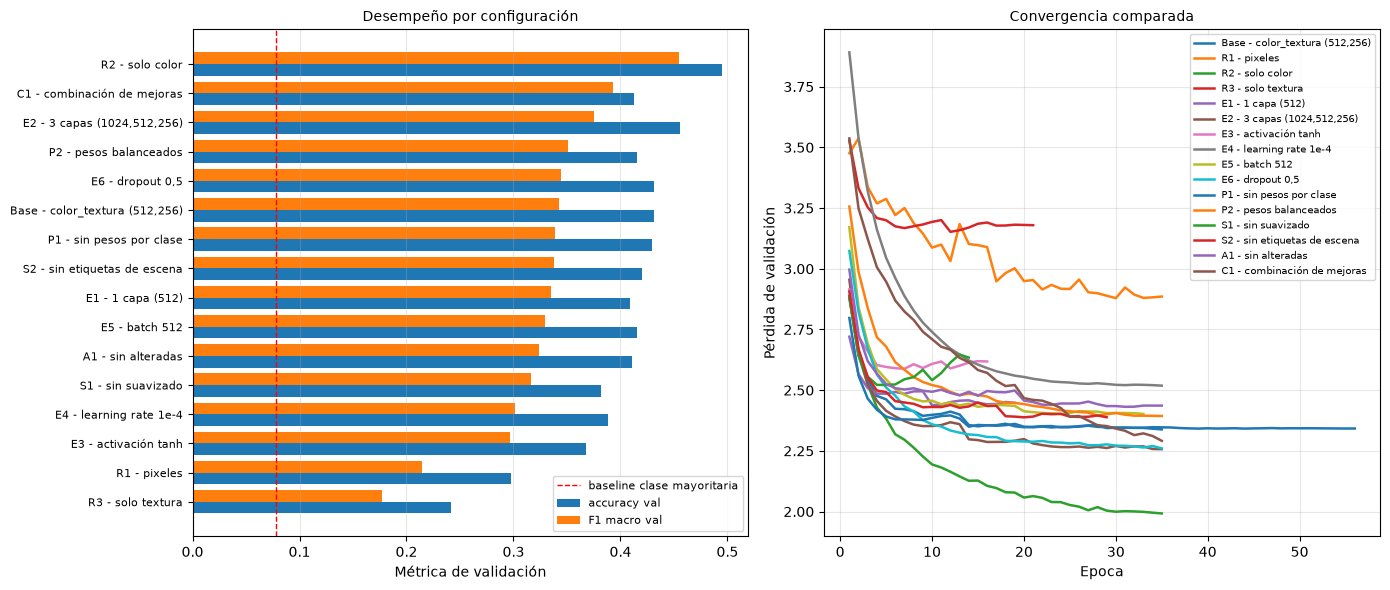

In [115]:
# Comparación visual de las configuraciones por accuracy y F1 macro de validación
orden_resultados = tabla_experimentos.sort_values("val_f1_macro", ascending=True)
posiciones = np.arange(len(orden_resultados))

figura, ejes = plt.subplots(1, 2, figsize=(14, 6))

ejes[0].barh(posiciones - 0.2, orden_resultados["val_accuracy"], height=0.4, label="accuracy val")
ejes[0].barh(posiciones + 0.2, orden_resultados["val_f1_macro"], height=0.4, label="F1 macro val")
ejes[0].set_yticks(posiciones)
ejes[0].set_yticklabels(orden_resultados["experimento"], fontsize=8)
ejes[0].axvline(baseline_mayoritaria / 100, color="red", linestyle="--", linewidth=1, label="baseline clase mayoritaria")
ejes[0].set_xlabel("Métrica de validación")
ejes[0].set_title("Desempeño por configuración", fontsize=10)
ejes[0].legend(fontsize=8)
ejes[0].grid(alpha=0.3, axis="x")

for nombre, registro_historial in historiales.items():
    ejes[1].plot(
        range(1, len(registro_historial["val_loss"]) + 1),
        registro_historial["val_loss"],
        label=nombre,
        linewidth=1.8,
    )
ejes[1].set_xlabel("Epoca")
ejes[1].set_ylabel("Pérdida de validación")
ejes[1].set_title("Convergencia comparada", fontsize=10)
ejes[1].grid(alpha=0.3)
ejes[1].legend(fontsize=7)

plt.tight_layout()
plt.show()

### Efecto de la representación de entrada

,experimento,representacion,dimension_entrada,parametros,val_accuracy,val_f1_macro,epocas,segundos
0,R2 - solo color,color,370,340800,0.4949,0.4549,35,72.1
1,"Base - color_textura (512,256)",color_textura,2462,1411904,0.4317,0.3430,56,NaN
2,R1 - pixeles,pixeles,3072,1724224,0.2976,0.2147,35,215.0
3,R3 - solo textura,textura,2092,1222464,0.2412,0.1768,21,58.5


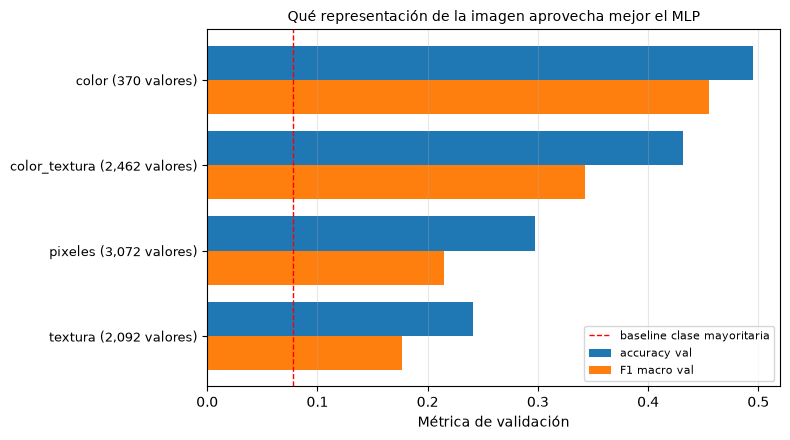

In [116]:
# Solo las configuraciones que cambian la representación (misma arquitectura que el base)
comparacion_representacion = tabla_experimentos[
    tabla_experimentos["experimento"].str.contains("Base|R1|R2|R3")
][["experimento", "representacion", "dimension_entrada", "parametros", "val_accuracy", "val_f1_macro", "epocas", "segundos"]]
comparacion_representacion = comparacion_representacion.sort_values(
    "val_f1_macro", ascending=False
).reset_index(drop=True)

display(comparacion_representacion)

figura, eje = plt.subplots(figsize=(8, 4.5))
posiciones = np.arange(len(comparacion_representacion))
eje.barh(posiciones - 0.2, comparacion_representacion["val_accuracy"], height=0.4, label="accuracy val")
eje.barh(posiciones + 0.2, comparacion_representacion["val_f1_macro"], height=0.4, label="F1 macro val")
eje.set_yticks(posiciones)
eje.set_yticklabels(
    [
        f"{fila.representacion} ({fila.dimension_entrada:,} valores)"
        for fila in comparacion_representacion.itertuples()
    ],
    fontsize=9,
)
eje.invert_yaxis()
eje.axvline(
    baseline_mayoritaria / 100,
    color="red",
    linestyle="--",
    linewidth=1,
    label="baseline clase mayoritaria",
)
eje.set_xlabel("Métrica de validación")
eje.set_title("Qué representación de la imagen aprovecha mejor el MLP", fontsize=10)
eje.grid(alpha=0.3, axis="x")
eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lectura.** La pregunta central del enfoque tiene una respuesta clara, aunque no la esperada: **el color
solo (R2) supera a la combinación de color y textura del modelo base**. En las corridas del 16-10-2026 que
conservan la tabla completa, R2 llega a un F1 macro de validación de 0,477 (GPU, 64 × 64) y de 0,455 (CPU,
32 × 32), frente a 0,404 y 0,343 de la base. En las seis corridas registradas el modelo final usa solo
color: o gana R2, o gana la combinación C1, que solo toma la entrada de R2 si R2 superó a la base. La
textura sola (R3) y los píxeles crudos (R1) quedan muy atrás, por debajo de 0,23.

Tres razones lo explican:

- **El color es lo que distingue a estos personajes.** Cada uno tiene una paleta fija —el pelo azul de
  Marge, el pelo verde de Krusty, la piel morena de Apu— y los histogramas HSV y Lab, calculados sobre la
  imagen completa y sobre sus cuatro cuadrantes, la capturan sin depender de dónde está el personaje.
- **La textura añade sobre todo ruido.** Los 2.092 valores de LBP, Gabor y HOG describen trazos y bordes,
  y en esta serie todos los personajes están dibujados con el mismo trazo. Al sumarlos a los 370 de color,
  el modelo base recibe casi seis valores de textura por cada uno de color y pasa de 340.800 a 1,4
  millones de parámetros: memoriza el entrenamiento (accuracy de entrenamiento cercana a 0,95) y generaliza
  peor.
- **Los píxeles crudos son la peor entrada.** R1 tiene la primera capa más grande —de 1,6 a 25,2 millones
  de pesos según la resolución— y el peor resultado: sin los histogramas, el MLP tiene que aprender colores
  en posiciones fijas del encuadre, justo la limitación que los descriptores venían a resolver.

La importancia por permutación de la sección «En qué se apoya el modelo» confirma la lectura desde el
modelo final: barajar cualquiera de sus dos bloques de color deja el F1 macro por debajo de 0,10.

### Efecto del número de capas ocultas y de neuronas

,experimento,capas_ocultas,neuronas,parametros,val_accuracy,val_f1_macro,epocas,segundos,parametros_millones
0,E1 - 1 capa (512),1,512,1295936,0.4091,0.3354,19,42.9,1.30
1,"Base - color_textura (512,256)",2,512 - 256,1411904,0.4317,0.3430,56,NaN,1.41
2,"E2 - 3 capas (1024,512,256)",3,1024 - 512 - 256,3201856,0.4556,0.3757,35,193.1,3.20


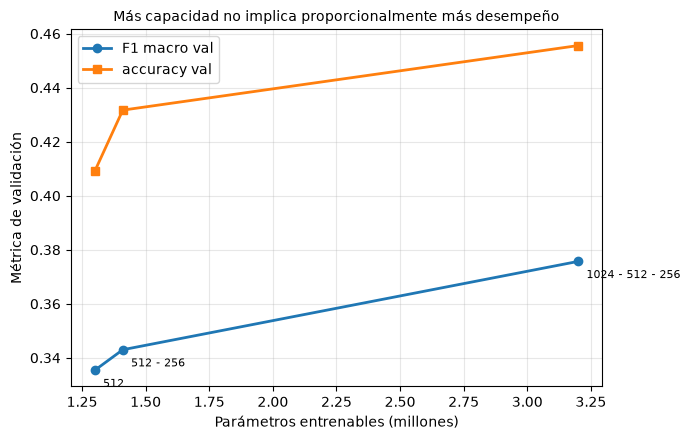

In [117]:
# Solo las configuraciones que cambian la arquitectura (misma activación, lr y batch que el base)
comparacion_arquitectura = tabla_experimentos[
    tabla_experimentos["experimento"].str.contains("Base|E1|E2")
][["experimento", "capas_ocultas", "neuronas", "parametros", "val_accuracy", "val_f1_macro", "epocas", "segundos"]]
comparacion_arquitectura = comparacion_arquitectura.sort_values("parametros").reset_index(drop=True)

comparacion_arquitectura["parametros_millones"] = (
    comparacion_arquitectura["parametros"] / 1e6
).round(2)

display(comparacion_arquitectura)

figura, eje = plt.subplots(figsize=(7, 4.5))
eje.plot(
    comparacion_arquitectura["parametros_millones"],
    comparacion_arquitectura["val_f1_macro"],
    marker="o",
    linewidth=2,
    label="F1 macro val",
)
eje.plot(
    comparacion_arquitectura["parametros_millones"],
    comparacion_arquitectura["val_accuracy"],
    marker="s",
    linewidth=2,
    label="accuracy val",
)
for _, fila in comparacion_arquitectura.iterrows():
    eje.annotate(
        fila["neuronas"],
        (fila["parametros_millones"], fila["val_f1_macro"]),
        textcoords="offset points",
        xytext=(6, -12),
        fontsize=8,
    )
eje.set_xlabel("Parámetros entrenables (millones)")
eje.set_ylabel("Métrica de validación")
eje.set_title("Más capacidad no implica proporcionalmente más desempeño", fontsize=10)
eje.grid(alpha=0.3)
eje.legend()
plt.tight_layout()
plt.show()

**Lectura.** Con descriptores, más profundidad ayuda, aunque poco. En las corridas con la tabla completa,
las tres capas de E2 (1024, 512, 256) superan a la base en F1 macro de validación (0,426 frente a 0,404 en
GPU a 64 × 64; 0,376 frente a 0,343 en CPU a 32 × 32), y una sola capa (E1) queda por debajo de las dos. En
las dos corridas en que ganó la combinación C1, la arquitectura que heredó fue también la de E2. A
diferencia de lo que pasaba con los píxeles, la entrada ya trae características con sentido —la
proporción de cada color en cada zona— y una capa más permite combinarlas en reglas más finas.

Pero el aumento tiene un costo alto y un techo bajo. E2 multiplica los parámetros por 2,3 (de 1,4 a 3,2
millones) para ganar entre 2 y 3 puntos de F1 macro, mucho menos que los 7 a 11 puntos que se ganan al
pasar a la entrada de solo color (R2) sin tocar la arquitectura. La capacidad no es el cuello de botella:
el modelo base ya llega a una accuracy de entrenamiento cercana a 0,95, así que las neuronas extra se
emplean sobre todo en memorizar. Cada millón de parámetros adicional se paga además en tiempo por época
(columna `segundos`).

### Efecto de la función de activación

,experimento,activacion,val_loss,val_accuracy,val_f1_macro,epocas,mejor_epoca
0,"Base - color_textura (512,256)",relu,2.3417,0.4317,0.3430,56,44
1,E3 - activación tanh,tanh,2.5882,0.3682,0.2963,16,7


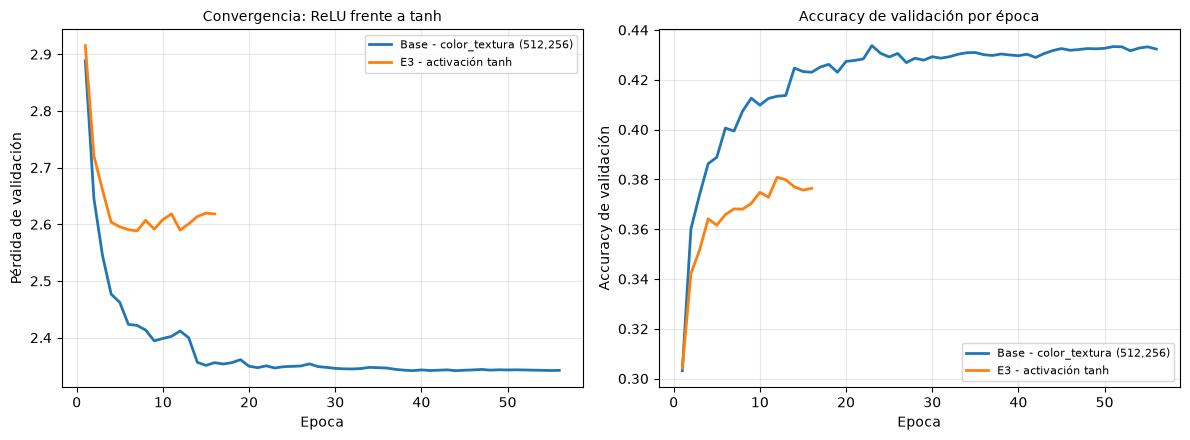

In [118]:
comparacion_activacion = tabla_experimentos[
    tabla_experimentos["experimento"].str.contains("Base|E3")
][["experimento", "activacion", "val_loss", "val_accuracy", "val_f1_macro", "epocas", "mejor_epoca"]]

display(comparacion_activacion.reset_index(drop=True))

figura, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

for nombre in comparacion_activacion["experimento"]:
    registro_historial = historiales[nombre]
    epocas_rango = range(1, len(registro_historial["loss"]) + 1)
    ejes[0].plot(epocas_rango, registro_historial["val_loss"], linewidth=2, label=nombre)
    ejes[1].plot(epocas_rango, registro_historial["val_accuracy"], linewidth=2, label=nombre)

ejes[0].set_ylabel("Pérdida de validación")
ejes[0].set_title("Convergencia: ReLU frente a tanh", fontsize=10)
ejes[1].set_ylabel("Accuracy de validación")
ejes[1].set_title("Accuracy de validación por época", fontsize=10)

for eje in ejes:
    eje.set_xlabel("Epoca")
    eje.grid(alpha=0.3)
    eje.legend(fontsize=8)

plt.tight_layout()
plt.show()

**Lectura.** ReLU gana con claridad. Con tanh (E3) el F1 macro de validación cae entre 4,7 y 5,9 puntos
(0,345 frente a 0,404 en GPU a 64 × 64; 0,296 frente a 0,343 en CPU a 32 × 32), y la parada temprana corta
el entrenamiento mucho antes: E3 se detiene en la época 23 (GPU) o 16 (CPU), mientras la base sigue
mejorando hasta la 37 o la 44. Es lo descrito en «Funciones de activación»: la tanh está acotada en
(-1, 1) y su derivada cae hacia cero en los extremos, así que las neuronas saturadas dejan de aprender y la
validación se estanca pronto. ReLU no tiene ese techo —su derivada vale 1 para todo z > 0— y produce
activaciones dispersas: en el recorrido de una imagen por la red entrenada (sección «El modelo en acción
sobre el conjunto de test»), la corrida de GPU a 64 × 64 activa solo el 40 % de las neuronas de la primera
capa oculta y el 29 % de la segunda. El resultado confirma la elección de ReLU para el modelo base.

### Efecto del número de épocas, el tamaño de batch y la tasa de aprendizaje

,experimento,learning_rate,batch,epocas,mejor_epoca,val_loss,val_accuracy,val_f1_macro,segundos
0,"Base - color_textura (512,256)",0.0010,128,56,44,2.3417,0.4317,0.3430,NaN
1,E4 - learning rate 1e-4,0.0001,128,35,35,2.5187,0.3886,0.3012,102.4
2,E5 - batch 512,0.0010,512,33,24,2.4020,0.4153,0.3298,63.3


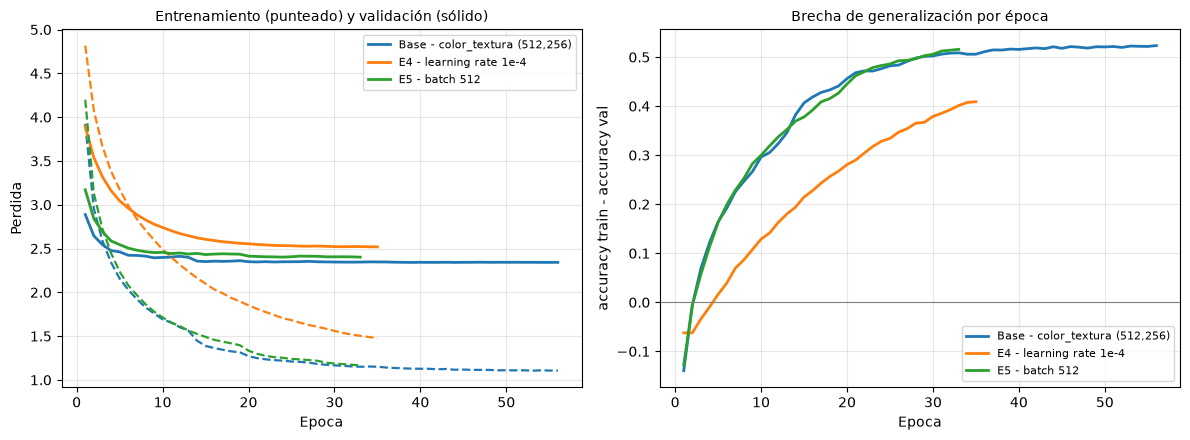

In [119]:
comparacion_optimizacion = tabla_experimentos[
    tabla_experimentos["experimento"].str.contains("Base|E4|E5")
][["experimento", "learning_rate", "batch", "epocas", "mejor_epoca", "val_loss", "val_accuracy", "val_f1_macro", "segundos"]]

display(comparacion_optimizacion.reset_index(drop=True))

figura, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

for nombre in comparacion_optimizacion["experimento"]:
    registro_historial = historiales[nombre]
    epocas_rango = range(1, len(registro_historial["loss"]) + 1)
    ejes[0].plot(epocas_rango, registro_historial["loss"], linewidth=1.6, linestyle="--")
    ejes[0].plot(
        epocas_rango,
        registro_historial["val_loss"],
        linewidth=2,
        label=nombre,
        color=ejes[0].lines[-1].get_color(),
    )
    ejes[1].plot(
        epocas_rango,
        np.array(registro_historial["accuracy"]) - np.array(registro_historial["val_accuracy"]),
        linewidth=2,
        label=nombre,
    )

ejes[0].set_ylabel("Perdida")
ejes[0].set_title("Entrenamiento (punteado) y validación (sólido)", fontsize=10)
ejes[1].axhline(0, color="gray", linewidth=0.8)
ejes[1].set_ylabel("accuracy train - accuracy val")
ejes[1].set_title("Brecha de generalización por época", fontsize=10)

for eje in ejes:
    eje.set_xlabel("Epoca")
    eje.grid(alpha=0.3)
    eje.legend(fontsize=8)

plt.tight_layout()
plt.show()

**Lectura.** Los tres hiperparámetros de optimización están acoplados y conviene leerlos juntos:

- **Tasa de aprendizaje.** Con 1e-4 (E4) el F1 macro de validación baja entre 4 y 5 puntos (0,357 frente a
  0,404 en GPU; 0,301 frente a 0,343 en CPU). El modelo no diverge: usa las 35 épocas del presupuesto y, en
  la GPU, su mejor época es la 33, así que seguía mejorando cuando se acabó el tiempo. Un learning rate diez
  veces menor no llega a tiempo.
- **Tamaño de batch.** Con batch 512 (E5) cada época tiene cuatro veces menos actualizaciones de pesos y el
  F1 macro baja entre 1 y 2 puntos (0,382 frente a 0,404; 0,330 frente a 0,343). A cambio, es la
  configuración más barata: 19 s frente a unos 70 s de las demás en la GPU, y 63 s frente a unos 100 s en
  la CPU. En la GPU la diferencia es mayor porque, a batch 128, la tarjeta pasa la mayor parte del tiempo
  esperando instrucciones (ver «Comparación de las corridas del 16-10-2026»). Si el costo pesara más que el
  último punto de F1, lo siguiente a probar sería batch 512 con un learning rate mayor.
- **Número de épocas.** No se elige a mano: `mejor_epoca` muestra dónde la validación tocó su mínimo y
  `epocas` cuánto se entrenó antes de que la parada temprana cortara. Casi todas las configuraciones usan
  las 35 épocas del presupuesto con la mejor época cerca del final; las que se detienen antes —tanh, sin
  suavizado, una capa, solo textura— son las que empiezan a sobreajustar o se estancan pronto.

El panel derecho muestra la brecha entre accuracy de entrenamiento y de validación época a época: cuando
crece de forma sostenida, cada época adicional se está invirtiendo en memorizar, no en generalizar.

### Efecto del tratamiento de los datos, la regularización y la combinación

Estos experimentos no tocan la arquitectura, sino lo que la red ve al entrenar: cuánto pesa cada
personaje (P1, P2), cuán duro es el objetivo (S1, S2), si entran las variantes alteradas (A1) y cuánto se
regulariza (E6). La columna `delta_f1_vs_base` es la diferencia de F1 macro de validación frente al modelo
base: positiva si el cambio ayuda. C1, si se entrenó, junta los cambios que salieron positivos.

Al leer la tabla conviene mirar también la accuracy: un cambio que sube el F1 macro a costa de bajar mucho
la accuracy está desplazando aciertos de los personajes frecuentes a los escasos, no reconociendo mejor.

,experimento,pesos,suavizado,etiquetas_escena,alteradas,dropout,val_accuracy,val_f1_macro,epocas,segundos,delta_accuracy_vs_base,delta_f1_vs_base
0,"Base - color_textura (512,256)",raiz,0.1,True,True,0.3,0.4317,0.3430,56,NaN,0.0000,0.0000
1,"E6 - dropout 0,5",raiz,0.1,True,True,0.5,0.4311,0.3444,35,102.9,-0.0006,0.0014
2,P1 - sin pesos por clase,ninguno,0.1,True,True,0.3,0.4297,0.3389,35,102.4,-0.0020,-0.0041
3,P2 - pesos balanceados,balanceado,0.1,True,True,0.3,0.4159,0.3511,35,104.4,-0.0158,0.0081
4,S1 - sin suavizado,raiz,0.0,True,True,0.3,0.3820,0.3166,14,41.3,-0.0497,-0.0264
5,S2 - sin etiquetas de escena,raiz,0.1,False,True,0.3,0.4202,0.3377,29,86.1,-0.0115,-0.0053
6,A1 - sin alteradas,raiz,0.1,True,False,0.3,0.4112,0.3242,35,86.3,-0.0205,-0.0188
7,C1 - combinación de mejoras,balanceado,0.1,True,True,0.5,0.4122,0.3932,35,133.1,-0.0195,0.0502


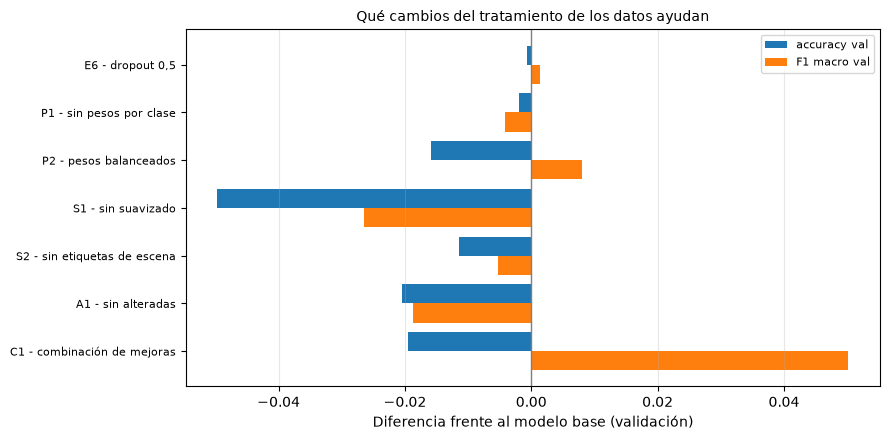

In [120]:
comparacion_datos = tabla_experimentos[
    tabla_experimentos["experimento"].str.match(r"Base|E6|P\d|S\d|A\d|C\d")
][
    ["experimento", "pesos", "suavizado", "etiquetas_escena", "alteradas", "dropout",
     "val_accuracy", "val_f1_macro", "epocas", "segundos"]
].reset_index(drop=True)
fila_base = comparacion_datos["experimento"].str.startswith("Base")
comparacion_datos["delta_accuracy_vs_base"] = (
    comparacion_datos["val_accuracy"] - float(comparacion_datos.loc[fila_base, "val_accuracy"].iloc[0])
).round(4)
comparacion_datos["delta_f1_vs_base"] = (
    comparacion_datos["val_f1_macro"] - float(comparacion_datos.loc[fila_base, "val_f1_macro"].iloc[0])
).round(4)
display(comparacion_datos)

figura, eje = plt.subplots(figsize=(9, 4.5))
otras = comparacion_datos[~fila_base].reset_index(drop=True)
posiciones = np.arange(len(otras))
eje.barh(posiciones - 0.2, otras["delta_accuracy_vs_base"], height=0.4, label="accuracy val")
eje.barh(posiciones + 0.2, otras["delta_f1_vs_base"], height=0.4, label="F1 macro val")
eje.set_yticks(posiciones)
eje.set_yticklabels(otras["experimento"], fontsize=8)
eje.invert_yaxis()
eje.axvline(0, color="gray", linewidth=1)
eje.set_xlabel("Diferencia frente al modelo base (validación)")
eje.set_title("Qué cambios del tratamiento de los datos ayudan", fontsize=10)
eje.grid(alpha=0.3, axis="x")
eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Selección del modelo final

In [121]:
import json

# El criterio de selección es el F1 macro de validación, no la accuracy:
# promedia todas las clases sin ponderar y penaliza ignorar a los personajes minoritarios
ranking = tabla_experimentos.sort_values("val_f1_macro", ascending=False).reset_index(drop=True)
display(ranking[["experimento", "representacion", "val_accuracy", "val_f1_macro", "val_loss", "parametros", "epocas"]])

nombre_final = ranking.loc[0, "experimento"]
modelo_final = modelos[nombre_final]
representacion_final = ranking.loc[0, "representacion"]

print(f"Configuracion seleccionada: {nombre_final}")
print(f"  representacion      : {representacion_final} ({DIMENSIONES[representacion_final]} valores)")
print(f"  accuracy validacion : {ranking.loc[0, 'val_accuracy']:.4f}")
print(f"  F1 macro validacion : {ranking.loc[0, 'val_f1_macro']:.4f}")
print(f"  parametros          : {ranking.loc[0, 'parametros']:,}")
print(f"\nDiferencia en F1 macro frente a la segunda ({ranking.loc[1, 'experimento']}): {ranking.loc[0, 'val_f1_macro'] - ranking.loc[1, 'val_f1_macro']:+.4f}")

ruta_modelo_final = DIRECTORIO_MODELOS / "mlp_final.keras"
modelo_final.save(ruta_modelo_final)

# Lo que la utilidad de predicción necesita para repetir el pre-procesamiento sin volver
# a ejecutar el notebook: la representación, la resolución y el orden de las clases
metadatos_final = {
    "configuracion": nombre_final,
    "representacion": representacion_final,
    "alto": ALTO_OBJETIVO,
    "ancho": ANCHO_OBJETIVO,
    "clases": clases,
}
ruta_metadatos_final = DIRECTORIO_MODELOS / "mlp_final.json"
ruta_metadatos_final.write_text(json.dumps(metadatos_final, indent=2, ensure_ascii=False), encoding="utf-8")

print(f"\nModelo final guardado en: {ruta_modelo_final}")
print(f"Pre-procesamiento del modelo final en: {ruta_metadatos_final}")

,experimento,representacion,val_accuracy,val_f1_macro,val_loss,parametros,epocas
0,R2 - solo color,color,0.4949,0.4549,1.9923,340800,35
1,C1 - combinación de mejoras,color,0.4122,0.3932,2.2913,1059648,35
2,"E2 - 3 capas (1024,512,256)",color_textura,0.4556,0.3757,2.2572,3201856,35
3,P2 - pesos balanceados,color_textura,0.4159,0.3511,2.3937,1411904,35
4,"E6 - dropout 0,5",color_textura,0.4311,0.3444,2.2603,1411904,35
5,"Base - color_textura (512,256)",color_textura,0.4317,0.3430,2.3417,1411904,56
6,P1 - sin pesos por clase,color_textura,0.4297,0.3389,2.3385,1411904,35
7,S2 - sin etiquetas de escena,color_textura,0.4202,0.3377,2.3882,1411904,29
8,E1 - 1 capa (512),color_textura,0.4091,0.3354,2.4385,1295936,19
9,E5 - batch 512,color_textura,0.4153,0.3298,2.4020,1411904,33


Configuracion seleccionada: R2 - solo color
  representacion      : color (370 valores)
  accuracy validacion : 0.4949
  F1 macro validacion : 0.4549
  parametros          : 340,800

Diferencia en F1 macro frente a la segunda (C1 - combinación de mejoras): +0.0617

Modelo final guardado en: ..\..\models\newDataset\mlp_final.keras
Pre-procesamiento del modelo final en: ..\..\models\newDataset\mlp_final.json


**Justificación de la decisión.** La configuración elegida es la que maximiza el **F1 macro de
validación**, y no la que maximiza la accuracy. Validación conserva la distribución real del dataset, con
una razón de desbalance de 33:1: la accuracy premia acertar en los personajes abundantes y apenas se
resiente si el modelo ignora a los escasos; el F1 macro, al promediar los 64 personajes sin ponderarlos,
sí lo penaliza. Como el objetivo declarado es reconocer personajes —los 64, no solo a Homero—, esa es la
métrica coherente con el problema.

La celda elige siempre la configuración de mayor F1 macro, sin margen de empate. En las seis corridas del
16-10-2026 eso alternó entre dos configuraciones con la misma entrada de solo color: R2, con dos capas y
340.800 parámetros, ganó en cuatro, y C1, con las tres capas de E2 y 1,06 millones, en dos. Como entre
corridas que solo cambian el dispositivo el resultado de test ya varía alrededor de un punto, una
diferencia de validación menor que eso no distingue a dos configuraciones; en ese caso conviene preferir
la red más pequeña, por costo de entrenamiento y por menor riesgo de sobreajuste.

El modelo seleccionado, con su representación de entrada, es el que se evalúa en la sección siguiente
sobre el **conjunto de test**, que hasta este punto no se ha tocado ni para entrenar ni para elegir
hiperparámetros.

## Evaluación y métricas de desempeño

El conjunto de evaluación es el **test** reservado en la partición: el 10 % de las imágenes originales de
cada personaje, con la distribución real del dataset y en las mismas condiciones que el entrenamiento: las
imágenes casi idénticas a otra entran con su versión filtrada y un cuarto de las originales viene con su
variante alterada. El modelo nunca vio esas imágenes ni ninguna variante de ellas.

**Criterio de acierto.** Una predicción es correcta si nombra al personaje de la carpeta o a otro personaje
que también aparece en la imagen, según la escena y las gemelas (sección «Escenas con varios personajes») o
según la verificación por imagen de los errores con confianza alta (sección siguiente). Con ese criterio se calculan la
accuracy, el top-3, el F1, el reporte por clase, la matriz de confusión y los KPIs; la accuracy estricta,
que solo acepta el personaje de la carpeta, se muestra al lado como referencia. Las galerías usan tres
colores: verde si el modelo nombra al de la carpeta, ámbar si nombra a otro personaje presente y rojo si se
equivoca.

Ya está cargado y procesado con **exactamente las mismas funciones** que el entrenamiento —el mismo
redimensionado a 128 x 128, los mismos descriptores y el mismo diccionario `clase_a_indice`—, porque las
tres particiones salieron del mismo índice. La celda siguiente toma la representación del modelo elegido,
que puede no ser la del modelo base, y comprueba que las matrices son coherentes con las del
entrenamiento.

In [122]:
# El test sale de la partición: se toma en la representación del modelo final, que
# puede no ser la del modelo base si la experimentación eligió otra entrada
print(f"Modelo final: {nombre_final}   |   representacion: {representacion_final}")

X_test = particion(representacion_final)["test"]

# Cada alterada de test acompaña a su original, que también está en test
originales_test = set(
    zip(datos_test.loc[~datos_test["alterada"], "personaje"], datos_test.loc[~datos_test["alterada"], "origen"])
)
alteradas_test = datos_test[datos_test["alterada"]]
alteradas_test_con_original = sum(
    (personaje, origen) in originales_test
    for personaje, origen in zip(alteradas_test["personaje"], alteradas_test["origen"])
)

comprobaciones_test = pd.DataFrame(
    [
        (
            "Todas las clases presentes",
            len(np.unique(y_test_idx)),
            NUMERO_CLASES,
            len(np.unique(y_test_idx)) == NUMERO_CLASES,
        ),
        (
            "Dimensión de entrada del modelo final",
            X_test.shape[1],
            DIMENSIONES[representacion_final],
            X_test.shape[1] == DIMENSIONES[representacion_final],
        ),
        (
            "Alteradas de test con su original en test",
            alteradas_test_con_original,
            len(alteradas_test),
            alteradas_test_con_original == len(alteradas_test),
        ),
        ("Etiquetas alineadas", len(y_test_idx), X_test.shape[0], len(y_test_idx) == X_test.shape[0]),
        ("Imágenes alineadas", len(imagenes_test), X_test.shape[0], len(imagenes_test) == X_test.shape[0]),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)

display(comprobaciones_test)

if not comprobaciones_test["Correcto"].all():
    raise ValueError("El conjunto de test no cumple alguna de las comprobaciones.")

print(f"Conjunto de test: {len(datos_test)} imagenes")
print(f"X_test: {X_test.shape}   y_test: {y_test.shape}")

# Como tensores de PyTorch, igual que train y validación
X_test = matrices_torch(representacion_final)["test"]
y_test = a_tensor(y_test)
print(f"X_test en {X_test.device}")

Modelo final: R2 - solo color   |   representacion: color


,Comprobacion,Obtenido,Esperado,Correcto
0,Todas las clases presentes,64,64,True
1,Dimensión de entrada del modelo final,370,370,True
2,Alteradas de test con su original en test,1050,1050,True
3,Etiquetas alineadas,5063,5063,True
4,Imágenes alineadas,5063,5063,True


Conjunto de test: 5063 imagenes
X_test: (5063, 370)   y_test: (5063, 64)
X_test en cpu


### Verificación de los errores con confianza alta

La escena del episodio (±3 s) y las gemelas no encuentran a todos los personajes presentes: una imagen de
Kaggle no trae episodio ni instante, y dos tomas del mismo plano pueden quedar a más de tres segundos o
parecerse menos que una gemela. Por eso, antes de calcular las métricas, cada **error cometido con
confianza mayor que `UMBRAL_CONFIANZA_VERIFICACION` (0,80)** pasa por una verificación: ¿se equivocó el
modelo, o nombró a otro personaje que sí sale en la imagen?

**Cómo se verifica.** La imagen se compara con todas las de la carpeta del personaje que nombró el
modelo, con las mismas miniaturas de 16 × 16 a color con que el script de alteraciones busca las
gemelas. Si alguna supera una similitud de `UMBRAL_SIMILITUD_VERIFICACION` (0,80), es la misma toma: ese
personaje está en la imagen y la predicción cuenta como **acierto por escena**. Si ninguna la supera, es
un **error real**.

- **Por qué 0,80.** En una muestra de 4.087 fotogramas de 120 episodios, de los 8,08 millones de pares de
  personajes distintos y episodios distintos (que no pueden ser la misma toma) solo 11 superan 0,80. En
  cambio, lo superan el 39 % de los pares del mismo episodio separados por menos de 3 s y el 13 % de los
  separados por 3 a 15 s. Contra una carpeta de unas 3.000 imágenes, la probabilidad de dar por
  verificado un caso que no lo es ronda el 0,4 %. La galería de parejas permite revisarlo a ojo.
- **Qué imagen se compara.** La original de la imagen de test: las parecidas y las alteradas entran al
  modelo con un filtro que cambia su miniatura, pero muestran la misma escena.
- **Contra qué se compara.** Las originales intactas de la carpeta del predicho, de cualquier conjunto.
  Las casi idénticas a otra (parecidas) quedan representadas por la imagen de su grupo que se conserva
  intacta. Igual que con la escena de la evaluación, usar imágenes de entrenamiento no es una fuga: la
  verificación se hace después de predecir y no cambia el modelo.
- **Solo los errores confiados.** Se verifican los errores que el modelo da por seguros (confianza mayor
  que 0,80); los demás se cuentan como errores sin más.


,Indicador,Valor,Detalle
0,Errores con confianza > 0.80 (según escena y g...,38,0.8% del test
1,con la misma toma en la carpeta del predich...,0,"0.0%: otro personaje en la imagen, acierto por..."
2,sin la misma toma en esa carpeta,38,errores reales


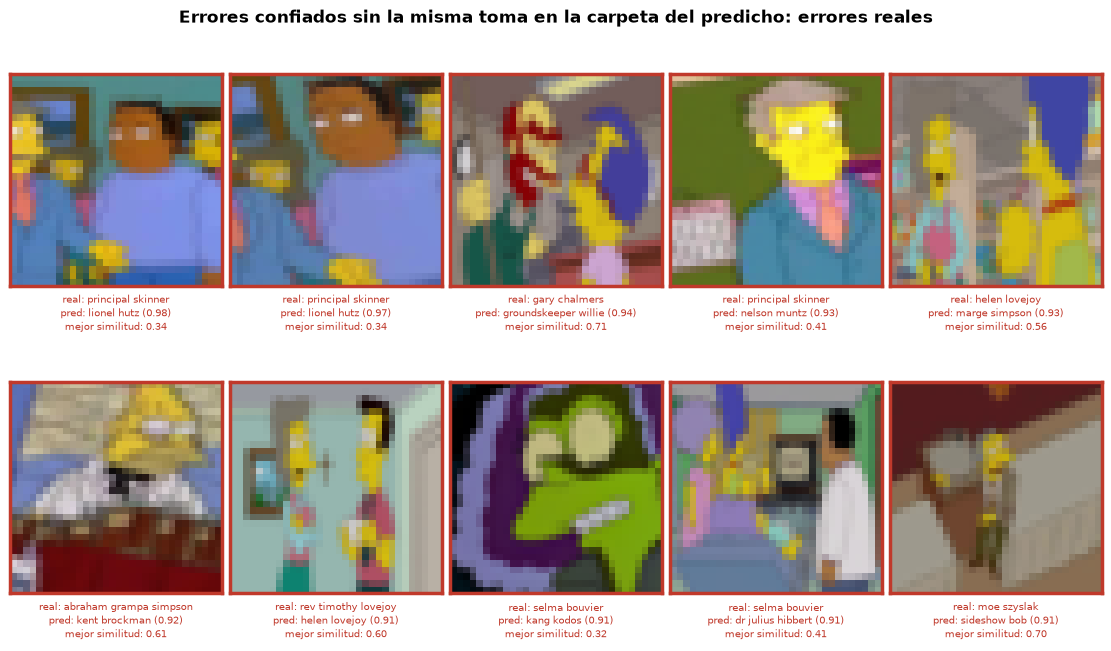

Errores con confianza > 0.80: 38   |   otro personaje en la imagen: 0   |   errores reales: 38


In [123]:
# Verificación de los errores con confianza alta: cuando el modelo nombra con seguridad a un personaje
# que no es el de la carpeta ni sale en su escena, se busca la misma toma en la carpeta de ese personaje
UMBRAL_CONFIANZA_VERIFICACION = 0.80
UMBRAL_SIMILITUD_VERIFICACION = 0.80
# Miniaturas como las del script de alteraciones: 16 x 16 a color
LADO_MINIATURA = 16
TAMANO_BLOQUE_MINIATURAS = 4096

probabilidades_test = modelo_final.predict(X_test, batch_size=256, verbose=0)
predicciones_test = probabilidades_test.argmax(axis=1)
confianza_test = probabilidades_test.max(axis=1)
# Personajes presentes según la escena del episodio y las gemelas; la verificación añade los suyos
acompanantes_test = [set(texto.split(", ")) if texto else set() for texto in datos_test["escena"]]

# Colores de las galerías de evaluación y de análisis de errores
COLOR_ACIERTO, COLOR_ESCENA, COLOR_ERROR = "#1b7f3b", "#d68910", "#c0392b"
TEXTO_RESULTADO = {COLOR_ACIERTO: "correcto", COLOR_ESCENA: "acierto por escena", COLOR_ERROR: "incorrecto"}


def miniaturas_de(lote):
    """Miniatura con la que el script de alteraciones compara las imágenes: la imagen de trabajo
    promediada por bloques hasta 16 x 16 a color, centrada y de norma 1. El producto de dos
    miniaturas es su similitud coseno."""
    paso = lote.shape[1] // LADO_MINIATURA
    vectores = (
        lote.reshape(len(lote), LADO_MINIATURA, paso, LADO_MINIATURA, paso, 3)
        .mean(axis=(2, 4), dtype=np.float32)
        .reshape(len(lote), -1)
    )
    vectores -= vectores.mean(axis=1, keepdims=True)
    return vectores / np.maximum(np.linalg.norm(vectores, axis=1, keepdims=True), 1e-6)


# Errores según la escena y las gemelas, cometidos con confianza alta
en_escena_test = np.array(
    [clases[predicho] in presentes for predicho, presentes in zip(predicciones_test, acompanantes_test)]
)
a_verificar = np.flatnonzero(
    (predicciones_test != y_test_idx) & ~en_escena_test & (confianza_test > UMBRAL_CONFIANZA_VERIFICACION)
)

COLUMNAS_VERIFICACION = [
    "indice", "carpeta", "predicho", "confianza", "similitud", "coincidencia", "conjunto_coincidencia",
    "fila_coincidencia", "otro_personaje_en_imagen",
]
filas_verificacion = []
if len(a_verificar):
    # La original de cada caso: las parecidas y las alteradas llevan un filtro que cambia la miniatura
    casos = datos_test.iloc[a_verificar]
    miniaturas_casos = miniaturas_de(
        np.stack(
            [
                cargar_y_redimensionar(DATASET_BASE / personaje / origen)
                for personaje, origen in zip(casos["personaje"], casos["origen"])
            ]
        )
    )

    # Candidatas: las originales intactas, de cualquier conjunto, de los personajes que nombró el modelo
    etiqueta_datos = datos["etiqueta"].to_numpy()
    candidatas = np.flatnonzero(
        ~datos["alterada"].to_numpy()
        & ~datos["parecida"].to_numpy()
        & np.isin(etiqueta_datos, predicciones_test[a_verificar])
    )
    miniaturas_candidatas = np.concatenate(
        [
            miniaturas_de(imagenes[candidatas[desde:desde + TAMANO_BLOQUE_MINIATURAS]])
            for desde in range(0, len(candidatas), TAMANO_BLOQUE_MINIATURAS)
        ]
    )
    etiqueta_candidatas = etiqueta_datos[candidatas]

    for miniatura_caso, indice in zip(miniaturas_casos, a_verificar):
        predicho = int(predicciones_test[indice])
        de_su_clase = np.flatnonzero(etiqueta_candidatas == predicho)
        similitudes = miniaturas_candidatas[de_su_clase] @ miniatura_caso
        mejor = int(np.argmax(similitudes))
        fila = int(candidatas[de_su_clase[mejor]])
        filas_verificacion.append(
            {
                "indice": int(indice),
                "carpeta": clases[y_test_idx[indice]],
                "predicho": clases[predicho],
                "confianza": round(float(confianza_test[indice]), 3),
                "similitud": round(float(similitudes[mejor]), 3),
                "coincidencia": datos["origen"].iloc[fila],
                "conjunto_coincidencia": datos["conjunto"].iloc[fila],
                "fila_coincidencia": fila,
                "otro_personaje_en_imagen": bool(similitudes[mejor] >= UMBRAL_SIMILITUD_VERIFICACION),
            }
        )

# Tipos explícitos: sin casos, la tabla vacía no sabría que la última columna es booleana
verificacion_test = pd.DataFrame(filas_verificacion, columns=COLUMNAS_VERIFICACION).astype(
    {"indice": int, "fila_coincidencia": int, "otro_personaje_en_imagen": bool}
)
verificados = verificacion_test[verificacion_test["otro_personaje_en_imagen"]]
errores_reales = verificacion_test[~verificacion_test["otro_personaje_en_imagen"]]

# Un caso verificado suma al predicho a los personajes presentes: desde aquí es un acierto por escena
verificado_test = np.zeros(len(y_test_idx), dtype=bool)
verificado_test[verificados["indice"].to_numpy(dtype=int)] = True
for indice in np.flatnonzero(verificado_test):
    acompanantes_test[indice].add(clases[predicciones_test[indice]])

resumen_verificacion = pd.DataFrame(
    [
        (
            f"Errores con confianza > {UMBRAL_CONFIANZA_VERIFICACION:.2f} (según escena y gemelas)",
            len(verificacion_test),
            f"{len(verificacion_test) / len(y_test_idx):.1%} del test",
        ),
        (
            f"   con la misma toma en la carpeta del predicho (similitud >= {UMBRAL_SIMILITUD_VERIFICACION:.2f})",
            len(verificados),
            f"{len(verificados) / max(len(verificacion_test), 1):.1%}: otro personaje en la imagen, acierto por escena",
        ),
        ("   sin la misma toma en esa carpeta", len(errores_reales), "errores reales"),
    ],
    columns=["Indicador", "Valor", "Detalle"],
)
display(resumen_verificacion)

if verificacion_test.empty:
    print(f"No hay errores con confianza > {UMBRAL_CONFIANZA_VERIFICACION:.2f} que verificar.")

if len(verificados):
    display(verificados[["carpeta", "predicho"]].value_counts().head(10).reset_index(name="casos"))

    # Parejas imagen de test | imagen de la misma toma en la carpeta del personaje que nombró el modelo
    PAREJAS_POR_FILA = 3
    muestra_verificados = verificados.sample(min(12, len(verificados)), random_state=SEMILLA)
    filas_figura = int(np.ceil(len(muestra_verificados) / PAREJAS_POR_FILA))
    figura, ejes = plt.subplots(
        filas_figura,
        2 * PAREJAS_POR_FILA,
        figsize=(2.0 * 2 * PAREJAS_POR_FILA, 3.0 * filas_figura),
        layout="constrained",
        squeeze=False,
    )
    parejas = ejes.reshape(-1, 2)
    for (eje_test, eje_coincidencia), caso in zip(parejas, muestra_verificados.itertuples()):
        paneles = (
            (
                eje_test,
                imagenes_test[caso.indice],
                f"test: {caso.carpeta.replace('_', ' ')}\npred: {caso.predicho.replace('_', ' ')}"
                f" ({caso.confianza:.2f})",
            ),
            (
                eje_coincidencia,
                imagenes[caso.fila_coincidencia],
                f"carpeta {caso.predicho.replace('_', ' ')}\n({caso.conjunto_coincidencia})"
                f"  similitud {caso.similitud:.2f}",
            ),
        )
        for eje, imagen, texto in paneles:
            eje.imshow(imagen)
            eje.set_xticks([])
            eje.set_yticks([])
            for lado in eje.spines.values():
                lado.set_edgecolor(COLOR_ESCENA)
                lado.set_linewidth(2.5)
            eje.set_xlabel(texto, fontsize=7, color="#9c640c", labelpad=5, linespacing=1.4)
    for eje in parejas[len(muestra_verificados):].ravel():
        eje.axis("off")
    figura.suptitle(
        "Errores confiados verificados: la misma toma está en la carpeta del personaje que nombró el modelo",
        fontsize=12,
        fontweight="bold",
    )
    plt.show()

if len(errores_reales):
    # Los errores confiados que la verificación no explica, de mayor a menor confianza
    mas_confiados = errores_reales.sort_values("confianza", ascending=False).head(10)
    figura, ejes = plt.subplots(2, 5, figsize=(11, 6.4), layout="constrained")
    ejes = np.ravel(ejes)
    for eje, caso in zip(ejes, mas_confiados.itertuples()):
        eje.imshow(imagenes_test[caso.indice])
        eje.set_xticks([])
        eje.set_yticks([])
        for lado in eje.spines.values():
            lado.set_edgecolor(COLOR_ERROR)
            lado.set_linewidth(2.5)
        eje.set_xlabel(
            f"real: {caso.carpeta.replace('_', ' ')}\npred: {caso.predicho.replace('_', ' ')} ({caso.confianza:.2f})"
            f"\nmejor similitud: {caso.similitud:.2f}",
            fontsize=7,
            color=COLOR_ERROR,
            labelpad=5,
            linespacing=1.4,
        )
    for eje in ejes[len(mas_confiados):]:
        eje.axis("off")
    figura.suptitle("Errores confiados sin la misma toma en la carpeta del predicho: errores reales", fontsize=12, fontweight="bold")
    plt.show()

print(
    f"Errores con confianza > {UMBRAL_CONFIANZA_VERIFICACION:.2f}: {len(verificacion_test)}"
    f"   |   otro personaje en la imagen: {len(verificados)}"
    f"   |   errores reales: {len(errores_reales)}"
)


### Accuracy global sobre el conjunto de prueba

In [124]:
perdida_test, accuracy_estricta_test, top3_estricto_test = modelo_final.evaluate(
    X_test, y_test, batch_size=256, verbose=0
)

# Las predicciones y los personajes presentes salen de la verificación de los errores con confianza alta.
# Criterio de acierto: la predicción es correcta si nombra al personaje de la carpeta o a otro
# que también aparece en la imagen, según la escena del episodio, una gemela guardada en la
# carpeta de otro personaje (sección «Escenas con varios personajes») o la verificación por imagen.
# La etiqueta con la que se evalúa es la de la carpeta, salvo cuando el modelo nombra a un personaje
# presente: entonces es él.
acierto_por_escena = np.array(
    [clases[predicho] in presentes for predicho, presentes in zip(predicciones_test, acompanantes_test)]
)
y_test_eval = np.where(acierto_por_escena, predicciones_test, y_test_idx)
acierto_estricto = predicciones_test == y_test_idx
acierto_test = predicciones_test == y_test_eval
accuracy_test = float(acierto_test.mean())
accuracy_tolerante_test = accuracy_test
# Con solo la escena y las gemelas: comparable con las corridas sin verificación por imagen
accuracy_sin_verificacion_test = float((acierto_test & ~verificado_test).mean())

# Top-3 con el mismo criterio: basta con que el de la carpeta o un personaje presente esté entre los tres
clases_validas_test = [
    {int(real)} | {clase_a_indice[nombre] for nombre in presentes}
    for real, presentes in zip(y_test_idx, acompanantes_test)
]
top3_por_imagen = np.array(
    [
        bool(set(mejores.tolist()) & validas)
        for mejores, validas in zip(np.argsort(-probabilidades_test, axis=1)[:, :3], clases_validas_test)
    ]
)
top3_test = float(top3_por_imagen.mean())


def color_resultado(indice):
    """Verde si el modelo nombró al personaje de la carpeta, ámbar si nombró a otro personaje
    presente en la imagen y rojo si se equivocó."""
    if acierto_estricto[indice]:
        return COLOR_ACIERTO
    return COLOR_ESCENA if acierto_por_escena[indice] else COLOR_ERROR


def rotulo_escena(indice):
    """Rótulo de un acierto por escena: por la escena y las gemelas, o por la verificación por imagen."""
    return "acierto verificado por imagen" if verificado_test[indice] else "acierto por escena"


# Baselines definidos en "Definición del problema de clasificación"
conteos_test = np.bincount(y_test_idx, minlength=NUMERO_CLASES)
baseline_azar = 1 / NUMERO_CLASES
baseline_mayoritaria = conteos_test.max() / conteos_test.sum()
f1_macro_test = f1_score(y_test_eval, predicciones_test, average="macro")
f1_ponderado_test = f1_score(y_test_eval, predicciones_test, average="weighted")
f1_macro_estricto_test = f1_score(y_test_idx, predicciones_test, average="macro")

comparacion_baselines = pd.DataFrame(
    [
        ("Clasificador aleatorio", baseline_azar, "-"),
        ("Clase mayoritaria siempre", baseline_mayoritaria, "-"),
        ("MLP final", accuracy_test, round(float(f1_macro_test), 4)),
        ("MLP final, criterio estricto", accuracy_estricta_test, round(float(f1_macro_estricto_test), 4)),
    ],
    columns=["Modelo", "Accuracy test", "F1 macro test"],
)
comparacion_baselines["Accuracy test"] = comparacion_baselines["Accuracy test"].round(4)

display(comparacion_baselines)

print(f"Perdida en test      : {perdida_test:.4f}")
print(f"Accuracy en test     : {accuracy_test:.4f}   (estricta, solo la carpeta: {accuracy_estricta_test:.4f})")
print(f"Top-3 accuracy       : {top3_test:.4f}   (estricta: {top3_estricto_test:.4f})")
print(f"F1 macro en test     : {f1_macro_test:.4f}   (estricto: {f1_macro_estricto_test:.4f})")
print(f"F1 ponderado en test : {f1_ponderado_test:.4f}")
print(
    f"Aciertos por escena  : {int(acierto_por_escena.sum())} imagenes en las que el modelo nombro"
    " a otro personaje presente"
)
print(
    f"   verificados       : {int(verificado_test.sum())} de los {len(verificacion_test)} errores con confianza"
    f" > {UMBRAL_CONFIANZA_VERIFICACION:.2f}   (accuracy sin verificar: {accuracy_sin_verificacion_test:.4f})"
)
print(
    f"\nMejora sobre el azar: x{accuracy_test / baseline_azar:.1f}   |   "
    f"sobre la clase mayoritaria: x{accuracy_test / baseline_mayoritaria:.1f}"
)


,Modelo,Accuracy test,F1 macro test
0,Clasificador aleatorio,0.0156,-
1,Clase mayoritaria siempre,0.0784,-
2,MLP final,0.5325,0.51
3,"MLP final, criterio estricto",0.4916,0.4512


Perdida en test      : 1.9944
Accuracy en test     : 0.5325   (estricta, solo la carpeta: 0.4916)
Top-3 accuracy       : 0.7182   (estricta: 0.6960)
F1 macro en test     : 0.5100   (estricto: 0.4512)
F1 ponderado en test : 0.5294
Aciertos por escena  : 207 imagenes en las que el modelo nombro a otro personaje presente
   verificados       : 0 de los 38 errores con confianza > 0.80   (accuracy sin verificar: 0.5325)

Mejora sobre el azar: x34.1   |   sobre la clase mayoritaria: x6.8


### Precision, Recall y F1-Score por clase

In [125]:
from sklearn.metrics import classification_report, precision_recall_fscore_support

# Con el criterio de acierto: la clase evaluada es la de la carpeta, o el personaje presente
# que nombró el modelo
reporte = classification_report(
    y_test_eval,
    predicciones_test,
    labels=range(NUMERO_CLASES),
    target_names=clases,
    digits=3,
    zero_division=0,
)
print(reporte)

precision, recall, f1, soporte = precision_recall_fscore_support(
    y_test_eval, predicciones_test, labels=range(NUMERO_CLASES), zero_division=0
)

metricas_por_clase = pd.DataFrame(
    {
        "personaje": clases,
        "n_test": soporte,
        "n_train": conteos_train,
        "precision": precision.round(3),
        "recall": recall.round(3),
        "f1": f1.round(3),
    }
).sort_values("f1", ascending=False, ignore_index=True)

display(metricas_por_clase)

correlacion = float(np.corrcoef(conteos_train, f1)[0, 1])
print(f"Correlacion entre imagenes de entrenamiento y F1 por clase: {correlacion:.3f}")

                             precision    recall  f1-score   support

     abraham_grampa_simpson      0.589     0.589     0.589       124
              agnes_skinner      0.406     0.302     0.347        43
     apu_nahasapeemapetilon      0.778     0.677     0.724        93
              barney_gumble      0.400     0.344     0.370        64
               bart_simpson      0.326     0.324     0.325       244
captain_horatio_mccallister      0.750     0.480     0.585        25
               carl_carlson      0.487     0.542     0.513        72
   charles_montgomery_burns      0.468     0.537     0.500       188
               chief_wiggum      0.608     0.738     0.667       187
            cletus_spuckler      0.588     0.465     0.519        43
             comic_book_guy      0.657     0.638     0.647        69
                  disco_stu      0.222     0.143     0.174        14
             dolph_starbeam      0.455     0.385     0.417        26
          dr_julius_hibbert      

,personaje,n_test,n_train,precision,recall,f1
0,louie,10,85,0.778,0.700,0.737
1,apu_nahasapeemapetilon,93,701,0.778,0.677,0.724
2,manjula_nahasapeemapetilon,21,135,0.654,0.810,0.723
3,kang_kodos,34,239,0.686,0.706,0.696
4,maude_flanders,15,122,1.000,0.533,0.696
...,...,...,...,...,...,...
59,bart_simpson,244,1691,0.326,0.324,0.325
60,professor_john_frink,63,487,0.300,0.333,0.316
61,maggie_simpson,16,115,0.400,0.125,0.190
62,disco_stu,14,92,0.222,0.143,0.174


Correlacion entre imagenes de entrenamiento y F1 por clase: 0.149


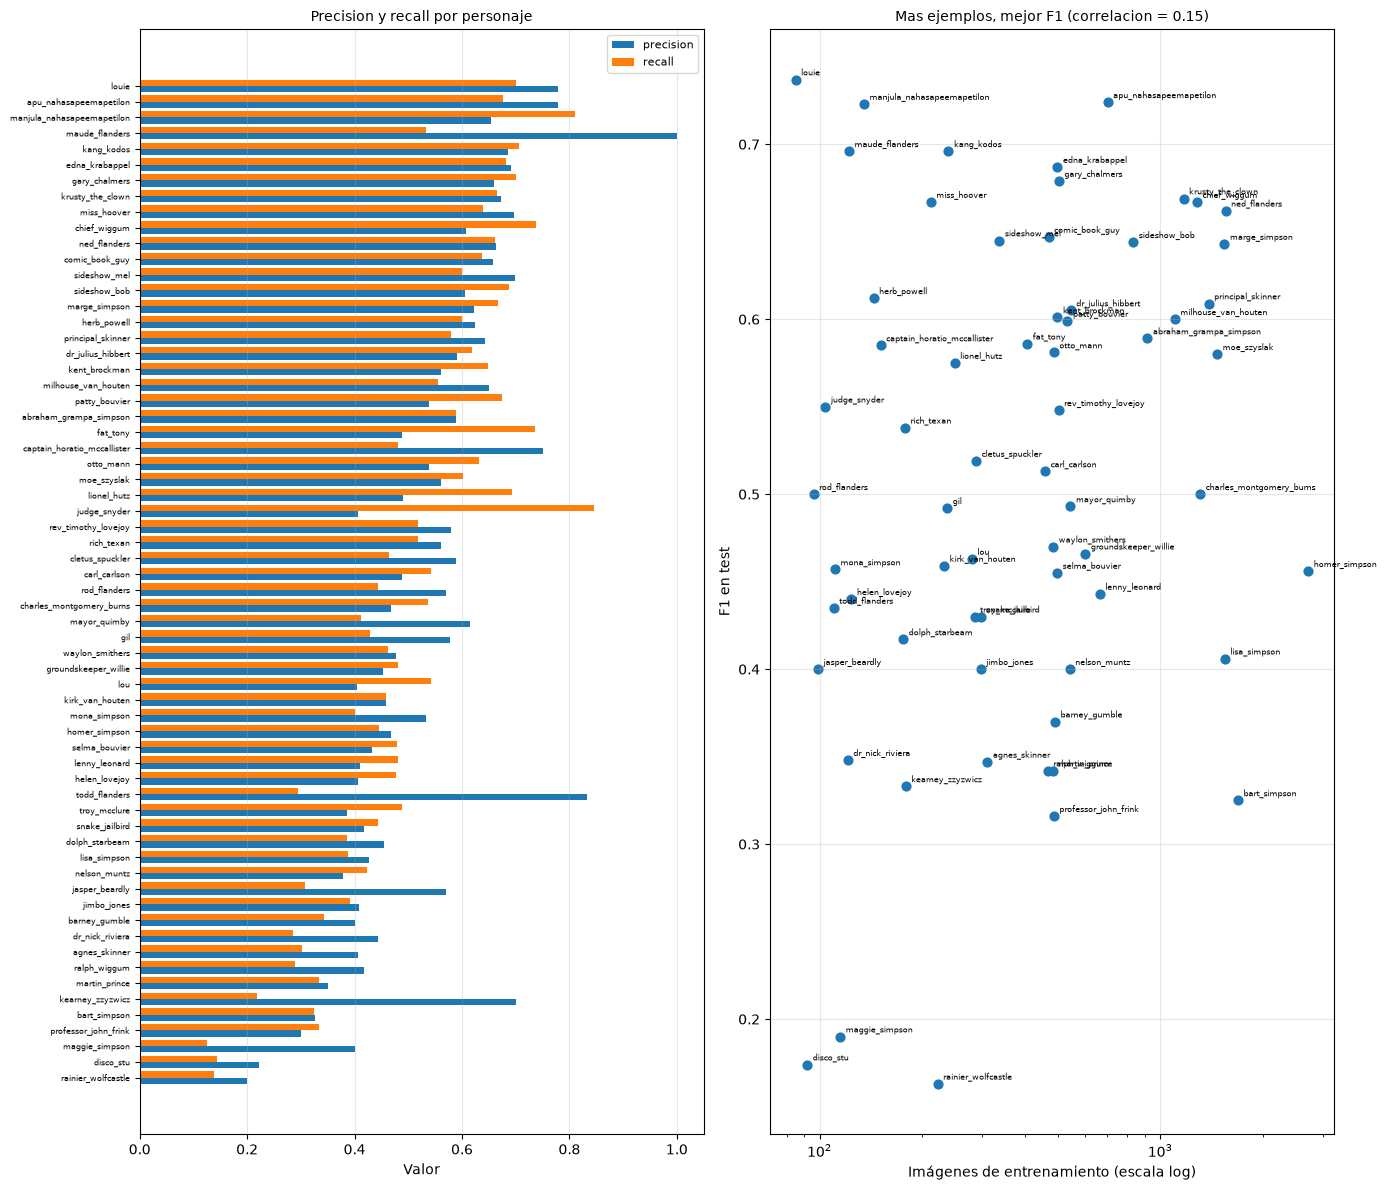

In [126]:
# Relación entre la cantidad de ejemplos de entrenamiento y el F1 alcanzado por cada clase
figura, ejes = plt.subplots(1, 2, figsize=(14, 12))

orden_f1 = metricas_por_clase.sort_values("f1")
posiciones = np.arange(len(orden_f1))
ejes[0].barh(posiciones - 0.2, orden_f1["precision"], height=0.4, label="precision")
ejes[0].barh(posiciones + 0.2, orden_f1["recall"], height=0.4, label="recall")
ejes[0].set_yticks(posiciones)
ejes[0].set_yticklabels(orden_f1["personaje"], fontsize=6)
ejes[0].set_xlabel("Valor")
ejes[0].set_title("Precision y recall por personaje", fontsize=10)
ejes[0].legend(fontsize=8)
ejes[0].grid(alpha=0.3, axis="x")

ejes[1].scatter(metricas_por_clase["n_train"], metricas_por_clase["f1"], s=40)
for _, fila in metricas_por_clase.iterrows():
    ejes[1].annotate(
        fila["personaje"],
        (fila["n_train"], fila["f1"]),
        textcoords="offset points",
        xytext=(4, 3),
        fontsize=6,
    )
ejes[1].set_xscale("log")
ejes[1].set_xlabel("Imágenes de entrenamiento (escala log)")
ejes[1].set_ylabel("F1 en test")
ejes[1].set_title(f"Mas ejemplos, mejor F1 (correlacion = {correlacion:.2f})", fontsize=10)
ejes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Lectura.** El reporte por clase muestra un patrón distinto del que haría esperar el desbalance. La
correlación entre las imágenes de entrenamiento de un personaje y su F1 es débil (0,19 en la corrida de GPU
a 64 × 64 y 0,15 en la de CPU a 32 × 32): tener muchos ejemplos ayuda poco si el personaje no tiene una
paleta propia. Los mejores F1 son de personajes con colores inconfundibles y no necesariamente frecuentes
—Apu (0,73 y 0,72), Comic Book Guy, el jefe Wiggum, Sideshow Bob; en la corrida de CPU, incluso Louie, el
personaje con menos imágenes—, mientras que Bart (0,35 y 0,33), Lisa (0,42 y 0,41) y Homero (0,48 y 0,46),
con más de 1.500 imágenes de entrenamiento cada uno, quedan en la mitad baja: comparten la piel amarilla y
salen juntos en las mismas escenas, así que sus histogramas se parecen. Marge, con su pelo azul, es la
excepción de la familia (0,67 y 0,64).

Los pesos por clase suavizados cumplen su función: ningún personaje queda en cero y el recall medio sobre
las 64 clases ronda el 51 %. Donde sí pesa el tamaño es en el extremo inferior: los personajes con F1 menor
que 0,30 tienen una mediana de 115 a 168 imágenes de entrenamiento, frente a unas 500 de los que superan
0,60. Con un centenar de imágenes la red ve pocas poses y encuadres, y los pesos no pueden inventar esa
variedad.

Conviene distinguir las dos métricas: la **precisión** responde a "de todo lo que el modelo llamó Homero,
¿cuánto era Homero?", y el **recall**, a "de todos los Homeros que había, ¿cuántos encontró?". Homero tiene
una precisión baja (0,45 en la corrida de GPU) porque el modelo lo usa como respuesta por defecto ante la
duda: la familia Simpson es el destino más frecuente de los errores de otras clases (ver «Confusiones más
frecuentes y posibles causas»).

### Matriz de confusión

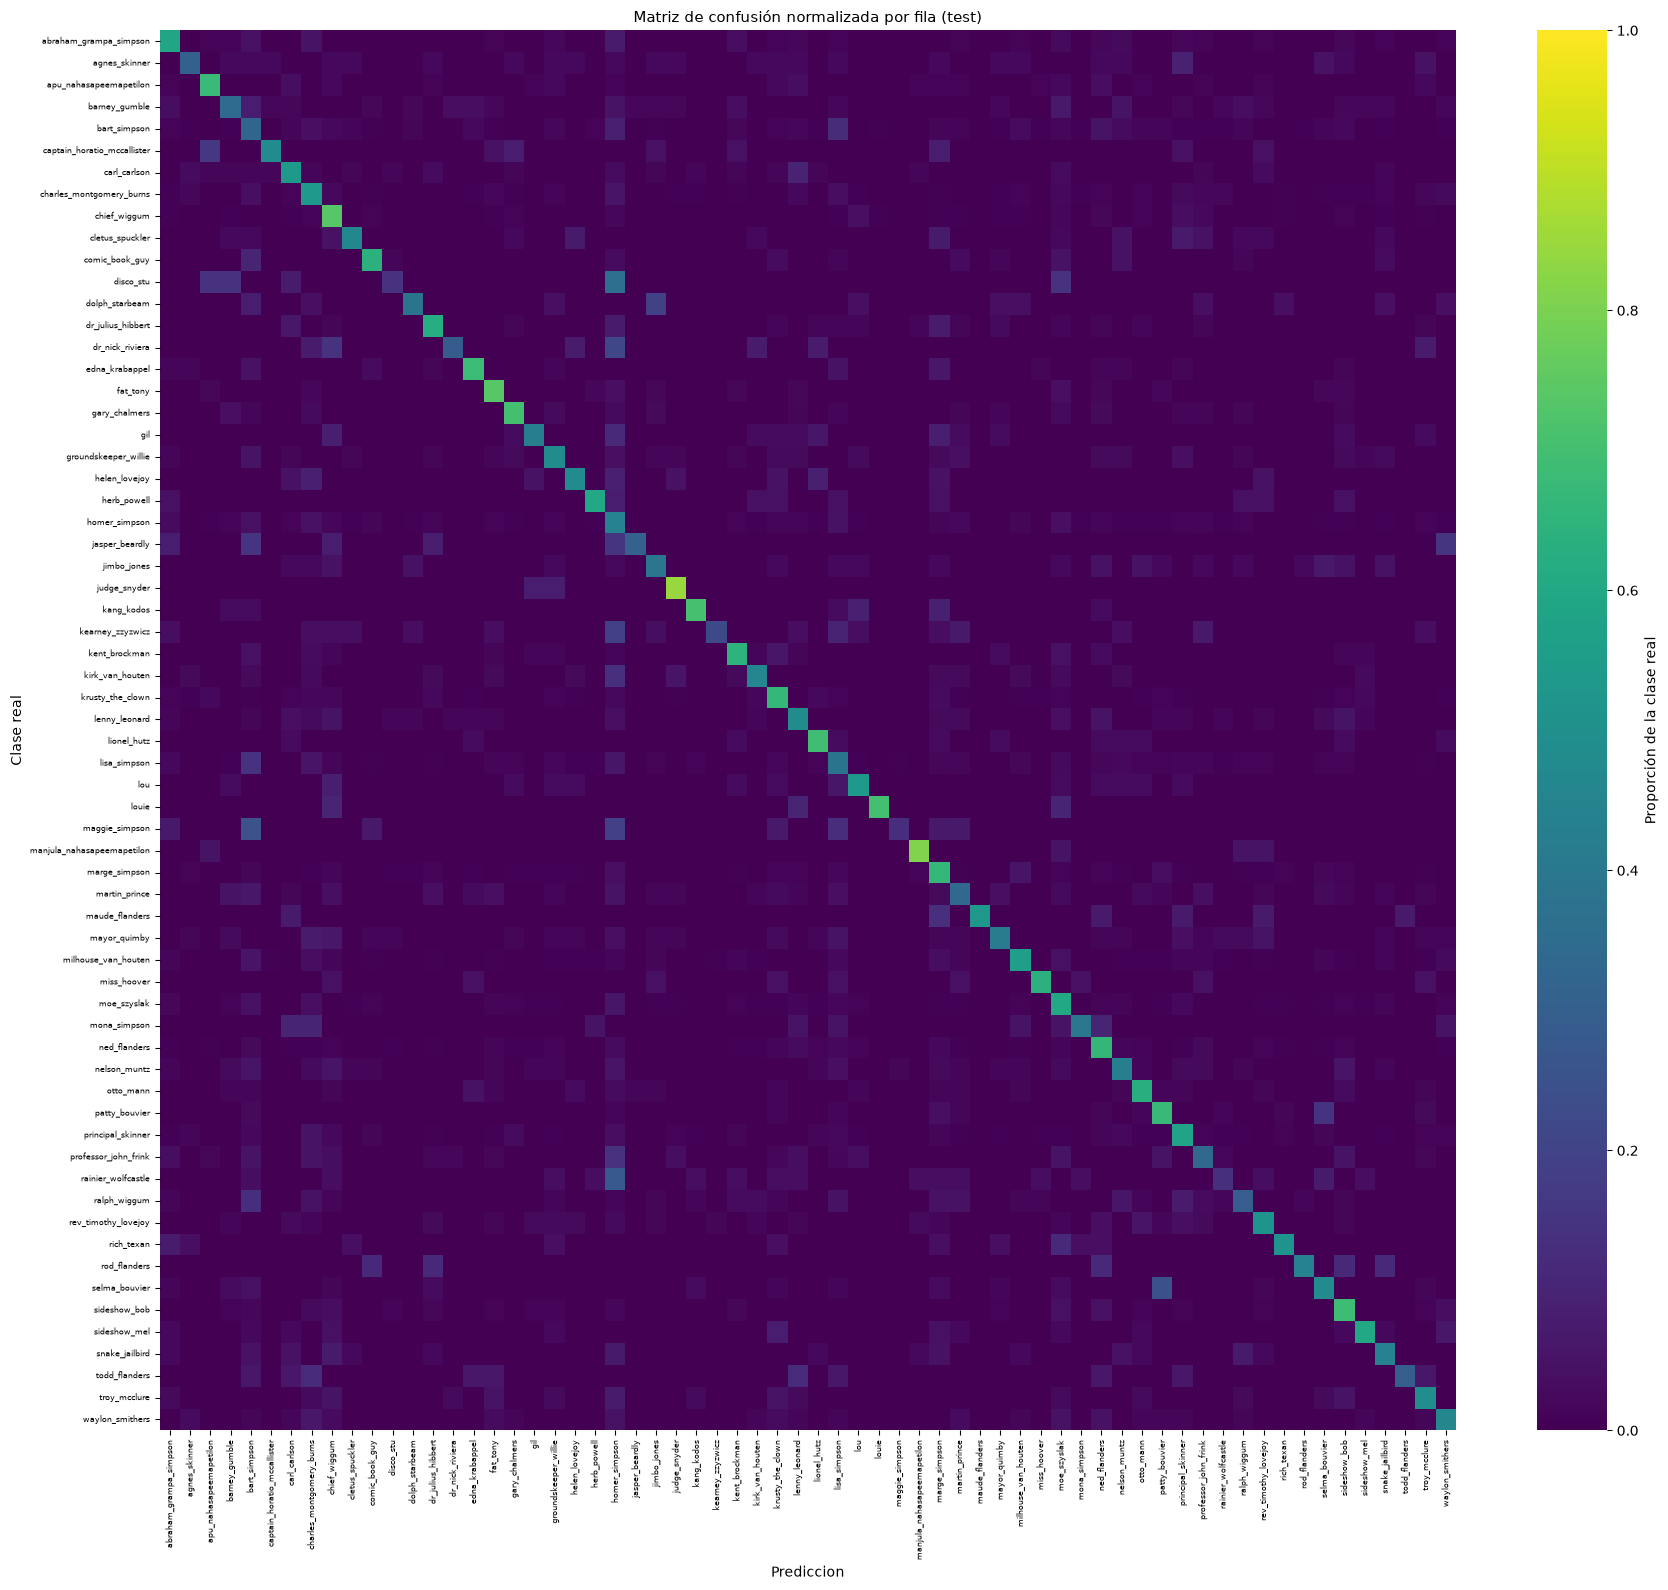

Recall medio (diagonal): 0.506
Clase mejor reconocida : judge_snyder (0.846)
Clase peor reconocida  : maggie_simpson (0.125)


In [127]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Filas: la clase evaluada (la de la carpeta, o el personaje presente que nombró el modelo)
matriz = confusion_matrix(y_test_eval, predicciones_test, labels=range(NUMERO_CLASES))
# Normalizada por fila: cada fila suma 1, de modo que el desbalance no distorsione la lectura
totales_fila = matriz.sum(axis=1, keepdims=True)
matriz_normalizada = np.divide(matriz, totales_fila, out=np.zeros(matriz.shape), where=totales_fila > 0)

figura, eje = plt.subplots(figsize=(18, 16))
sns.heatmap(
    matriz_normalizada,
    annot=False,
    cmap="viridis",
    vmin=0,
    vmax=1,
    xticklabels=clases,
    yticklabels=clases,
    cbar_kws={"label": "Proporción de la clase real"},
    ax=eje,
)
eje.set_xlabel("Prediccion")
eje.set_ylabel("Clase real")
eje.set_title("Matriz de confusión normalizada por fila (test)", fontsize=11)
plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)
plt.tight_layout()
plt.show()

aciertos_diagonal = np.diag(matriz_normalizada)
print(f"Recall medio (diagonal): {aciertos_diagonal.mean():.3f}")
print(f"Clase mejor reconocida : {clases[int(aciertos_diagonal.argmax())]} ({aciertos_diagonal.max():.3f})")
print(f"Clase peor reconocida  : {clases[int(aciertos_diagonal.argmin())]} ({aciertos_diagonal.min():.3f})")

### Interpretación crítica de las métricas

In [128]:
# Comparación de las tres lecturas globales y su distancia
resumen_metricas = pd.DataFrame(
    [
        ("Accuracy (test)", round(float(accuracy_test), 4), "Proporción de aciertos (carpeta o personaje presente); domina por las clases grandes"),
        ("Accuracy estricta (test)", round(float(accuracy_estricta_test), 4), "Solo acepta el personaje de la carpeta; referencia"),
        ("F1 ponderado (test)", round(float(f1_ponderado_test), 4), "Promedio de F1 pesado por el tamaño de cada clase"),
        ("F1 macro (test)", round(float(f1_macro_test), 4), "Promedio simple de todas las clases; cada personaje pesa igual"),
        ("Top-3 accuracy (test)", round(float(top3_test), 4), "El personaje de la carpeta o uno presente está entre las 3 más probables"),
    ],
    columns=["Metrica", "Valor", "Que mide"],
)
display(resumen_metricas)

brecha_metricas = float(accuracy_test) - float(f1_macro_test)

# Clases que el modelo prácticamente no reconoce
clases_debiles = metricas_por_clase[metricas_por_clase["f1"] < 0.30]
clases_fuertes = metricas_por_clase[metricas_por_clase["f1"] >= 0.60]

print(f"Brecha accuracy - F1 macro: {brecha_metricas:.3f}")
print(f"Clases con F1 >= 0.60 : {len(clases_fuertes)} de {NUMERO_CLASES}")
print(f"Clases con F1 <  0.30 : {len(clases_debiles)} de {NUMERO_CLASES}")
if len(clases_debiles):
    print("  " + ", ".join(clases_debiles["personaje"].tolist()))
print(
    f"\nMediana de imagenes de entrenamiento en las clases fuertes: "
    f"{clases_fuertes['n_train'].median():.0f}"
)
if len(clases_debiles):
    print(
        f"Mediana de imagenes de entrenamiento en las clases debiles : "
        f"{clases_debiles['n_train'].median():.0f}"
    )

,Metrica,Valor,Que mide
0,Accuracy (test),0.5325,Proporción de aciertos (carpeta o personaje pr...
1,Accuracy estricta (test),0.4916,Solo acepta el personaje de la carpeta; refere...
2,F1 ponderado (test),0.5294,Promedio de F1 pesado por el tamaño de cada clase
3,F1 macro (test),0.5100,Promedio simple de todas las clases; cada pers...
4,Top-3 accuracy (test),0.7182,El personaje de la carpeta o uno presente está...


Brecha accuracy - F1 macro: 0.023
Clases con F1 >= 0.60 : 20 de 64
Clases con F1 <  0.30 : 3 de 64
  maggie_simpson, disco_stu, rainier_wolfcastle

Mediana de imagenes de entrenamiento en las clases fuertes: 502
Mediana de imagenes de entrenamiento en las clases debiles : 115


**Qué revela la distancia entre las métricas.** A diferencia del dataset anterior, la accuracy y el F1
macro quedan muy cerca: entre 2 y 3 puntos de diferencia en las corridas del 16-10-2026, y el F1 ponderado
prácticamente coincide con la accuracy. El desempeño está repartido de forma bastante pareja entre
personajes grandes y pequeños: los pesos por clase y la selección por F1 macro evitan que el modelo se
concentre en los frecuentes. Lo que queda es una cola de tres o cuatro personajes con F1 menor que 0,30
—Maggie, Disco Stu y Rainier Wolfcastle están en ella en las dos corridas que conservan sus salidas— que
combinan pocas imágenes con una paleta poco distintiva.

La **accuracy estricta**, que solo acepta el personaje de la carpeta, queda entre 4 y 5 puntos por debajo
de la oficial en las seis corridas, y el F1 macro estricto, entre 6 y 7: esa diferencia son las imágenes en
las que el modelo nombró a otro personaje que sí está en la escena (sección «Escenas con varios personajes:
aciertos por escena»).

La **top-3 accuracy** supera a la accuracy en 16 a 19 puntos: en buena parte de los errores, el personaje
correcto está entre las tres candidatas más probables. El modelo extrae señal real, pero no la suficiente
para decidir entre personajes de paleta parecida, algo que un catalogador resuelve de un vistazo si el
sistema le propone tres opciones.

### Cumplimiento de los KPIs definidos

Los cinco KPIs declarados al inicio se contrastan aqui con las cifras de la prueba
final. El umbral de cada uno se fijo antes de entrenar, de modo que la tabla es una
verificacion y no una justificacion a posteriori del resultado obtenido.

In [129]:
# Verificacion de los KPIs definidos al inicio del notebook: cada umbral se fijo
# antes de evaluar, y aqui se contrasta con las cifras obtenidas en la prueba final.
import time

# Costo de catalogación de extremo a extremo: calcular la entrada del modelo a partir de
# las imágenes ya redimensionadas (los descriptores, si el modelo los usa) y pasarla por
# la red. La lectura del disco no se incluye, igual que en la corrida del dataset anterior.
inicio_inferencia = time.perf_counter()
if representacion_final == "pixeles":
    entrada_inferencia = X_test
else:
    # Solo se calculan los bloques que usa el modelo final: si es "color", ni la textura
    # ni los bordes, que son la parte más cara de los descriptores
    descriptores_test = np.concatenate(
        Parallel(n_jobs=-1)(
            delayed(extraer_lote)(
                imagenes_test[inicio:inicio + TAMANO_LOTE_DESCRIPTORES], representacion_final
            )
            for inicio in range(0, len(imagenes_test), TAMANO_LOTE_DESCRIPTORES)
        )
    )
    entrada_inferencia = a_tensor(descriptores_test)
modelo_final.predict(entrada_inferencia, batch_size=256, verbose=0)
segundos_inferencia = time.perf_counter() - inicio_inferencia
imagenes_por_segundo = len(imagenes_test) / segundos_inferencia

# La extracción parcial debe dar exactamente las mismas columnas que se usaron al evaluar
if representacion_final != "pixeles" and not np.array_equal(
    descriptores_test, particion(representacion_final)["test"]
):
    raise ValueError("Los descriptores de la inferencia no coinciden con los de la evaluación.")

ventaja_mayoritaria = float(accuracy_test) / baseline_mayoritaria

kpis = [
    ("Cobertura de asistencia", "Top-3 accuracy", 0.70, float(top3_test), "{:.4f}"),
    ("Equidad entre personajes", "F1 macro", 0.45, float(f1_macro_test), "{:.4f}"),
    ("Automatizacion sin revision", "Accuracy", 0.50, float(accuracy_test), "{:.4f}"),
    ("Ventaja sobre criterio trivial", "Accuracy / mayoritaria", 4.0, ventaja_mayoritaria, "x{:.1f}"),
    ("Costo de catalogacion", "Imagenes por segundo (entrada + red)", 1000.0, imagenes_por_segundo, "{:,.0f}"),
]

tabla_kpis = pd.DataFrame(
    [
        {
            "KPI": nombre,
            "Metrica": metrica,
            "Umbral": formato.format(umbral),
            "Obtenido": formato.format(obtenido),
            "Cumple": "SI" if obtenido >= umbral else "NO",
        }
        for nombre, metrica, umbral, obtenido, formato in kpis
    ]
)

cumplidos = sum(1 for _, _, umbral, obtenido, _ in kpis if obtenido >= umbral)
print(f"KPIs cumplidos: {cumplidos} de {len(kpis)}\n")
display(tabla_kpis)

KPIs cumplidos: 5 de 5



,KPI,Metrica,Umbral,Obtenido,Cumple
0,Cobertura de asistencia,Top-3 accuracy,0.7000,0.7182,SI
1,Equidad entre personajes,F1 macro,0.4500,0.5100,SI
2,Automatizacion sin revision,Accuracy,0.5000,0.5325,SI
3,Ventaja sobre criterio trivial,Accuracy / mayoritaria,x4.0,x6.8,SI
4,Costo de catalogacion,Imagenes por segundo (entrada + red),"1,000","1,557",SI


## Análisis de resultados y de errores

### El modelo en acción sobre el conjunto de test

Las métricas anteriores resumen miles de decisiones en cuatro números. Esta sección hace lo contrario:
toma imágenes concretas del conjunto de test —las que el modelo nunca vio— y muestra el proceso completo,
desde el vector de entrada hasta la distribución de probabilidad de salida.

El primer gráfico recorre una imagen a través de la red **ya entrenada**. Es el mismo diagrama que se
mostró en los fundamentos con pesos aleatorios, pero ahora las activaciones son el resultado del
aprendizaje: se puede comparar directamente el reparto plano de entonces con la distribución concentrada
de ahora.

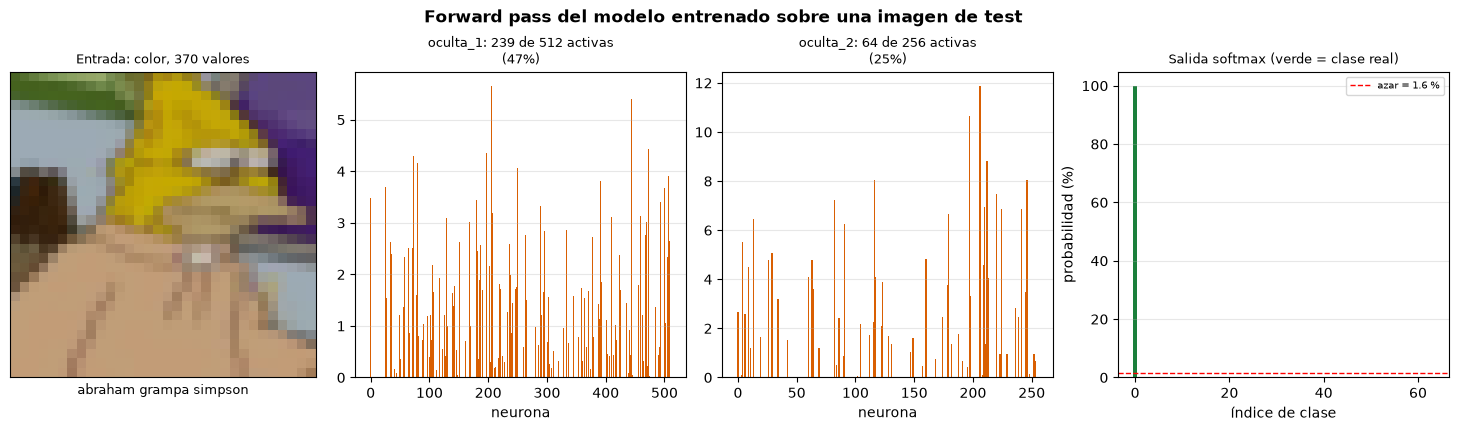

Prediccion: abraham_grampa_simpson con 99.8 % de confianza   |   clase real: abraham_grampa_simpson
Frente al 1.6 % que asignaria el azar: la red ya no reparte la probabilidad, la concentra.


In [130]:
# Recorrido de una imagen del conjunto de test por la red entrenada:
# del vector de entrada a las probabilidades de salida
demo_aciertos = np.flatnonzero(predicciones_test == y_test_idx)
demo_indice = int(demo_aciertos[np.argsort(-confianza_test[demo_aciertos])][0])

# Activaciones capa a capa: cada capa se aplica sobre la salida de la anterior.
# training=False apaga el Dropout y hace que BatchNormalization use sus estadísticas acumuladas.
# Los tensores de PyTorch se pasan a NumPy para graficarlos (detach: sin gradiente).
activaciones = {}
tensor_demo = X_test[demo_indice : demo_indice + 1]
for capa in modelo_final.layers:
    tensor_demo = capa(tensor_demo, training=False)
    activaciones[capa.name] = tensor_demo.detach().cpu().numpy()[0]

nombres_ocultas = [
    capa.name
    for capa in modelo_final.layers
    if isinstance(capa, layers.Dense) and capa.name != "salida"
]
salida_demo = activaciones["salida"]
real_demo = int(y_test_idx[demo_indice])

figura = plt.figure(
    figsize=(4.2 + 3.2 * len(nombres_ocultas) + 4.0, 4.2), layout="constrained"
)
malla = figura.add_gridspec(1, len(nombres_ocultas) + 2)

# Entrada: la imagen de test. El modelo no recibe estos píxeles tal cual, sino su
# vector de entrada: píxeles aplanados o descriptores, según la representación.
eje_entrada = figura.add_subplot(malla[0, 0])
eje_entrada.imshow(imagenes_test[demo_indice])
eje_entrada.set_title(f"Entrada: {representacion_final}, {X_test.shape[1]:,} valores", fontsize=9)
eje_entrada.set_xlabel(clases[real_demo].replace("_", " "), fontsize=9)
eje_entrada.set_xticks([])
eje_entrada.set_yticks([])

# Capas ocultas: activación de cada neurona para esta imagen
for posicion, nombre_capa in enumerate(nombres_ocultas, start=1):
    valores = activaciones[nombre_capa]
    eje = figura.add_subplot(malla[0, posicion])
    eje.bar(
        range(len(valores)),
        valores,
        width=1.0,
        color=["#d95f02" if v > 0 else "#cccccc" for v in valores],
    )
    activas = int((valores > 0).sum())
    eje.set_title(
        f"{nombre_capa}: {activas} de {len(valores)} activas"
        f"\n({activas / len(valores):.0%})",
        fontsize=9,
    )
    eje.set_xlabel("neurona")
    eje.grid(alpha=0.3, axis="y")

# Salida: distribución softmax sobre todas las clases
eje_salida = figura.add_subplot(malla[0, -1])
eje_salida.bar(
    range(NUMERO_CLASES),
    salida_demo * 100,
    color=["#1b7f3b" if i == real_demo else "#8fb8de" for i in range(NUMERO_CLASES)],
)
eje_salida.axhline(
    100 / NUMERO_CLASES,
    color="red",
    linestyle="--",
    linewidth=1,
    label=f"azar = {100 / NUMERO_CLASES:.1f} %",
)
eje_salida.set_title("Salida softmax (verde = clase real)", fontsize=9)
eje_salida.set_xlabel("índice de clase")
eje_salida.set_ylabel("probabilidad (%)")
eje_salida.legend(fontsize=7)
eje_salida.grid(alpha=0.3, axis="y")

figura.suptitle(
    "Forward pass del modelo entrenado sobre una imagen de test",
    fontsize=12,
    fontweight="bold",
)
plt.show()

print(
    f"Prediccion: {clases[int(salida_demo.argmax())]} con {salida_demo.max() * 100:.1f} % de confianza"
    f"   |   clase real: {clases[real_demo]}"
)
print(
    f"Frente al {100 / NUMERO_CLASES:.1f} % que asignaria el azar: la red ya no reparte la"
    " probabilidad, la concentra."
)

**Qué muestra el recorrido.** Dos cosas cambian respecto de la red sin entrenar. En las capas ocultas solo
una parte de las neuronas se activa para esta imagen —en la corrida de GPU a 64 × 64, el 40 % de la primera
capa y el 29 % de la segunda; el resto queda en cero por efecto de ReLU—: la representación es
**dispersa**, y qué subconjunto se enciende es lo que codifica al personaje. En la salida, la probabilidad
deja de repartirse entre las 64 clases y se concentra casi toda en una sola: el acierto más seguro del test
recibe un 99,8 % de probabilidad, frente al 1,6 % que daría el azar.

Conviene recordar que la imagen de la izquierda no es lo que recibe el modelo. Con la entrada de solo
color, que eligió la experimentación en todas las corridas, la red ve 370 números: la proporción de cada
tono, saturación, brillo y color Lab en la imagen completa y en cada uno de sus cuatro cuadrantes. La forma
del personaje y su posición dentro de cada cuadrante no llegan a la red.

#### Predicciones individuales: las cinco clases más probables

En lugar de quedarse con la clase ganadora, aquí se abre la distribución completa. La barra de cada
candidata muestra cuánta probabilidad le asignó el modelo, lo que permite distinguir entre una decisión
tomada con holgura y una en la que dos personajes quedaron casi empatados.

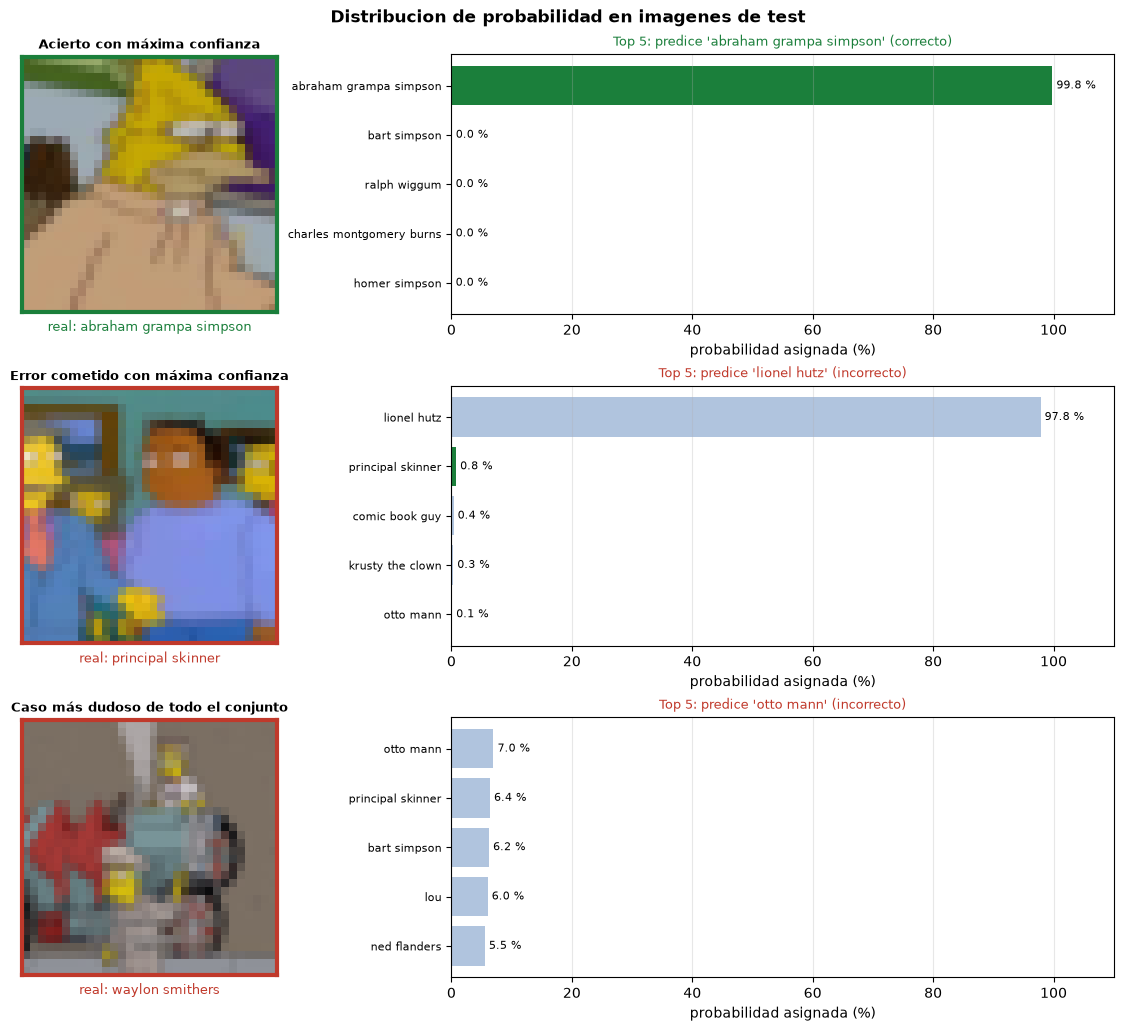

In [131]:
# Tres casos representativos: un acierto seguro, un error seguro y un caso donde el modelo dudó
# Errores según el criterio de acierto: nombrar a otro personaje presente no es un error
demo_errores = np.flatnonzero(~acierto_test)

casos = [
    (int(demo_aciertos[np.argmax(confianza_test[demo_aciertos])]), "Acierto con máxima confianza"),
    (int(demo_errores[np.argmax(confianza_test[demo_errores])]), "Error cometido con máxima confianza"),
    (int(np.argmin(confianza_test)), "Caso más dudoso de todo el conjunto"),
]

TOP_K = 5
figura, ejes = plt.subplots(
    len(casos),
    2,
    figsize=(11, 3.4 * len(casos)),
    layout="constrained",
    gridspec_kw={"width_ratios": [1, 2.6]},
)

for fila, (indice, descripcion) in enumerate(casos):
    real = int(y_test_idx[indice])
    predicho = int(predicciones_test[indice])
    color = color_resultado(indice)

    eje_imagen = ejes[fila, 0]
    eje_imagen.imshow(imagenes_test[indice])
    eje_imagen.set_xticks([])
    eje_imagen.set_yticks([])
    for lado in eje_imagen.spines.values():
        lado.set_edgecolor(color)
        lado.set_linewidth(3)
    eje_imagen.set_xlabel(
        f"real: {clases[real].replace('_', ' ')}", fontsize=9, labelpad=6, color=color
    )
    eje_imagen.set_title(descripcion, fontsize=9, fontweight="bold")

    # Las TOP_K clases con mayor probabilidad, dibujadas de mayor a menor
    mejores = np.argsort(-probabilidades_test[indice])[:TOP_K][::-1]
    etiquetas = [clases[i].replace("_", " ") for i in mejores]
    colores = [
        COLOR_ACIERTO if i == real else COLOR_ESCENA if clases[i] in acompanantes_test[indice] else "#b0c4de"
        for i in mejores
    ]

    eje_barras = ejes[fila, 1]
    barras = eje_barras.barh(etiquetas, probabilidades_test[indice][mejores] * 100, color=colores)
    eje_barras.bar_label(barras, fmt="%.1f %%", fontsize=8, padding=3)
    eje_barras.set_xlim(0, 110)
    eje_barras.set_xlabel("probabilidad asignada (%)")
    eje_barras.tick_params(axis="y", labelsize=8)
    eje_barras.grid(alpha=0.3, axis="x")
    eje_barras.set_title(
        f"Top {TOP_K}: predice '{clases[predicho].replace('_', ' ')}'"
        f" ({TEXTO_RESULTADO[color]})",
        fontsize=9,
        color=color,
    )

figura.suptitle(
    "Distribucion de probabilidad en imagenes de test",
    fontsize=12,
    fontweight="bold",
)
plt.show()

#### Muestra aleatoria: el modelo trabajando sin filtros

Los ejemplos anteriores están elegidos a propósito por ser extremos. La rejilla siguiente toma una
muestra **al azar** del conjunto de test, sin seleccionar nada: es la imagen más honesta del
comportamiento real del modelo, y la proporción de marcos verdes debería parecerse a la accuracy global.

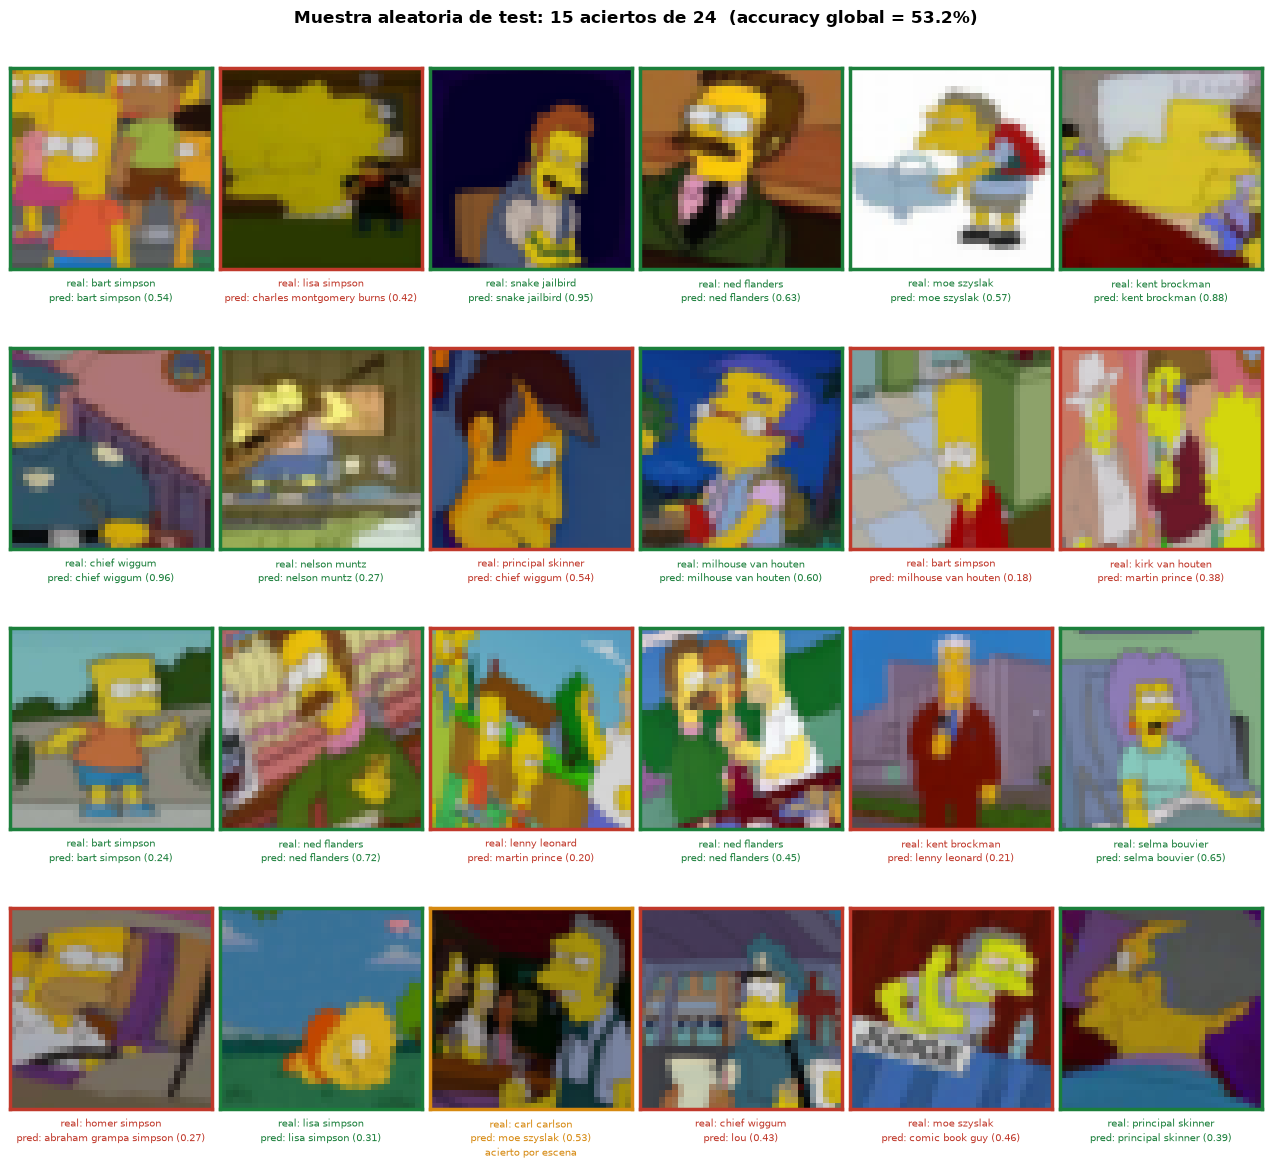

In [132]:
# Muestra aleatoria sin seleccionar: marco verde si acertó, ámbar si nombró a otro personaje
# presente y rojo si falló
FILAS_MOSAICO, COLUMNAS_MOSAICO = 4, 6
generador_muestra = np.random.default_rng(SEMILLA)
muestra_aleatoria = generador_muestra.choice(
    len(y_test_idx), size=FILAS_MOSAICO * COLUMNAS_MOSAICO, replace=False
)

figura, ejes = plt.subplots(
    FILAS_MOSAICO,
    COLUMNAS_MOSAICO,
    figsize=(2.1 * COLUMNAS_MOSAICO, 2.9 * FILAS_MOSAICO),
    layout="constrained",
)

for eje, indice in zip(np.ravel(ejes), muestra_aleatoria):
    real = clases[y_test_idx[indice]].replace("_", " ")
    predicho = clases[predicciones_test[indice]].replace("_", " ")
    color = color_resultado(indice)

    eje.imshow(imagenes_test[indice])
    eje.set_xticks([])
    eje.set_yticks([])
    for lado in eje.spines.values():
        lado.set_edgecolor(color)
        lado.set_linewidth(2.5)
    eje.set_xlabel(
        f"real: {real}\npred: {predicho} ({confianza_test[indice]:.2f})"
        + (f"\n{rotulo_escena(indice)}" if color == COLOR_ESCENA else ""),
        fontsize=7,
        color=color,
        labelpad=5,
        linespacing=1.5,
    )

aciertos_muestra = int(acierto_test[muestra_aleatoria].sum())
figura.suptitle(
    f"Muestra aleatoria de test: {aciertos_muestra} aciertos"
    f" de {len(muestra_aleatoria)}  (accuracy global = {accuracy_test:.1%})",
    fontsize=12,
    fontweight="bold",
)
plt.show()

#### Rendimiento por personaje, con una imagen de cada uno

La tabla de métricas por clase es precisa pero abstracta. Esta galería le pone cara: un ejemplo real de
cada uno de los 64 personajes, con el marco coloreado según el **recall** que el modelo alcanza en esa
clase —verde si la reconoce casi siempre, rojo si se le escapa casi siempre—. Se ve de un vistazo que
las clases en rojo son las minoritarias.

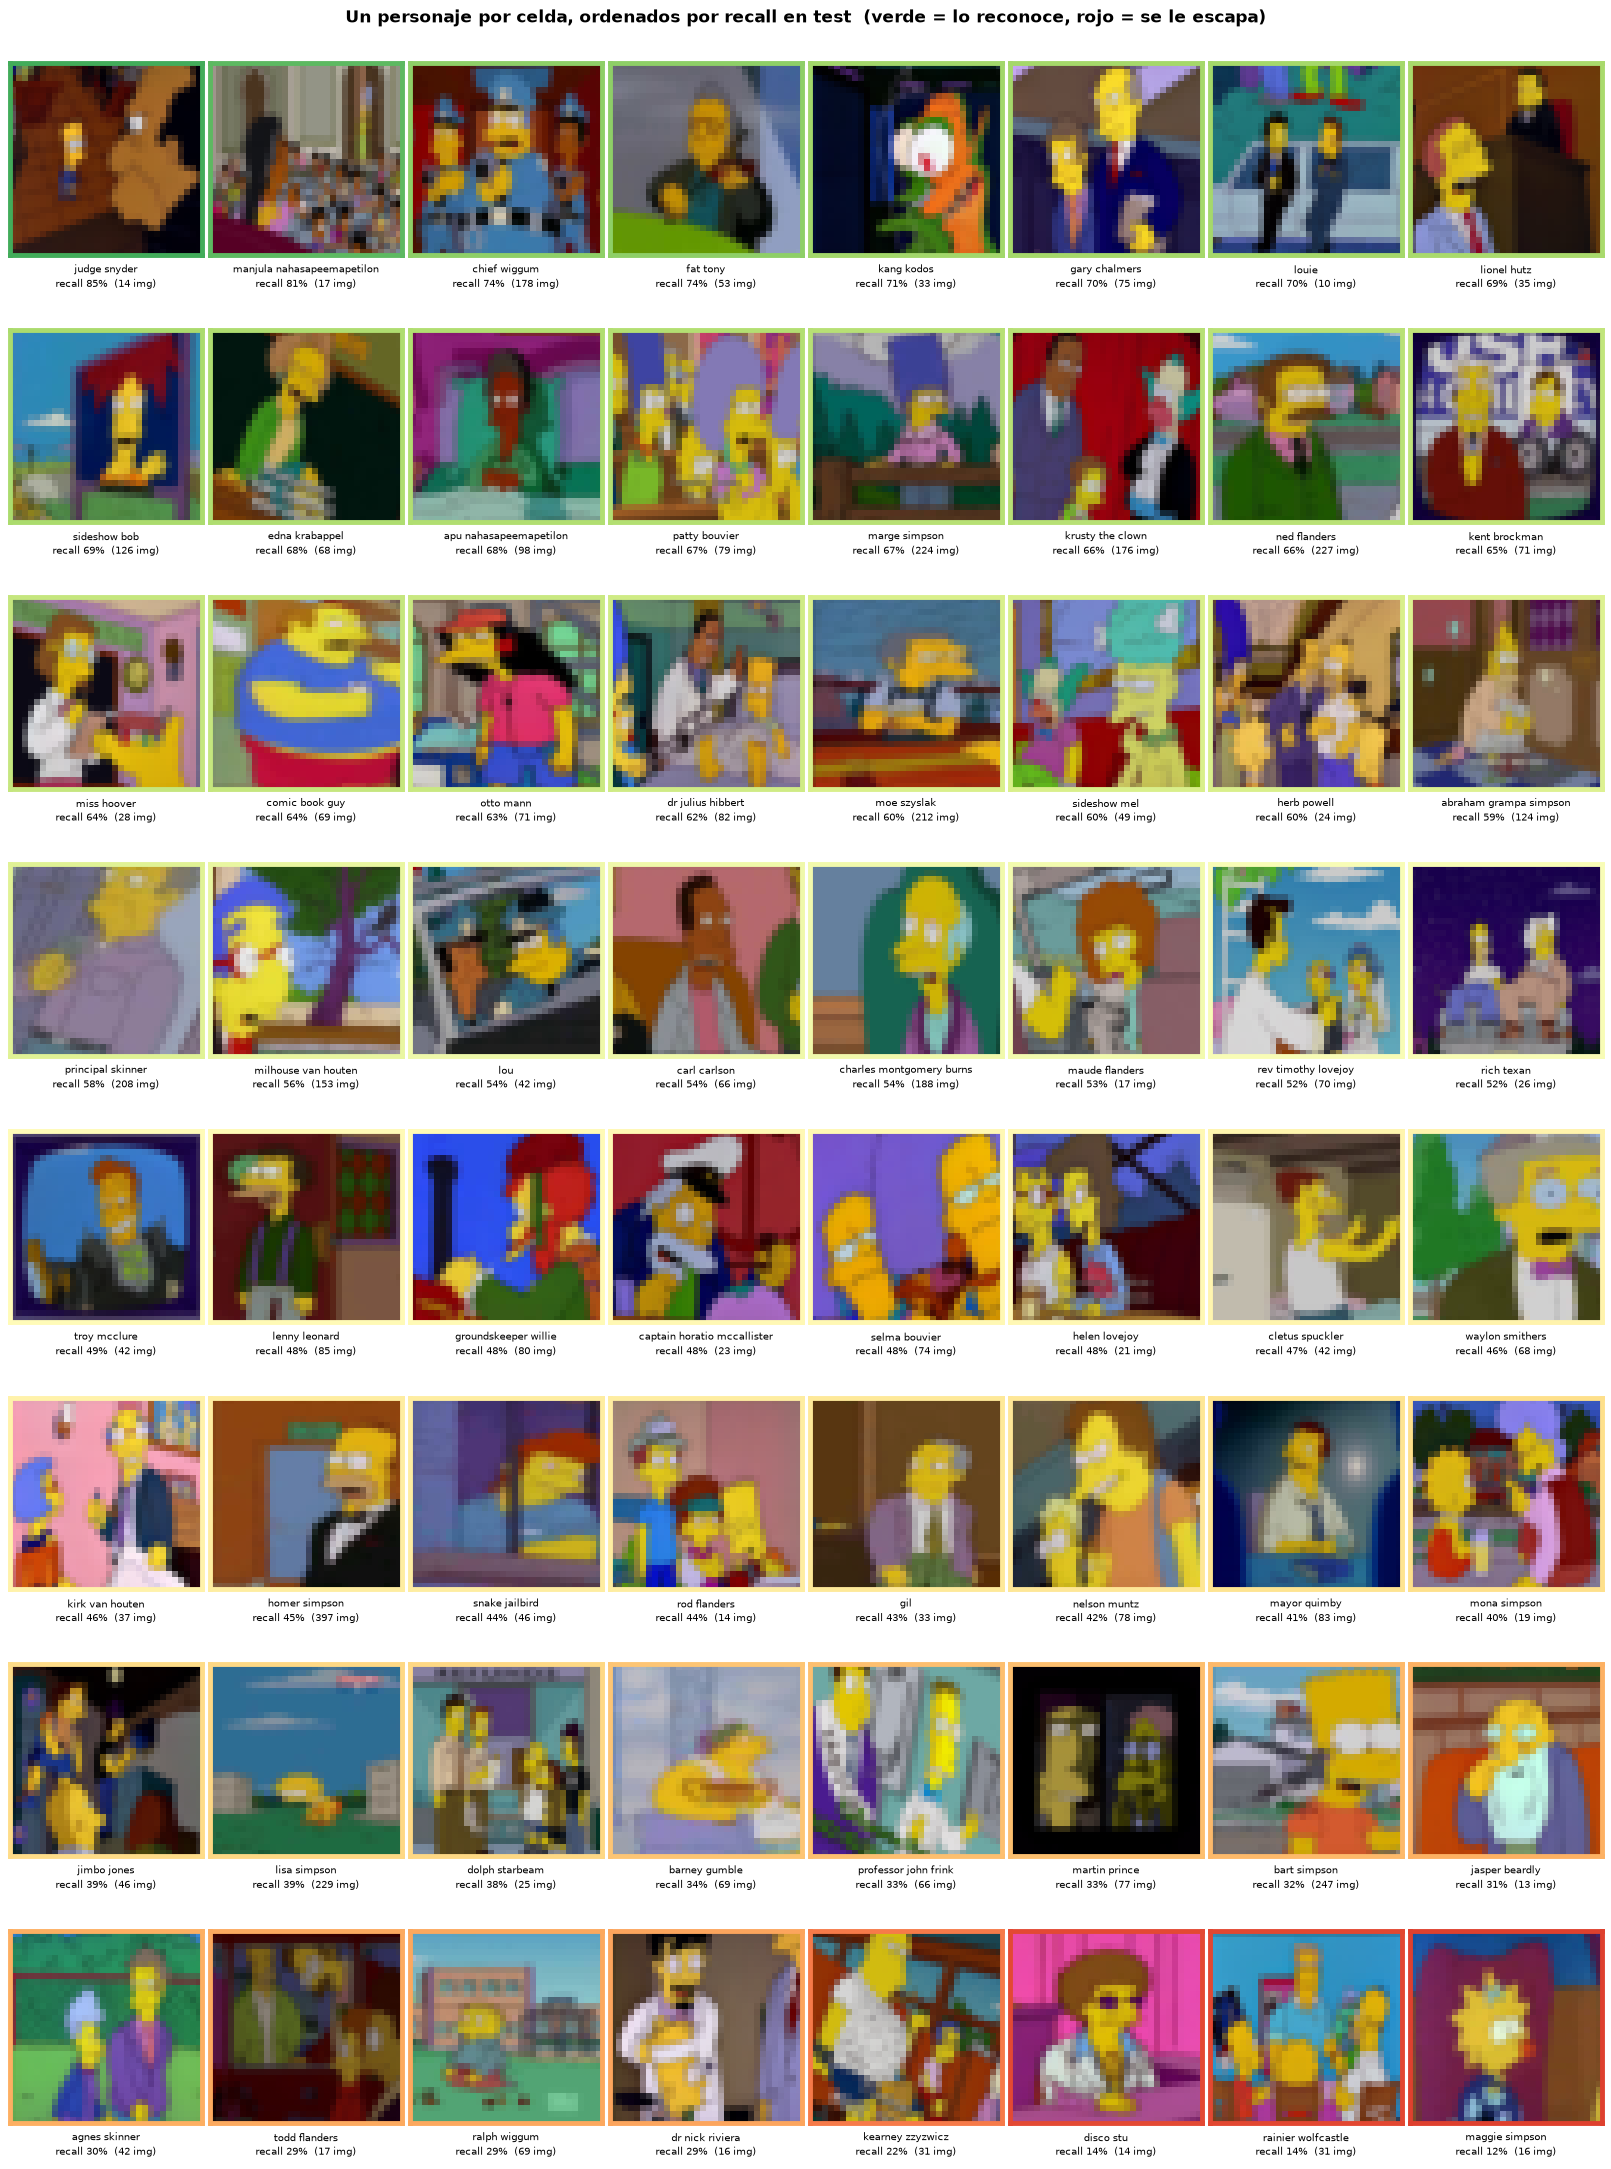

Recall medio sobre las 64 clases: 50.6%
Mejor: judge_snyder (85%)   |   Peor: maggie_simpson (12%)


In [133]:
# Una imagen por personaje, con el marco coloreado según el recall de esa clase
recall_por_clase = np.diag(matriz_normalizada)
mapa_color = plt.get_cmap("RdYlGn")

FILAS_GALERIA = 8
COLUMNAS_GALERIA = int(np.ceil(NUMERO_CLASES / FILAS_GALERIA))

figura, ejes = plt.subplots(
    FILAS_GALERIA,
    COLUMNAS_GALERIA,
    figsize=(2.0 * COLUMNAS_GALERIA, 2.7 * FILAS_GALERIA),
    layout="constrained",
)
ejes = np.ravel(ejes)

# Se recorren las clases de mejor a peor recall, para que la degradación sea visible
orden_clases = np.argsort(-recall_por_clase)

for eje, clase in zip(ejes, orden_clases):
    indices_clase = np.flatnonzero(y_test_idx == clase)
    # Se prefiere una imagen acertada; si el modelo no acierta ninguna, se usa la primera disponible
    correctas = indices_clase[predicciones_test[indices_clase] == clase]
    indice = int(correctas[0]) if len(correctas) else int(indices_clase[0])

    eje.imshow(imagenes_test[indice])
    eje.set_xticks([])
    eje.set_yticks([])
    for lado in eje.spines.values():
        lado.set_edgecolor(mapa_color(recall_por_clase[clase]))
        lado.set_linewidth(3.5)
    eje.set_xlabel(
        f"{clases[clase].replace('_', ' ')}\nrecall {recall_por_clase[clase]:.0%}"
        f"  ({len(indices_clase)} img)",
        fontsize=7,
        labelpad=5,
        linespacing=1.5,
    )

for eje in ejes[NUMERO_CLASES:]:
    eje.axis("off")

figura.suptitle(
    "Un personaje por celda, ordenados por recall en test"
    "  (verde = lo reconoce, rojo = se le escapa)",
    fontsize=12,
    fontweight="bold",
)
plt.show()

print(f"Recall medio sobre las {NUMERO_CLASES} clases: {recall_por_clase.mean():.1%}")
print(
    f"Mejor: {clases[int(orden_clases[0])]} ({recall_por_clase[orden_clases[0]]:.0%})"
    f"   |   Peor: {clases[int(orden_clases[-1])]} ({recall_por_clase[orden_clases[-1]]:.0%})"
)

#### En qué se apoya el modelo

Hasta aquí se ha visto **qué** responde el modelo; este último análisis muestra **en qué se apoya** para
responderlo. Cómo se mide depende de la representación del modelo elegido:

- **Con píxeles**, se calcula el gradiente de la probabilidad de la clase predicha respecto de cada píxel
  de entrada: donde el gradiente es grande, un cambio pequeño en ese píxel alteraría mucho la decisión.
  El resultado es un *mapa de saliencia* dibujado sobre la imagen.
- **Con descriptores**, un gradiente por intervalo de histograma no se puede dibujar sobre la imagen. En
  su lugar se mide la **importancia por permutación de cada bloque**: se barajan entre las imágenes de
  test las columnas de un bloque (por ejemplo, todo el color HSV) y se observa cuánto cae el F1 macro. Si
  un bloque no aporta nada, barajarlo no cambia el resultado; si el modelo depende de él, el F1 se hunde.

,bloque,valores,caida_f1_macro,desviacion
0,color_hsv,170,0.3731,0.0039
1,color_lab,200,0.3603,0.0069


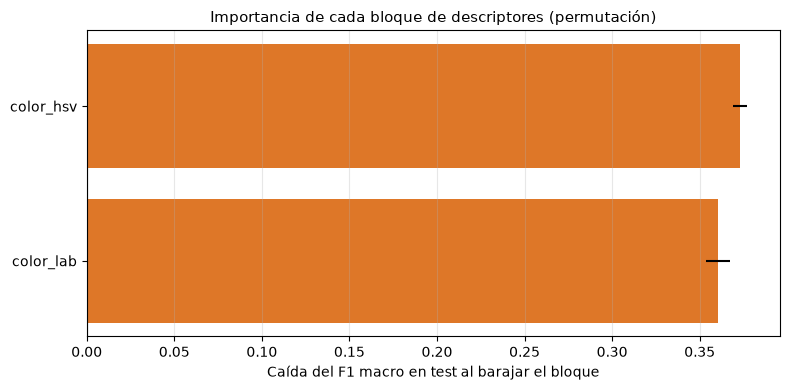

F1 macro de referencia en test: 0.4512
El bloque del que mas depende el modelo es color_hsv: barajarlo baja el F1 macro en 0.3731.


In [134]:
# Con píxeles: mapa de saliencia. Con descriptores: importancia por permutación
# de cada bloque, porque un gradiente por intervalo de histograma no se dibuja sobre la imagen.
if representacion_final == "pixeles":
    # Mapa de saliencia: cuánto cambia la probabilidad de la clase predicha al perturbar cada píxel
    indices_saliencia = list(demo_aciertos[np.argsort(-confianza_test[demo_aciertos])][:2]) + list(
        demo_errores[np.argsort(-confianza_test[demo_errores])][:2]
    )

    # El gradiente se toma respecto de la ENTRADA, no de los pesos: se pide a PyTorch
    # que rastree la entrada y se propaga hacia atras la probabilidad de la clase predicha.
    # Se parte del uint8 original y se pasa a float porque el gradiente necesita un tipo continuo;
    # la capa Rescaling del modelo divide despues por 255, asi que la escala es la de siempre.
    entrada_saliencia = X_test[indices_saliencia].float().requires_grad_(True)
    clases_predichas = torch.as_tensor(
        predicciones_test[indices_saliencia], dtype=torch.long, device=entrada_saliencia.device
    )

    salidas = modelo_final(entrada_saliencia, training=False)
    # Probabilidad que el modelo asignó a la clase que efectivamente predijo
    puntajes = salidas.gather(1, clases_predichas.unsqueeze(1)).sum()
    puntajes.backward()

    gradientes = entrada_saliencia.grad.detach().cpu().numpy()
    # Valor absoluto y resumen de los tres canales RGB en un único mapa por imagen
    saliencia = np.abs(gradientes).reshape(-1, ALTO_OBJETIVO, ANCHO_OBJETIVO, 3).max(axis=-1)


    def suavizar(mapas, radio=2):
        """Promedia cada píxel con sus vecinos. El gradiente píxel a píxel es muy ruidoso;
        suavizarlo deja ver si la importancia forma regiones o está repartida por todo el encuadre."""
        acumulado = np.zeros_like(mapas)
        for desplazamiento_y in range(-radio, radio + 1):
            for desplazamiento_x in range(-radio, radio + 1):
                acumulado += np.roll(
                    np.roll(mapas, desplazamiento_y, axis=1), desplazamiento_x, axis=2
                )
        return acumulado / (2 * radio + 1) ** 2


    saliencia_suave = suavizar(saliencia)

    figura, ejes = plt.subplots(
        2,
        len(indices_saliencia),
        figsize=(2.4 * len(indices_saliencia), 5.8),
        layout="constrained",
    )

    for columna, indice in enumerate(indices_saliencia):
        real = clases[y_test_idx[indice]].replace("_", " ")
        predicho = clases[predicciones_test[indice]].replace("_", " ")
        acierto = y_test_idx[indice] == predicciones_test[indice]
        color = "#1b7f3b" if acierto else "#c0392b"

        ejes[0, columna].imshow(imagenes_test[indice])
        ejes[1, columna].imshow(saliencia_suave[columna], cmap="inferno")

        ejes[0, columna].set_xlabel(
            f"real: {real}\npred: {predicho}",
            fontsize=8,
            color=color,
            labelpad=6,
            linespacing=1.5,
        )

        for eje in (ejes[0, columna], ejes[1, columna]):
            eje.set_xticks([])
            eje.set_yticks([])
            for lado in eje.spines.values():
                lado.set_edgecolor(color)
                lado.set_linewidth(2)

    ejes[0, 0].set_ylabel("Imagen", fontsize=10, fontweight="bold", labelpad=8)
    ejes[1, 0].set_ylabel("Saliencia", fontsize=10, fontweight="bold", labelpad=8)
    figura.suptitle(
        "Zonas que determinan la decisión (dos aciertos y dos errores confiados)",
        fontsize=12,
        fontweight="bold",
    )
    plt.show()

    # Que parte de la influencia total se concentra en el 10 % de píxeles más determinantes.
    # Si el modelo mirara una región concreta, ese 10 % acumularía la mayor parte de la influencia;
    # si la reparte por todo el encuadre, el valor se acerca al 10 % de un reparto uniforme.
    plano = saliencia.reshape(len(indices_saliencia), -1)
    umbral = np.quantile(plano, 0.90, axis=1, keepdims=True)
    concentracion = (plano * (plano >= umbral)).sum(axis=1) / plano.sum(axis=1)

    tabla_saliencia = pd.DataFrame(
        {
            "imagen": [f"{clases[y_test_idx[i]]} -> {clases[predicciones_test[i]]}" for i in indices_saliencia],
            "acierto": [bool(y_test_idx[i] == predicciones_test[i]) for i in indices_saliencia],
            "influencia_en_el_10%_top": [round(float(v), 3) for v in concentracion],
        }
    )
    display(tabla_saliencia)

    print(f"Reparto uniforme de referencia: 0.100   |   observado: {concentracion.mean():.3f} de media")
else:
    # Importancia por permutación de cada bloque de descriptores, medida en test: se
    # barajan entre imágenes las columnas de un bloque y se mide cuánto cae el F1 macro
    REPETICIONES_PERMUTACION = 3
    generador_permutacion = np.random.default_rng(SEMILLA)
    entrada_test = particion(representacion_final)["test"]
    f1_referencia = f1_score(y_test_idx, predicciones_test, average="macro")

    filas_importancia = []
    inicio_columna = 0
    for bloque in BLOQUES_POR_REPRESENTACION[representacion_final]:
        tamano = TAMANOS_BLOQUES[bloque]
        columnas = slice(inicio_columna, inicio_columna + tamano)
        inicio_columna += tamano
        caidas = []
        for _ in range(REPETICIONES_PERMUTACION):
            permutada = entrada_test.copy()
            permutada[:, columnas] = entrada_test[generador_permutacion.permutation(len(entrada_test)), columnas]
            predicciones_permutadas = modelo_final.predict(
                a_tensor(permutada), batch_size=256, verbose=0
            ).argmax(axis=1)
            caidas.append(f1_referencia - f1_score(y_test_idx, predicciones_permutadas, average="macro"))
        filas_importancia.append(
            {
                "bloque": bloque,
                "valores": tamano,
                "caida_f1_macro": round(float(np.mean(caidas)), 4),
                "desviacion": round(float(np.std(caidas)), 4),
            }
        )

    importancia_bloques = (
        pd.DataFrame(filas_importancia).sort_values("caida_f1_macro", ascending=False).reset_index(drop=True)
    )
    display(importancia_bloques)

    figura, eje = plt.subplots(figsize=(8, 4))
    orden_bloques = importancia_bloques.iloc[::-1]
    eje.barh(
        orden_bloques["bloque"],
        orden_bloques["caida_f1_macro"],
        xerr=orden_bloques["desviacion"],
        color="#d95f02",
        alpha=0.85,
    )
    eje.axvline(0, color="gray", linewidth=0.8)
    eje.set_xlabel("Caída del F1 macro en test al barajar el bloque")
    eje.set_title("Importancia de cada bloque de descriptores (permutación)", fontsize=11)
    eje.grid(alpha=0.3, axis="x")
    plt.tight_layout()
    plt.show()

    mas_importante = importancia_bloques.iloc[0]
    print(f"F1 macro de referencia en test: {f1_referencia:.4f}")
    print(
        f"El bloque del que mas depende el modelo es {mas_importante['bloque']}: barajarlo baja el"
        f" F1 macro en {mas_importante['caida_f1_macro']:.4f}."
    )

**Lectura de la importancia por bloques.** El modelo final depende por completo del color, y de los dos
espacios a la vez. Barajar los histogramas HSV entre las imágenes de test baja su F1 macro en unos 0,37 a
0,39 puntos, y barajar los Lab, en unos 0,36: en los dos casos el F1 cae de unos 0,45 a menos de 0,10,
aunque el otro bloque siga intacto. Los dos espacios describen el mismo color de dos formas —HSV separa el
tono del brillo; Lab se parece más a la percepción humana— y la red los combina en lugar de usar uno como
respaldo del otro.

La consecuencia práctica es que el modelo reconoce **paletas**, no personajes. Funciona cuando el
personaje tiene una combinación de colores propia y ocupa buena parte del encuadre, y falla cuando dos
personajes comparten paleta (Patty y Selma, Bart y Lisa) o cuando el fondo domina la imagen, porque los
histogramas cuentan los píxeles del fondo igual que los del personaje. Las variantes alteradas, que
cambian el tono y la saturación, son la prueba más dura para esa dependencia, y aun así el modelo pierde
solo de 2 a 4 puntos en ellas (sección «Originales, parecidas y alteradas en test»): lo que aprendió de las
alteradas de entrenamiento le da algo de robustez.

### Ejemplos correctamente clasificados

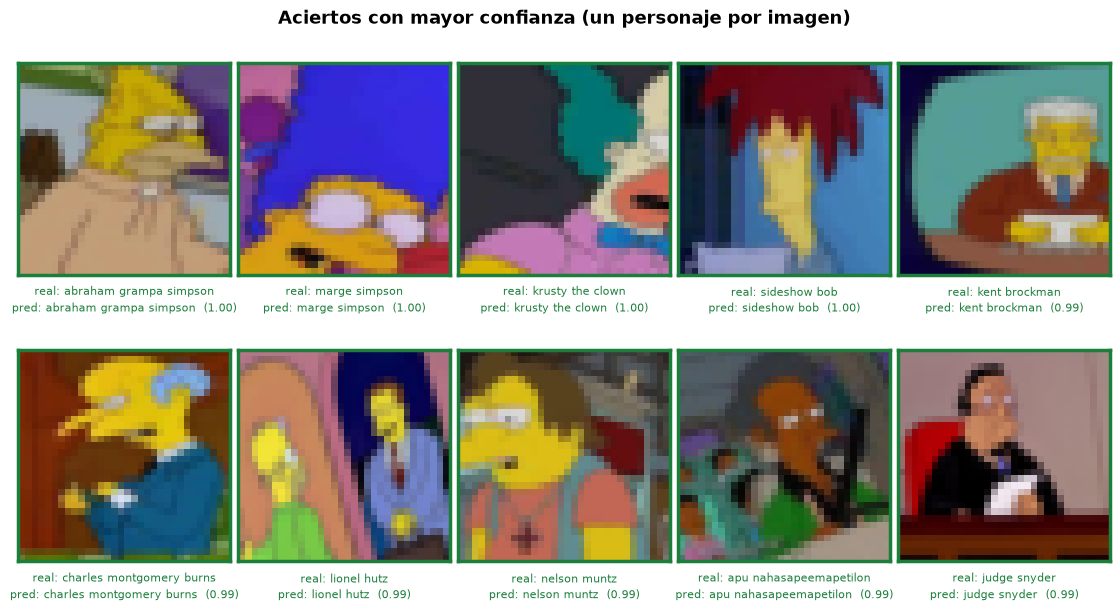

Aciertos totales: 2696 de 5063 (53.2%)
Confianza media en los aciertos: 0.579


In [135]:
def mostrar_ejemplos(indices, titulo, filas=2, columnas=5):
    """Dibuja una rejilla de imágenes de test con su etiqueta real, la predicha y la confianza."""
    indices = list(indices)
    figura, ejes = plt.subplots(
        filas,
        columnas,
        figsize=(2.2 * columnas, 3.0 * filas),
        layout="constrained",
    )
    ejes = np.ravel(ejes)

    for eje, indice in zip(ejes, indices):
        real = clases[y_test_idx[indice]].replace("_", " ")
        predicho = clases[predicciones_test[indice]].replace("_", " ")
        color = color_resultado(indice)

        eje.imshow(imagenes_test[indice])
        eje.set_xticks([])
        eje.set_yticks([])
        # Marco de color: verde si acertó, ámbar si nombró a otro personaje presente, rojo si falló
        for lado in eje.spines.values():
            lado.set_edgecolor(color)
            lado.set_linewidth(2.5)

        # Las etiquetas van debajo de la imagen para que no invadan la fila superior
        eje.set_xlabel(
            f"real: {real}\npred: {predicho}  ({confianza_test[indice]:.2f})"
            + (f"\n{rotulo_escena(indice)}" if color == COLOR_ESCENA else ""),
            fontsize=8,
            color=color,
            labelpad=6,
            linespacing=1.5,
        )

    for eje in ejes[len(indices):]:
        eje.axis("off")

    figura.suptitle(titulo, fontsize=13, fontweight="bold")
    plt.show()


aciertos = np.flatnonzero(acierto_test)
# Aciertos con mayor confianza, sin repetir personaje, para ver variedad de clases
aciertos_ordenados = aciertos[np.argsort(-confianza_test[aciertos])]
vistos = set()
seleccion_aciertos = []
for indice in aciertos_ordenados:
    personaje = y_test_eval[indice]
    if personaje not in vistos:
        vistos.add(personaje)
        seleccion_aciertos.append(indice)
    if len(seleccion_aciertos) == 10:
        break

mostrar_ejemplos(seleccion_aciertos, "Aciertos con mayor confianza (un personaje por imagen)")

print(f"Aciertos totales: {len(aciertos)} de {len(y_test_idx)} ({len(aciertos) / len(y_test_idx):.1%})")
print(f"Confianza media en los aciertos: {confianza_test[aciertos].mean():.3f}")

**Qué está aprovechando el modelo.** Los aciertos más seguros tienen un patrón claro: el personaje ocupa
buena parte del encuadre, se ve de frente o de medio cuerpo y su paleta está completa. En la corrida de GPU
a 64 × 64 son Krusty con su pelo verde y su camisa rosada, Kent Brockman en el estudio de noticias, Sideshow
Mel con el hueso en el pelo, Apu o el doctor Hibbert, todos con una confianza de 0,99 o más. Es lo que se
espera de un modelo que solo recibe histogramas de color: no reconoce la forma de un peinado, sino la
proporción de cada color en la imagen y en cada cuadrante. Por eso acierta en los planos canónicos de un
personaje y pierde seguridad en cuanto el encuadre mezcla su paleta con la de otro personaje o con un fondo
grande.

### Ejemplos mal clasificados

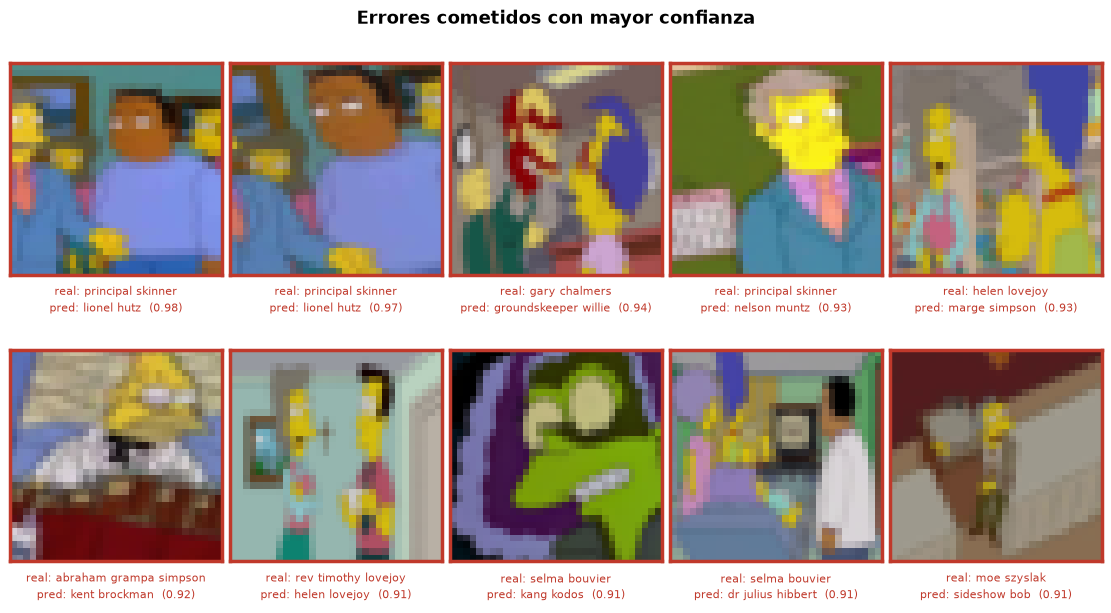

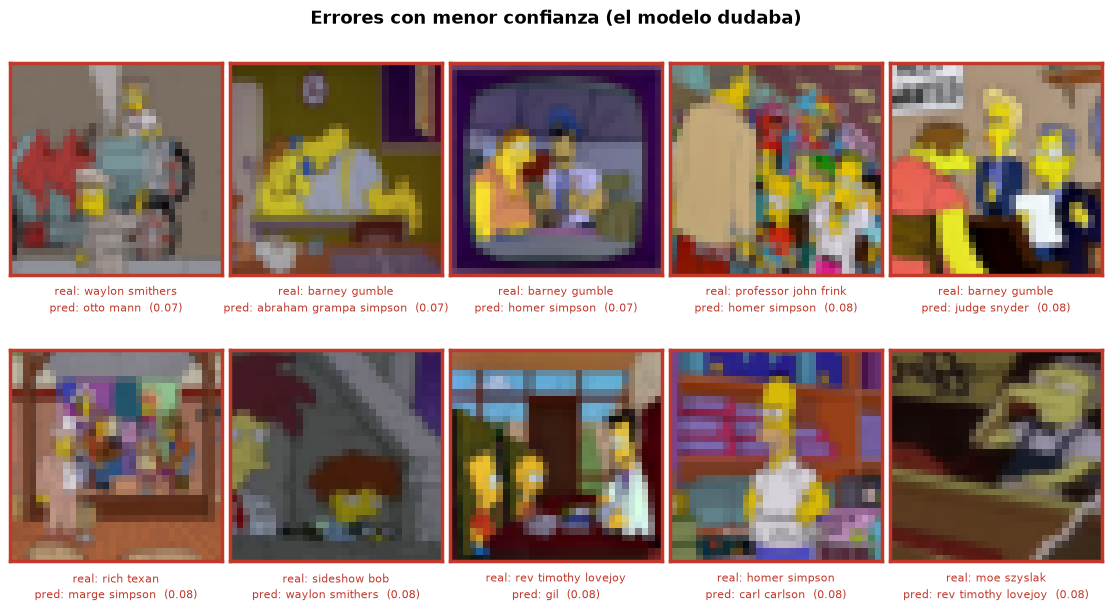

,Indicador,Valor,Detalle
0,Errores totales,2367.000,46.8% del test
1,Confianza media en aciertos,0.579,
2,Confianza media en errores,0.290,
3,Errores con confianza > 0.90,11.000,0.5% de los errores
4,Errores con confianza > 0.80,38.000,tras la verificación: 0 eran otro personaje en...


In [136]:
# Errores según el criterio de acierto: los aciertos por escena no cuentan
errores = np.flatnonzero(~acierto_test)

# Los errores más graves: equivocaciones cometidas con la mayor confianza
errores_confiados = errores[np.argsort(-confianza_test[errores])][:50]
mostrar_ejemplos(errores_confiados, "Errores cometidos con mayor confianza")

# Errores con baja confianza: el modelo tampoco sabía
errores_dudosos = errores[np.argsort(confianza_test[errores])][:10]
mostrar_ejemplos(errores_dudosos, "Errores con menor confianza (el modelo dudaba)")

resumen_errores = pd.DataFrame(
    [
        ("Errores totales", len(errores), f"{len(errores) / len(y_test_idx):.1%} del test"),
        ("Confianza media en aciertos", round(float(confianza_test[aciertos].mean()), 3), ""),
        ("Confianza media en errores", round(float(confianza_test[errores].mean()), 3), ""),
        (
            "Errores con confianza > 0.90",
            int((confianza_test[errores] > 0.90).sum()),
            f"{(confianza_test[errores] > 0.90).mean():.1%} de los errores",
        ),
        (
            f"Errores con confianza > {UMBRAL_CONFIANZA_VERIFICACION:.2f}",
            int((confianza_test[errores] > UMBRAL_CONFIANZA_VERIFICACION).sum()),
            f"tras la verificación: {int(verificado_test.sum())} eran otro personaje en la imagen",
        ),
    ],
    columns=["Indicador", "Valor", "Detalle"],
)
display(resumen_errores)

**Dos tipos de error muy distintos.** La confianza separa bien aciertos de errores: en la corrida de GPU a
64 × 64, la confianza media es de 0,58 en los aciertos y de 0,29 en los errores, y solo 11 de sus 2.280
errores superan 0,90. Cuando el modelo duda suele tener motivos, y esa señal sirve en el escenario de uso:
las predicciones con confianza baja son las que conviene mandar a revisión humana.

Los **errores con confianza alta** son pocos —entre 25 y 88 con confianza mayor que 0,80 en las corridas
del 16-10-2026, menos del 2 % del test— y en la galería de esa corrida responden a tres causas:

- **El personaje predicho sí está en la imagen**, pero ni la escena, ni las gemelas, ni la verificación por
  imagen lo detectan: Willie en una imagen de la carpeta de Chalmers, Patty junto a Selma, el reverendo
  Lovejoy junto a Helen. Son aciertos que el criterio no alcanza a reconocer, así que la accuracy oficial
  sigue siendo una cota inferior.
- **Personajes de paleta casi idéntica**: Selma sola, predicha como su gemela Patty.
- **Un disfraz o una iluminación que cambia la paleta**: Ned disfrazado de diablo rojo, predicho como
  Sideshow Bob; Selma teñida de verde, predicha como Kang.

Las corridas cuyo modelo final es C1, con tres capas, acumulan más errores confiados (84 y 88) que las de
R2 (de 25 a 38): la red más grande acierta más, pero también se equivoca con más seguridad.

Los errores con baja confianza, en cambio, son imágenes difíciles de verdad: planos generales con el
personaje pequeño, escenas con varios personajes a la vez o encuadres donde casi no se ve a nadie, como un
estacionamiento lleno de autos.

### Confusiones más frecuentes y posibles causas

,real,predicho,casos,% de la clase real,n_train_real,n_train_predicho
0,lisa_simpson,bart_simpson,32,14.2,1546,1691
1,bart_simpson,lisa_simpson,30,12.3,1691,1546
2,bart_simpson,homer_simpson,21,8.6,1691,2718
3,homer_simpson,lisa_simpson,18,4.6,2718,1546
4,selma_bouvier,patty_bouvier,18,24.7,498,534
5,homer_simpson,bart_simpson,16,4.1,2718,1691
6,homer_simpson,charles_montgomery_burns,16,4.1,2718,1309
7,homer_simpson,moe_szyslak,15,3.8,2718,1469
8,lisa_simpson,homer_simpson,13,5.8,1546,2718
9,patty_bouvier,selma_bouvier,12,14.5,534,498


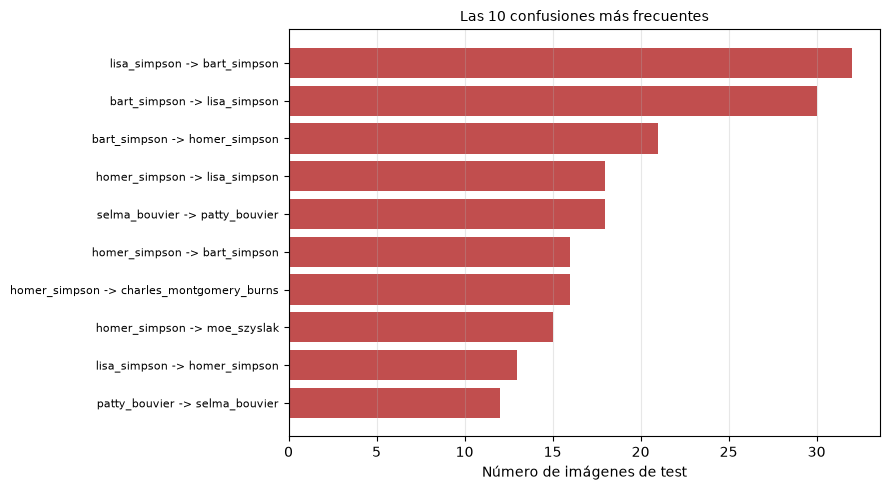

Clases que más absorben errores de otras (el modelo las usa como respuesta por defecto):
  bart_simpson: 48 imagenes de otras clases predichas como esta
  lisa_simpson: 48 imagenes de otras clases predichas como esta
  homer_simpson: 46 imagenes de otras clases predichas como esta
  charles_montgomery_burns: 28 imagenes de otras clases predichas como esta
  patty_bouvier: 18 imagenes de otras clases predichas como esta


In [137]:
# Pares (clase real, clase predicha) más frecuentes, excluyendo la diagonal
pares = []
for real in range(NUMERO_CLASES):
    for predicho in range(NUMERO_CLASES):
        if real != predicho and matriz[real, predicho] > 0:
            pares.append(
                {
                    "real": clases[real],
                    "predicho": clases[predicho],
                    "casos": int(matriz[real, predicho]),
                    "% de la clase real": round(float(matriz_normalizada[real, predicho]) * 100, 1),
                    "n_train_real": int(conteos_train[real]),
                    "n_train_predicho": int(conteos_train[predicho]),
                }
            )

confusiones = pd.DataFrame(pares).sort_values("casos", ascending=False, ignore_index=True).head(15)
display(confusiones)

figura, eje = plt.subplots(figsize=(9, 5))
etiquetas_pares = confusiones.head(10).apply(
    lambda fila: f"{fila['real']} -> {fila['predicho']}", axis=1
)
eje.barh(etiquetas_pares[::-1], confusiones.head(10)["casos"][::-1], color="firebrick", alpha=0.8)
eje.set_xlabel("Número de imágenes de test")
eje.set_title("Las 10 confusiones más frecuentes", fontsize=10)
eje.tick_params(axis="y", labelsize=8)
eje.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

destino_frecuente = confusiones.groupby("predicho")["casos"].sum().sort_values(ascending=False)
print("Clases que más absorben errores de otras (el modelo las usa como respuesta por defecto):")
for personaje, casos in destino_frecuente.head(5).items():
    print(f"  {personaje}: {casos} imagenes de otras clases predichas como esta")

**Causas detrás de las confusiones.** Los pares que encabezan la tabla se repiten en todas las corridas y
responden a causas identificables:

- **Paleta compartida dentro de la familia.** Lisa y Bart se confunden entre sí más que ningún otro par
  (entre un 12 y un 19 % de cada clase), y los dos con Homero: los tres tienen la misma piel amarilla, y los
  histogramas de color, que no ven la forma del pelo, apenas los distinguen. Lo mismo pasa entre el abuelo
  Simpson y Homero.
- **Personajes dibujados casi iguales.** Patty y Selma son gemelas, con el mismo diseño y colores muy
  parecidos: entre un 14 y un 25 % de cada una se predice como la otra.
- **La familia como respuesta por defecto.** Homero, Bart y Lisa son el destino más frecuente de los
  errores de otras clases. No es efecto del desbalance —los pesos por clase reducen el de Homero a la mitad
  del promedio—, sino de que su paleta amarilla es la más genérica de la serie.
- **Escenarios compartidos.** Moe y Homero coinciden en la taberna, y Burns y Homero en la central nuclear.
  Como los histogramas cuentan el fondo igual que al personaje, es probable que el escenario pese en esas
  confusiones.
- **Escenas con varios personajes.** Lou y Wiggum, Skinner y Chalmers, Lenny y Carl o Smithers y Burns
  salen juntos a menudo, pero casi no aparecen en esta tabla: cuando el modelo nombra al acompañante y la
  escena lo confirma, cuenta como acierto (sección siguiente).

### Escenas con varios personajes: aciertos por escena

Desde la evaluación, una predicción cuenta como acierto si nombra al personaje de la carpeta o a otro que
aparece en la misma imagen, según los fotogramas del mismo episodio, una gemela guardada en la carpeta de
otro personaje (sección «Escenas con varios personajes») o, en los errores con confianza mayor que 0,80,
una imagen de la misma toma en la carpeta del personaje predicho (sección «Verificación de los errores con
confianza alta»). Esta sección separa las dos cosas que la accuracy
estricta mezcla: confundir a un personaje con otro, que es un error, y nombrar a otro personaje que sí está
en pantalla, que es un **acierto por escena**.

La escena se estima con una ventana de tiempo y no con una anotación manual: un corte de cámara dentro de
la ventana puede dar por presente a alguien que no sale en el encuadre. Las gemelas son más seguras, porque
son la misma imagen guardada en dos carpetas. La galería permite comprobarlo a ojo. Las imágenes de Kaggle
sin gemela solo tienen acompañantes si la verificación por imagen los encuentra; si no, en ellas ambas
métricas coinciden.

,Indicador,Valor,Detalle
0,Imágenes de test,5063.0000,
1,"con otro personaje presente (escena, gemela...",742.0000,14.7% del test
2,Predicciones distintas del personaje de la car...,2574.0000,50.8% del test
3,que nombran a otro personaje presente (acie...,207.0000,8.0% de esas predicciones
4,"de ellos, verificados por imagen",0.0000,de 38 errores con confianza > 0.80
5,Accuracy estricta (referencia),0.4916,
6,Accuracy oficial (carpeta o personaje presente),0.5325,+0.0409
7,Accuracy estricta en imágenes con otro personaje,0.3329,
8,Accuracy oficial en imágenes con otro personaje,0.6119,


,carpeta,predicho,casos
0,lou,chief_wiggum,15
1,chief_wiggum,lou,8
2,principal_skinner,gary_chalmers,8
3,selma_bouvier,patty_bouvier,8
4,patty_bouvier,selma_bouvier,7
5,lenny_leonard,carl_carlson,6
6,waylon_smithers,charles_montgomery_burns,5
7,apu_nahasapeemapetilon,manjula_nahasapeemapetilon,4
8,charles_montgomery_burns,waylon_smithers,4
9,homer_simpson,rev_timothy_lovejoy,4


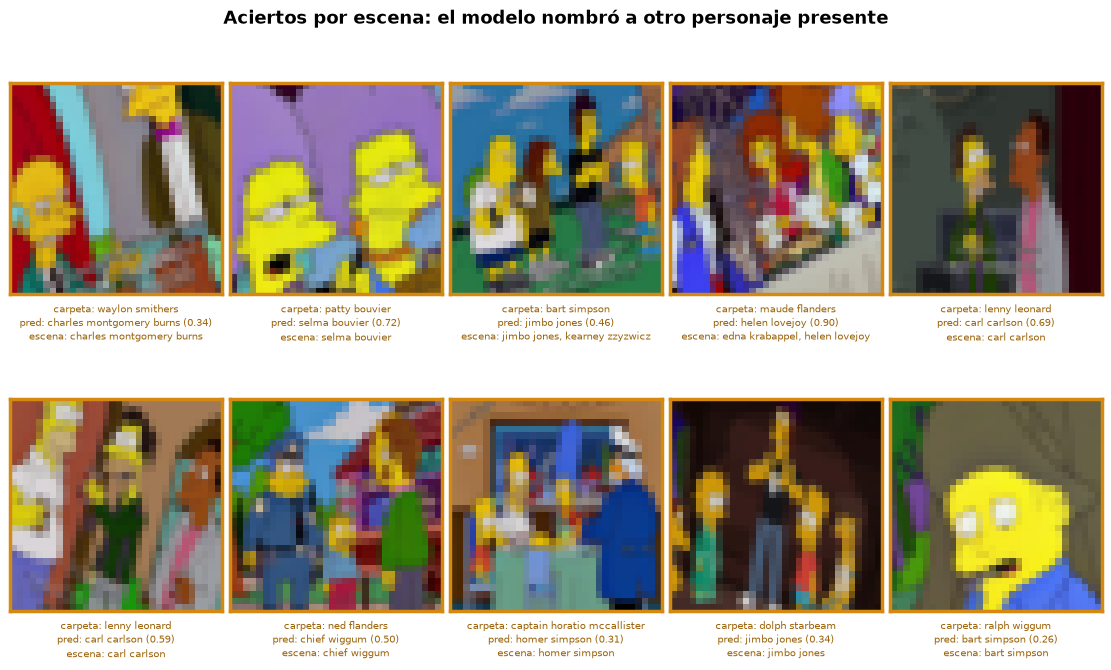

In [138]:
# El criterio de acierto se aplicó en la evaluación (acierto_estricto, acierto_por_escena,
# acierto_test): aquí se separan los aciertos por escena de los errores
nombres_predichos = [clases[indice] for indice in predicciones_test]
con_escena_test = np.array([bool(presentes) for presentes in acompanantes_test])
aciertos_escena = np.flatnonzero(acierto_por_escena)
distintos_de_carpeta = int((~acierto_estricto).sum())


def proporcion(valores):
    return round(float(valores.mean()), 4) if len(valores) else np.nan


resumen_tolerante = pd.DataFrame(
    [
        ("Imágenes de test", len(y_test_idx), ""),
        (
            "   con otro personaje presente (escena, gemela o verificación)",
            int(con_escena_test.sum()),
            f"{con_escena_test.mean():.1%} del test",
        ),
        (
            "Predicciones distintas del personaje de la carpeta",
            distintos_de_carpeta,
            f"{distintos_de_carpeta / len(y_test_idx):.1%} del test",
        ),
        (
            "   que nombran a otro personaje presente (aciertos por escena)",
            len(aciertos_escena),
            f"{len(aciertos_escena) / max(distintos_de_carpeta, 1):.1%} de esas predicciones",
        ),
        (
            "      de ellos, verificados por imagen",
            int(verificado_test.sum()),
            f"de {len(verificacion_test)} errores con confianza > {UMBRAL_CONFIANZA_VERIFICACION:.2f}",
        ),
        ("Accuracy estricta (referencia)", proporcion(acierto_estricto), ""),
        (
            "Accuracy oficial (carpeta o personaje presente)",
            round(accuracy_test, 4),
            f"{accuracy_test - float(acierto_estricto.mean()):+.4f}",
        ),
        ("Accuracy estricta en imágenes con otro personaje", proporcion(acierto_estricto[con_escena_test]), ""),
        ("Accuracy oficial en imágenes con otro personaje", proporcion(acierto_test[con_escena_test]), ""),
    ],
    columns=["Indicador", "Valor", "Detalle"],
)
display(resumen_tolerante)

pares_en_escena = (
    pd.DataFrame(
        {
            "carpeta": [clases[y_test_idx[indice]] for indice in aciertos_escena],
            "predicho": [nombres_predichos[indice] for indice in aciertos_escena],
        }
    )
    .value_counts()
    .head(10)
    .reset_index(name="casos")
)
display(pares_en_escena)

if len(aciertos_escena):
    generador = np.random.default_rng(SEMILLA)
    muestra_escena = generador.choice(aciertos_escena, size=min(10, len(aciertos_escena)), replace=False)
    figura, ejes = plt.subplots(2, 5, figsize=(11, 6.6), layout="constrained")
    ejes = np.ravel(ejes)
    for eje, indice in zip(ejes, muestra_escena):
        eje.imshow(imagenes_test[indice])
        eje.set_xticks([])
        eje.set_yticks([])
        for lado in eje.spines.values():
            lado.set_edgecolor(COLOR_ESCENA)
            lado.set_linewidth(2.5)
        escena_visible = sorted(acompanantes_test[indice])
        resto = f" +{len(escena_visible) - 2}" if len(escena_visible) > 2 else ""
        eje.set_xlabel(
            f"carpeta: {clases[y_test_idx[indice]].replace('_', ' ')}\n"
            f"pred: {nombres_predichos[indice].replace('_', ' ')} ({confianza_test[indice]:.2f})\n"
            f"escena: {', '.join(n.replace('_', ' ') for n in escena_visible[:2])}{resto}",
            fontsize=7,
            color="#9c640c",
            labelpad=6,
            linespacing=1.4,
        )
    for eje in ejes[len(muestra_escena):]:
        eje.axis("off")
    figura.suptitle(
        "Aciertos por escena: el modelo nombró a otro personaje presente", fontsize=13, fontweight="bold"
    )
    plt.show()

**Lectura.** Alrededor del 15 % del test tiene otro personaje presente según la escena, las gemelas o la
verificación, y en esas imágenes la diferencia entre los dos criterios es enorme: la accuracy estricta es de
0,33 a 0,34, y la oficial, de 0,61 a 0,64 (corridas de GPU a 64 × 64 y de CPU a 32 × 32). En las escenas
compartidas, el modelo nombra al acompañante casi tan a menudo como al personaje de la carpeta. La galería
muestra que esos aciertos son legítimos: el personaje predicho está en el encuadre, y los pares más
frecuentes —Lou y Wiggum, Patty y Selma, Skinner y Chalmers, Lenny y Carl, Smithers y Burns— son los que la
serie pone juntos en pantalla.

Esos 207 a 217 aciertos por escena suben la accuracy entre 4 y 5 puntos. Aun así, el criterio sigue siendo
conservador: la verificación por imagen solo encontró la misma toma en 0 a 2 de los errores confiados de
cada corrida, y la galería de «Ejemplos mal clasificados» muestra errores en los que el personaje predicho
sí aparece. La accuracy oficial es, por eso, una cota inferior de lo que el modelo acierta.

### Originales, parecidas y alteradas en test

El test tiene las mismas condiciones que el entrenamiento: originales sin transformar, versiones filtradas
de las imágenes casi idénticas a otra (parecidas) y variantes alteradas de un cuarto de las originales.
Esta tabla mide el modelo por separado en cada tipo:

- **Originales.** Las imágenes tal como están en el dataset. Es la fila comparable con las corridas
  anteriores, cuyo test no tenía alteradas.
- **Parecidas.** Antes del filtro, las imágenes de test con una gemela casi idéntica en entrenamiento se
  acertaban en torno al 95 % de las veces, frente a un 53 % del resto. Si las versiones filtradas se siguen
  acertando mucho más que las originales, el modelo reconoce la escena a pesar del filtro.
- **Alteradas.** Miden si el modelo resiste el giro, el cambio de color y el filtro de textura con los
  que aprendió.

In [139]:
es_alterada_test = datos_test["alterada"].to_numpy()
es_parecida_test = datos_test["parecida"].to_numpy()
es_original_test = ~es_alterada_test & ~es_parecida_test

resumen_tipos_test = pd.DataFrame(
    [
        (
            nombre,
            int(mascara.sum()),
            proporcion(acierto_test[mascara]),
            proporcion(acierto_estricto[mascara]),
            proporcion(top3_por_imagen[mascara]),
        )
        for nombre, mascara in (
            ("Original, sin transformar", es_original_test),
            ("Parecida: versión filtrada de una casi idéntica a otra", es_parecida_test),
            ("Alterada: variante de una original de test", es_alterada_test),
        )
    ],
    columns=["Imágenes de test", "n", "accuracy", "accuracy estricta", "top-3"],
)
display(resumen_tipos_test)
accuracy_originales_test, accuracy_parecidas_test, accuracy_alteradas_test = resumen_tipos_test["accuracy"]


,Imágenes de test,n,accuracy,accuracy estricta,top-3
0,"Original, sin transformar",3101,0.5202,0.4847,0.7049
1,Parecida: versión filtrada de una casi idéntic...,912,0.6338,0.5669,0.8059
2,Alterada: variante de una original de test,1050,0.4810,0.4467,0.6810


**Lectura.** El orden se repite en las seis corridas del 16-10-2026: las parecidas se aciertan más que
las originales, y las alteradas, algo menos.

- **Alteradas: entre 2 y 4 puntos por debajo de las originales.** El giro, el cambio de color y el filtro de
  textura cuestan poco, aunque el modelo dependa del color: haber visto alteradas al entrenar le da algo de
  robustez (sin ellas, en A1, el F1 macro de validación cae entre 2 y 3 puntos).
- **Parecidas: entre 9 y 14 puntos por encima de las originales.** Antes del filtro, la diferencia era de
  unos 40 puntos (95 % frente a 53 %): el filtro la redujo mucho, pero no la eliminó. La versión filtrada
  cambia la miniatura, no la escena, y lo más probable es que, cuando otra imagen del mismo grupo quedó en
  entrenamiento, el modelo reconozca la paleta de esa toma. Como las parecidas son el 18 % del test, esa
  ventaja sube la accuracy global en unos 2 puntos.

La fila de **originales** es, por eso, la medida más limpia del modelo. Una partición que mantenga cada
grupo de imágenes casi idénticas en un solo conjunto eliminaría la ventaja (ver «Propuestas de mejora para
futuras iteraciones»).

### Fortalezas y debilidades del modelo

In [140]:
sintesis = pd.DataFrame(
    [
        (
            "Fortaleza",
            "Supera con holgura los baselines",
            f"accuracy {accuracy_test:.3f} frente a {baseline_azar:.3f} (azar) y {baseline_mayoritaria:.3f} (clase mayoritaria)",
        ),
        (
            "Fortaleza",
            "Buena señal en el top-3",
            f"top-3 accuracy {top3_test:.3f}: la clase correcta suele estar entre las candidatas",
        ),
        (
            "Fortaleza",
            "Reconoce con solidez a los personajes principales",
            f"{len(clases_fuertes)} clases con F1 >= 0.60",
        ),
        (
            "Fortaleza",
            "La confianza es informativa",
            f"confianza media {confianza_test[aciertos].mean():.2f} en aciertos y "
            f"{confianza_test[errores].mean():.2f} en errores",
        ),
        (
            "Debilidad",
            "Desempeño muy desigual entre clases",
            f"brecha accuracy - F1 macro = {brecha_metricas:.3f}; {len(clases_debiles)} clases con F1 < 0.30",
        ),
        (
            "Debilidad",
            "Depende del volumen de datos por clase",
            f"correlacion entre n_train y F1 por clase = {correlacion:.2f}",
        ),
        (
            "Debilidad",
            "Sin invarianza a traslación ni a escala"
            if representacion_final == "pixeles"
            else "Descriptores elegidos a mano",
            "el mismo personaje en otra posición del encuadre es otro vector de entrada"
            if representacion_final == "pixeles"
            else "la red combina histogramas de color y textura fijos; no aprende sus propias características",
        ),
        (
            "Debilidad",
            "Sensible al fondo",
            "los píxeles de fondo entran al modelo con el mismo peso que los del personaje"
            if representacion_final == "pixeles"
            else "los histogramas se calculan sobre la imagen completa o su zona: el fondo también cuenta",
        ),
        (
            "Debilidad",
            "Costo en parámetros",
            f"{modelo_final.count_params():,} parametros para {len(X_train):,} imagenes de entrenamiento",
        ),
    ],
    columns=["Tipo", "Aspecto", "Evidencia"],
)

display(sintesis)

,Tipo,Aspecto,Evidencia
0,Fortaleza,Supera con holgura los baselines,accuracy 0.532 frente a 0.016 (azar) y 0.078 (...
1,Fortaleza,Buena señal en el top-3,top-3 accuracy 0.718: la clase correcta suele ...
2,Fortaleza,Reconoce con solidez a los personajes principales,20 clases con F1 >= 0.60
3,Fortaleza,La confianza es informativa,confianza media 0.58 en aciertos y 0.29 en err...
4,Debilidad,Desempeño muy desigual entre clases,brecha accuracy - F1 macro = 0.023; 3 clases c...
5,Debilidad,Depende del volumen de datos por clase,correlacion entre n_train y F1 por clase = 0.15
6,Debilidad,Descriptores elegidos a mano,la red combina histogramas de color y textura ...
7,Debilidad,Sensible al fondo,los histogramas se calculan sobre la imagen co...
8,Debilidad,Costo en parámetros,"340,800 parametros para 35,023 imagenes de ent..."


**Síntesis.** El MLP demuestra que el problema tiene señal aprendible: su accuracy es cerca de siete veces
la de la clase mayoritaria, cumple los KPIs y reparte el desempeño de forma bastante pareja entre
personajes grandes y pequeños. Su límite no está en los hiperparámetros —ni más capas, ni otra tasa de
aprendizaje, ni otro tamaño de batch, ni otro esquema de pesos lo mejoran en más de 2 o 3 puntos—, sino en
la representación de la entrada. Los histogramas de color le permiten reconocer paletas sin depender de
dónde está el personaje, pero no formas: por eso falla entre personajes que comparten colores y en las
imágenes donde el fondo domina. Ir más lejos requiere que la red aprenda sus propias características a
partir de la forma, que es lo que hacen las redes convolucionales.

## Limitaciones del MLP en imágenes y propuestas de mejora

### Limitaciones estructurales del MLP

> **Con descriptores.** Las limitaciones que siguen se escribieron para el MLP sobre píxeles aplanados,
> que en este notebook es el experimento R1. Los descriptores atenúan algunas: un histograma no cambia si
> el personaje se desplaza dentro de su zona (2), y la primera capa del modelo final, que en todas las
> corridas del 16-10-2026 usa solo los 370 histogramas de color, es más de 100 veces menor que con los
> píxeles a 128 x 128 (3). Pero no las eliminan, y suman una propia: los descriptores se eligen a mano, de
> modo que la red no aprende a extraer los suyos; el fondo sigue entrando en los histogramas (5); y al
> quedarse solo con el color, el modelo no ve la forma, por eso confunde a personajes de paleta parecida,
> como Bart y Lisa o Patty y Selma.

Las limitaciones que siguen no son defectos de esta implementación en particular, sino consecuencias de
usar una red totalmente conectada sobre imágenes. Ningún ajuste de hiperparámetros las resuelve.

**1. Pérdida de la información espacial.** El aplanado convierte la imagen en una lista de 49 152
números en la que se olvida qué píxel estaba junto a cuál. Para la red, dos píxeles vecinos y dos píxeles
en esquinas opuestas son igual de "cercanos": ninguno. Si se permutaran todas las columnas de `X` con una
permutación fija, el modelo aprendería exactamente igual de bien —algo que sería impensable para un ojo
humano y que revela cuánta estructura se está descartando.

**2. Ausencia de invarianza a la traslación y a la escala.** Cada peso de la primera capa está atado a una
posición concreta del encuadre. Si Homero aparece centrado, se activan unas neuronas; desplazado unos
píxeles a la derecha, otras completamente distintas. El modelo tiene que aprender por separado "Homero
arriba a la izquierda", "Homero en el centro" y "Homero de lejos", como si fueran conceptos sin relación.
Lo mismo ocurre con el tamaño: un primer plano y un plano general del mismo personaje no comparten
representación.

**3. Explosión del número de parámetros.** El número de pesos de la primera capa es
`alto x ancho x 3 x neuronas`, es decir, crece de forma cuadrática con el lado de la imagen. En la
configuración ejecutada, 128 x 128 requiere aproximadamente 25,2 millones de pesos solo en la primera
capa de 512 neuronas. Esta razón parámetros/ejemplos eleva el costo y el riesgo de sobreajuste.

**4. Imposibilidad de reutilizar patrones locales.** Un filtro convolucional aprende una vez a detectar
un borde, una esquina o una mancha de color y lo aplica en **toda** la imagen, compartiendo los mismos
pesos. El MLP no tiene ese mecanismo: si un patrón útil aparece en dos posiciones distintas, debe
aprenderlo dos veces, con dos conjuntos de pesos independientes y usando ejemplos distintos para cada uno.
Es un uso enormemente ineficiente tanto de los parámetros como de los datos.

**5. Sensibilidad al fondo y al encuadre.** Todos los píxeles entran al modelo con el mismo estatus. En
una escena donde el personaje ocupa un tercio del encuadre, dos tercios de la entrada son ruido desde el
punto de vista de la tarea —y pueden contener regularidades engañosas: si cierto personaje aparece a
menudo en cierto escenario, el modelo aprenderá el escenario, y fallará en cuanto ese personaje aparezca
en otro lugar.

### Propuestas de mejora para futuras iteraciones

| Propuesta | En qué consiste | Qué limitación ataca |
|---|---|---|
| **Redes convolucionales (CNN)** | Sustituir las primeras capas densas por capas convolucionales y de *pooling*, que operan sobre vecindades de píxeles y comparten los pesos de cada filtro en toda la imagen | Es la mejora principal: recupera la estructura espacial (1), da invarianza aproximada a la traslación (2), reduce drásticamente los parámetros (3), permite reutilizar patrones locales (4) y aprende sus propios filtros en lugar de recibirlos hechos |
| **Más aumento de datos** | El script ya genera, para un cuarto de las imágenes, una variante con un giro de 10 a 20°, un cambio de color y un filtro de textura; se puede ampliar con espejo horizontal y recortes, o generar variantes nuevas en cada época en lugar de una sola vez | Multiplica aún más la variedad efectiva del conjunto, sobre todo en los personajes con menos imágenes |
| **Transfer learning** | Usar una red preentrenada en un corpus grande (MobileNet, ResNet, EfficientNet) como extractor de características y entrenar solo la cabeza clasificadora | Sustituye los descriptores elegidos a mano por representaciones aprendidas sobre millones de imágenes; suele ser la vía más rápida a un salto grande de desempeño con pocos datos propios |
| **Mejor tratamiento del desbalance** | Además de los pesos por clase suavizados, generar más variantes para los personajes pequeños, o usar *focal loss*, que concentra la pérdida en los ejemplos difíciles | Reduce la brecha entre accuracy y F1 macro en los personajes con menos imágenes |
| **Recorte previo del personaje** | Aplicar un detector que localice al personaje y recortar esa región antes de clasificar | Elimina el fondo irrelevante (5), que hoy entra tanto en los píxeles como en los histogramas, y normaliza la escala y el encuadre |
| **Validación cruzada** | Repetir el entrenamiento con varias particiones y varias semillas, reportando media y desviación | Da una estimación más robusta que una única partición 70/20/10 y permite saber si las diferencias entre configuraciones son reales o ruido. En las corridas del 16-10-2026, la configuración ganadora alternó entre R2 y C1, y la misma configuración varió casi un punto entre GPU y CPU |
| **Anotación de escenas** | Marcar a mano qué personajes aparecen en una muestra de imágenes de test | Hace exacto el criterio de acierto, que hoy se estima con la escena, las gemelas y la verificación por imagen: entre los errores más confiados hay imágenes con el personaje predicho en el encuadre que ninguna de las tres fuentes detecta |
| **Partición por grupo o por episodio** | Repartir en un mismo conjunto cada grupo de imágenes casi idénticas, o todos los fotogramas de un episodio, en lugar de imagen a imagen | Evita que tomas de una misma escena caigan a la vez en entrenamiento y test. Con el filtro actual, las parecidas de test todavía se aciertan entre 9 y 14 puntos más que las originales en todas las corridas |
| **Batch mayor en la GPU** | Entrenar con batch 512 o más, subiendo el learning rate en proporción | No ataca una limitación del MLP, sino el costo: a batch 128 la GPU trabaja solo entre un 22 y un 34 % del tiempo, y de batch 128 a 2.048 su rendimiento se multiplica por 14 a 16 |

## Conclusiones

In [141]:
# Cifras finales del trabajo, tomadas de las secciones anteriores
conclusiones = pd.DataFrame(
    [
        ("Personajes (clases)", NUMERO_CLASES),
        ("Imágenes de entrenamiento", len(X_train)),
        ("   de ellas, alteradas", int(datos.loc[MASCARAS["train"], "alterada"].sum())),
        ("Imágenes de validación", len(X_val)),
        ("   de ellas, alteradas", int(datos.loc[MASCARAS["val"], "alterada"].sum())),
        ("Imágenes de test", len(X_test)),
        ("   de ellas, alteradas", int(datos.loc[MASCARAS["test"], "alterada"].sum())),
        ("Imágenes parecidas, con filtro (todos los conjuntos)", int(datos["parecida"].sum())),
        ("Pares de gemelas entre personajes", n_pares_gemelas),
        ("Reparto de las originales", " / ".join(f"{PROPORCIONES[nombre]:.0%}" for nombre in CONJUNTOS)),
        ("Resolución de trabajo", f"{ALTO_OBJETIVO}x{ANCHO_OBJETIVO}"),
        (
            "Representación del modelo final",
            f"{representacion_final} ({DIMENSIONES[representacion_final]:,} valores)",
        ),
        ("Configuración final", nombre_final),
        ("Parámetros del modelo final", f"{modelo_final.count_params():,}"),
        ("Accuracy en test (carpeta o personaje presente)", round(float(accuracy_test), 4)),
        ("Accuracy estricta en test (solo la carpeta)", round(float(accuracy_estricta_test), 4)),
        ("Accuracy en test sin la verificación por imagen", round(accuracy_sin_verificacion_test, 4)),
        (
            f"Errores con confianza > {UMBRAL_CONFIANZA_VERIFICACION:.2f} verificados por imagen",
            f"{int(verificado_test.sum())} de {len(verificacion_test)}",
        ),
        (
            "   en originales / parecidas / alteradas",
            " / ".join(
                f"{valor:.4f}"
                for valor in (accuracy_originales_test, accuracy_parecidas_test, accuracy_alteradas_test)
            ),
        ),
        ("Top-3 accuracy en test", round(float(top3_test), 4)),
        ("F1 macro en test", round(float(f1_macro_test), 4)),
        ("F1 ponderado en test", round(float(f1_ponderado_test), 4)),
        ("Baseline azar", round(baseline_azar, 4)),
        ("Baseline clase mayoritaria", round(float(baseline_mayoritaria), 4)),
    ],
    columns=["Concepto", "Valor"],
)

display(conclusiones)

,Concepto,Valor
0,Personajes (clases),64
1,Imágenes de entrenamiento,35023
2,"de ellas, alteradas",6937
3,Imágenes de validación,10080
4,"de ellas, alteradas",2056
5,Imágenes de test,5063
6,"de ellas, alteradas",1050
7,"Imágenes parecidas, con filtro (todos los conj...",9041
8,Pares de gemelas entre personajes,3326
9,Reparto de las originales,70% / 20% / 10%


**Sobre los resultados.** El Perceptrón Multicapa aprende el problema. En las seis corridas del
16-10-2026 —GPU y CPU, a 32 × 32, 64 × 64 y 128 × 128— la accuracy de test queda entre 0,53 y 0,59 con el
criterio de acierto del proyecto (entre 0,49 y 0,54 con el estricto), la top-3 entre 0,72 y 0,75 y el F1
macro entre 0,51 y 0,57: de 34 a 38 veces el azar y cerca de 7 veces la clase mayoritaria. Los cuatro KPIs
de calidad se cumplen en todas. El de costo de catalogación no se guarda en el resumen de la corrida, pero
supera el umbral en las dos corridas cuyas salidas se conservan (1.285 y 1.557 imágenes por segundo). La
diferencia de solo 2 a 3 puntos entre la accuracy y el F1 macro indica que el desempeño está repartido
entre personajes grandes y pequeños, con una cola de tres o cuatro personajes mal reconocidos.

**Sobre los objetivos planteados.** Se cumplieron los seis objetivos específicos: indexar el dataset con la
etiqueta de cada carpeta; repartirlo 70/20/10 de forma estratificada, con cada alterada en el mismo
conjunto que su original; preparar las entradas (redimensionado, descriptores, normalización y one-hot);
entrenar el modelo base y quince variantes controladas; seleccionar por F1 macro de validación y medir una
sola vez en test; y auditar el resultado por clase, por tipo de imagen y por escena.

**Sobre las decisiones técnicas.** Las más determinantes fueron: describir cada imagen con histogramas de
color en lugar de píxeles —la experimentación eligió el color solo, 370 valores, en todas las corridas—;
usar todo el dataset y compensar el desbalance con pesos suavizados en lugar de un tope por personaje;
filtrar las imágenes casi idénticas y llevar cada alterada al mismo conjunto que su original, para que el
test mida en las mismas condiciones que el entrenamiento; aceptar como acierto nombrar a otro personaje
presente, con la accuracy estricta como referencia; y seleccionar por F1 macro, por coherencia con el
objetivo de reconocer a los 64 personajes y no solo a los frecuentes.

**Sobre lo que aprendimos.**

1. **Una cifra más baja puede ser una medida mejor.** La corrida del 15-10-2026 llegaba a 0,64 de accuracy
   estricta, pero su test tenía imágenes casi idénticas a otras de entrenamiento, que se acertaban en torno
   al 95 % de las veces; el resto, en torno al 53 %. Al filtrar esas imágenes y llevar las alteradas también
   al test, la accuracy estricta quedó entre 0,49 y 0,54, en línea con aquel 53 %: la caída mide sobre todo
   la fuga que se eliminó. Aun así, las parecidas de test se aciertan entre 9 y 14 puntos más que las
   originales, señal de que el filtro reduce la fuga pero no la elimina.
2. **La representación de la entrada pesa más que la capacidad del modelo.** Pasar de color y textura a
   solo color sube el F1 macro de validación entre 7 y 11 puntos; añadir una tercera capa, entre 2 y 3, al
   precio de más que duplicar los parámetros.
3. **Las diferencias pequeñas no son significativas.** Con la misma configuración y la misma resolución, las
   corridas de GPU y de CPU difieren en casi un punto de accuracy (0,541 y 0,533 a 32 × 32) solo por el
   orden de las operaciones en cada dispositivo, y la configuración que gana la validación cambia entre
   corridas (R2 en cuatro, C1 en dos). Para afirmar que una configuración es mejor que otra hacen falta
   varias semillas o particiones.
4. **Por qué existen las CNN.** El MLP con descriptores reconoce paletas, no personajes: confunde a Bart con
   Lisa y a Patty con Selma porque comparten colores, y cuenta el fondo igual que al personaje. Chocar con
   esos límites es la mejor manera de entender qué problema vinieron a resolver la convolución y el pooling,
   que aprenden sus propias características a partir de la forma.

## Probar el modelo con una imagen cualquiera

Esta sección empaqueta todo lo anterior en una función de uso directo. Recibe la ruta de una imagen —del
dataset o de cualquier otro origen— y le aplica **exactamente** el mismo pre-procesamiento con el que se
entrenó la red: conversión a RGB, redimensionado a 128 x 128 y, según la representación del modelo
elegido, el vector de píxeles o los descriptores de color y textura. Ese paso no es opcional: el modelo
espera entradas con la misma forma y la misma distribución que vio durante el entrenamiento. La
estandarización de los descriptores no hace falta repetirla, porque va dentro del modelo.

La celda siguiente prepara el entorno. Si el modelo ya está en memoria lo reutiliza; si no, lo carga desde
`models/newDataset/mlp_final.keras`, junto con `mlp_final.json`, que guarda la representación, la
resolución y el orden de las clases. Si el modelo usa descriptores, antes hay que ejecutar la celda de
definiciones de la sección «Descriptores de color y textura».

In [142]:
# Utilidad de predicción: autosuficiente, reutiliza lo que ya esté en memoria y carga lo que falte
import json
import os
import sys
from pathlib import Path

# Igual que en la sección 0: si esta celda se ejecuta sola en un kernel nuevo, Keras sobre
# PyTorch y la GPU oculta se fijan antes de importar torch y keras
if "keras" not in sys.modules:
    os.environ["KERAS_BACKEND"] = "torch"
    os.environ["KERAS_TORCH_DEVICE"] = "cpu"
if "torch" not in sys.modules:
    os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
import keras

DIRECTORIO_MODELO_FINAL = Path("../../models/newDataset")

# 1. El modelo: si no se ejecutó el notebook completo, se carga el archivo guardado
if "modelo_final" not in globals():
    ruta_guardada = DIRECTORIO_MODELO_FINAL / "mlp_final.keras"
    if not ruta_guardada.exists():
        raise FileNotFoundError(
            f"No hay modelo en memoria ni en {ruta_guardada}. "
            "Ejecuta antes la selección del modelo final o entrena el notebook completo."
        )
    # compile=False: esta celda solo predice. El entrenamiento usa un optimizador
    # de PyTorch, asi que el optimizador de Keras guardado en el archivo esta vacio
    # y cargarlo solo produciria un aviso sin utilidad.
    modelo_final = keras.models.load_model(ruta_guardada, compile=False)
    print(f"Modelo cargado desde {ruta_guardada}")

# 2. El pre-procesamiento con el que se entrenó: representación de entrada, resolución y
#    orden de las clases, que define qué índice de salida corresponde a qué personaje
metadatos_modelo = json.loads((DIRECTORIO_MODELO_FINAL / "mlp_final.json").read_text(encoding="utf-8"))
representacion_modelo = metadatos_modelo["representacion"]
clases = metadatos_modelo["clases"]
ALTO_OBJETIVO, ANCHO_OBJETIVO = metadatos_modelo["alto"], metadatos_modelo["ancho"]

if representacion_modelo != "pixeles" and "extraer_representacion" not in globals():
    raise RuntimeError(
        f'El modelo usa descriptores ("{representacion_modelo}"): ejecuta antes la celda de '
        'definiciones de la sección "Descriptores de color y textura".'
    )


def predecir_imagen(ruta_imagen, top_k=5, mostrar=True):
    """Clasifica una imagen cualquiera y muestra el resultado.

    ruta_imagen : ruta a un archivo de imagen (jpg, png, ...).
    top_k       : cuántas clases candidatas mostrar, de mayor a menor probabilidad.
    Devuelve un DataFrame con esas candidatas y sus probabilidades."""
    ruta_imagen = Path(str(ruta_imagen).strip().strip('"').strip("'"))
    if not ruta_imagen.is_file():
        raise FileNotFoundError(f"No se encontro la imagen: {ruta_imagen}")

    # --- Mismo pre-procesamiento que en el entrenamiento ---
    with Image.open(ruta_imagen) as archivo:
        original = archivo.convert("RGB")
    # np.array y no np.asarray: la copia es escribible, y PyTorch avisa si recibe la
    # memoria de solo lectura de PIL
    reducida = np.array(
        original.resize((ANCHO_OBJETIVO, ALTO_OBJETIVO), Image.Resampling.BILINEAR),
        dtype=np.uint8,
    )
    if representacion_modelo == "pixeles":
        # El vector va en uint8: la capa Rescaling del modelo se encarga de dividir por 255.
        vector = reducida.reshape(1, -1)
    else:
        # Los descriptores van sin estandarizar: la capa Normalization del modelo lo hace.
        vector = extraer_representacion(reducida, representacion_modelo).reshape(1, -1)
    dispositivo = next(modelo_final.parameters()).device
    entrada = torch.as_tensor(vector).to(dispositivo)

    probabilidades = modelo_final.predict(entrada, verbose=0)[0]
    mejores = np.argsort(-probabilidades)[:top_k]

    candidatas = pd.DataFrame(
        {
            "personaje": [clases[i].replace("_", " ") for i in mejores],
            "probabilidad": [round(float(probabilidades[i]), 4) for i in mejores],
        }
    )

    # Si la imagen viene de una carpeta con nombre de clase, se aprovecha para comparar
    etiqueta_real = ruta_imagen.parent.name if ruta_imagen.parent.name in clases else None
    prediccion = clases[int(mejores[0])]
    acierto = None if etiqueta_real is None else prediccion == etiqueta_real
    color = "#1b7f3b" if acierto in (None, True) else "#c0392b"

    if not mostrar:
        return candidatas

    figura, ejes = plt.subplots(
        1, 3, figsize=(13, 4.2), layout="constrained", gridspec_kw={"width_ratios": [1.2, 1, 2.2]}
    )

    # Panel 1: la imagen original, tal como está en el disco
    ejes[0].imshow(original)
    ejes[0].set_title(f"Original  {original.size[0]}x{original.size[1]}", fontsize=9)
    ejes[0].set_xlabel(ruta_imagen.name, fontsize=8, labelpad=6)

    # Panel 2: la imagen redimensionada de la que sale el vector de entrada
    ejes[1].imshow(reducida)
    ejes[1].set_title(f"Lo que ve el modelo  {ANCHO_OBJETIVO}x{ALTO_OBJETIVO}", fontsize=9)
    ejes[1].set_xlabel(f"{vector.shape[1]:,} valores ({representacion_modelo})", fontsize=8, labelpad=6)

    for eje in ejes[:2]:
        eje.set_xticks([])
        eje.set_yticks([])
        for lado in eje.spines.values():
            lado.set_edgecolor(color)
            lado.set_linewidth(3)

    # Panel 3: las candidatas con su probabilidad
    orden = candidatas.iloc[::-1]
    colores = [
        "#1b7f3b" if nombre.replace(" ", "_") == etiqueta_real else "#b0c4de"
        for nombre in orden["personaje"]
    ]
    if etiqueta_real is None:
        colores[-1] = "#2c7fb8"  # sin etiqueta conocida: se resalta solo la ganadora

    barras = ejes[2].barh(orden["personaje"], orden["probabilidad"] * 100, color=colores)
    ejes[2].bar_label(barras, fmt="%.1f %%", fontsize=8, padding=3)
    ejes[2].set_xlim(0, 112)
    ejes[2].set_xlabel("probabilidad asignada (%)")
    ejes[2].grid(alpha=0.3, axis="x")
    ejes[2].set_title(f"Top {top_k} de candidatas", fontsize=9)

    titulo = f"El modelo dice: {prediccion.replace('_', ' ').upper()}"
    titulo += f"   ({probabilidades[mejores[0]]:.1%} de confianza)"
    if etiqueta_real is not None:
        titulo += f"   |   real: {etiqueta_real.replace('_', ' ')}"
        titulo += "  ->  ACIERTO" if acierto else "  ->  ERROR"
    figura.suptitle(titulo, fontsize=13, fontweight="bold", color=color)
    plt.show()

    return candidatas


print(f"Listo ({representacion_modelo}). Usa predecir_imagen(<ruta>) en la celda siguiente.")

Listo (color). Usa predecir_imagen(<ruta>) en la celda siguiente.


**Cómo usarla.** Basta con reemplazar la ruta de `RUTA_IMAGEN` por la de cualquier imagen del disco y
ejecutar la celda; se puede repetir tantas veces como se quiera sin volver a cargar el modelo. La `r`
delante de las comillas indica a Python que no interprete las barras invertidas de las rutas de Windows,
así que la ruta se puede pegar tal cual.

Cuando la imagen proviene de una carpeta con nombre de personaje —como ocurre en el dataset—, la función
lo detecta y compara la predicción con esa etiqueta. Si la imagen viene de cualquier otro lugar,
simplemente muestra la respuesta del modelo.

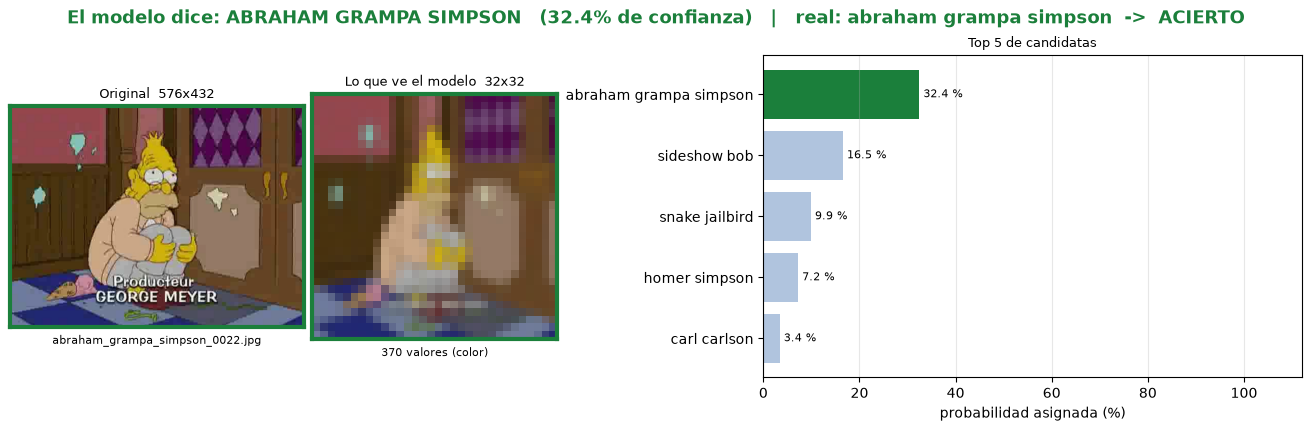

,personaje,probabilidad
0,abraham grampa simpson,0.3243
1,sideshow bob,0.1654
2,snake jailbird,0.0988
3,homer simpson,0.0722
4,carl carlson,0.0339


In [143]:
# Cambia esta ruta por la de la imagen que quieras clasificar y vuelve a ejecutar la celda.
# Por defecto se usa la primera imagen de test, que el modelo no vio al entrenar.
RUTA_IMAGEN = datos_test["ruta"].iloc[0] if "datos_test" in globals() else r"C:\ruta\a\una\imagen.jpg"

candidatas = predecir_imagen(RUTA_IMAGEN, top_k=5)
display(candidatas)

**Advertencia sobre la interpretación.** La red siempre responde algo: el softmax reparte
probabilidad entre los 64 personajes conocidos y devuelve la mayor, aunque la imagen no contenga a ningún
personaje de Los Simpson. No existe una opción "ninguno de los anteriores". Por eso la confianza es tan
informativa como el nombre: un valor cercano al 100 % indica una decisión clara, mientras que una
ganadora con 15 % frente a candidatas de 12 % significa que el modelo no tiene criterio para decidir.

Conviene recordar también los límites vistos en la evaluación: el modelo reconoce con solidez a los
personajes con muchas imágenes de entrenamiento y falla con frecuencia en los minoritarios, y es sensible
al encuadre y al fondo. Una foto con el personaje pequeño dentro de una escena cargada tiene bastantes
menos probabilidades de clasificarse bien que un primer plano.

## Referencias

**Dataset**

- Alfaro, A. (s. f.). *Los Simpson* [conjunto de datos]. Kaggle.
  https://www.kaggle.com/datasets/alfaro96/los-simpson. Es la base del dataset de este
  notebook, que el equipo amplió a 64 personajes.

**Documentación de las librerías utilizadas**

- TensorFlow / Keras — *Keras API reference*. https://keras.io/api/
- TensorFlow / Keras — *The Sequential model*. https://keras.io/guides/sequential_model/
- scikit-learn — *Metrics and scoring*. https://scikit-learn.org/stable/modules/model_evaluation.html
- scikit-learn — `train_test_split`. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
- scikit-learn — `compute_class_weight`. https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html
- NumPy — *NumPy documentation*. https://numpy.org/doc/stable/
- pandas — *pandas documentation*. https://pandas.pydata.org/docs/
- Matplotlib — *Matplotlib documentation*. https://matplotlib.org/stable/index.html
- seaborn — *seaborn documentation*. https://seaborn.pydata.org/
- Pillow — *Pillow (PIL Fork) documentation*. https://pillow.readthedocs.io/en/stable/
- scikit-image — *API reference* (`skimage.color`, `skimage.feature`, `skimage.filters`). https://scikit-image.org/docs/stable/api/api.html
- joblib — *Embarrassingly parallel for loops*. https://joblib.readthedocs.io/en/stable/parallel.html

**Material del curso**

- Jerez Salazar, F. J. *1.1.1 El Perceptrón*. Machine Learning, TLY1102.
- Jerez Salazar, F. J. *1.2.1 Redes Fully Connected*. Machine Learning, TLY1102.
- Jerez Salazar, F. J. *1.2.2 Backpropagation*. Machine Learning, TLY1102.
- Jerez Salazar, F. J. *1.3.1 Descenso del Gradiente*. Machine Learning, TLY1102.
- Jerez Salazar, F. J. *1.3.2 Optimizadores*. Machine Learning, TLY1102.
- Jerez Salazar, F. J. *1.4.1 Diseño y Evaluación de Modelos*. Machine Learning, TLY1102.
- Jerez Salazar, F. J. *1.4.2 Implementación con Keras*. Machine Learning, TLY1102.

## Resumen de rendimiento de la corrida (CPU vs GPU)

Esta última sección no añade nada al modelo: mide **cuánto costó obtenerlo**. Las secciones anteriores
responden qué tan bien clasifica la red; esta responde en qué hardware se entrenó, cuánto tardó cada
etapa y qué se gana al mover el mismo trabajo de la CPU a la GPU.

Se reportan tres cosas:

1. **El entorno y las marcas de tiempo.** Qué dispositivo ejecutó realmente las operaciones —CPU o
   GPU—, con su nombre, el sistema operativo y la versión del framework, además de la resolución de
   entrada, la **fecha y hora de inicio** de la corrida (la fija la primera celda del notebook), la
   **hora de término** y la duración total. Es el dato que da sentido a todos los tiempos.
2. **Los tiempos de la corrida.** Segundos y segundos por época de cada configuración entrenada, más un
   *benchmark* corto de tres épocas sobre la arquitectura base y una medición de inferencia sobre el
   conjunto de test. El benchmark existe porque los tiempos de las secciones anteriores no son
   comparables entre sí: la parada temprana hace que cada configuración corra un número distinto de
   épocas. Entrenar unas pocas épocas con la misma arquitectura, el mismo batch y sin *callbacks* sí da
   una cifra homogénea. De esas épocas se descarta la primera, que incluye la compilación del grafo y el
   traslado inicial de los datos al dispositivo.
3. **La comparación entre entornos.** Cada notebook guarda su resumen en una carpeta propia dentro de
   `../../resultados/newDataset/`, con la resolución en el nombre del archivo:

   ```
   resultados/newDataset/
   ├── CPU/
   │   ├── rendimiento_cpu_32x32.json
   │   ├── rendimiento_cpu_64x64.json
   │   └── rendimiento_cpu_128x128.json
   └── GPU/
       ├── rendimiento_gpu_32x32.json
       ├── rendimiento_gpu_64x64.json
       └── rendimiento_gpu_128x128.json
   ```

   La celda cruza únicamente el par que comparte resolución, porque comparar una corrida de 64 x 64
   con otra de 128 x 128 mediría el tamaño del problema y no el hardware. Cuando existen los dos,
   muestra la tabla y el gráfico comparativos con la aceleración obtenida en cada medición; si solo
   está el de este entorno, se guarda igual, se avisa de cuál falta y se indica a qué resoluciones sí
   hay corridas guardadas del otro.

Conviene recordar al leer las cifras que un MLP es, capa a capa, una multiplicación de matrices densas:
exactamente el tipo de operación que una GPU paraleliza bien, así que la diferencia debería notarse
sobre todo en el entrenamiento. Las métricas de calidad (accuracy, F1) aparecen en la tabla solo para
verificar que el cambio de hardware **no** cambia lo que el modelo aprende: si difieren mucho, la causa
está en el pre-procesamiento o en los hiperparámetros, no en el dispositivo.

Las dos corridas usan el mismo framework, Keras 3 sobre PyTorch, y el mismo bucle de entrenamiento, así
que la diferencia de tiempos se debe al hardware. La comparación de las seis corridas guardadas, con sus
conclusiones, está al final de esta sección.

,Concepto,Valor
0,Entorno,CPU
1,Dispositivo de cómputo,"Intel64 Family 6 Model 186 Stepping 2, Genuine..."
2,CPU del equipo,"Intel64 Family 6 Model 186 Stepping 2, Genuine..."
3,GPUs visibles para PyTorch,0
4,Sistema operativo,Windows 11
5,Python,3.13.15
6,Framework,Keras 3.15.1 sobre PyTorch 2.14.0+cu130
7,Resolución de trabajo,32x32
8,Entrada del modelo base,color_textura (2462 valores)
9,Entrada del modelo final,color (370 valores)


,experimento,epocas,parametros,segundos,segundos_por_epoca,imagenes_por_segundo
0,"Base - color_textura (512,256)",56,1411904,161.909541,2.89,12113.0
1,R1 - pixeles,35,1724224,215.000000,6.14,5701.0
2,R2 - solo color,35,340800,72.100000,2.06,17001.0
3,R3 - solo textura,21,1222464,58.500000,2.79,12572.0
4,E1 - 1 capa (512),19,1295936,42.900000,2.26,15511.0
5,"E2 - 3 capas (1024,512,256)",35,3201856,193.100000,5.52,6348.0
6,E3 - activación tanh,16,1411904,47.300000,2.96,11847.0
7,E4 - learning rate 1e-4,35,1411904,102.400000,2.93,11971.0
8,E5 - batch 512,33,1411904,63.300000,1.92,18258.0
9,"E6 - dropout 0,5",35,1411904,102.900000,2.94,11913.0


,Medicion,Valor
0,Entrenamiento: segundos por epoca (arquitectur...,2.68
1,Entrenamiento: imágenes por segundo,13062.00
2,"Inferencia: segundos para las 5,063 imagenes d...",0.08
3,Inferencia: imágenes por segundo,62879.00


,Concepto,Valor
0,entorno,CPU
1,dispositivo,"Intel64 Family 6 Model 186 Stepping 2, Genuine..."
2,cpu,"Intel64 Family 6 Model 186 Stepping 2, Genuine..."
3,sistema_operativo,Windows 11
4,framework,PyTorch
5,framework_version,2.14.0+cu130
6,keras,3.15.1
7,inicio_corrida,2026-10-16 18:28:09
8,fin_corrida,2026-10-16 18:58:13
9,duracion_corrida,0:30:04


Resumen guardado en: C:\Users\LaptopWin\Desktop\Trabajo\Duoc\3er-Anio\2do Semestre\TECNICAS_ML\Unidad 2\LosSimpsons_PMC\resultados\newDataset\CPU\rendimiento_cpu_32x32.json


,Concepto,CPU,GPU,Diferencia
0,Dispositivo,"Intel64 Family 6 Model 186 Stepping 2, Genuine...",NVIDIA GeForce RTX 4060 Laptop GPU (CC 8.9),-
1,Sistema operativo,Windows 11,Windows 11,-
2,Framework,PyTorch 2.14.0+cu130,PyTorch 2.14.0+cu130,-
3,Inicio de la corrida,2026-10-16 18:28:09,2026-10-16 13:47:43,-
4,Termino de la corrida,2026-10-16 18:58:13,2026-10-16 14:07:19,-
5,Duracion de la corrida,0:30:04,0:19:36,-
6,Resolución de entrada,32x32,32x32,-
7,Parámetros del modelo final,340800,340800,-
8,Épocas totales entrenadas,503,507,-
9,Segundos: modelo base,161.9,113.4,GPU x1.43 mas rapida



Ambas corridas entrenan la misma red sobre la misma entrada (representacion base a 32x32, 2462 valores por imagen).
Las dos usan el mismo framework, asi que la diferencia de tiempos es atribuible al hardware.


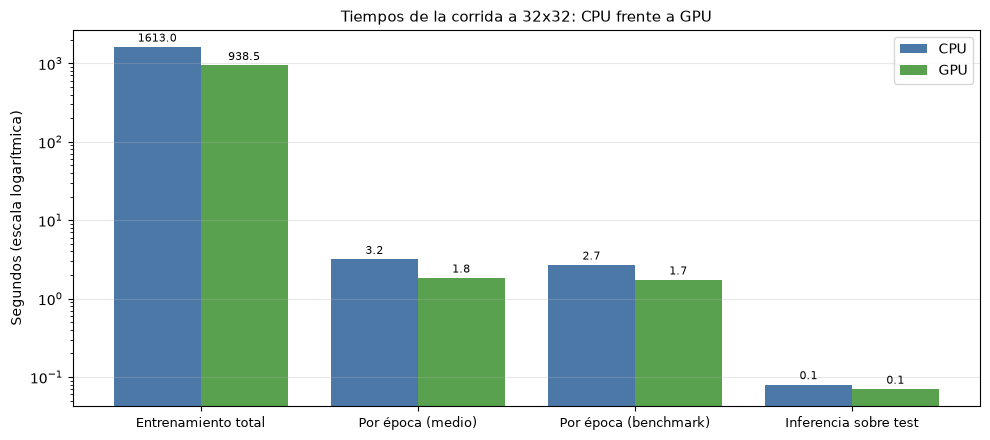

In [144]:
# Resumen de rendimiento de la corrida: entorno de ejecución, marcas de tiempo,
# tiempos y métricas finales. Cada notebook escribe su resumen en
# ../../resultados/newDataset/<CPU|GPU>/rendimiento_<entorno>_<resolucion>.json y, si existe el
# del otro entorno a la misma resolución, se muestra la comparación lado a lado.
import json
import platform
import subprocess
import time
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import keras

DIRECTORIO_RESULTADOS = Path("../../resultados/newDataset")
DIRECTORIO_RESULTADOS.mkdir(parents=True, exist_ok=True)

# La resolución de entrada forma parte del nombre del archivo: una corrida a 64x64
# y otra a 128x128 entrenan modelos de distinto tamaño y no son comparables entre sí.
RESOLUCION = f"{ALTO_OBJETIVO}x{ANCHO_OBJETIVO}"

# La marca de inicio la fija la primera celda del notebook; si esa celda no se
# ejecutó en esta sesión, se toma el arranque de esta sección como referencia.
INICIO_CORRIDA = globals().get("INICIO_CORRIDA") or datetime.now()

# Re-entrena unas pocas épocas para medir un tiempo por época comparable entre
# entornos (misma arquitectura, mismo batch, sin parada temprana). False para omitirlo.
EJECUTAR_BENCHMARK = True
EPOCAS_BENCHMARK = 3

# Esta es la medicion en CPU de la misma red, con el mismo bucle de entrenamiento que el
# notebook de GPU: la seccion 0 oculta la GPU, asi que Keras y PyTorch trabajan solo en la CPU.


# --- 1. Entorno de ejecución -------------------------------------------------
def describir_cpu():
    """Nombre del procesador, en Windows y en Linux."""
    if platform.system() == "Windows":
        try:
            nombre = subprocess.run(
                ["wmic", "cpu", "get", "name"], capture_output=True, text=True, timeout=10
            ).stdout.strip().splitlines()
            if len(nombre) > 1 and nombre[1].strip():
                return nombre[1].strip()
        except (OSError, subprocess.SubprocessError):
            pass
        return platform.processor() or platform.machine()
    try:
        for linea in Path("/proc/cpuinfo").read_text().splitlines():
            if linea.startswith("model name"):
                return linea.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()


def describir_gpu():
    """Nombre comercial y capacidad de cómputo de la GPU que ve PyTorch."""
    mayor, menor = torch.cuda.get_device_capability(0)
    return f"{torch.cuda.get_device_name(0)} (CC {mayor}.{menor})"


usa_gpu = torch.cuda.is_available()
ENTORNO = "GPU" if usa_gpu else "CPU"
dispositivo = describir_gpu() if usa_gpu else describir_cpu()

entorno = pd.DataFrame(
    [
        ("Entorno", ENTORNO),
        ("Dispositivo de cómputo", dispositivo),
        ("CPU del equipo", describir_cpu()),
        ("GPUs visibles para PyTorch", torch.cuda.device_count()),
        ("Sistema operativo", f"{platform.system()} {platform.release()}"),
        ("Python", platform.python_version()),
        ("Framework", f"Keras {keras.__version__} sobre PyTorch {torch.__version__}"),
        ("Resolución de trabajo", RESOLUCION),
        ("Entrada del modelo base", f"{REPRESENTACION_BASE} ({DIMENSION_ENTRADA} valores)"),
        ("Entrada del modelo final", f"{representacion_final} ({DIMENSIONES[representacion_final]} valores)"),
        ("Inicio de la corrida", INICIO_CORRIDA.strftime("%Y-%m-%d %H:%M:%S")),
    ],
    columns=["Concepto", "Valor"],
)
display(entorno)


# --- 2. Tiempos de entrenamiento --------------------------------------------
# El tiempo del modelo base lo mide la celda de entrenamiento; si esa celda no se
# volvió a ejecutar, queda como desconocido en lugar de inventar un valor.
segundos_base = float(globals().get("segundos_entrenamiento_base", np.nan))
epocas_base = len(historial_base.history["loss"])

tiempos = tabla_experimentos[["experimento", "epocas", "parametros", "segundos"]].copy()
# El modelo base entra en la tabla de experimentos sin tiempo: se completa aquí
tiempos.loc[tiempos["experimento"].str.startswith("Base"), "segundos"] = segundos_base
tiempos["segundos_por_epoca"] = (tiempos["segundos"] / tiempos["epocas"]).round(2)
tiempos["imagenes_por_segundo"] = (
    len(X_train) * tiempos["epocas"] / tiempos["segundos"]
).round(0)

display(tiempos)

segundos_experimentos = float(
    tabla_experimentos.loc[
        ~tabla_experimentos["experimento"].str.startswith("Base"), "segundos"
    ].sum()
)
segundos_totales = float(np.nansum([segundos_base, segundos_experimentos]))
segundos_por_epoca_medio = float(tiempos["segundos_por_epoca"].mean(skipna=True))
epocas_totales = int(tiempos["epocas"].sum())


# --- 3. Benchmark comparable: entrenamiento e inferencia ---------------------
def cronometrar_epocas(modelo, X, y, batch, epocas):
    """Entrena `epocas` épocas seguidas con el mismo bucle del entrenamiento y devuelve el
    tiempo medio por época.

    Se descarta la primera: incluye la reserva de memoria y el calentamiento, que no se
    repiten en las siguientes.
    """
    optimizador = torch.optim.Adam(modelo.parameters(), lr=TASA_APRENDIZAJE, fused=True)
    generador = torch.Generator(device=X.device)
    generador.manual_seed(SEMILLA)

    duraciones = []
    for _ in range(epocas):
        inicio = time.perf_counter()
        _pasada(modelo, X, y, batch, True, optimizador, None, generador)
        duraciones.append(time.perf_counter() - inicio)
    utiles = duraciones[1:] or duraciones
    return float(np.mean(utiles))


benchmark_segundos_epoca = np.nan
if EJECUTAR_BENCHMARK:
    keras.utils.set_random_seed(SEMILLA)
    modelo_benchmark = construir_mlp(nombre="mlp_benchmark").to(DISPOSITIVO)
    benchmark_segundos_epoca = cronometrar_epocas(
        modelo_benchmark, X_train, y_train, TAMANO_BATCH, EPOCAS_BENCHMARK
    )
    del modelo_benchmark

# Inferencia sobre el conjunto de evaluación completo, tras una pasada de calentamiento
modelo_final.predict(X_test[:256], batch_size=256, verbose=0)
inicio_inferencia = time.perf_counter()
modelo_final.predict(X_test, batch_size=256, verbose=0)
segundos_inferencia = time.perf_counter() - inicio_inferencia

filas_benchmark = [
    (
        f"Entrenamiento: segundos por epoca (arquitectura base, batch {TAMANO_BATCH})",
        round(benchmark_segundos_epoca, 2) if EJECUTAR_BENCHMARK else "no ejecutado",
    ),
    (
        "Entrenamiento: imágenes por segundo",
        round(len(X_train) / benchmark_segundos_epoca) if EJECUTAR_BENCHMARK else "-",
    ),
    (
        f"Inferencia: segundos para las {len(X_test):,} imagenes de test",
        round(segundos_inferencia, 2),
    ),
    ("Inferencia: imágenes por segundo", round(len(X_test) / segundos_inferencia)),
]
display(pd.DataFrame(filas_benchmark, columns=["Medicion", "Valor"]))


# --- 4. Resumen de la corrida ------------------------------------------------
# El término se marca aquí, después del benchmark y de la medición de inferencia:
# es el último trabajo real de la corrida.
FIN_CORRIDA = datetime.now()
duracion_corrida_segundos = (FIN_CORRIDA - INICIO_CORRIDA).total_seconds()
duracion_corrida = str(timedelta(seconds=round(duracion_corrida_segundos)))

def cuatro_decimales(valor):
    """Métrica redondeada; la de un subconjunto vacío queda como None (null en el JSON)."""
    return None if np.isnan(valor) else round(float(valor), 4)


resumen_corrida = {
    "entorno": ENTORNO,
    "dispositivo": dispositivo,
    "cpu": describir_cpu(),
    "sistema_operativo": f"{platform.system()} {platform.release()}",
    "framework": "PyTorch",
    "framework_version": torch.__version__,
    "keras": keras.__version__,
    "inicio_corrida": INICIO_CORRIDA.strftime("%Y-%m-%d %H:%M:%S"),
    "fin_corrida": FIN_CORRIDA.strftime("%Y-%m-%d %H:%M:%S"),
    "duracion_corrida": duracion_corrida,
    "duracion_corrida_segundos": round(duracion_corrida_segundos, 1),
    "resolucion": RESOLUCION,
    "dimension_entrada": int(DIMENSION_ENTRADA),
    "representacion_base": REPRESENTACION_BASE,
    "representacion_final": representacion_final,
    "dimension_entrada_final": int(DIMENSIONES[representacion_final]),
    "personajes": int(NUMERO_CLASES),
    "proporciones_train_val_test": " / ".join(f"{PROPORCIONES[nombre]:.0%}" for nombre in CONJUNTOS),
    "esquema_pesos": ESQUEMA_PESOS,
    "suavizado_etiquetas": SUAVIZADO_ETIQUETAS,
    "peso_escena": PESO_ESCENA,
    "imagenes_train_alteradas": int(datos.loc[MASCARAS["train"], "alterada"].sum()),
    "imagenes_val_alteradas": int(datos.loc[MASCARAS["val"], "alterada"].sum()),
    "imagenes_test_alteradas": int(datos.loc[MASCARAS["test"], "alterada"].sum()),
    "imagenes_parecidas": int(datos["parecida"].sum()),
    "pares_gemelas": int(n_pares_gemelas),
    "segundos_carga_imagenes": round(segundos_carga, 1),
    "segundos_descriptores": round(segundos_descriptores, 1),
    "imagenes_train": int(len(X_train)),
    "imagenes_val": int(len(X_val)),
    "imagenes_test": int(len(X_test)),
    "batch": int(TAMANO_BATCH),
    "configuracion_final": nombre_final,
    "parametros_modelo_final": int(modelo_final.count_params()),
    "epocas_modelo_base": int(epocas_base),
    "segundos_modelo_base": None if np.isnan(segundos_base) else round(segundos_base, 1),
    "segundos_experimentos": round(segundos_experimentos, 1),
    "segundos_entrenamiento_total": round(segundos_totales, 1),
    "epocas_totales": epocas_totales,
    "segundos_por_epoca_medio": round(segundos_por_epoca_medio, 2),
    "benchmark_segundos_por_epoca": (
        None if np.isnan(benchmark_segundos_epoca) else round(benchmark_segundos_epoca, 2)
    ),
    "segundos_inferencia_test": round(segundos_inferencia, 2),
    "inferencia_imagenes_por_segundo": round(len(X_test) / segundos_inferencia, 1),
    "criterio_acierto": (
        "carpeta o personaje presente (escena + gemelas + verificación por imagen de los errores con confianza alta)"
    ),
    "umbral_confianza_verificacion": UMBRAL_CONFIANZA_VERIFICACION,
    "umbral_similitud_verificacion": UMBRAL_SIMILITUD_VERIFICACION,
    "errores_confiados_test": int(len(verificacion_test)),
    "errores_confiados_verificados_test": int(verificado_test.sum()),
    "accuracy_test": round(float(accuracy_test), 4),
    "accuracy_estricta_test": round(float(accuracy_estricta_test), 4),
    "top3_test": round(float(top3_test), 4),
    "accuracy_tolerante_test": round(accuracy_tolerante_test, 4),
    "accuracy_sin_verificacion_test": round(accuracy_sin_verificacion_test, 4),
    "accuracy_originales_test": cuatro_decimales(accuracy_originales_test),
    "accuracy_parecidas_test": cuatro_decimales(accuracy_parecidas_test),
    "accuracy_alteradas_test": cuatro_decimales(accuracy_alteradas_test),
    "f1_macro_test": round(float(f1_macro_test), 4),
    "f1_macro_estricto_test": round(float(f1_macro_estricto_test), 4),
    "f1_ponderado_test": round(float(f1_ponderado_test), 4),
    "perdida_test": round(float(perdida_test), 4),
}

# Una carpeta por entorno y un archivo por resolución:
# ../../resultados/newDataset/CPU/rendimiento_cpu_128x128.json
directorio_entorno = DIRECTORIO_RESULTADOS / ENTORNO
directorio_entorno.mkdir(parents=True, exist_ok=True)
ruta_resumen = directorio_entorno / f"rendimiento_{ENTORNO.lower()}_{RESOLUCION}.json"
ruta_resumen.write_text(json.dumps(resumen_corrida, indent=2, ensure_ascii=False), encoding="utf-8")

display(
    pd.DataFrame(
        [
            (clave, valor if valor is not None else "desconocido")
            for clave, valor in resumen_corrida.items()
        ],
        columns=["Concepto", "Valor"],
    )
)
print(f"Resumen guardado en: {ruta_resumen.resolve()}")


# --- 5. Comparación CPU vs GPU ----------------------------------------------
# Solo es posible cuando ya se ejecutaron ambos notebooks A LA MISMA RESOLUCIÓN:
# cada uno deja su json en ../../resultados/newDataset/<ENTORNO>/ y esta sección cruza el par
# que comparte resolución, que es el único par que compara hardware y no tamaños.
def ruta_resumen_de(nombre_entorno, resolucion):
    carpeta = DIRECTORIO_RESULTADOS / nombre_entorno.upper()
    return carpeta / f"rendimiento_{nombre_entorno.lower()}_{resolucion}.json"


def resoluciones_guardadas(nombre_entorno):
    carpeta = DIRECTORIO_RESULTADOS / nombre_entorno.upper()
    if not carpeta.is_dir():
        return []
    patron = f"rendimiento_{nombre_entorno.lower()}_*.json"
    return sorted(archivo.stem.rsplit("_", 1)[-1] for archivo in carpeta.glob(patron))


def framework_de(resumen):
    """Los resúmenes antiguos guardaban la versión bajo la clave 'tensorflow'."""
    if "framework" in resumen:
        return f"{resumen['framework']} {resumen.get('framework_version', '')}".strip()
    if "tensorflow" in resumen:
        return f"TensorFlow {resumen['tensorflow']}"
    return "desconocido"


resumenes = {}
for nombre_entorno in ("cpu", "gpu"):
    ruta = ruta_resumen_de(nombre_entorno, RESOLUCION)
    if ruta.exists():
        resumenes[nombre_entorno.upper()] = json.loads(ruta.read_text(encoding="utf-8"))

if len(resumenes) < 2:
    faltante = "GPU" if "GPU" not in resumenes else "CPU"
    print(
        f"\nSolo hay resultados a {RESOLUCION} del entorno {ENTORNO}. Ejecuta tambien "
        f"el notebook del entorno {faltante} con la misma resolucion para ver la "
        f"comparacion; cada uno escribe su resumen en "
        f"{(DIRECTORIO_RESULTADOS / faltante).resolve()}."
    )
    otras = [r for r in resoluciones_guardadas(faltante) if r != RESOLUCION]
    if otras:
        print(
            f"El entorno {faltante} si tiene corridas guardadas a: {', '.join(otras)}. "
            f"No se comparan con esta porque una resolucion distinta cambia el tamano "
            f"de la entrada y del modelo, y los tiempos dejarian de medir el hardware."
        )
else:
    cpu, gpu = resumenes["CPU"], resumenes["GPU"]

    # (etiqueta, clave, "menor" = menos es mejor, "mayor" = más es mejor, None = no se compara)
    filas_comparacion = [
        ("Dispositivo", "dispositivo", None),
        ("Sistema operativo", "sistema_operativo", None),
        ("Framework", None, None),
        ("Inicio de la corrida", "inicio_corrida", None),
        ("Termino de la corrida", "fin_corrida", None),
        ("Duracion de la corrida", "duracion_corrida", None),
        ("Resolución de entrada", "resolucion", None),
        ("Parámetros del modelo final", "parametros_modelo_final", None),
        ("Épocas totales entrenadas", "epocas_totales", None),
        ("Segundos: modelo base", "segundos_modelo_base", "menor"),
        ("Segundos: experimentos", "segundos_experimentos", "menor"),
        ("Segundos: entrenamiento total", "segundos_entrenamiento_total", "menor"),
        ("Segundos por época (medio)", "segundos_por_epoca_medio", "menor"),
        ("Segundos por época (benchmark)", "benchmark_segundos_por_epoca", "menor"),
        ("Segundos: inferencia sobre test", "segundos_inferencia_test", "menor"),
        ("Inferencia: imágenes por segundo", "inferencia_imagenes_por_segundo", "mayor"),
        ("Accuracy en test", "accuracy_test", "mayor"),
        ("Top-3 accuracy en test", "top3_test", "mayor"),
        ("F1 macro en test", "f1_macro_test", "mayor"),
    ]

    registros = []
    for etiqueta, clave, direccion in filas_comparacion:
        if clave is None:  # fila de framework, que no vive en una sola clave
            registros.append({"Concepto": etiqueta, "CPU": framework_de(cpu),
                              "GPU": framework_de(gpu), "Diferencia": "-"})
            continue
        valor_cpu, valor_gpu = cpu.get(clave), gpu.get(clave)
        diferencia = "-"
        comparables = isinstance(valor_cpu, (int, float)) and isinstance(valor_gpu, (int, float))
        if direccion and comparables:
            if direccion == "menor" and valor_gpu > 0:
                diferencia = f"GPU x{valor_cpu / valor_gpu:.2f} mas rapida"
            elif direccion == "mayor" and valor_cpu > 0:
                diferencia = f"GPU x{valor_gpu / valor_cpu:.2f}"
        registros.append(
            {
                "Concepto": etiqueta,
                "CPU": valor_cpu if valor_cpu is not None else "desconocido",
                "GPU": valor_gpu if valor_gpu is not None else "desconocido",
                "Diferencia": diferencia,
            }
        )

    comparacion_entornos = pd.DataFrame(registros)
    display(comparacion_entornos)

    mismo_framework = framework_de(cpu).split()[0] == framework_de(gpu).split()[0]
    print(
        f"\nAmbas corridas entrenan la misma red sobre la misma entrada "
        f"(representacion base a {RESOLUCION}, {cpu['dimension_entrada']} valores por imagen)."
    )
    if mismo_framework:
        print("Las dos usan el mismo framework, asi que la diferencia de tiempos es "
              "atribuible al hardware.")
    else:
        print(
            f"ATENCION: las dos corridas NO usan el mismo framework ({framework_de(cpu)} "
            f"en CPU frente a {framework_de(gpu)} en GPU), asi que la diferencia de "
            f"tiempos mezcla hardware Y framework y no debe leerse como una medida "
            f"limpia de la ganancia del hardware."
        )
        print(
            "Para leer la ganancia del hardware sin la interferencia del framework "
            "habria que ejecutar los dos notebooks sobre el mismo framework."
        )

    # Tiempos lado a lado, en escala logarítmica: los órdenes de magnitud suelen diferir
    metricas_grafico = [
        ("Entrenamiento total", "segundos_entrenamiento_total"),
        ("Por época (medio)", "segundos_por_epoca_medio"),
        ("Por época (benchmark)", "benchmark_segundos_por_epoca"),
        ("Inferencia sobre test", "segundos_inferencia_test"),
    ]
    metricas_grafico = [
        (etiqueta, clave)
        for etiqueta, clave in metricas_grafico
        if isinstance(cpu.get(clave), (int, float)) and isinstance(gpu.get(clave), (int, float))
    ]

    if metricas_grafico:
        posiciones = np.arange(len(metricas_grafico))
        valores_cpu = [cpu[clave] for _, clave in metricas_grafico]
        valores_gpu = [gpu[clave] for _, clave in metricas_grafico]

        figura, eje = plt.subplots(figsize=(10, 4.5))
        barras_cpu = eje.bar(posiciones - 0.2, valores_cpu, width=0.4, label="CPU", color="#4c78a8")
        barras_gpu = eje.bar(posiciones + 0.2, valores_gpu, width=0.4, label="GPU", color="#59a14f")

        eje.set_yscale("log")
        eje.set_xticks(posiciones)
        eje.set_xticklabels([etiqueta for etiqueta, _ in metricas_grafico], fontsize=9)
        eje.set_ylabel("Segundos (escala logarítmica)")
        eje.set_title(f"Tiempos de la corrida a {RESOLUCION}: CPU frente a GPU", fontsize=11)
        eje.legend()
        eje.grid(alpha=0.3, axis="y")

        for barras in (barras_cpu, barras_gpu):
            eje.bar_label(barras, fmt="%.1f", fontsize=8, padding=2)

        plt.tight_layout()
        plt.show()

### Comparación de las corridas del 16-10-2026

Los dos notebooks se ejecutaron completos el 16-10-2026 sobre el mismo dataset (64 personajes, 40.123
originales), con la misma partición, el mismo framework y el mismo bucle de entrenamiento, a tres
resoluciones cada uno. Entre corridas solo cambian el dispositivo y la resolución, así que la tabla permite
separar los dos efectos. Las cifras salen de los JSON de `resultados/newDataset/`; las salidas que muestra
cada notebook son las de su última corrida.

| | GPU 32 | GPU 64 | GPU 128 | CPU 32 | CPU 64 | CPU 128 |
|---|---:|---:|---:|---:|---:|---:|
| Configuración final | R2 | R2 | C1 | R2 | C1 | R2 |
| Parámetros del modelo final | 340.800 | 340.800 | 1.059.648 | 340.800 | 1.059.648 | 340.800 |
| Accuracy en test | 0,541 | 0,550 | **0,586** | 0,533 | 0,584 | 0,561 |
| Accuracy estricta en test | 0,501 | 0,507 | **0,539** | 0,492 | 0,537 | 0,516 |
| Top-3 en test | 0,724 | 0,731 | 0,751 | 0,718 | 0,751 | 0,734 |
| F1 macro en test | 0,515 | 0,522 | 0,559 | 0,510 | **0,567** | 0,538 |
| Accuracy en originales / parecidas / alteradas | 0,52 / 0,64 / 0,51 | 0,54 / 0,63 / 0,51 | 0,57 / 0,71 / 0,53 | 0,52 / 0,63 / 0,48 | 0,57 / 0,70 / 0,53 | 0,55 / 0,65 / 0,51 |
| Errores con confianza > 0,80 (verificados por imagen) | 25 (0) | 35 (1) | 88 (2) | 38 (0) | 84 (2) | 38 (1) |
| Carga de imágenes + descriptores (min) | 2,7 | 4,8 | 11,0 | 2,6 | 4,1 | 9,3 |
| Entrenamiento total (min) | 15,6 | 17,1 | 15,9 | 26,9 | 32,8 | 42,6 |
| Segundos por época (benchmark) | 1,73 | 1,77 | 1,50 | 2,68 | 2,63 | 2,68 |
| Utilización media de la GPU | 25,6 % | 22,5 % | 33,7 % | — | — | — |
| Duración de la corrida | 19 min 36 s | 23 min 19 s | 28 min 14 s | 30 min 04 s | 37 min 44 s | 52 min 44 s |

**Conclusiones**

1. **El dispositivo cambia el tiempo, no el modelo.** Con la misma configuración final y la misma
   resolución (R2 a 32 × 32), GPU y CPU quedan a menos de un punto de accuracy (0,541 y 0,533). Es la
   variación que produce el orden distinto de las operaciones en cada dispositivo, no una diferencia de
   calidad.
2. **La configuración elegida es la mayor fuente de variación.** R2 (solo color, dos capas) gana la
   validación en cuatro corridas y C1 (solo color con las tres capas de E2) en dos. Las dos corridas que
   eligieron C1 son las mejores en test —0,584 y 0,586 de accuracy, 0,559 y 0,567 de F1 macro—, frente a
   0,533–0,561 y 0,510–0,538 de las que eligieron R2. C1 comete además más errores con confianza alta (84 y
   88, frente a 25–38): acierta más, pero se equivoca con más seguridad.
3. **Más resolución ayuda poco al modelo de color.** Con R2, pasar de 32 × 32 a 128 × 128 sube la accuracy
   de 0,533–0,541 a 0,561, unos 2 a 3 puntos; con C1, de 64 × 64 a 128 × 128 apenas cambia (0,584 y 0,586,
   en corridas de distinto dispositivo). Los histogramas de color son proporciones: con los 1.024 píxeles de
   una imagen de 32 × 32 ya se estiman razonablemente, y más píxeles solo los afinan. El costo, en cambio,
   se multiplica: cargar las imágenes y calcular los descriptores pasa de unos 2,6 minutos a entre 9 y 11.
   **64 × 64 es el mejor equilibrio**: con C1 queda a menos de medio punto de 128 × 128, con menos de la
   mitad del pre-procesamiento.
4. **Los KPIs se cumplen en las seis corridas** con el criterio de acierto del proyecto: top-3 de 0,718 a
   0,751 (umbral 0,70), F1 macro de 0,510 a 0,567 (umbral 0,45), accuracy de 0,533 a 0,586 (umbral 0,50) y
   entre 6,8 y 7,5 veces la clase mayoritaria (umbral 4). Con el criterio estricto, a 32 × 32 la accuracy
   queda justo en el umbral en GPU (0,501) y por debajo en CPU (0,492): la resolución más baja no deja
   margen.
5. **La GPU acelera el entrenamiento entre 1,7 y 2,7 veces, pero la corrida completa solo entre 1,5 y
   1,9.** El benchmark de la arquitectura base, la medición más comparable, da entre 1,5 y 1,8 veces. La
   ganancia es modesta por dos razones:
   - **La red es pequeña para la tarjeta.** Con 2.462 descriptores (370 en el modelo final) y batch 128,
     cada paso es tan corto que la GPU pasa la mayor parte del tiempo esperando instrucciones: su
     utilización media fue de 22 a 34 % y su consumo, de unos 10 W. El barrido de tamaño de lote lo
     confirma: de batch 128 a 2.048, el rendimiento de la misma tarjeta se multiplica por 14 a 16.
   - **El pre-procesamiento corre en la CPU en las dos corridas.** Cargar las imágenes y calcular los
     descriptores toma de 2,6 a 11 minutos en ambas, y llega al 39 % de la corrida de GPU a 128 × 128.
6. **La ventaja de la GPU crece con el tamaño de la entrada.** El entrenamiento en la GPU tarda casi lo mismo
   a cualquier resolución (de 15,6 a 17,1 minutos), mientras que en la CPU sube de 26,9 a 42,6. El único
   experimento cuya entrada depende de la resolución es R1, con los píxeles crudos: su primera capa pasa de
   1,6 a 25,2 millones de pesos, que la GPU absorbe y la CPU no. Por eso la aceleración del entrenamiento
   sube de 1,7 veces a 32 × 32 a 2,7 veces a 128 × 128.
7. **La inferencia no es un cuello de botella en ningún dispositivo.** Los dos clasifican las 5.063
   imágenes de test en 0,11 s o menos (más de 46.000 imágenes por segundo). El costo real de catalogar una
   imagen nueva está en calcular sus descriptores, que se hace en la CPU.
8. **Frente a la corrida del 15-10-2026.** Aquella corrida (GPU, 128 × 128, C1) daba 0,643 de accuracy
   estricta y 0,613 de F1 macro, pero su test no tenía alteradas, no filtraba las imágenes casi idénticas a
   otras de entrenamiento y el dataset tenía unas 1.100 originales menos. Con las condiciones actuales, la
   misma configuración a la misma resolución da 0,539 y 0,490 (F1 macro estricto, comparable con aquel). La
   caída mide sobre todo la fuga que se eliminó (sección «Conclusiones»), no un modelo peor.